# Formula 1 podium prediction

Predict driver podium finishes using pre-race features. The main study uses 2006–2019 for training, 2020–2021 for validation, and 2022–2024 for testing; a separate historical experiment precedes it.

**Data:** [Rohan Rao — Formula 1 World Championship](https://www.kaggle.com/datasets/rohanrao/formula-1-world-championship-1950-2020). The exact download version is unknown; the setup verifies all 14 CSVs against the supplied project snapshot using SHA256. Consult the linked dataset page for its license and attribution terms.

**Kaggle:** add that dataset through **Add Input**, select **CPU / no accelerator**, and run all cells in a fresh session. The setup discovers a single complete CSV folder beneath `/kaggle/input`, including nested folders. If multiple copies exist, set `DATA_DIR_OVERRIDE` to the intended directory. A different snapshot fails early: attach the matching version or deliberately revalidate the study before disabling strict hash checking.

Dependencies are checked before analysis. The notebook does not automatically upgrade the Kaggle environment. If the setup reports a missing package, install the reported requirement in a separate `%pip install` cell, enable Internet if downloading, then restart and Run All. Existing compatible packages allow an offline run. Record the selected Kaggle image when saving the executed version.

Artifacts are written to `/kaggle/working/models` and `/kaggle/working/reproducibility` on Kaggle, or the current project directory locally. All pipelines are trained during Run All; uploading local model files is unnecessary. `F1_DATA_DIR`, `F1_OUTPUT_DIR`, and `F1_N_JOBS` environment variables provide optional overrides for local verification.

**Reproduction note:** narrative numbers below describe the prior local reference run. Compare them with the live tables and exported results after changing runtime or data. The test data was previously inspected; moving platforms does not create a new blind test. Model-fitting populations and the existing analysis protocol are retained.


In [109]:
# Configure before importing numerical libraries.
import os
import sys
import json
import hashlib
import platform
import importlib
from pathlib import Path
from importlib.metadata import version, PackageNotFoundError

DATA_DIR_OVERRIDE = os.environ.get("F1_DATA_DIR")  # Or set an explicit CSV directory here.
STRICT_DATA_SNAPSHOT = True
ON_KAGGLE = Path("/kaggle/input").is_dir() and Path("/kaggle/working").is_dir()
OUTPUT_DIR = Path(os.environ.get("F1_OUTPUT_DIR", "/kaggle/working" if ON_KAGGLE else str(Path.cwd()))).resolve()
MODEL_DIR = OUTPUT_DIR / "models"
REPRO_DIR = OUTPUT_DIR / "reproducibility"

# Match main-process numerical threads to joblib workers for reproducible NN refits.
for variable in ["OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS", "NUMEXPR_NUM_THREADS"]:
    os.environ[variable] = "1"

REQUIRED_PACKAGES = {
    "numpy": ("numpy", "1.24"), "pandas": ("pandas", "2.0"),
    "scipy": ("scipy", "1.10"), "matplotlib": ("matplotlib", "3.7"),
    "seaborn": ("seaborn", "0.13"), "scikit-learn": ("sklearn", "1.3"),
    "joblib": ("joblib", "1.3"), "threadpoolctl": ("threadpoolctl", "3.1"),
    "shap": ("shap", "0.44"), "lime": ("lime.lime_tabular", "0.2.0.1"),
    "ipython": ("IPython.display", "7.34"), "packaging": ("packaging", "23.0"),
}
try:
    from packaging.version import Version
except ImportError as exc:
    raise RuntimeError("Install packaging>=23 before running this notebook, then restart.") from exc
dependency_errors = []
runtime_versions = {"python": platform.python_version(), "platform": platform.platform()}
for package, (module, minimum) in REQUIRED_PACKAGES.items():
    try:
        installed = version(package)
        runtime_versions[package] = installed
        if Version(installed) < Version(minimum):
            dependency_errors.append(f"{package}>={minimum} required; found {installed}")
        else:
            importlib.import_module(module)
    except Exception as exc:
        dependency_errors.append(f"{package}>={minimum}: {type(exc).__name__}: {exc}")
if dependency_errors:
    raise RuntimeError("Dependency preflight failed before training:\n" + "\n".join(dependency_errors)
                       + "\nInstall compatible packages using %pip, then restart and Run All.")

import joblib
from threadpoolctl import threadpool_limits
from IPython.display import display
NUMERICAL_THREAD_LIMIT = threadpool_limits(limits=1)
N_JOBS = int(os.environ.get("F1_N_JOBS", min(4, joblib.cpu_count())))
if N_JOBS < 1:
    raise ValueError("F1_N_JOBS must be a positive integer; use 1 for serial execution.")
LR_L2_KWARGS = {"l1_ratio": 0.0} if Version(version("scikit-learn")) >= Version("1.8") else {"penalty": "l2"}
for directory in [MODEL_DIR, REPRO_DIR]:
    directory.mkdir(parents=True, exist_ok=True)
(REPRO_DIR / "runtime_versions.json").write_text(json.dumps(runtime_versions, indent=2), encoding="utf-8")
print("Runtime:", runtime_versions)
print("Output directory:", OUTPUT_DIR, "| workers:", N_JOBS, "| numerical threads: 1")


Runtime: {'python': '3.13.15', 'platform': 'Linux-6.18.48+-x86_64-with-glibc2.39', 'numpy': '2.5.4', 'pandas': '3.0.6', 'scipy': '1.18.1', 'matplotlib': '3.11.2', 'seaborn': '0.13.2', 'scikit-learn': '1.9.1', 'joblib': '1.6.0', 'threadpoolctl': '3.7.0', 'shap': '0.54.1', 'lime': '0.2.0.1', 'ipython': '7.34.0', 'packaging': '26.3'}
Output directory: /kaggle/working | workers: 4 | numerical threads: 1


In [110]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

In [111]:
# Discover one complete input directory; never mix files from different snapshots.
EXPECTED_CSV_SHA256 = {'circuits.csv': '8a2ac67a0946ac238ddeaa4a212a1f3969f0108527b0213e7a38b3a5c3cba6eb', 'constructor_results.csv': '8f1ebc0ce822bc02326b9bf13616f22a81514a6d35e5b744fd6f627b9ef99634', 'constructor_standings.csv': '9f07b1b9f235625165f62c6fcd6b1938cd7daa6f7e4a580f9937c6268056de9b', 'constructors.csv': 'ae423f6f2d6cd74d5cd594eac0bdec7e1e9be2cda3097eb69f870294a225618c', 'driver_standings.csv': '58397ed38d29f71316ba272a2ffd5bd00b6174774d919ce079ae4d3cfb27befb', 'drivers.csv': '6a894569cb031dd65fb5f113f57b235100966653eaedd9310503dc2e94afae6b', 'lap_times.csv': '70a772924f67682701acf1a6f26e8225ffd1b9f50844b2f9fb42ce311333cc33', 'pit_stops.csv': '70cff48b96416d46b8f6f162e778fcee45582b8fa85e9ec4a5e2c7b60bead75c', 'qualifying.csv': '49c4ff9ae0be93d5f850f56c553d5e264914c7ba0c4d583462f3de06aebed3cc', 'races.csv': '4839d035abc603fa88fa08fa976a86d76cff35f3e94cb767d25f735a5a3376ef', 'results.csv': 'a2392658044286800a0a946138067d9823f39e59147eeef0cbdda858ff172441', 'seasons.csv': '9562d2374cced42e24988fb2325cca5c82455815a5f5d40f6a6f5262a36106dc', 'sprint_results.csv': '4a20b577098bafd2683c4f4ac1bb1cf4b2e8cc6a13c91c16878c7b2b21a24647', 'status.csv': 'c36b1287f2421a288c38b0ce875d6ed04ff26bbda3e06db3d99e12197ea894aa'}
REQUIRED_CSV_FILES = tuple(EXPECTED_CSV_SHA256)
if DATA_DIR_OVERRIDE:
    dataset_path = Path(DATA_DIR_OVERRIDE).expanduser().resolve()
elif ON_KAGGLE:
    candidates = sorted({p.parent for p in Path("/kaggle/input").rglob("constructors.csv")
                         if all((p.parent / name).is_file() for name in REQUIRED_CSV_FILES)})
    if len(candidates) != 1:
        raise RuntimeError(f"Expected one complete F1 dataset folder, found {len(candidates)}: {candidates}. "
                           "Attach all 14 CSVs via Add Input or set DATA_DIR_OVERRIDE explicitly.")
    dataset_path = candidates[0]
else:
    dataset_path = Path("data").resolve()
missing = [name for name in REQUIRED_CSV_FILES if not (dataset_path / name).is_file()]
if missing:
    raise FileNotFoundError(f"Missing CSV files in {dataset_path}: {missing}")
source_manifest = pd.DataFrame([
    {"File": name, "Bytes": (dataset_path / name).stat().st_size,
     "SHA256": hashlib.sha256((dataset_path / name).read_bytes()).hexdigest(),
     "Expected SHA256": EXPECTED_CSV_SHA256[name]}
    for name in REQUIRED_CSV_FILES
])
source_manifest["Matches reference"] = source_manifest["SHA256"].eq(source_manifest["Expected SHA256"])
source_manifest.to_csv(REPRO_DIR / "source_manifest.csv", index=False)
if not source_manifest["Matches reference"].all():
    changed = source_manifest.loc[~source_manifest["Matches reference"], "File"].tolist()
    message = f"CSV snapshot differs from the project reference: {changed}. See source_manifest.csv."
    if STRICT_DATA_SNAPSHOT:
        raise ValueError(message + " Attach the matching dataset version. Disable STRICT_DATA_SNAPSHOT only "
                         "for an intentional new analysis; existing schema/population checks still apply.")
    print("WARNING:", message)
data = {Path(name).stem: pd.read_csv(dataset_path / name, keep_default_na=False, low_memory=False)
        for name in REQUIRED_CSV_FILES}
print("Dataset:", dataset_path)
print("Loaded tables:", list(data))


Dataset: /kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020
Loaded tables: ['circuits', 'constructor_results', 'constructor_standings', 'constructors', 'driver_standings', 'drivers', 'lap_times', 'pit_stops', 'qualifying', 'races', 'results', 'seasons', 'sprint_results', 'status']


## Raw-data overview and initial EDA (before cleaning)

This section inspects the CSVs as loaded; it does not clean or modify the source tables. Sentinel handling and semantic conversion happen later on copies.

**Cell guide**
- **Table overview:** count rows, columns, and exact duplicate rows in each table; the following preview displays the first rows from every table.
- **Key/grain audit:** declare each source table's primary key and check it. The separate driver-race check then reports repeated `(raceId, driverId)` groups and a short sample, highlighting shared-drive cases.
- **Raw `results` inspection:** view its schema and summary statistics, then make a preliminary podium-balance plot. This target view is at raw-result-row grain, before driver-race deduplication.
- **Exploratory plots:** inspect races by season, recorded grid values (with zero separated and its meaning left uncertain), qualifying-time availability among all recorded driver-race entrants, result rows per race, grid versus finish positions, and common post-race statuses.
- **Pre-cleaning baseline:** preserve deep copies of the loaded tables and profile missing values, dates, and durations so the cleaning impact can be compared later.

In [112]:
overview = []

for name, df in data.items():
    overview.append({
        'Table': name,
        'Rows': df.shape[0],
        'Columns': df.shape[1],
        'Exact Duplicate Rows': df.duplicated().sum()
    })

overview_df = pd.DataFrame(overview)

display(overview_df)

,Table,Rows,Columns,Exact Duplicate Rows
0,circuits,77,9,0
1,constructor_results,12625,5,0
2,constructor_standings,13391,7,0
3,constructors,212,5,0
4,driver_standings,34863,7,0
5,drivers,861,9,0
6,lap_times,589081,6,0
7,pit_stops,11371,7,0
8,qualifying,10494,9,0
9,races,1125,18,0


## Table grain and key specification

The grain describes what one source row represents. The project brief (page 2) requires unique, non-null primary keys and a final modeling grain of one row per `(raceId, driverId)`. The terminology guide (page 7) explains shared-drive exceptions. A unique `results.resultId` does not establish unique driver-race pairs.

The following specification and audit cover all 14 tables. They read the loaded `data` without modifying it. Nulls, literal `\N`, and blank/whitespace-only key values are treated as missing for the audit. Foreign-key reconciliation and duplicate resolution remain separate later steps.


In [113]:
# Each entry defines the source grain and its primary key.
table_key_spec = {
    "circuits": ("One circuit", ["circuitId"]),
    "constructors": ("One constructor identity", ["constructorId"]),
    "drivers": ("One driver identity", ["driverId"]),
    "races": ("One Grand Prix event", ["raceId"]),
    "seasons": ("One championship season", ["year"]),
    "status": ("One result-status definition", ["statusId"]),
    "results": ("One recorded driver/car race result; shared drives may repeat a driver-race", ["resultId"]),
    "qualifying": ("One recorded driver qualifying result for an event", ["qualifyId"]),
    "driver_standings": ("One driver's championship snapshot after a race", ["driverStandingsId"]),
    "constructor_standings": ("One constructor's championship snapshot after a race", ["constructorStandingsId"]),
    "constructor_results": ("One constructor's result for a race", ["constructorResultsId"]),
    "sprint_results": ("One recorded driver result for a sprint", ["resultId"]),
    "lap_times": ("One recorded lap for a driver in a race", ["raceId", "driverId", "lap"]),
    "pit_stops": ("One numbered pit stop for a driver in a race", ["raceId", "driverId", "stop"])
}

# Check the combinations required for later joins separately from primary keys.
join_key_spec = {
    "results": ["raceId", "driverId"],
    "qualifying": ["raceId", "driverId"],
    "driver_standings": ["raceId", "driverId"],
    "constructor_standings": ["raceId", "constructorId"],
    "constructor_results": ["raceId", "constructorId"],
    "sprint_results": ["raceId", "driverId"]
}

if set(table_key_spec) != set(data):
    raise ValueError("Loaded tables differ from the key specification; review coverage.")

key_specification_df = pd.DataFrame([
    {
        "Table": name,
        "One Source Row Represents": grain,
        "Primary Key": ", ".join(columns),
        "Additional Join / Modeling Key": ", ".join(join_key_spec.get(name, [])) or "--"
    }
    for name, (grain, columns) in table_key_spec.items()
])
display(key_specification_df)


,Table,One Source Row Represents,Primary Key,Additional Join / Modeling Key
0,circuits,One circuit,circuitId,--
1,constructors,One constructor identity,constructorId,--
2,drivers,One driver identity,driverId,--
3,races,One Grand Prix event,raceId,--
4,seasons,One championship season,year,--
5,status,One result-status definition,statusId,--
6,results,One recorded driver/car race result; shared dr...,resultId,"raceId, driverId"
7,qualifying,One recorded driver qualifying result for an e...,qualifyId,"raceId, driverId"
8,driver_standings,One driver's championship snapshot after a race,driverStandingsId,"raceId, driverId"
9,constructor_standings,One constructor's championship snapshot after ...,constructorStandingsId,"raceId, constructorId"


In [114]:
def audit_declared_key(table, table_name, columns, key_role):
    missing_columns = [column for column in columns if column not in table.columns]
    if missing_columns:
        raise ValueError(f"{table_name}: key columns absent: {missing_columns}")

    key_values = table.loc[:, columns]
    missing_cells = key_values.isna().copy()
    for column in columns:
        text_values = key_values[column].astype("string").str.strip()
        missing_cells[column] = missing_cells[column] | text_values.isin([r"\N", ""])
    missing_rows = missing_cells.any(axis=1)
    complete_keys = key_values.loc[~missing_rows]
    duplicate_members = complete_keys.duplicated(keep=False)
    excess_rows = int(complete_keys.duplicated(keep="first").sum())

    return {
        "Table": table_name,
        "Key Role": key_role,
        "Key Columns": ", ".join(columns),
        "Rows": len(table),
        "Missing-Key Rows": int(missing_rows.sum()),
        "Distinct Complete Keys": len(complete_keys.drop_duplicates()),
        "Duplicate Groups": len(complete_keys.loc[duplicate_members].drop_duplicates()),
        "Rows in Duplicate Groups": int(duplicate_members.sum()),
        "Excess Rows": excess_rows,
        "Status": "PASS" if not missing_rows.any() and excess_rows == 0 else "REVIEW"
    }


key_audit_rows = [
    audit_declared_key(data[name], name, columns, "Source primary key")
    for name, (_, columns) in table_key_spec.items()
]
key_audit_rows.extend(
    audit_declared_key(data[name], name, columns, "Join / modeling grain")
    for name, columns in join_key_spec.items()
)
key_audit_df = pd.DataFrame(key_audit_rows)
print("Source primary-key checks")
display(key_audit_df[key_audit_df["Key Role"].eq("Source primary key")].reset_index(drop=True))
print("Additional join / modeling-grain checks")
display(key_audit_df[key_audit_df["Key Role"].eq("Join / modeling grain")].reset_index(drop=True))
key_issues_df = key_audit_df[key_audit_df["Status"].eq("REVIEW")].copy()
print(f"Checks needing review: {len(key_issues_df)} of {len(key_audit_df)}")
if not key_issues_df.empty:
    display(key_issues_df.reset_index(drop=True))


Source primary-key checks


,Table,Key Role,Key Columns,Rows,Missing-Key Rows,Distinct Complete Keys,Duplicate Groups,Rows in Duplicate Groups,Excess Rows,Status
0,circuits,Source primary key,circuitId,77,0,77,0,0,0,PASS
1,constructors,Source primary key,constructorId,212,0,212,0,0,0,PASS
2,drivers,Source primary key,driverId,861,0,861,0,0,0,PASS
3,races,Source primary key,raceId,1125,0,1125,0,0,0,PASS
4,seasons,Source primary key,year,75,0,75,0,0,0,PASS
5,status,Source primary key,statusId,139,0,139,0,0,0,PASS
6,results,Source primary key,resultId,26759,0,26759,0,0,0,PASS
7,qualifying,Source primary key,qualifyId,10494,0,10494,0,0,0,PASS
8,driver_standings,Source primary key,driverStandingsId,34863,0,34863,0,0,0,PASS
9,constructor_standings,Source primary key,constructorStandingsId,13391,0,13391,0,0,0,PASS


Additional join / modeling-grain checks


,Table,Key Role,Key Columns,Rows,Missing-Key Rows,Distinct Complete Keys,Duplicate Groups,Rows in Duplicate Groups,Excess Rows,Status
0,results,Join / modeling grain,"raceId, driverId",26759,0,26668,85,176,91,REVIEW
1,qualifying,Join / modeling grain,"raceId, driverId",10494,0,10494,0,0,0,PASS
2,driver_standings,Join / modeling grain,"raceId, driverId",34863,0,34863,0,0,0,PASS
3,constructor_standings,Join / modeling grain,"raceId, constructorId",13391,0,13391,0,0,0,PASS
4,constructor_results,Join / modeling grain,"raceId, constructorId",12625,0,12625,0,0,0,PASS
5,sprint_results,Join / modeling grain,"raceId, driverId",360,0,360,0,0,0,PASS


Checks needing review: 1 of 20


,Table,Key Role,Key Columns,Rows,Missing-Key Rows,Distinct Complete Keys,Duplicate Groups,Rows in Duplicate Groups,Excess Rows,Status
0,results,Join / modeling grain,"raceId, driverId",26759,0,26668,85,176,91,REVIEW


### How to interpret the audit

`PASS` means the declared key is complete and unique in the loaded table. It does not establish foreign-key reconciliation or predictor availability at the pre-race cutoff. Duplicate statistics exclude incomplete keys, which are reported separately. **Rows in duplicate groups** includes every member; **excess rows** counts rows beyond one per complete key.

For the current CSVs, all 14 source primary keys pass. Of the six additional grain checks, only `results` needs review: 85 repeated driver-race groups, 176 participating rows, and 91 excess rows. The executed audit tables are the evidence; revisit this interpretation if the data changes. A unique `resultId` therefore does not make the table ready for driver-race modeling.

Choose and justify a duplicate rule in the later cleaning step. Multiple laps and pit stops per driver-race are expected: preserve those tables' natural grains, and define aggregation and cutoff rules before any modeling join. Standings are post-race snapshots and need historical alignment before use as predictors. No records are removed or changed by this section.


### Read-only exploratory checks

The next cells preview every source table, inspect the raw `results` schema, and visualize patterns that inform later cleaning and feature decisions. Podium and finishing-position plots at this stage describe raw result rows, not the final deduplicated modeling table.

In [115]:
for name, df in data.items():
    print(f"\nTable: {name}")
    display(df.head())


Table: circuits


,circuitId,circuitRef,name,location,country,lat,lng,alt,url
0,1,albert_park,Albert Park Grand Prix Circuit,Melbourne,Australia,-37.84970,144.96800,10,http://en.wikipedia.org/wiki/Melbourne_Grand_P...
1,2,sepang,Sepang International Circuit,Kuala Lumpur,Malaysia,2.76083,101.73800,18,http://en.wikipedia.org/wiki/Sepang_Internatio...
2,3,bahrain,Bahrain International Circuit,Sakhir,Bahrain,26.03250,50.51060,7,http://en.wikipedia.org/wiki/Bahrain_Internati...
3,4,catalunya,Circuit de Barcelona-Catalunya,Montmeló,Spain,41.57000,2.26111,109,http://en.wikipedia.org/wiki/Circuit_de_Barcel...
4,5,istanbul,Istanbul Park,Istanbul,Turkey,40.95170,29.40500,130,http://en.wikipedia.org/wiki/Istanbul_Park



Table: constructor_results


,constructorResultsId,raceId,constructorId,points,status
0,1,18,1,14.0,\N
1,2,18,2,8.0,\N
2,3,18,3,9.0,\N
3,4,18,4,5.0,\N
4,5,18,5,2.0,\N



Table: constructor_standings


...

,year,url
0,2009,http://en.wikipedia.org/wiki/2009_Formula_One_...
1,2008,http://en.wikipedia.org/wiki/2008_Formula_One_...
2,2007,http://en.wikipedia.org/wiki/2007_Formula_One_...
3,2006,http://en.wikipedia.org/wiki/2006_Formula_One_...
4,2005,http://en.wikipedia.org/wiki/2005_Formula_One_...



Table: sprint_results


,resultId,raceId,driverId,constructorId,number,grid,position,positionText,positionOrder,points,laps,time,milliseconds,fastestLap,fastestLapTime,statusId
0,1,1061,830,9,33,2,1,1,1,3,17,25:38.426,1538426,14,1:30.013,1
1,2,1061,1,131,44,1,2,2,2,2,17,+1.430,1539856,17,1:29.937,1
2,3,1061,822,131,77,3,3,3,3,1,17,+7.502,1545928,17,1:29.958,1
3,4,1061,844,6,16,4,4,4,4,0,17,+11.278,1549704,16,1:30.163,1
4,5,1061,846,1,4,6,5,5,5,0,17,+24.111,1562537,16,1:30.566,1



Table: status


,statusId,status
0,1,Finished
1,2,Disqualified
2,3,Accident
3,4,Collision
4,5,Engine


In [116]:
df = data['results']

# Column names and data types
df.info()

# Statistical summary
display(df.describe(include='all').T)

<class 'pandas.DataFrame'>
RangeIndex: 26759 entries, 0 to 26758
Data columns (total 18 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   resultId         26759 non-null  int64  
 1   raceId           26759 non-null  int64  
 2   driverId         26759 non-null  int64  
 3   constructorId    26759 non-null  int64  
 4   number           26759 non-null  str    
 5   grid             26759 non-null  int64  
 6   position         26759 non-null  str    
 7   positionText     26759 non-null  str    
 8   positionOrder    26759 non-null  int64  
 9   points           26759 non-null  float64
 10  laps             26759 non-null  int64  
 11  time             26759 non-null  str    
 12  milliseconds     26759 non-null  str    
 13  fastestLap       26759 non-null  str    
 14  rank             26759 non-null  str    
 15  fastestLapTime   26759 non-null  str    
 16  fastestLapSpeed  26759 non-null  str    
 17  statusId         26759 

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
resultId,26759.0,NaN,NaN,NaN,13380.977391,7726.134642,1.0,6690.5,13380.0,20069.5,26764.0
raceId,26759.0,NaN,NaN,NaN,551.687283,313.265036,1.0,300.0,531.0,811.0,1144.0
driverId,26759.0,NaN,NaN,NaN,278.67353,282.703039,1.0,57.0,172.0,399.5,862.0
constructorId,26759.0,NaN,NaN,NaN,50.180537,61.551498,1.0,6.0,25.0,63.0,215.0
number,26759,130,4,1019,NaN,NaN,NaN,NaN,NaN,NaN,NaN
grid,26759.0,NaN,NaN,NaN,11.134796,7.20286,0.0,5.0,11.0,17.0,34.0
position,26759,34,\N,10953,NaN,NaN,NaN,NaN,NaN,NaN,NaN
positionText,26759,39,R,8897,NaN,NaN,NaN,NaN,NaN,NaN,NaN
positionOrder,26759.0,NaN,NaN,NaN,12.794051,7.665951,1.0,6.0,12.0,18.0,39.0
points,26759.0,NaN,NaN,NaN,1.987632,4.351209,0.0,0.0,0.0,2.0,50.0


In [117]:
results = data['results']
driver_race_key = ['raceId', 'driverId']

duplicate_group_sizes = results.groupby(driver_race_key, dropna=False).size()
duplicate_group_sizes = duplicate_group_sizes[duplicate_group_sizes.gt(1)]
duplicates = results[results.duplicated(subset=driver_race_key, keep=False)]

print(f"Driver-race groups with duplicate result rows: {len(duplicate_group_sizes):,}")
print(f"Rows in duplicate groups: {len(duplicates):,}")
print(f"Excess rows beyond one per group: {len(duplicates) - len(duplicate_group_sizes):,}")

sample_columns = [
    column for column in ['raceId', 'driverId', 'resultId', 'constructorId', 'grid', 'positionOrder']
    if column in duplicates.columns
]
display(duplicates.sort_values(driver_race_key)[sample_columns].head(12))

Driver-race groups with duplicate result rows: 85
Rows in duplicate groups: 176
Excess rows beyond one per group: 91


,raceId,driverId,resultId,constructorId,grid,positionOrder
13188,540,229,13189,54,0,26
13191,540,229,13192,57,0,29
17362,717,373,17363,172,1,7
24298,717,373,24304,172,1,12
17740,733,465,17741,172,0,22
17743,733,465,17744,97,0,25
17961,742,475,17962,102,20,19
17963,742,475,17964,172,5,21
18062,745,418,18063,172,11,17
24297,745,418,24303,172,15,11


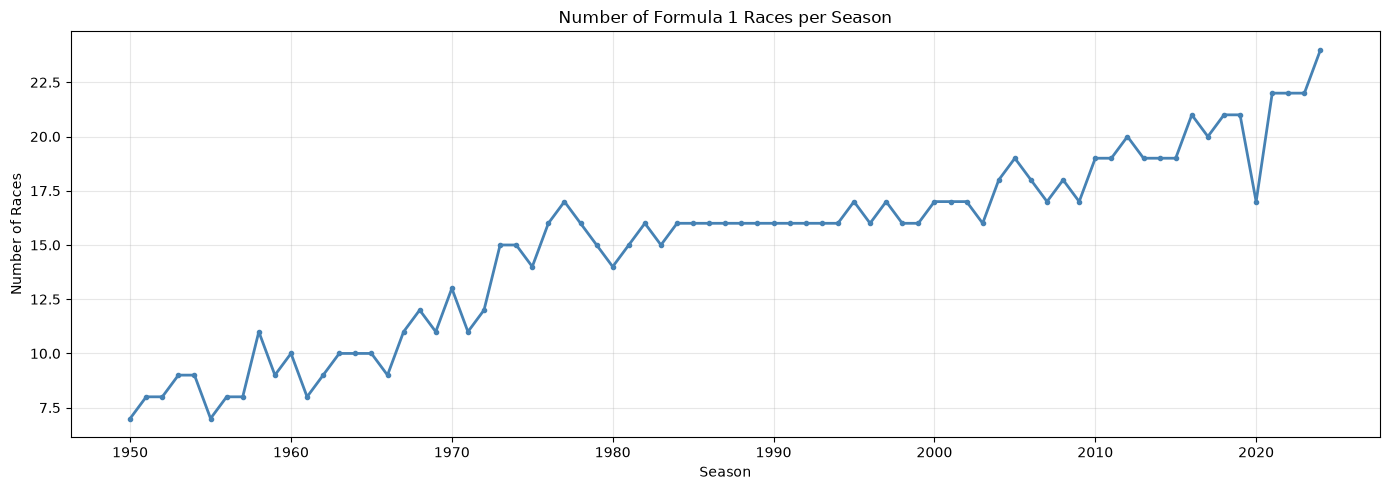

In [118]:
races = data['races']

races_per_year = races.groupby('year').size()

plt.figure(figsize=(14, 5))
plt.plot(
    races_per_year.index,
    races_per_year.values,
    marker='o',
    markersize=3,
    linewidth=2,
    color='steelblue'
)

plt.title('Number of Formula 1 Races per Season')
plt.xlabel('Season')
plt.ylabel('Number of Races')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

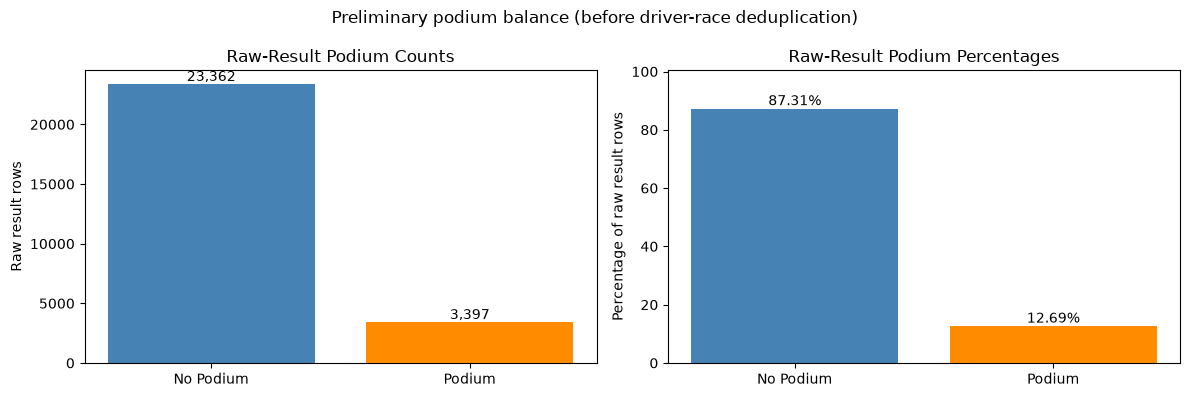

In [119]:
results = data['results']

# Preliminary target balance on raw result rows; duplicate driver-race rows are resolved later.
position_order = pd.to_numeric(results['positionOrder'], errors='coerce')
podium = position_order.le(3)

target_counts = podium.map({True: 'Podium', False: 'No Podium'}).value_counts()
target_counts = target_counts.reindex(['No Podium', 'Podium'])
target_percentages = target_counts / target_counts.sum() * 100

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
colors = ['steelblue', 'darkorange']

axes[0].bar(target_counts.index, target_counts.values, color=colors)
axes[0].set_title('Raw-Result Podium Counts')
axes[0].set_ylabel('Raw result rows')

for index, value in enumerate(target_counts.values):
    axes[0].text(index, value, f'{value:,}', ha='center', va='bottom')

axes[1].bar(target_percentages.index, target_percentages.values, color=colors)
axes[1].set_title('Raw-Result Podium Percentages')
axes[1].set_ylabel('Percentage of raw result rows')
axes[1].set_ylim(0, max(target_percentages) * 1.15)

for index, value in enumerate(target_percentages.values):
    axes[1].text(index, value, f'{value:.2f}%', ha='center', va='bottom')

fig.suptitle('Preliminary podium balance (before driver-race deduplication)')
plt.tight_layout()
plt.show()

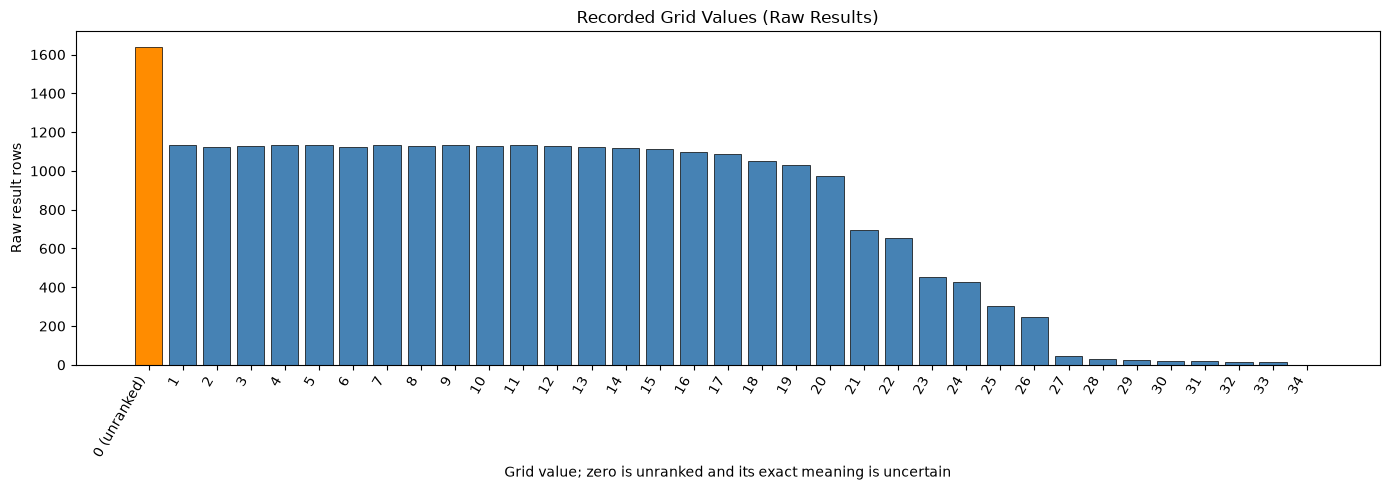

In [120]:
grid = pd.to_numeric(data['results']['grid'], errors='coerce')
positive_grid_counts = grid[grid.gt(0)].value_counts().sort_index()
grid_zero_count = grid.eq(0).sum()

labels = ['0 (unranked)'] + [f'{position:g}' for position in positive_grid_counts.index]
counts = [grid_zero_count, *positive_grid_counts.values]
colors = ['darkorange'] + ['steelblue'] * len(positive_grid_counts)

plt.figure(figsize=(14, 5))
plt.bar(labels, counts, color=colors, edgecolor='black', linewidth=0.5)
plt.title('Recorded Grid Values (Raw Results)')
plt.xlabel('Grid value; zero is unranked and its exact meaning is uncertain')
plt.ylabel('Raw result rows')
plt.xticks(rotation=60, ha='right')
plt.tight_layout()
plt.show()

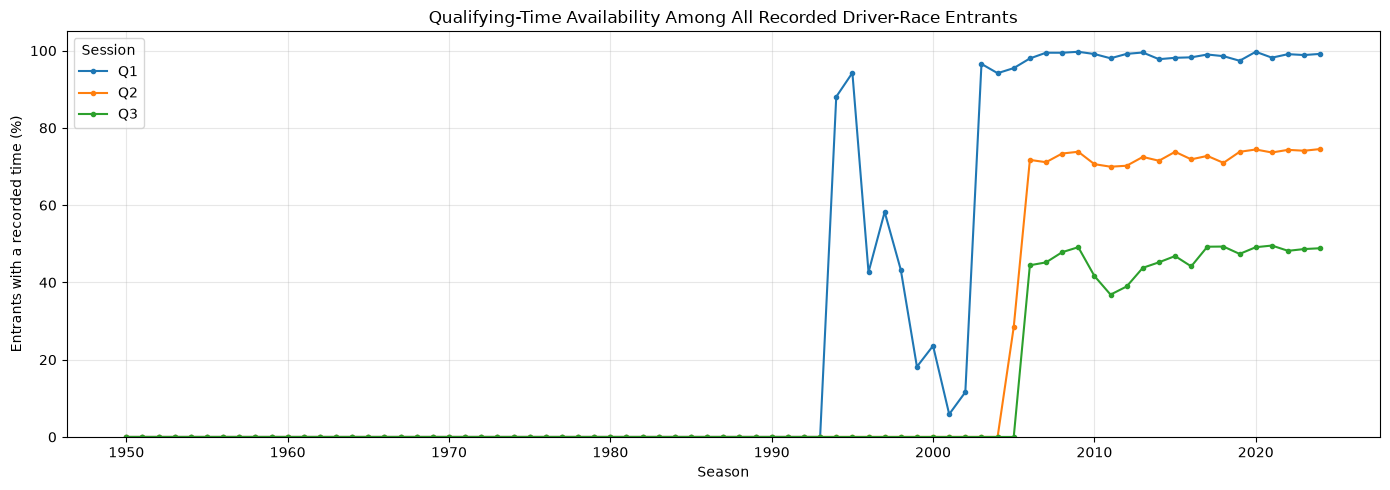

In [121]:
races = data['races']
qualifying = data['qualifying']
entrant_key = ['raceId', 'driverId']
qualifying_sessions = ['q1', 'q2', 'q3']

entrant_keys = (
    data['results'][entrant_key]
    .drop_duplicates()
    .merge(
        races[['raceId', 'year']],
        on='raceId',
        how='left',
        validate='many_to_one'
    )
)

qualifying_availability = qualifying[entrant_key].copy()
for session in qualifying_sessions:
    values = qualifying[session].astype('string').str.strip()
    qualifying_availability[session.upper()] = (
        qualifying[session].notna() & values.ne('') & values.ne(r'\N')
    )

# If a driver-race has multiple qualifying rows, count the session as available
# when at least one row contains a recorded time.
qualifying_availability = (
    qualifying_availability
    .groupby(entrant_key, as_index=False)[['Q1', 'Q2', 'Q3']]
    .max()
)

entrant_coverage = entrant_keys.merge(
    qualifying_availability,
    on=entrant_key,
    how='left',
    validate='one_to_one'
)
entrant_coverage[['Q1', 'Q2', 'Q3']] = entrant_coverage[['Q1', 'Q2', 'Q3']].fillna(False)
coverage_by_year = entrant_coverage.groupby('year')[['Q1', 'Q2', 'Q3']].mean().mul(100)

plt.figure(figsize=(14, 5))

for session in ['Q1', 'Q2', 'Q3']:
    plt.plot(
        coverage_by_year.index,
        coverage_by_year[session],
        marker='o',
        markersize=3,
        label=session
    )

plt.title('Qualifying-Time Availability Among All Recorded Driver-Race Entrants')
plt.xlabel('Season')
plt.ylabel('Entrants with a recorded time (%)')
plt.ylim(0, 105)
plt.grid(alpha=0.3)
plt.legend(title='Session')
plt.tight_layout()
plt.show()

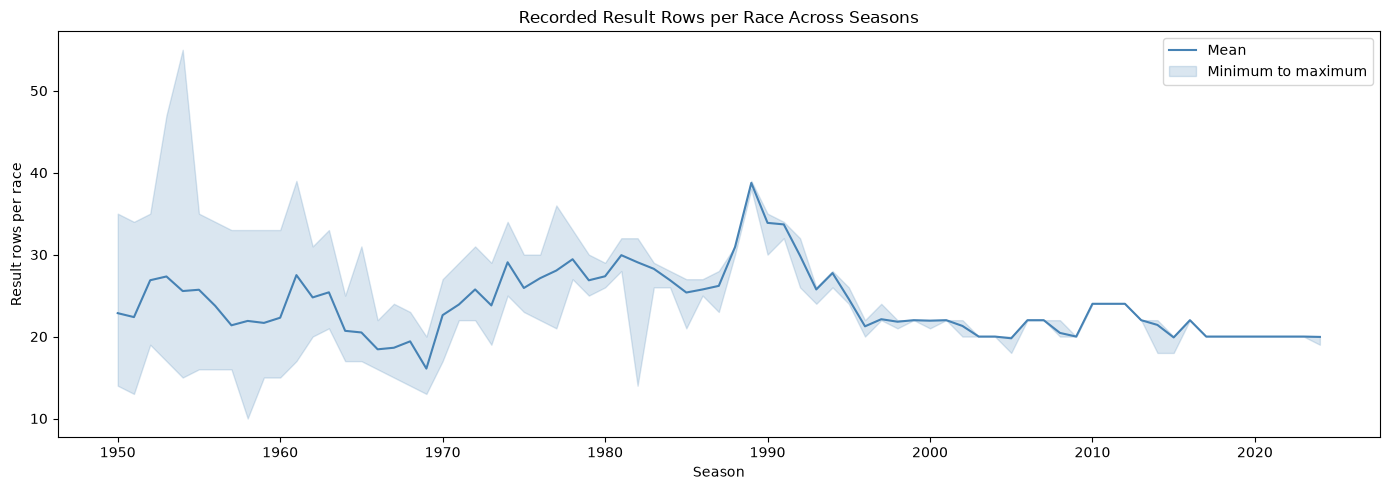

In [122]:
results = data['results']
races = data['races']

# This is the number of source result rows per race, not verified starters.
field_size = (
    results.groupby('raceId')
    .size()
    .rename('Result Rows')
    .reset_index()
    .merge(
        races[['raceId', 'year']],
        on='raceId',
        how='left',
        validate='many_to_one'
    )
)

field_by_year = (
    field_size.groupby('year')['Result Rows']
    .agg(['mean', 'min', 'max'])
    .reset_index()
)

plt.figure(figsize=(14, 5))
plt.plot(field_by_year['year'], field_by_year['mean'], color='steelblue', label='Mean')
plt.fill_between(
    field_by_year['year'],
    field_by_year['min'],
    field_by_year['max'],
    color='steelblue',
    alpha=0.2,
    label='Minimum to maximum'
)
plt.title('Recorded Result Rows per Race Across Seasons')
plt.xlabel('Season')
plt.ylabel('Result rows per race')
plt.legend()
plt.tight_layout()
plt.show()

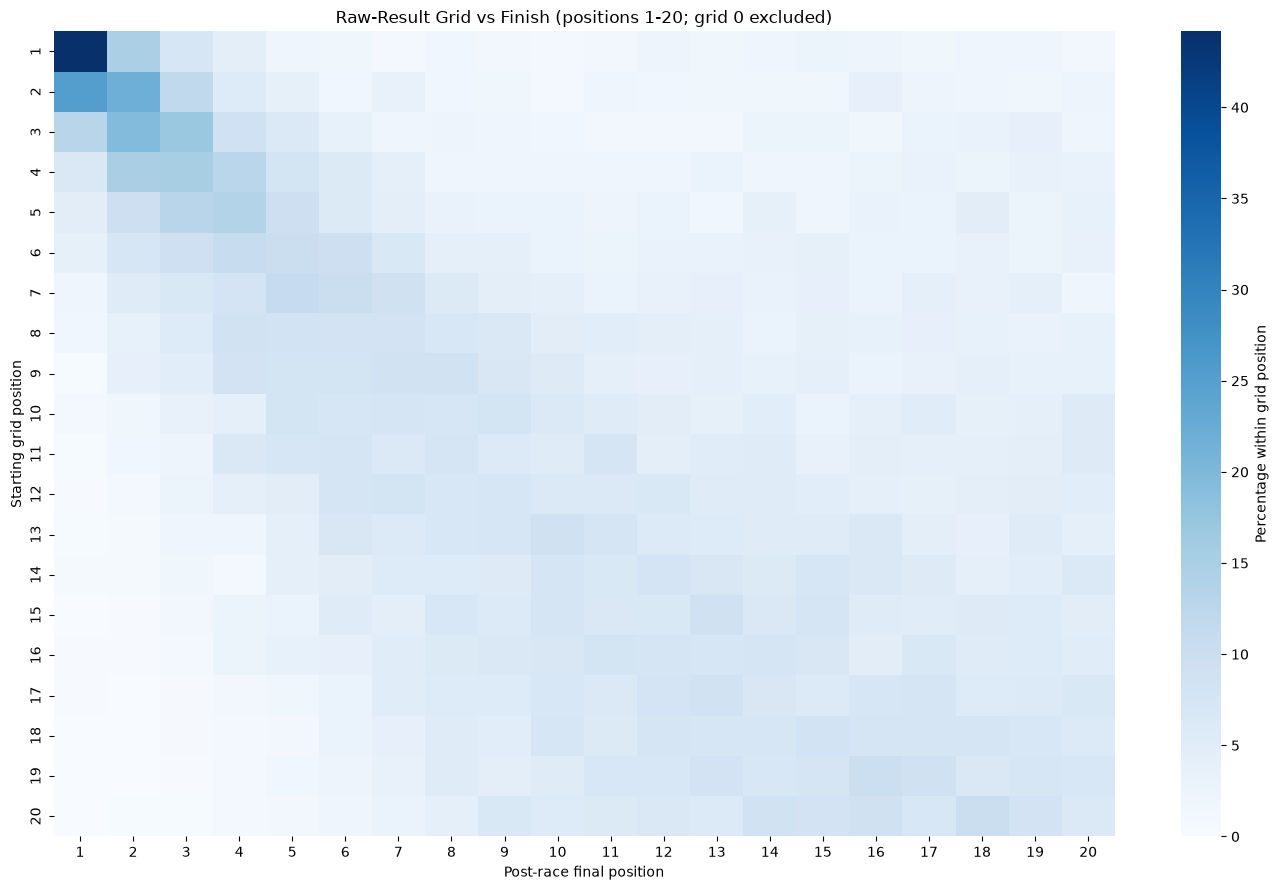

In [123]:
grid_finish = pd.DataFrame({
    'Grid': pd.to_numeric(data['results']['grid'], errors='coerce'),
    'Final Position': pd.to_numeric(data['results']['positionOrder'], errors='coerce')
}).dropna()

# Keep the heatmap readable: include only grid and finish positions 1-20.
grid_finish = grid_finish[
    grid_finish['Grid'].between(1, 20) &
    grid_finish['Final Position'].between(1, 20)
]

grid_finish_table = pd.crosstab(
    grid_finish['Grid'],
    grid_finish['Final Position'],
    normalize='index'
).mul(100)

plt.figure(figsize=(14, 9))
sns.heatmap(
    grid_finish_table,
    cmap='Blues',
    cbar_kws={'label': 'Percentage within grid position'}
)
plt.title('Raw-Result Grid vs Finish (positions 1-20; grid 0 excluded)')
plt.xlabel('Post-race final position')
plt.ylabel('Starting grid position')
plt.tight_layout()
plt.show()

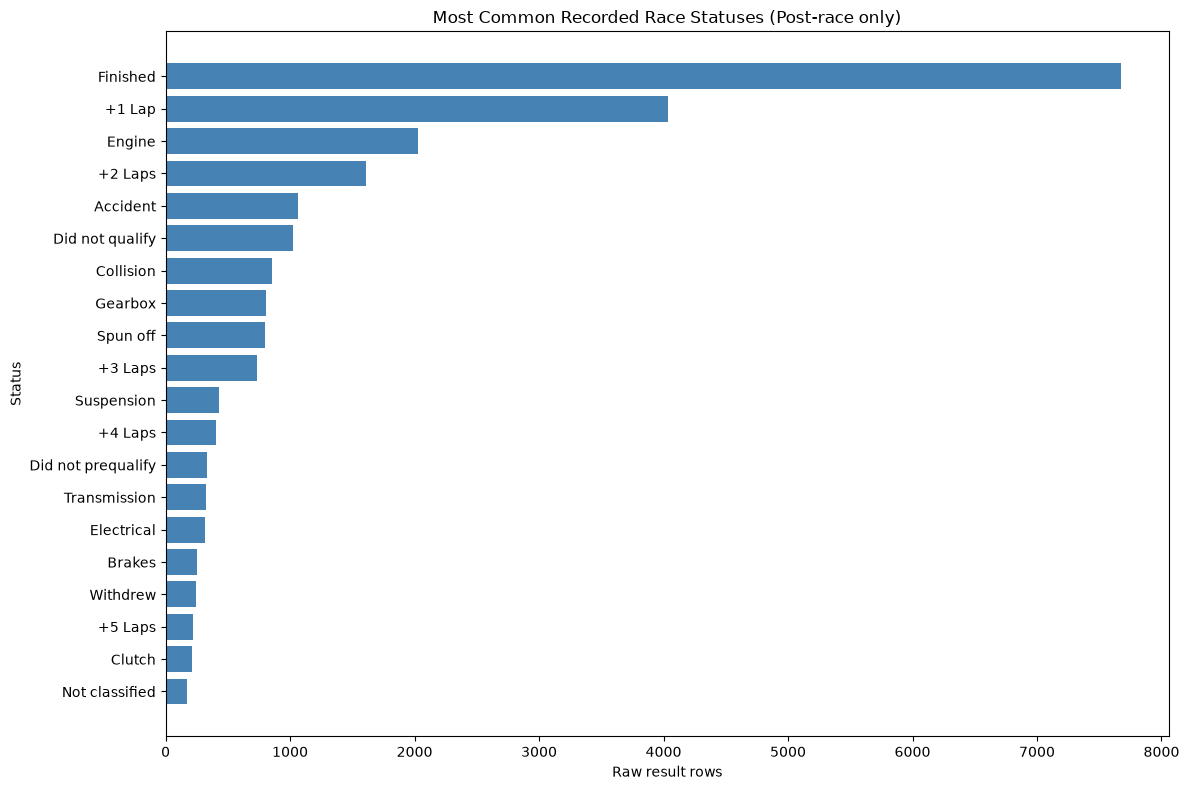

In [124]:
status_lookup = data['status']

results_with_status = data['results'].merge(
    status_lookup,
    on='statusId',
    how='left',
    validate='many_to_one'
)

status_counts = results_with_status['status'].value_counts().head(20).sort_values()

plt.figure(figsize=(12, 8))
plt.barh(status_counts.index, status_counts.values, color='steelblue')
plt.title('Most Common Recorded Race Statuses (Post-race only)')
plt.xlabel('Raw result rows')
plt.ylabel('Status')
plt.tight_layout()
plt.show()

### Pre-cleaning missingness and semantic-value baseline

The following cells snapshot the untouched tables, summarize unavailable values, and audit date and duration parsing using temporary values. They do not convert the source tables; the cleaned copies are created in the next section.

In [125]:
# Preserve the raw tables for before-and-after comparisons
raw_data = {
    name: df.copy(deep=True)
    for name, df in data.items()
}

In [126]:
def create_missing_profile(tables, stage):
    rows = []

    for table_name, df in tables.items():
        for column in df.columns:
            actual_nan = df[column].isna().sum()
            empty_strings = (
                df[column]
                .astype("string")
                .str.strip()
                .eq("")
                .sum()
            )
            sentinel_values = df[column].eq(r"\N").sum()

            rows.append({
                "Stage": stage,
                "Table": table_name,
                "Column": column,
                "Rows": len(df),
                "NaN": actual_nan,
                "Empty Strings": empty_strings,
                "Sentinel Values": sentinel_values,
                "Total Unavailable": (
                    actual_nan +
                    empty_strings +
                    sentinel_values
                )
            })

    profile = pd.DataFrame(rows)

    profile["Unavailable Percentage"] = (
        profile["Total Unavailable"] /
        profile["Rows"] * 100
    )

    profile["Feature"] = (
        profile["Table"] + "." + profile["Column"]
    )

    return profile


before_missing = create_missing_profile(
    raw_data,
    stage="Before Cleaning"
)

display(
    before_missing
    .sort_values(
        "Unavailable Percentage",
        ascending=False
    )
    .head(40)
)

,Stage,Table,Column,Rows,NaN,Empty Strings,Sentinel Values,Total Unavailable,Unavailable Percentage,Feature
13,Before Cleaning,constructor_results,status,12625,0,0,12608,12608,99.865347,constructor_results.status
81,Before Cleaning,races,sprint_time,1125,0,0,1110,1110,98.666667,races.sprint_time
80,Before Cleaning,races,sprint_date,1125,0,0,1107,1107,98.400000,races.sprint_date
77,Before Cleaning,races,fp3_time,1125,0,0,1072,1072,95.288889,races.fp3_time
73,Before Cleaning,races,fp1_time,1125,0,0,1057,1057,93.955556,races.fp1_time
75,Before Cleaning,races,fp2_time,1125,0,0,1057,1057,93.955556,races.fp2_time
79,Before Cleaning,races,quali_time,1125,0,0,1057,1057,93.955556,races.quali_time
76,Before Cleaning,races,fp3_date,1125,0,0,1053,1053,93.600000,races.fp3_date
35,Before Cleaning,drivers,number,861,0,0,802,802,93.147503,drivers.number
72,Before Cleaning,races,fp1_date,1125,0,0,1035,1035,92.000000,races.fp1_date


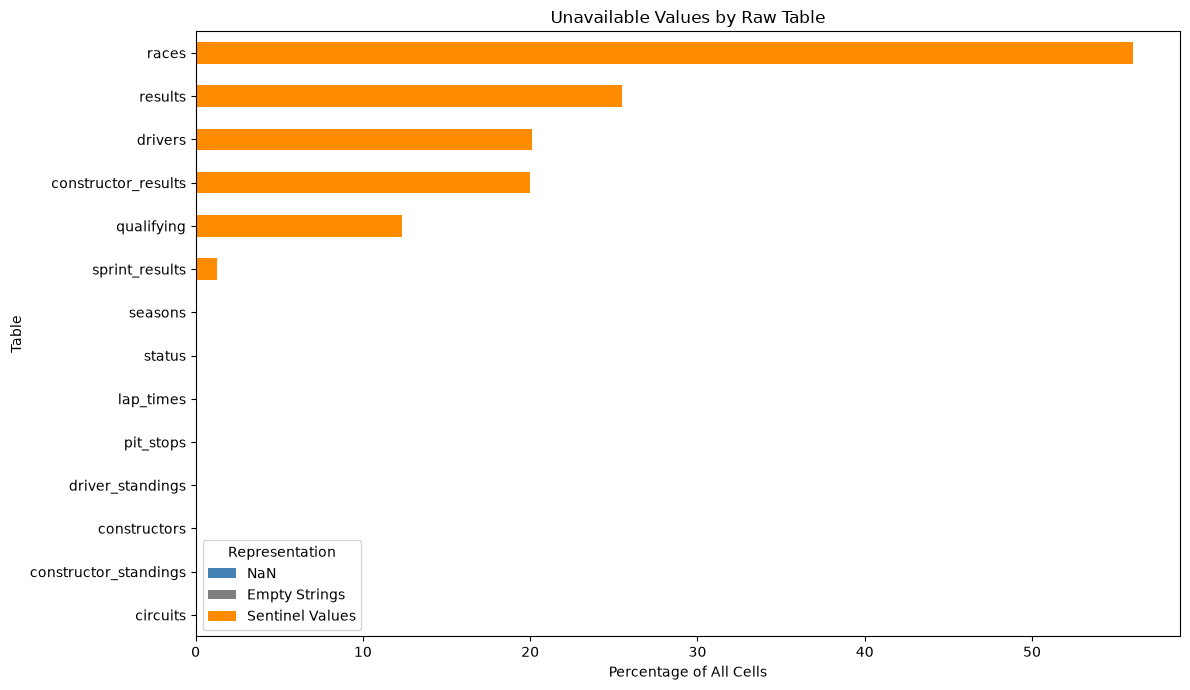

In [127]:
table_missing = (
    before_missing
    .groupby("Table")[[
        "NaN",
        "Empty Strings",
        "Sentinel Values"
    ]]
    .sum()
)

table_total_cells = {
    table_name: df.shape[0] * df.shape[1]
    for table_name, df in raw_data.items()
}

for column in ["NaN", "Empty Strings", "Sentinel Values"]:
    table_missing[column] = [
        table_missing.loc[table_name, column] /
        table_total_cells[table_name] * 100
        for table_name in table_missing.index
    ]

table_missing = table_missing.sort_values(
    "Sentinel Values",
    ascending=True
)

table_missing.plot(
    kind="barh",
    stacked=True,
    figsize=(12, 7),
    color=["steelblue", "gray", "darkorange"]
)

plt.title("Unavailable Values by Raw Table")
plt.xlabel("Percentage of All Cells")
plt.ylabel("Table")
plt.legend(title="Representation")
plt.tight_layout()
plt.show()

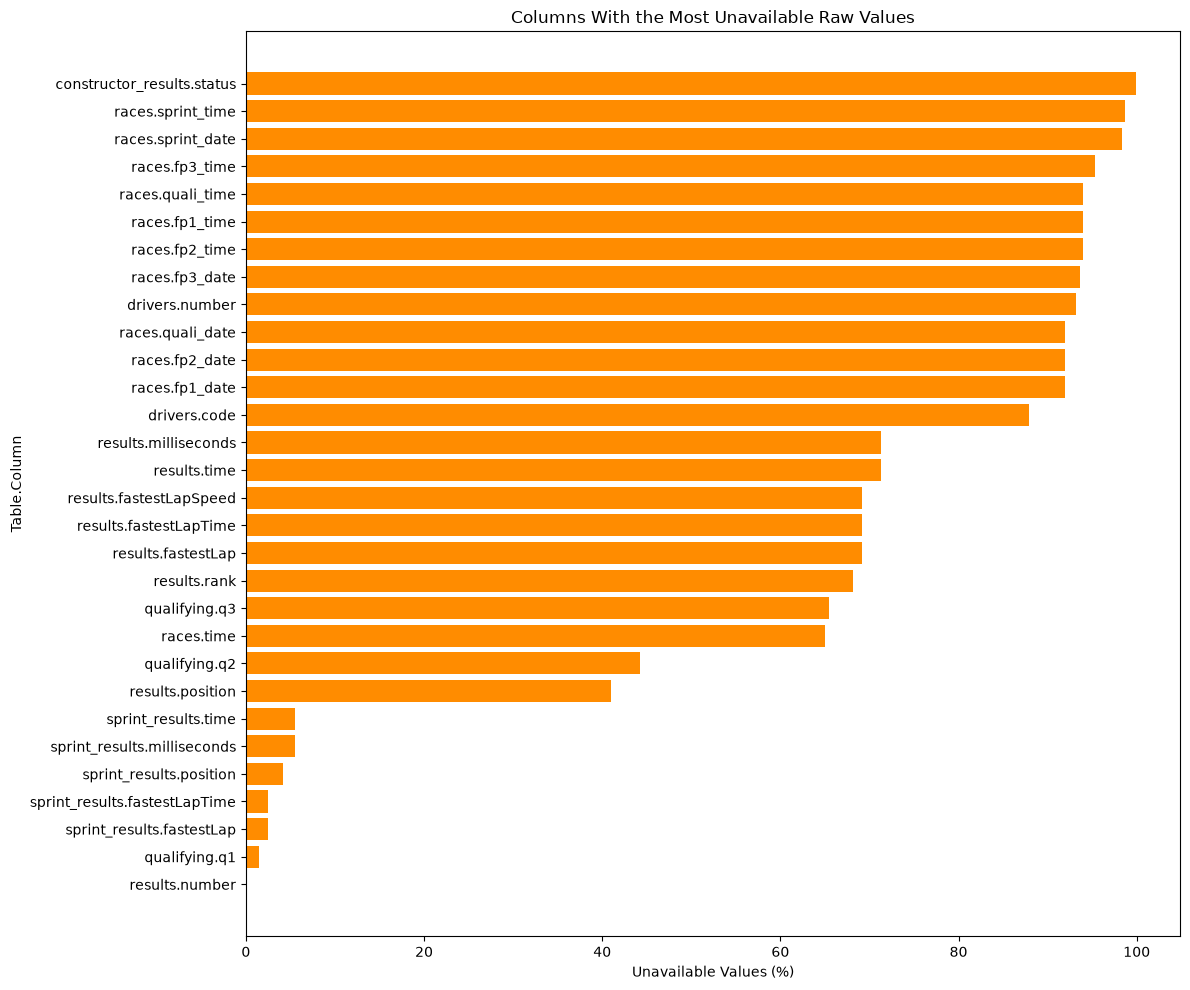

In [128]:
top_missing = (
    before_missing[
        before_missing["Total Unavailable"] > 0
    ]
    .sort_values(
        "Unavailable Percentage",
        ascending=False
    )
    .head(35)
    .sort_values("Unavailable Percentage")
)

plt.figure(figsize=(12, 10))

plt.barh(
    top_missing["Feature"],
    top_missing["Unavailable Percentage"],
    color="darkorange"
)

plt.title("Columns With the Most Unavailable Raw Values")
plt.xlabel("Unavailable Values (%)")
plt.ylabel("Table.Column")
plt.tight_layout()
plt.show()

In [129]:
# Date columns
date_columns = []

for table_name, df in raw_data.items():
    for column in df.columns:
        column_lower = column.lower()

        if (
            column_lower in {"date", "dob"} or
            column_lower.endswith("_date")
        ):
            date_columns.append((table_name, column))


# Duration columns stored as strings
duration_columns = [
    ("lap_times", "time"),
    ("qualifying", "q1"),
    ("qualifying", "q2"),
    ("qualifying", "q3"),
    ("pit_stops", "duration"),
    ("results", "fastestLapTime"),
    ("sprint_results", "fastestLapTime")
]


# Duration columns stored in milliseconds
millisecond_columns = [
    ("results", "milliseconds"),
    ("lap_times", "milliseconds"),
    ("pit_stops", "milliseconds"),
    ("sprint_results", "milliseconds")
]

print("Date columns:")
print(date_columns)

print("\nDuration columns:")
print(duration_columns)

print("\nMillisecond columns:")
print(millisecond_columns)

Date columns:
[('drivers', 'dob'), ('races', 'date'), ('races', 'fp1_date'), ('races', 'fp2_date'), ('races', 'fp3_date'), ('races', 'quali_date'), ('races', 'sprint_date')]

Duration columns:
[('lap_times', 'time'), ('qualifying', 'q1'), ('qualifying', 'q2'), ('qualifying', 'q3'), ('pit_stops', 'duration'), ('results', 'fastestLapTime'), ('sprint_results', 'fastestLapTime')]

Millisecond columns:
[('results', 'milliseconds'), ('lap_times', 'milliseconds'), ('pit_stops', 'milliseconds'), ('sprint_results', 'milliseconds')]


In [130]:
def normalized_text(series):
    """Trim text and normalize only recognized missing markers; preserve zero/codes."""
    return series.astype("string").str.strip().replace({r"\N": pd.NA, "": pd.NA})


def duration_to_seconds(series):
    """Parse nonnegative seconds, M:SS, or H:MM:SS; reject clock/gap syntax."""
    values = normalized_text(series)
    seconds = pd.Series(np.nan, index=series.index, dtype="float64")
    # A minute component in M:SS may exceed 59; seconds must be below 60.
    plain = values.str.fullmatch(r"\d+(?:\.\d+)?", na=False)
    minutes = values.str.fullmatch(r"\d+:[0-5]\d(?:\.\d+)?", na=False)
    hours = values.str.fullmatch(r"\d+:[0-5]\d:[0-5]\d(?:\.\d+)?", na=False)
    seconds.loc[plain] = pd.to_numeric(values.loc[plain], errors="coerce")
    seconds.loc[minutes] = pd.to_timedelta(
        "00:" + values.loc[minutes], errors="coerce"
    ).dt.total_seconds()
    seconds.loc[hours] = pd.to_timedelta(
        values.loc[hours], errors="coerce"
    ).dt.total_seconds()
    return seconds.where(np.isfinite(seconds))


def parse_semantic_column(series, semantic_type):
    values = normalized_text(series)
    if semantic_type in {"integer", "milliseconds", "number"}:
        parsed = pd.to_numeric(values, errors="coerce")
        parsed = parsed.where(np.isfinite(parsed))
        if semantic_type in {"integer", "milliseconds"}:
            # Reject fractional/out-of-range values instead of rounding IDs or counts.
            integral = parsed.mod(1).eq(0)
            in_range = parsed.ge(-(2**63)) & parsed.lt(2**63)
            parsed = parsed.where(integral & in_range).astype("Int64")
        else:
            parsed = parsed.astype("Float64")
        return parsed
    if semantic_type == "date":
        valid_format = values.str.fullmatch(r"\d{4}-\d{2}-\d{2}", na=False)
        return pd.to_datetime(values.where(valid_format), format="%Y-%m-%d", errors="coerce")
    if semantic_type == "duration_seconds":
        return duration_to_seconds(values)
    if semantic_type == "clock_time":
        valid_format = values.str.fullmatch(r"(?:[01]\d|2[0-3]):[0-5]\d:[0-5]\d", na=False)
        return pd.to_datetime(
            values.where(valid_format), format="%H:%M:%S", errors="coerce"
        ).dt.time
    if semantic_type in {"text", "mixed_result_time"}:
        # Race-result time mixes elapsed durations and +gaps. Preserve the text;
        # the separate milliseconds field supplies numeric elapsed duration.
        return values
    raise ValueError(f"Unknown semantic type: {semantic_type}")


In [131]:
semantic_audit = []

# Audit date columns
for table_name, column in date_columns:
    raw_series = raw_data[table_name][column]

    unavailable = (
        raw_series.isna() |
        raw_series.eq(r"\N") |
        raw_series.astype("string").str.strip().eq("")
    )

    parsed = pd.to_datetime(
        raw_series.where(~unavailable),
        errors="coerce"
    )

    available_count = (~unavailable).sum()
    valid_count = parsed.notna().sum()
    invalid_count = available_count - valid_count

    semantic_audit.append({
        "Table": table_name,
        "Column": column,
        "Expected Type": "Date",
        "Raw Type": str(raw_series.dtype),
        "Unavailable": unavailable.sum(),
        "Parseable": valid_count,
        "Invalid": invalid_count,
        "Parse Success (%)": (
            valid_count / available_count * 100
            if available_count > 0 else np.nan
        )
    })


# Audit duration columns
for table_name, column in duration_columns:
    raw_series = raw_data[table_name][column]

    unavailable = (
        raw_series.isna() |
        raw_series.eq(r"\N") |
        raw_series.astype("string").str.strip().eq("")
    )

    parsed = duration_to_seconds(raw_series)

    available_count = (~unavailable).sum()
    valid_count = parsed.notna().sum()
    invalid_count = available_count - valid_count

    semantic_audit.append({
        "Table": table_name,
        "Column": column,
        "Expected Type": "Duration in Seconds",
        "Raw Type": str(raw_series.dtype),
        "Unavailable": unavailable.sum(),
        "Parseable": valid_count,
        "Invalid": invalid_count,
        "Parse Success (%)": (
            valid_count / available_count * 100
            if available_count > 0 else np.nan
        )
    })


semantic_audit_df = pd.DataFrame(semantic_audit)
semantic_audit_df["Feature"] = (
    semantic_audit_df["Table"] +
    "." +
    semantic_audit_df["Column"]
)

display(semantic_audit_df)

,Table,Column,Expected Type,Raw Type,Unavailable,Parseable,Invalid,Parse Success (%),Feature
0,drivers,dob,Date,str,0,861,0,100.0,drivers.dob
1,races,date,Date,str,0,1125,0,100.0,races.date
2,races,fp1_date,Date,str,1035,90,0,100.0,races.fp1_date
3,races,fp2_date,Date,str,1035,90,0,100.0,races.fp2_date
4,races,fp3_date,Date,str,1053,72,0,100.0,races.fp3_date
5,races,quali_date,Date,str,1035,90,0,100.0,races.quali_date
6,races,sprint_date,Date,str,1107,18,0,100.0,races.sprint_date
7,lap_times,time,Duration in Seconds,str,0,589081,0,100.0,lap_times.time
8,qualifying,q1,Duration in Seconds,str,156,10338,0,100.0,qualifying.q1
9,qualifying,q2,Duration in Seconds,str,4647,5847,0,100.0,qualifying.q2


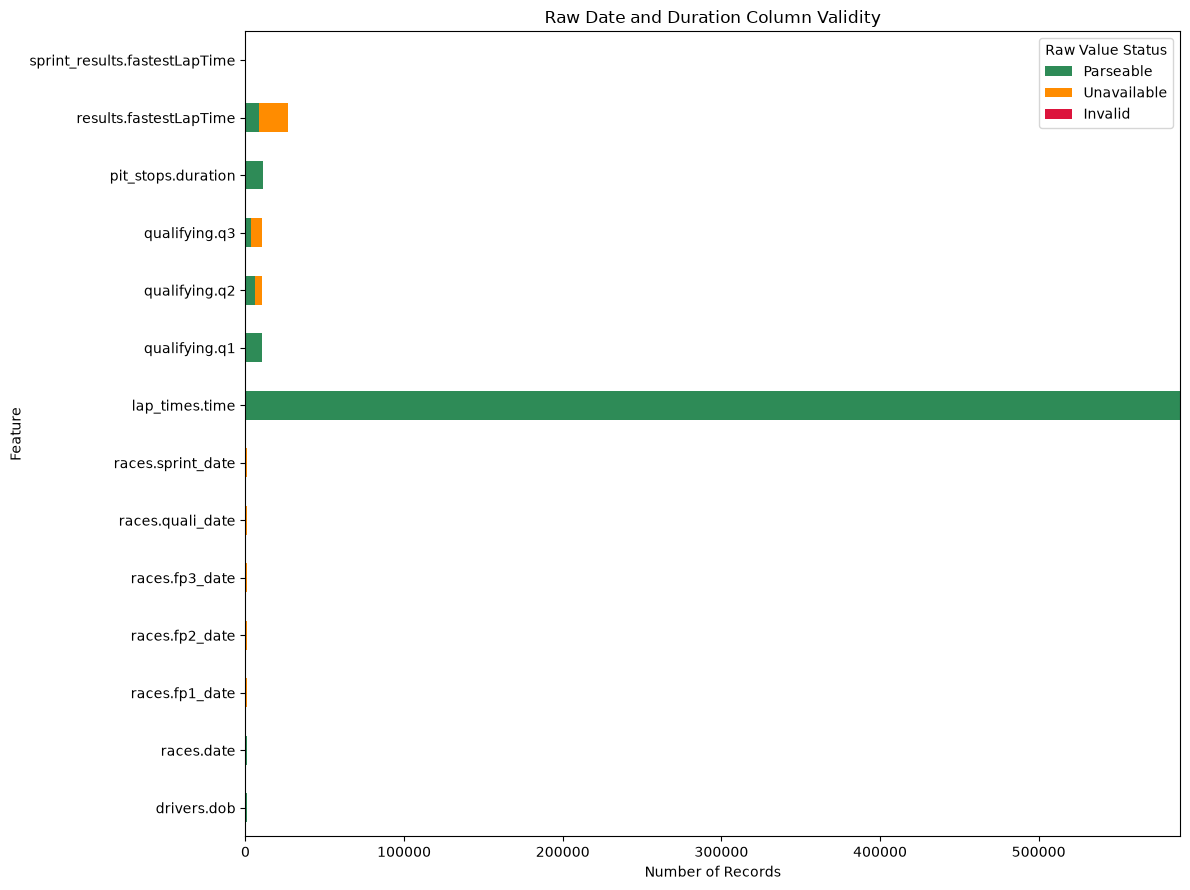

In [132]:
semantic_plot = semantic_audit_df.set_index("Feature")[
    ["Parseable", "Unavailable", "Invalid"]
]

semantic_plot.plot(
    kind="barh",
    stacked=True,
    figsize=(12, 9),
    color=["seagreen", "darkorange", "crimson"]
)

plt.title("Raw Date and Duration Column Validity")
plt.xlabel("Number of Records")
plt.ylabel("Feature")
plt.legend(title="Raw Value Status")
plt.tight_layout()
plt.show()

In [133]:
date_range_rows = []

for table_name, column in date_columns:
    temporary_dates = pd.to_datetime(
        raw_data[table_name][column].replace(
            {r"\N": pd.NA, "": pd.NA}
        ),
        errors="coerce"
    )

    date_range_rows.append({
        "Table": table_name,
        "Column": column,
        "Raw Type": str(
            raw_data[table_name][column].dtype
        ),
        "Earliest Date": temporary_dates.min(),
        "Latest Date": temporary_dates.max(),
        "Valid Dates": temporary_dates.notna().sum(),
        "Unavailable or Invalid": temporary_dates.isna().sum()
    })

date_range_df = pd.DataFrame(date_range_rows)

display(date_range_df)

,Table,Column,Raw Type,Earliest Date,Latest Date,Valid Dates,Unavailable or Invalid
0,drivers,dob,str,1896-12-28,2005-05-08,861,0
1,races,date,str,1950-05-13,2024-12-08,1125,0
2,races,fp1_date,str,2021-03-26,2024-12-06,90,1035
3,races,fp2_date,str,2021-03-26,2024-12-06,90,1035
4,races,fp3_date,str,2021-03-27,2024-12-07,72,1053
5,races,quali_date,str,2021-03-27,2024-12-07,90,1035
6,races,sprint_date,str,2021-07-17,2024-11-30,18,1107


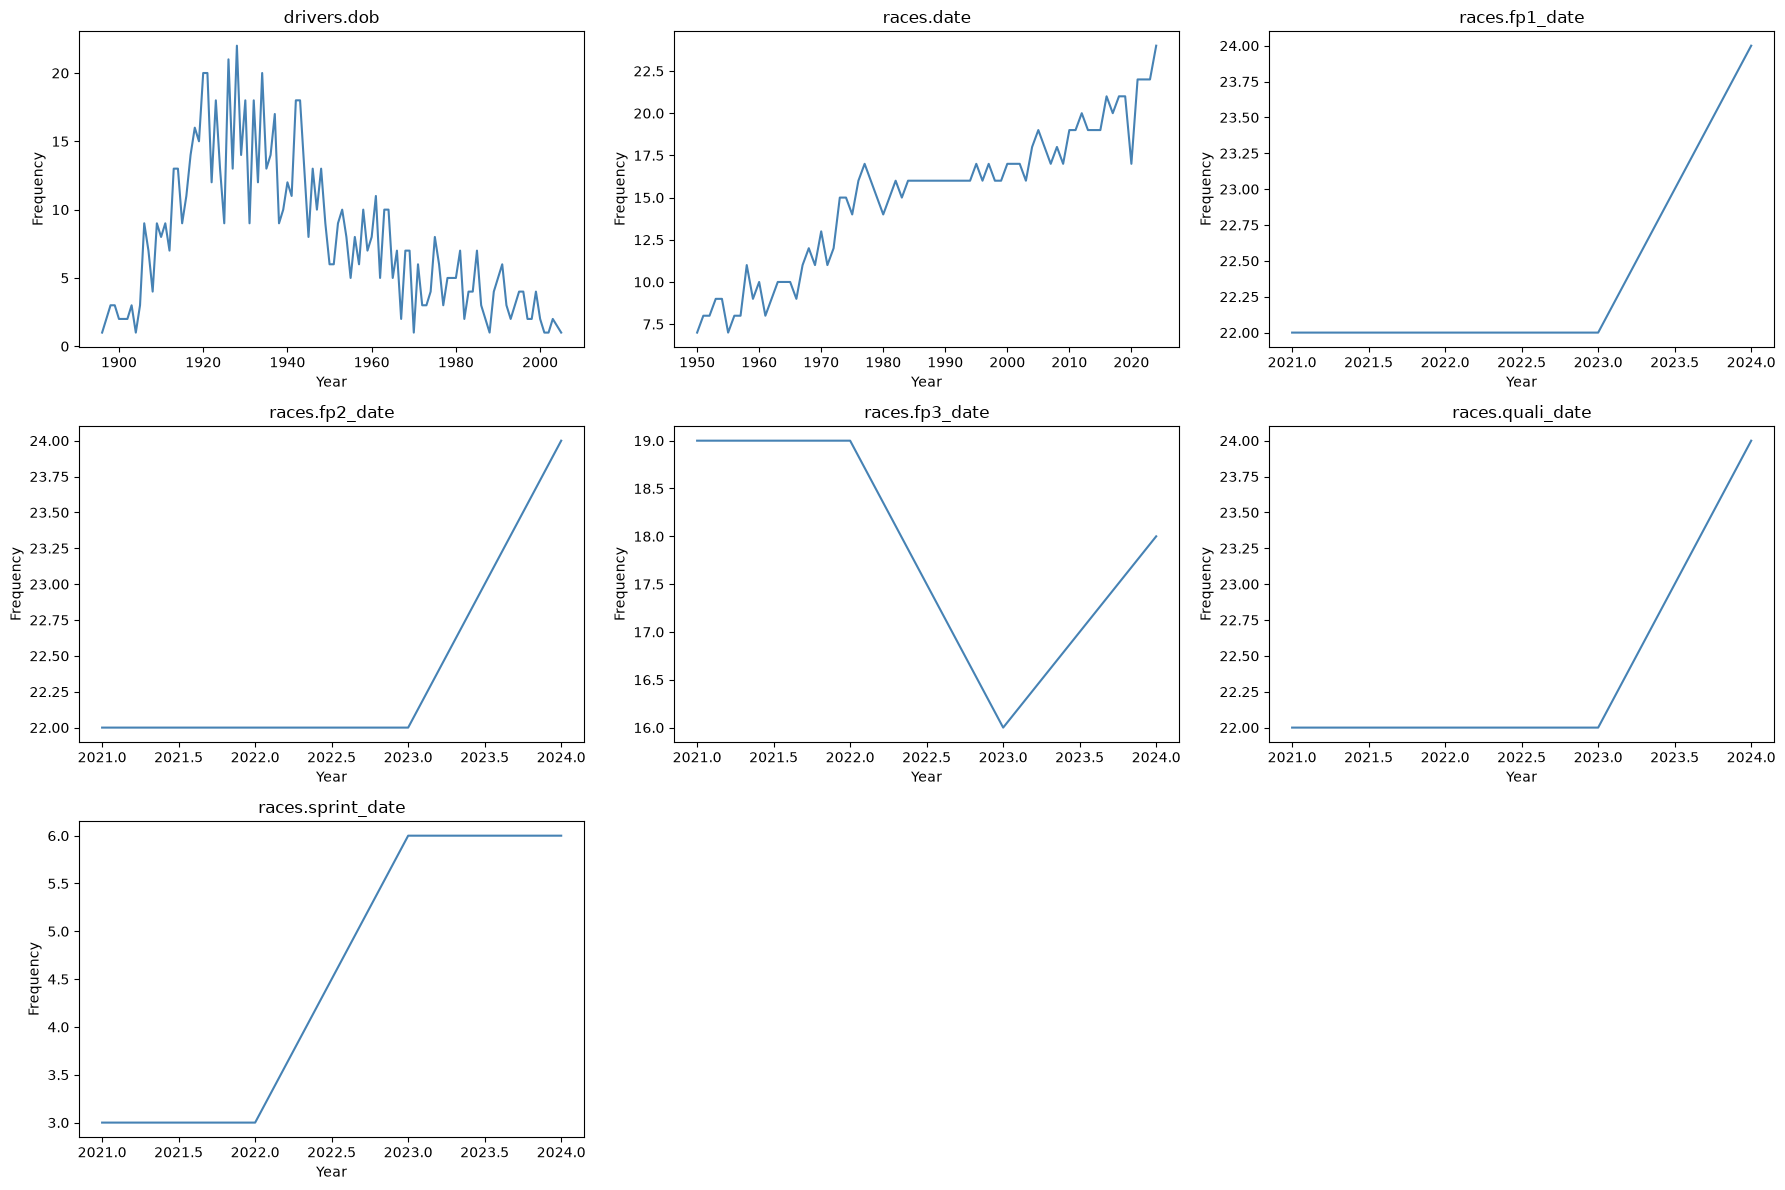

In [134]:
number_of_plots = len(date_columns)
columns_per_row = 3
rows = int(np.ceil(number_of_plots / columns_per_row))

fig, axes = plt.subplots(
    rows,
    columns_per_row,
    figsize=(18, rows * 4)
)

axes = np.array(axes).reshape(-1)

for ax, (table_name, column) in zip(axes, date_columns):
    parsed_dates = pd.to_datetime(
        raw_data[table_name][column].replace(
            {r"\N": pd.NA, "": pd.NA}
        ),
        errors="coerce"
    )

    year_counts = (
        parsed_dates.dt.year
        .value_counts()
        .sort_index()
    )

    ax.plot(
        year_counts.index,
        year_counts.values,
        color="steelblue"
    )

    ax.set_title(f"{table_name}.{column}")
    ax.set_xlabel("Year")
    ax.set_ylabel("Frequency")

for ax in axes[number_of_plots:]:
    ax.remove()

plt.tight_layout()
plt.show()

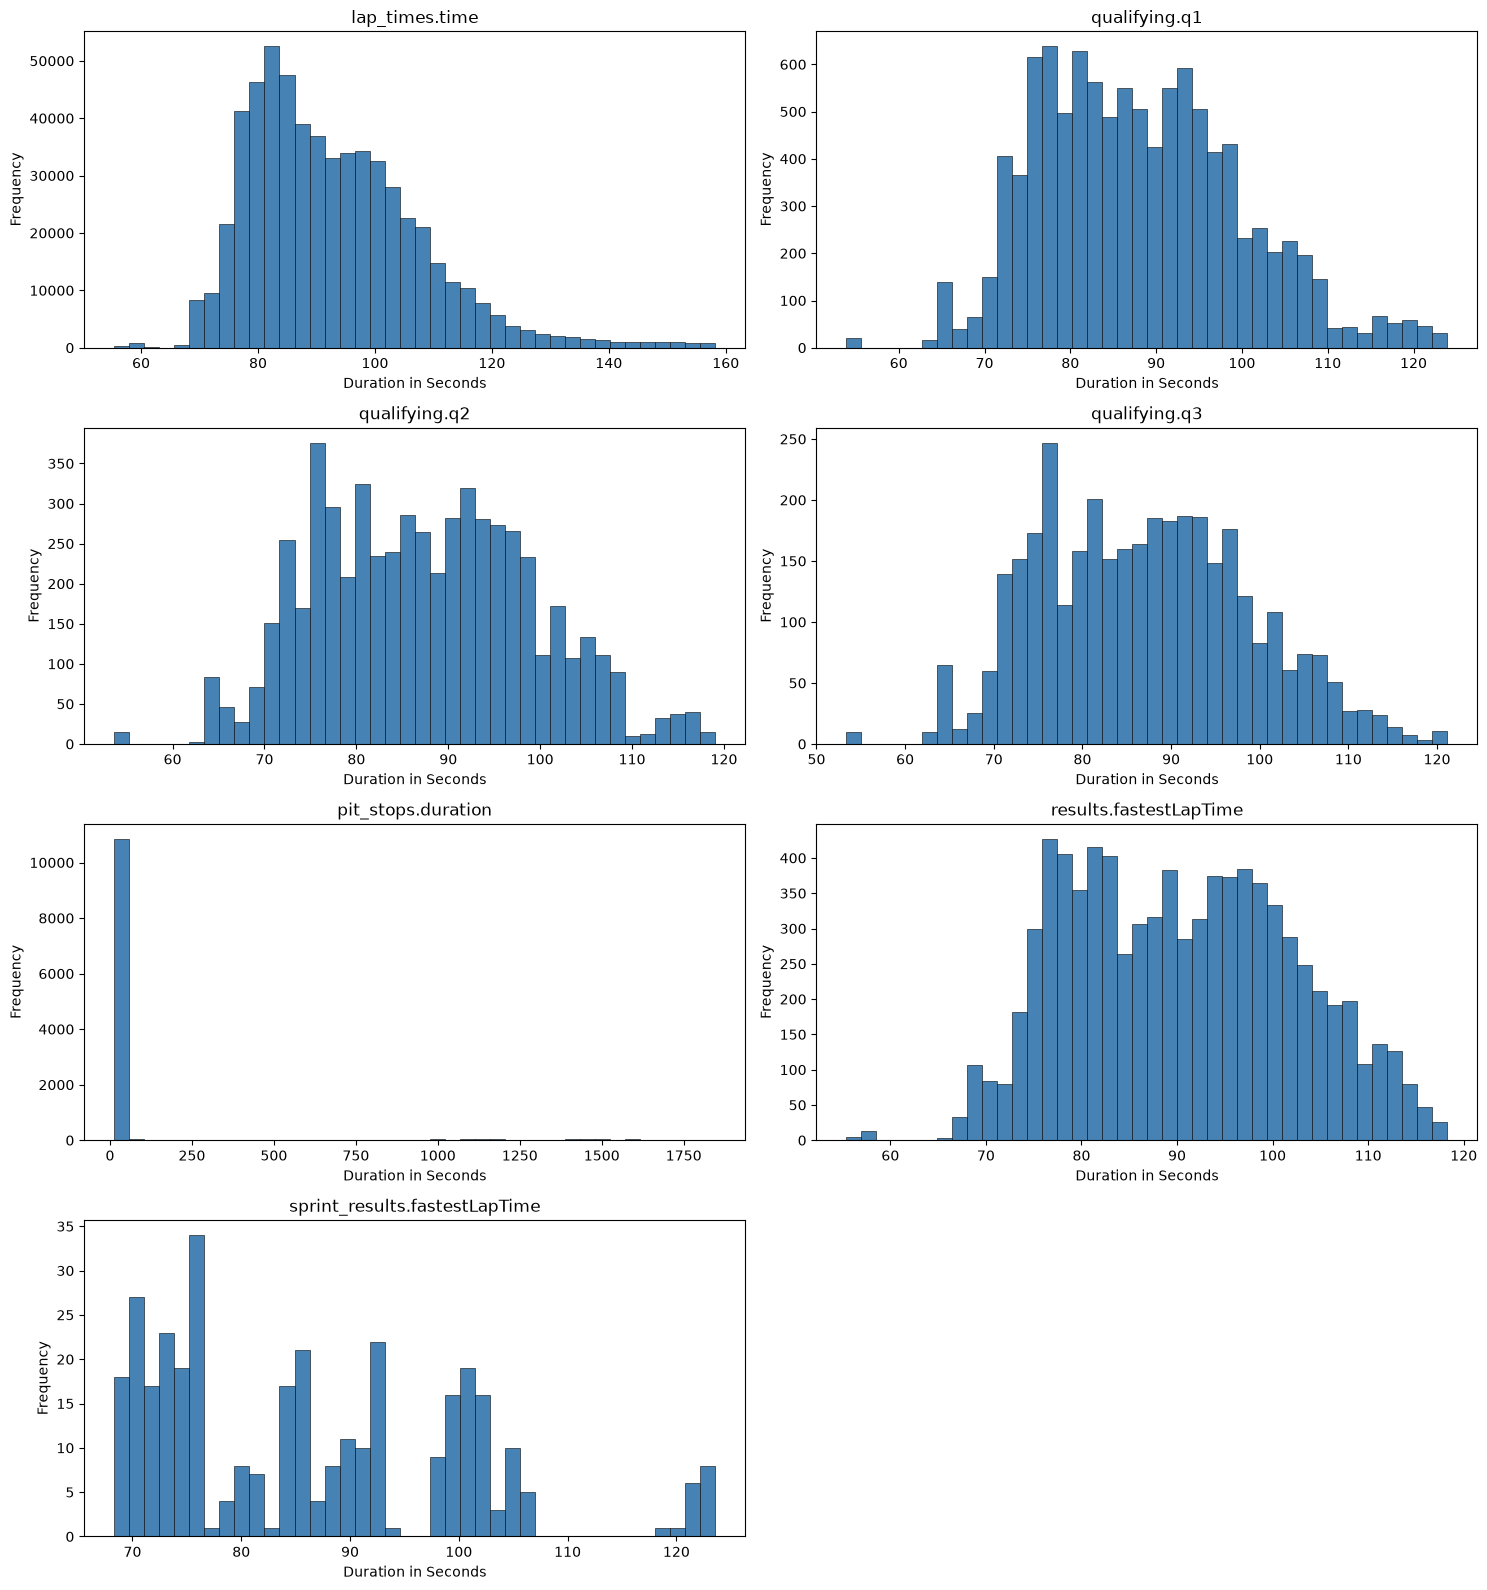

In [135]:
number_of_plots = len(duration_columns)
columns_per_row = 2
rows = int(np.ceil(number_of_plots / columns_per_row))

fig, axes = plt.subplots(
    rows,
    columns_per_row,
    figsize=(15, rows * 4)
)

axes = np.array(axes).reshape(-1)

for ax, (table_name, column) in zip(
    axes,
    duration_columns
):
    seconds = duration_to_seconds(
        raw_data[table_name][column]
    ).dropna()

    if len(seconds) > 0:
        # Limit visualization to the 99th percentile
        # so extreme values do not hide the main distribution
        upper_limit = seconds.quantile(0.99)
        plotted_seconds = seconds[
            seconds <= upper_limit
        ]

        ax.hist(
            plotted_seconds,
            bins=40,
            color="steelblue",
            edgecolor="black",
            linewidth=0.4
        )

    ax.set_title(f"{table_name}.{column}")
    ax.set_xlabel("Duration in Seconds")
    ax.set_ylabel("Frequency")

for ax in axes[number_of_plots:]:
    ax.remove()

plt.tight_layout()
plt.show()

## Semantic typing of all source columns (step 4)

The schema below explicitly assigns a meaning to every column in all 14 tables. No column is silently inferred or omitted: schema coverage is checked before conversion. Cleaning starts from copies of `raw_data` each time this cell runs.

- IDs, years, rounds, positions/ranks, lap/stop counts, wins, and car numbers use nullable `Int64`. Fractional or unrepresentable integer values are reported as conversion failures, never rounded. IDs and car numbers remain identifiers/labels, not automatically continuous model features.
- Points, coordinates, altitude, and fastest-lap speed use nullable `Float64`. Points may legitimately be fractional; altitude may be negative. Millisecond fields use `Int64` and retain their millisecond unit.
- Calendar dates become datetime values. Lap, qualifying, pit-stop, and fastest-lap durations become numeric **seconds**. Source column names are retained; `semantic_schema_df` records their units.
- Race/session start times and pit-stop clock times become Python `datetime.time` values (`object` dtype in pandas). They represent times of day, not durations. No artificial calendar date or timezone conversion is introduced; clock values alone do not encode a timezone. Date/clock combination, when needed, is a later explicit operation.
- Text becomes trimmed pandas `string`; meaningful codes such as `R`, names, and nationality/country labels are preserved. Whitespace-only values and `\N` become null. Country/nationality mapping remains a later task.
- `results.time` and `sprint_results.time` intentionally remain **mixed elapsed/gap text**. For example `1:34:50.616` is elapsed time, while `+5.478` is a relative gap. These are not interchangeable. Their separate numeric `milliseconds` columns represent elapsed durations; missing values are not filled from gap text.

The conversion audit counts each originally available value that becomes null and records every failure's table, column, source row index, raw value, and expected meaning. Raw CSVs, raw DataFrames, row counts, and meaningful zero values are preserved. These type conversions do not make post-race fields valid predictors.


In [136]:
# Explicit column schema: no heuristic inference and no unspecified columns.
semantic_schema = {
    "circuits": {
        "integer": "circuitId", "number": "lat lng alt",
        "text": "circuitRef name location country url"
    },
    "constructors": {
        "integer": "constructorId", "text": "constructorRef name nationality url"
    },
    "drivers": {
        "integer": "driverId number", "date": "dob",
        "text": "driverRef code forename surname nationality url"
    },
    "races": {
        "integer": "raceId year round circuitId", "text": "name url",
        "date": "date fp1_date fp2_date fp3_date quali_date sprint_date",
        "clock_time": "time fp1_time fp2_time fp3_time quali_time sprint_time"
    },
    "seasons": {"integer": "year", "text": "url"},
    "status": {"integer": "statusId", "text": "status"},
    "results": {
        "integer": "resultId raceId driverId constructorId number grid position positionOrder laps fastestLap rank statusId",
        "number": "points fastestLapSpeed", "text": "positionText",
        "milliseconds": "milliseconds", "duration_seconds": "fastestLapTime",
        "mixed_result_time": "time"
    },
    "qualifying": {
        "integer": "qualifyId raceId driverId constructorId number position",
        "duration_seconds": "q1 q2 q3"
    },
    "driver_standings": {
        "integer": "driverStandingsId raceId driverId position wins",
        "number": "points", "text": "positionText"
    },
    "constructor_standings": {
        "integer": "constructorStandingsId raceId constructorId position wins",
        "number": "points", "text": "positionText"
    },
    "constructor_results": {
        "integer": "constructorResultsId raceId constructorId",
        "number": "points", "text": "status"
    },
    "sprint_results": {
        "integer": "resultId raceId driverId constructorId number grid position positionOrder laps fastestLap statusId",
        "number": "points", "text": "positionText",
        "milliseconds": "milliseconds", "duration_seconds": "fastestLapTime",
        "mixed_result_time": "time"
    },
    "lap_times": {
        "integer": "raceId driverId lap position",
        "duration_seconds": "time", "milliseconds": "milliseconds"
    },
    "pit_stops": {
        "integer": "raceId driverId stop lap", "clock_time": "time",
        "duration_seconds": "duration", "milliseconds": "milliseconds"
    }
}

semantic_meanings = {
    "integer": "Integer identifier, label, ordinal, or count",
    "number": "Numeric measurement or points",
    "date": "Calendar date (YYYY-MM-DD)",
    "duration_seconds": "Duration in seconds",
    "milliseconds": "Elapsed duration in milliseconds",
    "clock_time": "Clock time (HH:MM:SS), no attached date/timezone",
    "text": "Trimmed text / category",
    "mixed_result_time": "Elapsed/gap text; retain + prefix and original meaning"
}
measurement_units = {
    ("circuits", "lat"): "degrees", ("circuits", "lng"): "degrees",
    ("circuits", "alt"): "metres", ("results", "fastestLapSpeed"): "km/h"
}

if set(semantic_schema) != set(raw_data):
    raise ValueError("Schema tables differ from the loaded tables.")
schema_rows = []
for table_name, groups in semantic_schema.items():
    declared = [column for columns in groups.values() for column in columns.split()]
    if len(declared) != len(set(declared)) or set(declared) != set(raw_data[table_name].columns):
        raise ValueError(f"{table_name}: columns must be declared exactly once in the schema.")
    for semantic_type, columns in groups.items():
        for column in columns.split():
            unit = measurement_units.get((table_name, column), "--")
            if semantic_type == "duration_seconds":
                unit = "seconds"
            elif semantic_type == "milliseconds":
                unit = "milliseconds"
            elif column == "points":
                unit = "championship/race points"
            schema_rows.append({
                "Table": table_name, "Column": column, "Semantic Type": semantic_type,
                "Meaning": semantic_meanings[semantic_type], "Unit": unit
            })
semantic_schema_df = pd.DataFrame(schema_rows)
display(pd.crosstab(semantic_schema_df["Table"], semantic_schema_df["Semantic Type"]))


Semantic Type,clock_time,date,duration_seconds,integer,milliseconds,mixed_result_time,number,text
Table,,,,,,,,
circuits,0,0,0,1,0,0,3,5
constructor_results,0,0,0,3,0,0,1,1
constructor_standings,0,0,0,5,0,0,1,1
constructors,0,0,0,1,0,0,0,4
driver_standings,0,0,0,5,0,0,1,1
drivers,0,1,0,2,0,0,0,6
lap_times,0,0,1,4,1,0,0,0
pit_stops,1,0,1,4,1,0,0,0
qualifying,0,0,3,6,0,0,0,0


In [137]:
clean_data = {name: table.copy(deep=True) for name, table in raw_data.items()}
conversion_audit_rows = []
conversion_failure_frames = []
for record in semantic_schema_df.to_dict("records"):
    table_name, column = record["Table"], record["Column"]
    source = raw_data[table_name][column]
    available = normalized_text(source).notna()
    parsed = parse_semantic_column(source, record["Semantic Type"])
    failed = available & parsed.isna()
    clean_data[table_name][column] = parsed
    conversion_audit_rows.append({
        **record,
        "Before Type": str(source.dtype), "After Type": str(parsed.dtype),
        "Before Available": int(available.sum()),
        "After Available": int(parsed.notna().sum()),
        "Values Lost During Conversion": int(failed.sum())
    })
    if failed.any():
        conversion_failure_frames.append(pd.DataFrame({
            "Table": table_name, "Column": column,
            "Source Row Index": source.index[failed],
            "Raw Value": source.loc[failed].astype("string").to_numpy(),
            "Expected Meaning": record["Meaning"]
        }))

semantic_type_audit_df = pd.DataFrame(conversion_audit_rows)
conversion_failures_df = (
    pd.concat(conversion_failure_frames, ignore_index=True)
    if conversion_failure_frames else pd.DataFrame(columns=[
        "Table", "Column", "Source Row Index", "Raw Value", "Expected Meaning"
    ])
)
assert all(len(clean_data[name]) == len(raw_data[name]) for name in raw_data)
print(f"Typed {len(semantic_type_audit_df)} columns across {len(clean_data)} tables.")
print(f"Previously available values converted to null: {len(conversion_failures_df)}")
if not conversion_failures_df.empty:
    print("Review these failures before proceeding; original values remain in raw_data.")
    with pd.option_context("display.max_rows", None):
        display(conversion_failures_df)


Typed 120 columns across 14 tables.
Previously available values converted to null: 0


In [138]:
after_missing = create_missing_profile(
    clean_data,
    stage="After Cleaning"
)

combined_missing = pd.concat(
    [before_missing, after_missing],
    ignore_index=True
)

top_features = (
    before_missing
    .sort_values(
        "Unavailable Percentage",
        ascending=False
    )
    .head(25)["Feature"]
)

comparison = combined_missing[
    combined_missing["Feature"].isin(top_features)
]

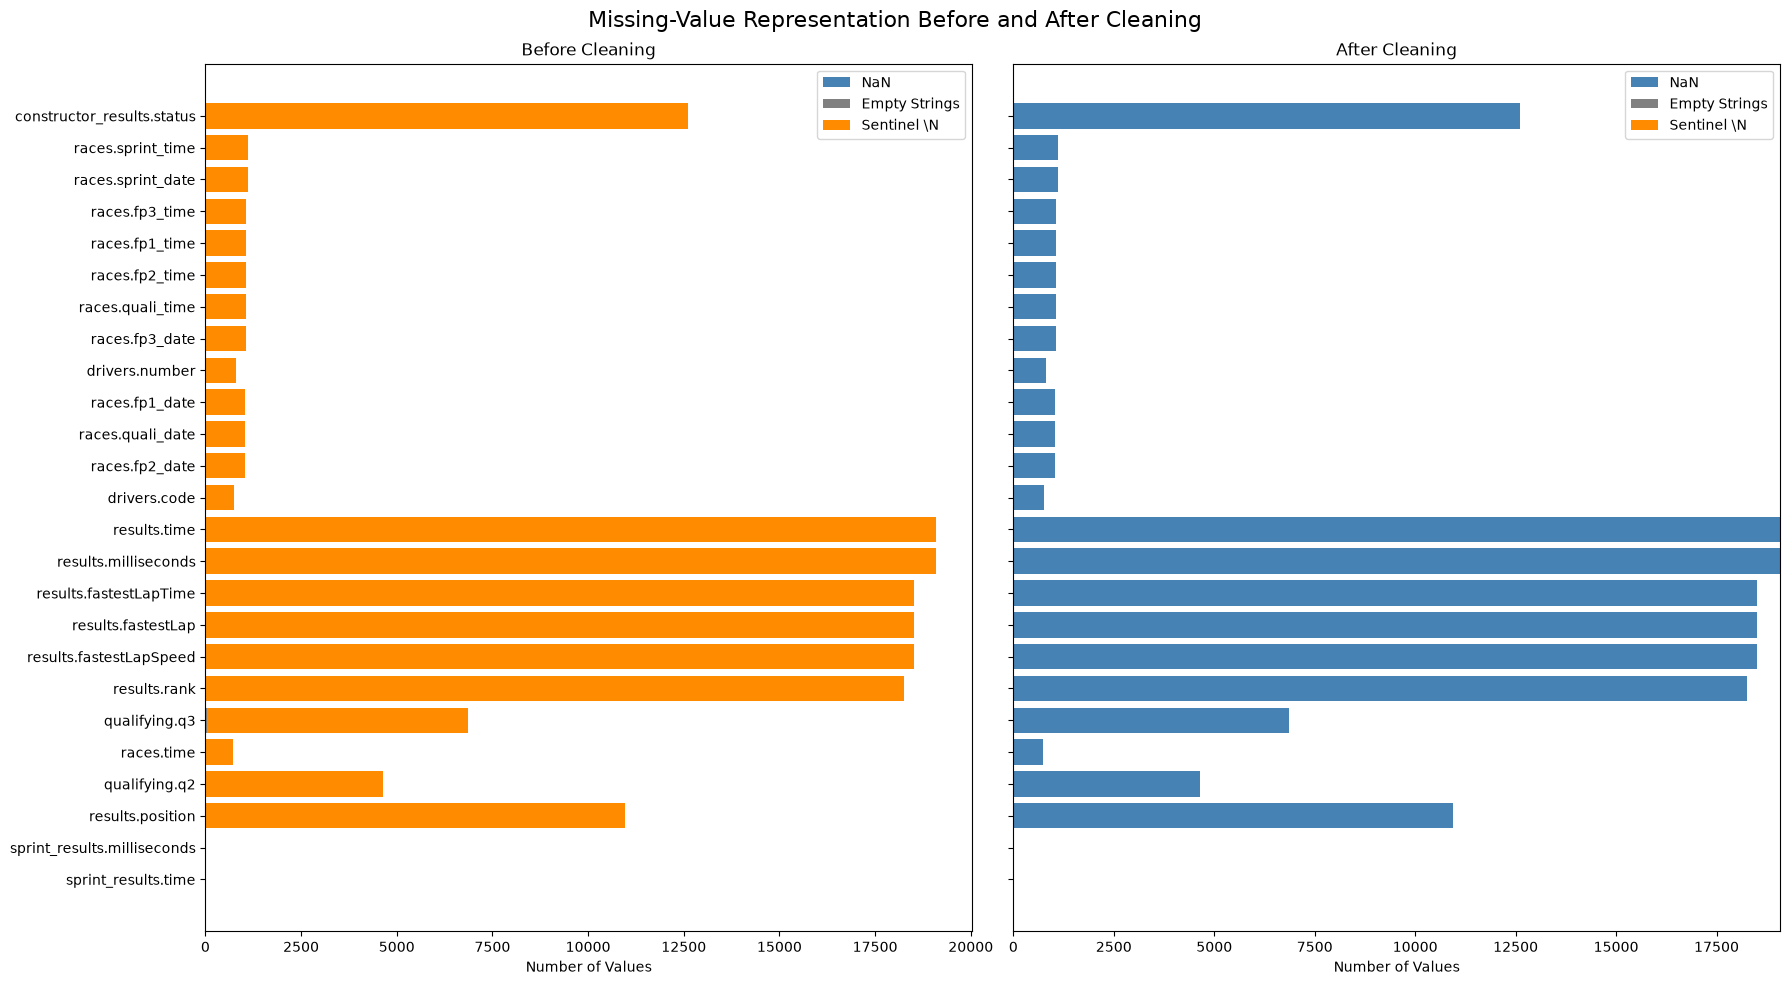

In [139]:
fig, axes = plt.subplots(
    1,
    2,
    figsize=(18, 10),
    sharey=True
)

for ax, stage in zip(
    axes,
    ["Before Cleaning", "After Cleaning"]
):
    stage_data = (
        comparison[comparison["Stage"] == stage]
        .set_index("Feature")
        .reindex(top_features)
    )

    ax.barh(
        stage_data.index,
        stage_data["NaN"],
        label="NaN",
        color="steelblue"
    )

    ax.barh(
        stage_data.index,
        stage_data["Empty Strings"],
        left=stage_data["NaN"],
        label="Empty Strings",
        color="gray"
    )

    ax.barh(
        stage_data.index,
        stage_data["Sentinel Values"],
        left=(
            stage_data["NaN"] +
            stage_data["Empty Strings"]
        ),
        label=r"Sentinel \N",
        color="darkorange"
    )

    ax.set_title(stage)
    ax.set_xlabel("Number of Values")
    ax.legend()

axes[0].invert_yaxis()

plt.suptitle(
    "Missing-Value Representation Before and After Cleaning",
    fontsize=16
)

plt.tight_layout()
plt.show()

,Columns_Audited,Available_Before,Available_After,Conversion_Failures
Table,,,,
circuits,9,693,693,0
constructors,5,1060,1060,0
drivers,9,6190,6190,0
races,18,8901,8901,0
seasons,2,150,150,0
status,2,278,278,0
results,18,358775,358775,0
qualifying,9,82778,82778,0
driver_standings,7,244041,244041,0


,Table,Column,Meaning,Unit,Before Type,After Type,Before Available,After Available,Values Lost During Conversion
0,circuits,circuitId,"Integer identifier, label, ordinal, or count",--,int64,Int64,77,77,0
1,circuits,lat,Numeric measurement or points,degrees,float64,Float64,77,77,0
2,circuits,lng,Numeric measurement or points,degrees,float64,Float64,77,77,0
3,circuits,alt,Numeric measurement or points,metres,int64,Float64,77,77,0
4,circuits,circuitRef,Trimmed text / category,--,str,string,77,77,0
5,circuits,name,Trimmed text / category,--,str,string,77,77,0
6,circuits,location,Trimmed text / category,--,str,string,77,77,0
7,circuits,country,Trimmed text / category,--,str,string,77,77,0
8,circuits,url,Trimmed text / category,--,str,string,77,77,0
9,constructors,constructorId,"Integer identifier, label, ordinal, or count",--,int64,Int64,212,212,0


Schema types verified; no sentinel or blank strings remain.


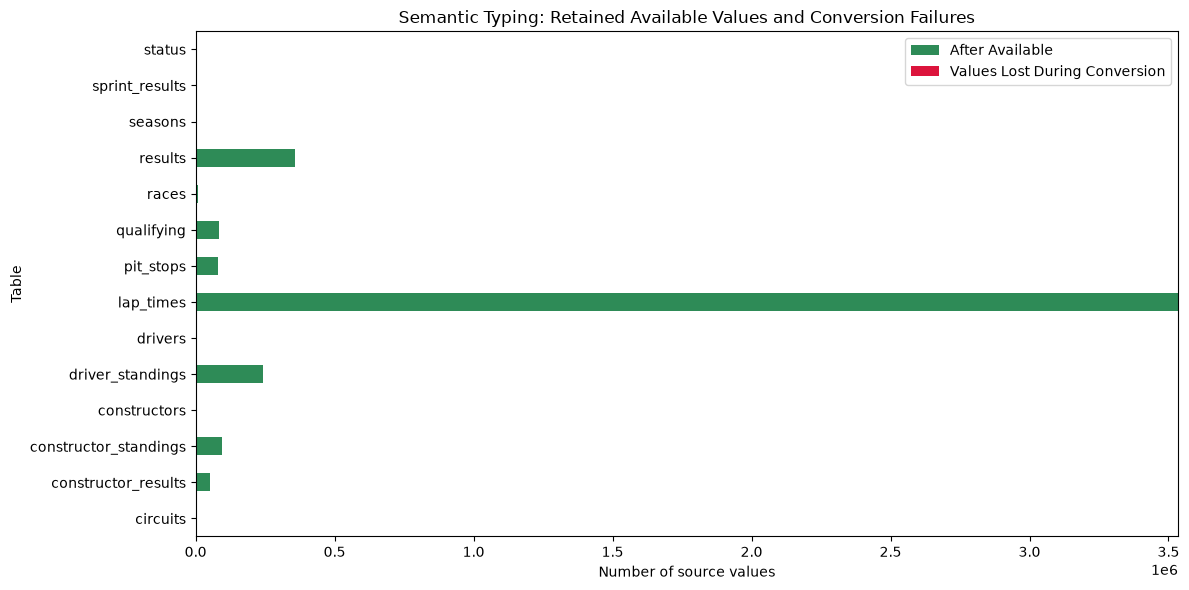

In [140]:
# Full coverage, including numeric fields, clock times, text, and milliseconds.
type_comparison_df = semantic_type_audit_df.copy()
display(type_comparison_df.groupby("Table", sort=False).agg(
    Columns_Audited=("Column", "size"),
    Available_Before=("Before Available", "sum"),
    Available_After=("After Available", "sum"),
    Conversion_Failures=("Values Lost During Conversion", "sum")
))
with pd.option_context("display.max_rows", None):
    display(type_comparison_df[[
        "Table", "Column", "Meaning", "Unit", "Before Type", "After Type",
        "Before Available", "After Available", "Values Lost During Conversion"
    ]])

# Missing markers and text whitespace must not survive normalization.
final_missing_profile = create_missing_profile(clean_data, stage="After Semantic Typing")
assert final_missing_profile["Sentinel Values"].sum() == 0
assert final_missing_profile["Empty Strings"].sum() == 0
for record in semantic_schema_df.to_dict("records"):
    name, column, kind = record["Table"], record["Column"], record["Semantic Type"]
    series = clean_data[name][column]
    if kind in {"integer", "milliseconds"}:
        assert str(series.dtype) == "Int64", (name, column)
    elif kind == "number":
        assert str(series.dtype) == "Float64", (name, column)
    elif kind == "date":
        assert pd.api.types.is_datetime64_any_dtype(series), (name, column)
    elif kind == "duration_seconds":
        assert pd.api.types.is_numeric_dtype(series), (name, column)
    elif kind == "clock_time":
        from datetime import time as clock_time_type
        assert series.dropna().map(lambda value: isinstance(value, clock_time_type)).all(), (name, column)
    else:
        assert isinstance(series.dtype, pd.StringDtype), (name, column)
print("Schema types verified; no sentinel or blank strings remain.")

# Plot audited conversion loss separately from values that were already missing.
conversion_totals = type_comparison_df.groupby("Table")[[
    "After Available", "Values Lost During Conversion"
]].sum()
conversion_totals.plot.barh(stacked=True, figsize=(12, 6), color=["seagreen", "crimson"])
plt.title("Semantic Typing: Retained Available Values and Conversion Failures")
plt.xlabel("Number of source values")
plt.tight_layout()
plt.show()


## Primary-key and foreign-key validation (step 5)

Run this audit on `clean_data` **after** missing-marker normalization and semantic typing. The earlier raw-data key audit is not a substitute for these checks. This implements the project brief's page 2 integrity requirements without modifying, dropping, or inventing any records.

We recheck all 14 declared primary keys, including the composite keys for laps and pit stops. We explicitly declare all 23 foreign-key relationships, including `races.year -> seasons.year`. `constructor_results.status` is a text field, not a reference to `status.statusId`. IDs are local to their tables: sprint `resultId` does not reference Grand Prix `resultId`.

Foreign-key membership checks use the complete parent key set, not an inner join that could hide missing matches. Null foreign keys, non-null unmatched values, and references to duplicate parent keys are counted separately. Parent keys must themselves be unique and non-null, and child/parent key dtypes must agree. These source references are treated as required by this audit.

The audit retains every offending row in `primary_key_issue_rows` or `foreign_key_issue_rows`. Compact detail tables include the source row index and primary-key values to locate the records. A failure produces `REVIEW` and full diagnostic output; it never triggers an arbitrary repair. The final integrity assertion prevents later modeling joins from proceeding until failures are investigated.


In [141]:
# Explicit child table / column -> parent table / primary-key column.
foreign_key_spec = [
    ("races", "circuitId", "circuits", "circuitId"),
    ("races", "year", "seasons", "year"),
    ("results", "raceId", "races", "raceId"),
    ("results", "driverId", "drivers", "driverId"),
    ("results", "constructorId", "constructors", "constructorId"),
    ("results", "statusId", "status", "statusId"),
    ("qualifying", "raceId", "races", "raceId"),
    ("qualifying", "driverId", "drivers", "driverId"),
    ("qualifying", "constructorId", "constructors", "constructorId"),
    ("driver_standings", "raceId", "races", "raceId"),
    ("driver_standings", "driverId", "drivers", "driverId"),
    ("constructor_standings", "raceId", "races", "raceId"),
    ("constructor_standings", "constructorId", "constructors", "constructorId"),
    ("constructor_results", "raceId", "races", "raceId"),
    ("constructor_results", "constructorId", "constructors", "constructorId"),
    ("lap_times", "raceId", "races", "raceId"),
    ("lap_times", "driverId", "drivers", "driverId"),
    ("pit_stops", "raceId", "races", "raceId"),
    ("pit_stops", "driverId", "drivers", "driverId"),
    ("sprint_results", "raceId", "races", "raceId"),
    ("sprint_results", "driverId", "drivers", "driverId"),
    ("sprint_results", "constructorId", "constructors", "constructorId"),
    ("sprint_results", "statusId", "status", "statusId")
]

# Guard against omitting a reference column if the source schema changes.
reference_targets = {
    "raceId": "races", "driverId": "drivers", "constructorId": "constructors",
    "circuitId": "circuits", "statusId": "status"
}
expected_references = {
    (name, column, parent, column)
    for name, table in clean_data.items()
    for column, parent in reference_targets.items()
    if column in table.columns and name != parent
} | {("races", "year", "seasons", "year")}
assert len(foreign_key_spec) == len(set(foreign_key_spec))
assert set(foreign_key_spec) == expected_references, "Review foreign-key coverage."
assert set(table_key_spec) == set(clean_data), "Review primary-key coverage."

clean_primary_key_audit_df = pd.DataFrame([
    audit_declared_key(clean_data[name], name, columns, "Clean source primary key")
    for name, (_, columns) in table_key_spec.items()
])
primary_key_issue_rows = {}
for name, (_, columns) in table_key_spec.items():
    key_values = clean_data[name][columns]
    missing = key_values.isna().any(axis=1)
    duplicated = ~missing & key_values.duplicated(keep=False)
    if (missing | duplicated).any():
        issue_rows = clean_data[name].loc[missing | duplicated].copy()
        issue_rows.insert(0, "Audit Source Row Index", issue_rows.index)
        issue_rows.insert(1, "Audit Reason", np.where(
            missing.loc[issue_rows.index], "Missing primary-key component", "Duplicate primary key"
        ))
        primary_key_issue_rows[name] = issue_rows


def audit_foreign_keys(tables, relationships, primary_keys):
    summary, unmatched_values, row_details = [], [], []
    issue_rows_by_relationship = {}
    for child, column, parent, parent_column in relationships:
        if primary_keys[parent][1] != [parent_column]:
            raise ValueError(f"{parent}.{parent_column} is not its declared single-column primary key.")
        relation = f"{child}.{column} -> {parent}.{parent_column}"
        values = tables[child][column]
        parent_values = tables[parent][parent_column]
        parent_complete = parent_values.dropna()
        duplicate_parent_values = parent_complete[parent_complete.duplicated(keep=False)]
        parent_valid = bool(parent_values.notna().all() and parent_complete.is_unique)
        dtype_match = values.dtype == parent_values.dtype
        missing = values.isna()
        unmatched = ~missing & ~values.isin(parent_complete)
        matched = ~missing & values.isin(parent_complete)
        ambiguous = ~missing & values.isin(duplicate_parent_values)
        affected = missing | unmatched | ambiguous
        passed = parent_valid and dtype_match and not affected.any()
        summary.append({
            "Relationship": relation,
            "Child Rows": len(values),
            "Parent Key Valid": parent_valid,
            "Dtypes Match": dtype_match,
            "Missing FK Rows": int(missing.sum()),
            "Unmatched Distinct Values": int(values.loc[unmatched].nunique()),
            "Unmatched Rows": int(unmatched.sum()),
            "Matched Rows": int(matched.sum()),
            "Ambiguous Parent Rows": int(ambiguous.sum()),
            "Affected Child Rows": int(affected.sum()),
            "Status": "PASS" if passed else "REVIEW"
        })
        for value, count in values.loc[unmatched].value_counts().items():
            unmatched_values.append({
                "Relationship": relation, "Unmatched Value": value, "Affected Rows": int(count)
            })
        if affected.any():
            bad_rows = tables[child].loc[affected].copy()
            bad_rows.insert(0, "Audit Source Row Index", bad_rows.index)
            reasons = pd.Series("", index=values.index, dtype="string")
            reasons.loc[missing] = "Missing foreign key"
            reasons.loc[unmatched] = "No matching parent key"
            reasons.loc[ambiguous] = "Parent key is duplicated"
            bad_rows.insert(1, "Audit Reason", reasons.loc[bad_rows.index])
            issue_rows_by_relationship[relation] = bad_rows
            for index in bad_rows.index:
                row_details.append({
                    "Relationship": relation, "Source Row Index": index,
                    "Source Primary Key": str(tables[child].loc[index, primary_keys[child][1]].to_dict()),
                    "Foreign Key Value": values.loc[index], "Reason": reasons.loc[index]
                })
    return (
        pd.DataFrame(summary),
        pd.DataFrame(unmatched_values, columns=["Relationship", "Unmatched Value", "Affected Rows"]),
        pd.DataFrame(row_details, columns=[
            "Relationship", "Source Row Index", "Source Primary Key", "Foreign Key Value", "Reason"
        ]),
        issue_rows_by_relationship
    )

(foreign_key_audit_df, foreign_key_unmatched_values_df,
 foreign_key_issue_details_df, foreign_key_issue_rows) = audit_foreign_keys(
    clean_data, foreign_key_spec, table_key_spec
)


Primary-key audit after normalization and semantic typing


,Table,Key Role,Key Columns,Rows,Missing-Key Rows,Distinct Complete Keys,Duplicate Groups,Rows in Duplicate Groups,Excess Rows,Status
0,circuits,Clean source primary key,circuitId,77,0,77,0,0,0,PASS
1,constructors,Clean source primary key,constructorId,212,0,212,0,0,0,PASS
2,drivers,Clean source primary key,driverId,861,0,861,0,0,0,PASS
3,races,Clean source primary key,raceId,1125,0,1125,0,0,0,PASS
4,seasons,Clean source primary key,year,75,0,75,0,0,0,PASS
5,status,Clean source primary key,statusId,139,0,139,0,0,0,PASS
6,results,Clean source primary key,resultId,26759,0,26759,0,0,0,PASS
7,qualifying,Clean source primary key,qualifyId,10494,0,10494,0,0,0,PASS
8,driver_standings,Clean source primary key,driverStandingsId,34863,0,34863,0,0,0,PASS
9,constructor_standings,Clean source primary key,constructorStandingsId,13391,0,13391,0,0,0,PASS


Foreign-key reconciliation: all declared relationships


,Relationship,Child Rows,Parent Key Valid,Dtypes Match,Missing FK Rows,Unmatched Distinct Values,Unmatched Rows,Matched Rows,Ambiguous Parent Rows,Affected Child Rows,Status
0,races.circuitId -> circuits.circuitId,1125,True,True,0,0,0,1125,0,0,PASS
1,races.year -> seasons.year,1125,True,True,0,0,0,1125,0,0,PASS
2,results.raceId -> races.raceId,26759,True,True,0,0,0,26759,0,0,PASS
3,results.driverId -> drivers.driverId,26759,True,True,0,0,0,26759,0,0,PASS
4,results.constructorId -> constructors.construc...,26759,True,True,0,0,0,26759,0,0,PASS
5,results.statusId -> status.statusId,26759,True,True,0,0,0,26759,0,0,PASS
6,qualifying.raceId -> races.raceId,10494,True,True,0,0,0,10494,0,0,PASS
7,qualifying.driverId -> drivers.driverId,10494,True,True,0,0,0,10494,0,0,PASS
8,qualifying.constructorId -> constructors.const...,10494,True,True,0,0,0,10494,0,0,PASS
9,driver_standings.raceId -> races.raceId,34863,True,True,0,0,0,34863,0,0,PASS


Unmatched non-null values and their affected-row counts


,Relationship,Unmatched Value,Affected Rows


Affected child-row details (null, unmatched, or ambiguous parent)


,Relationship,Source Row Index,Source Primary Key,Foreign Key Value,Reason


Empty issue tables mean no failures were found, not that checks were skipped.
FK row counts are per relationship: a source row can participate in several checks.
Ambiguous-parent rows are a subset of matched rows; affected rows are their union with missing/unmatched rows.


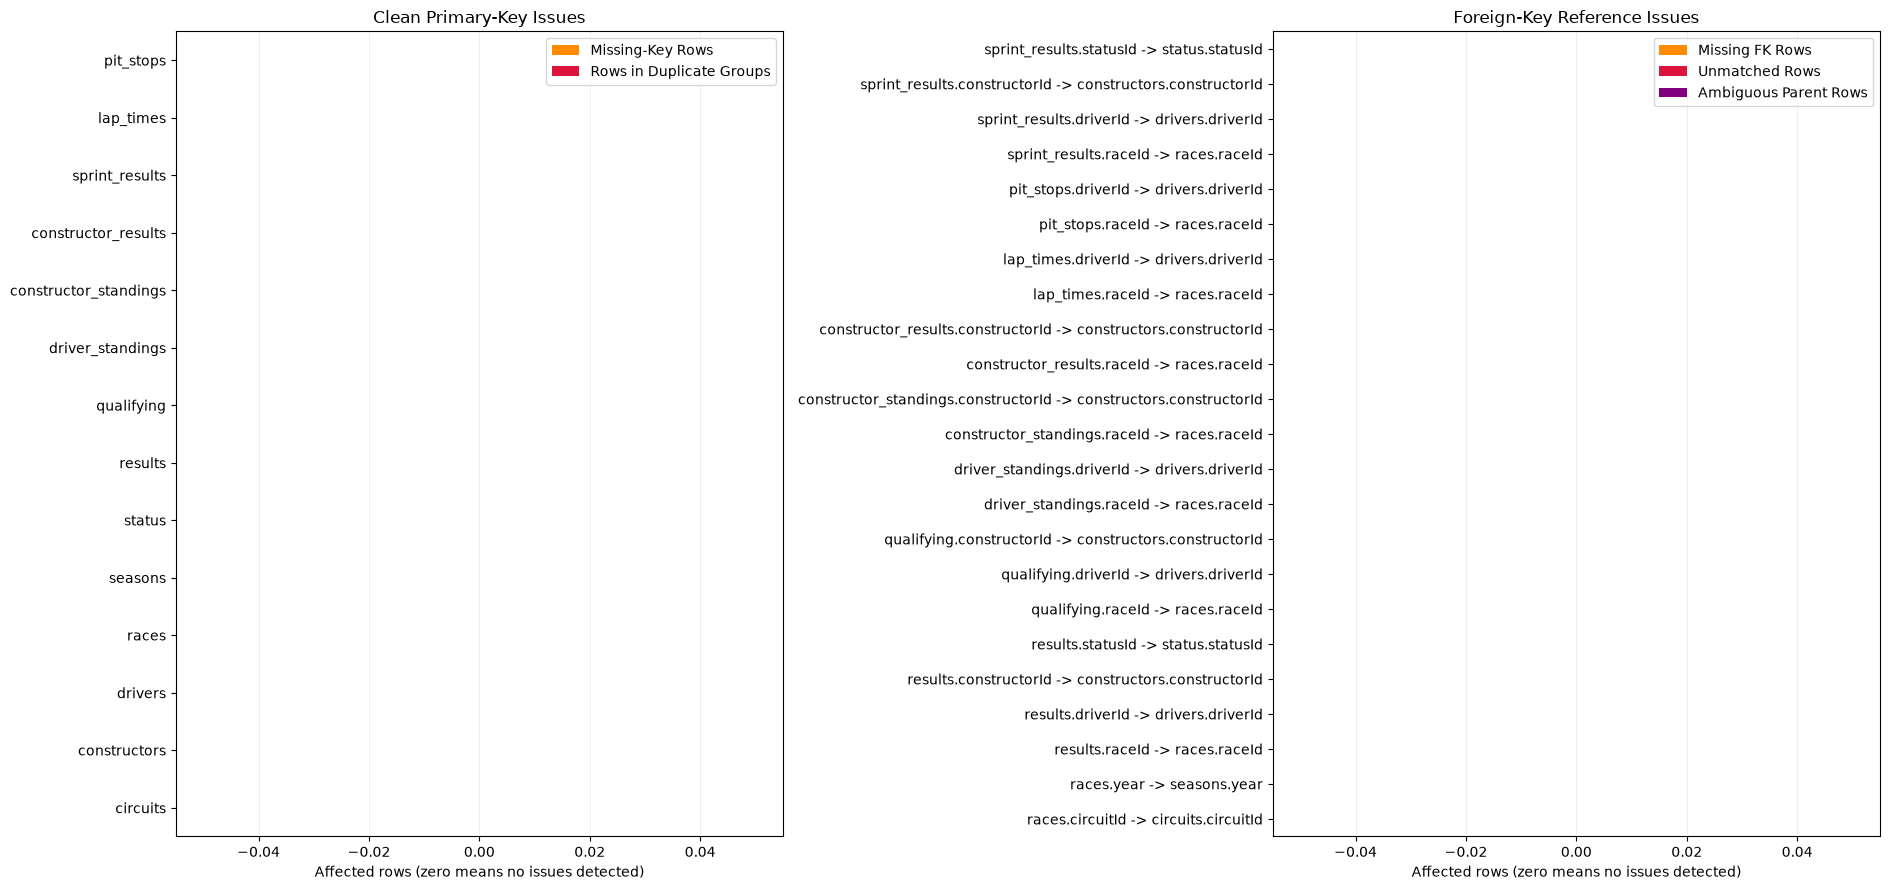

Primary keys passing: 14/14
Foreign-key relationships passing: 23/23
Source primary keys and foreign-key references validated; no data repairs applied.


In [142]:
print("Primary-key audit after normalization and semantic typing")
with pd.option_context("display.max_rows", None, "display.max_columns", None):
    display(clean_primary_key_audit_df)
    print("Foreign-key reconciliation: all declared relationships")
    display(foreign_key_audit_df)
    print("Unmatched non-null values and their affected-row counts")
    display(foreign_key_unmatched_values_df)
    print("Affected child-row details (null, unmatched, or ambiguous parent)")
    display(foreign_key_issue_details_df)
    for name, rows in primary_key_issue_rows.items():
        print(f"Primary-key failures in {name}; investigate all conflicting rows")
        display(rows)

print("Empty issue tables mean no failures were found, not that checks were skipped.")
print("FK row counts are per relationship: a source row can participate in several checks.")
print("Ambiguous-parent rows are a subset of matched rows; affected rows are their union with missing/unmatched rows.")

# Make primary-key failure and missing-reference counts visible in the notebook/report.
fig, axes = plt.subplots(1, 2, figsize=(19, 9))
clean_primary_key_audit_df.set_index("Table")[[
    "Missing-Key Rows", "Rows in Duplicate Groups"
]].plot.barh(ax=axes[0], color=["darkorange", "crimson"])
foreign_key_audit_df.set_index("Relationship")[[
    "Missing FK Rows", "Unmatched Rows", "Ambiguous Parent Rows"
]].plot.barh(ax=axes[1], stacked=True, color=["darkorange", "crimson", "purple"])
axes[0].set_title("Clean Primary-Key Issues")
axes[1].set_title("Foreign-Key Reference Issues")
for ax in axes:
    ax.set_xlabel("Affected rows (zero means no issues detected)")
    ax.set_ylabel("")
    ax.grid(axis="x", alpha=0.2)
    ax.set_axisbelow(True)
plt.tight_layout()
plt.show()

primary_keys_valid = clean_primary_key_audit_df["Status"].eq("PASS").all()
foreign_keys_valid = foreign_key_audit_df["Status"].eq("PASS").all()
print(f"Primary keys passing: {clean_primary_key_audit_df['Status'].eq('PASS').sum()}/{len(clean_primary_key_audit_df)}")
print(f"Foreign-key relationships passing: {foreign_key_audit_df['Status'].eq('PASS').sum()}/{len(foreign_key_audit_df)}")
assert primary_keys_valid and foreign_keys_valid, (
    "Integrity audit failed. Investigate the saved issue tables and original raw_data; "
    "document a supported correction, exclusion, or limitation before proceeding. "
    "Do not invent IDs or arbitrarily drop conflicting primary-key rows."
)
print("Source primary keys and foreign-key references validated; no data repairs applied.")


### Findings and decision for the current dataset

All **14 cleaned source primary keys** are complete and unique. All **23 foreign-key relationships** pass: zero missing foreign-key rows, zero unmatched values/rows, zero references to duplicated parent keys, and matching child/parent key dtypes. The empty issue tables and zero-length bars reflect this result. No correction or exclusion is supported or needed for these checks, so all source rows are retained.

If a later dataset produces failures, inspect the detailed source rows and their counterparts in `raw_data`, check whether typing introduced nulls using `conversion_failures_df`, and confirm the parent table's completeness and key conflicts. Record evidence for any eventual correction, exclusion, or retention with a limitation. The audit never makes that decision automatically.

This does **not** resolve the 85 repeated `(raceId, driverId)` groups in `results`: `resultId` can be unique while driver-race grain is not. Duplicate handling remains a separate required step before modeling-table assembly. Matching each individual foreign key also does not prove that every possible combination (for example a race-driver pair in another fact table) exists, nor does it establish pre-race feature availability.


## F1 exceptions and modeling population (step 6)

**Population decision:** retain a broad **recorded-entrant population**, consistent with the brief's driver-entering-a-race wording. The CSVs do not provide a reliable timestamped eligibility list at the cutoff. Retain recorded qualifying failures, withdrawals, exclusions, retirements, and disqualifications rather than filtering retrospectively on outcomes. This population is **not** a certified list of eligible starters; a narrower eligible-starter population would require additional evidence and a documented revision.

**Optional scope choice:** exclude Indianapolis 500 events in 1950-1960 from a separate candidate copy. The terminology guide (page 7) describes their different fields and racing context. This is a reversible design choice, not a mandatory cleaning rule. Identify these events by name and year, not by circuit ID. Preserve all cleaned source records for retrospective analyses and comparisons.

The diagnostic joins below are validated many-to-one and checked for complete matches and row preservation. All status/lap-based flags are retrospective audit evidence, never current-race predictors. **modeling_population_candidates** is a source-row copy, not a final unique modeling table or predictor matrix. The mechanical-retirement question needs a separately justified race-start denominator.

No other years or outcomes are excluded. No constructor identities are merged. Driver-race duplicate resolution remains step 7.


In [143]:
EXCLUDE_INDIANAPOLIS_500 = True  # Optional, reversible scope choice.

def build_population_audit(tables, exclude_indianapolis=True):
    audit = tables["results"].copy(deep=True)
    audit.insert(0, "source_row_index", audit.index)
    ids_before = audit["resultId"].tolist()
    lookups = [
        ("raceId", tables["races"][["raceId", "year", "date", "circuitId", "name"]].rename(columns={"name": "race_name"})),
        ("statusId", tables["status"][["statusId", "status"]]),
        ("driverId", tables["drivers"][["driverId", "forename", "surname"]]),
        ("constructorId", tables["constructors"][["constructorId", "name"]].rename(columns={"name": "constructor_name"}))
    ]
    for key, lookup in lookups:
        audit = audit.merge(lookup, on=key, how="left", validate="many_to_one", indicator="_match", sort=False)
        assert audit["_match"].eq("both").all(), f"Unmatched {key}"
        audit = audit.drop(columns="_match")
        assert audit["resultId"].tolist() == ids_before, f"Rows/order changed in {key} join"
    audit["grid_zero"] = audit["grid"].eq(0).fillna(False)
    audit["recorded_qualifying_failure"] = (
        audit["status"].isin(["Did not qualify", "Did not prequalify", "107% Rule"])
        | audit["positionText"].eq("F").fillna(False)
    )
    for field, label, code in [
        ("recorded_withdrawal", "Withdrew", "W"),
        ("recorded_exclusion", "Excluded", "E"),
        ("recorded_disqualification", "Disqualified", "D")
    ]:
        audit[field] = audit["status"].eq(label).fillna(False) | audit["positionText"].eq(code).fillna(False)
    audit["retirement_code_R"] = audit["positionText"].eq("R").fillna(False)
    audit["completed_laps_recorded"] = audit["laps"].gt(0).fillna(False)
    audit["is_indianapolis_500"] = (
        audit["race_name"].eq("Indianapolis 500").fillna(False)
        & audit["year"].between(1950, 1960).fillna(False)
    )
    nonstart_marker = audit[["recorded_qualifying_failure", "recorded_withdrawal", "recorded_exclusion"]].any(axis=1)
    audit["participation_record_conflict"] = nonstart_marker & audit["completed_laps_recorded"]
    audit["needs_eligibility_review"] = (
        nonstart_marker | (audit["grid_zero"] & ~audit["completed_laps_recorded"])
        | (audit["recorded_disqualification"] & ~audit["completed_laps_recorded"])
    )
    # Mutually exclusive diagnostic categories; later rules take priority.
    audit["grid_zero_audit_group"] = "Not grid zero"
    for mask, label in [
        (audit["grid_zero"], "Zero grid; no completed laps recorded"),
        (audit["grid_zero"] & audit["completed_laps_recorded"], "Zero grid; completed laps recorded"),
        (audit["grid_zero"] & audit["recorded_exclusion"], "Zero grid; recorded exclusion"),
        (audit["grid_zero"] & audit["recorded_withdrawal"], "Zero grid; recorded withdrawal"),
        (audit["grid_zero"] & audit["recorded_qualifying_failure"], "Zero grid; recorded qualifying failure")
    ]:
        audit.loc[mask, "grid_zero_audit_group"] = label
    # Only event identity affects scope. Outcomes do not determine inclusion.
    audit["population_keep"] = ~(audit["is_indianapolis_500"] & bool(exclude_indianapolis))
    audit["population_reason"] = "Retain recorded entrant; no outcome-based exclusion"
    audit.loc[~audit["population_keep"], "population_reason"] = "Optional exclusion: Indianapolis 500, 1950-1960"
    return audit

assert primary_keys_valid and foreign_keys_valid, "Complete step 5 first."
population_audit = build_population_audit(clean_data, EXCLUDE_INDIANAPOLIS_500)
selected_ids = population_audit.loc[population_audit["population_keep"], "resultId"]
modeling_population_candidates = clean_data["results"].loc[
    clean_data["results"]["resultId"].isin(selected_ids)
].copy(deep=True)
# This copy retains source columns for later target/history work; it is NOT X.
assert list(modeling_population_candidates.columns) == list(clean_data["results"].columns)

population_policy_df = pd.DataFrame([
    ("Population", "Retain recorded entrants", "Not a certified eligible-starter list; timing evidence is incomplete."),
    ("Grid zero", "Retain; represent as zero/unspecified and unranked later", "Use grid alone, not status/laps, for this predictor representation. Not a confirmed pit-lane label."),
    ("Qualifying failure / withdrawal / exclusion", "Retain and flag for review", "No reliable cutoff timestamps; some labels conflict with completed laps."),
    ("Retirement / accident / mechanical failure / disqualification", "Retain", "Legitimate outcomes; do not filter unsuccessful predictions."),
    ("Indianapolis 500, 1950-1960", "Exclude from candidates" if EXCLUDE_INDIANAPOLIS_500 else "Retain in candidates", "Optional scope choice; source rows remain available."),
    ("Constructor identity", "Follow constructorId; do not merge by name", "Different IDs begin separate histories; no ownership/lineage inference."),
    ("Driver changes constructor", "Retain race-level assignment", "Transfers can be legitimate; same-race conflicts need step 7."),
    ("Repeated driver-race entries", "Preserve for step 7", "Candidate rows are not yet unique predictions.")
], columns=["Case", "Action", "Reason / Limitation"])


In [144]:
def population_counts(frame):
    return {
        "Rows": len(frame),
        "Distinct Driver-Race Pairs": len(frame[["raceId", "driverId"]].drop_duplicates()),
        "Races": frame["raceId"].nunique()
    }

population_category_masks = {
    "All source entries": pd.Series(True, index=population_audit.index),
    "Grid zero": population_audit["grid_zero"],
    "Recorded qualifying failure": population_audit["recorded_qualifying_failure"],
    "Recorded withdrawal": population_audit["recorded_withdrawal"],
    "Recorded exclusion": population_audit["recorded_exclusion"],
    "Retirement code R": population_audit["retirement_code_R"],
    "Recorded disqualification": population_audit["recorded_disqualification"],
    "Indianapolis 500": population_audit["is_indianapolis_500"],
    "Eligibility review markers": population_audit["needs_eligibility_review"],
    "Non-start-like label with completed laps": population_audit["participation_record_conflict"]
}
population_category_summary = pd.DataFrame([
    {"Category": label, **population_counts(population_audit.loc[mask]),
     "Retained Candidate Rows": int(population_audit.loc[mask, "population_keep"].sum())}
    for label, mask in population_category_masks.items()
])
population_scope_summary = pd.DataFrame([
    {"Scope": "All source entries", **population_counts(population_audit)},
    {"Scope": "Selected candidate population", **population_counts(modeling_population_candidates)},
    {"Scope": "Excluded by event-scope policy", **population_counts(population_audit.loc[~population_audit["population_keep"]])}
])
eligibility_review_rows = population_audit.loc[population_audit["needs_eligibility_review"]].copy()
participation_conflict_rows = population_audit.loc[population_audit["participation_record_conflict"]].copy()
grid_zero_rows = population_audit.loc[population_audit["grid_zero"]].copy()
grid_zero_rows["audit_pair"] = list(zip(grid_zero_rows["raceId"], grid_zero_rows["driverId"]))
grid_zero_status_summary = grid_zero_rows.groupby(["status", "positionText"], dropna=False).agg(
    Rows=("resultId", "size"), Distinct_Driver_Race_Pairs=("audit_pair", "nunique"),
    Earliest_Season=("year", "min"), Latest_Season=("year", "max")
).reset_index().sort_values("Rows", ascending=False)
grid_zero_by_season = pd.crosstab(grid_zero_rows["year"], grid_zero_rows["grid_zero_audit_group"])
indianapolis_event_audit = population_audit.loc[population_audit["is_indianapolis_500"]].groupby(
    ["raceId", "year", "race_name"], dropna=False
).agg(Rows=("resultId", "size"), Distinct_Drivers=("driverId", "nunique")).reset_index().sort_values("year")

constructor_identity_audit = population_audit.groupby("constructorId").agg(
    Constructor_Name=("constructor_name", "first"), Earliest_Season=("year", "min"),
    Latest_Season=("year", "max"), Result_Rows=("resultId", "size"), Drivers=("driverId", "nunique")
).reset_index()
constructor_name_collisions = clean_data["constructors"].loc[
    clean_data["constructors"]["name"].duplicated(keep=False)
].copy()
driver_constructor_by_season = population_audit.groupby(["year", "driverId"]).agg(
    Distinct_Constructors=("constructorId", "nunique"),
    Constructor_IDs=("constructorId", lambda values: tuple(sorted(values.dropna().unique())))
).reset_index()
multi_constructor_driver_seasons = driver_constructor_by_season.loc[
    driver_constructor_by_season["Distinct_Constructors"].gt(1)
].copy()
same_race_constructor_conflicts = population_audit.groupby(["raceId", "driverId"]).agg(
    Distinct_Constructors=("constructorId", "nunique")
).reset_index()
same_race_constructor_conflicts = same_race_constructor_conflicts.loc[
    same_race_constructor_conflicts["Distinct_Constructors"].gt(1)
]

with pd.option_context("display.max_columns", None, "display.max_colwidth", 120):
    print("Population policy and limitations")
    display(population_policy_df)
    print("Overlapping categories: do not sum these rows")
    display(population_category_summary)
    print("Scope impact before duplicate handling")
    display(population_scope_summary)
    print("All grid-zero status / position-code groups")
    with pd.option_context("display.max_rows", None):
        display(grid_zero_status_summary)
    print("Indianapolis events selected by exact name and period")
    display(indianapolis_event_audit)
    detail_columns = ["resultId", "raceId", "driverId", "year", "race_name", "grid", "status", "positionText", "laps", "population_keep"]
    print(f"Participation conflicts: {len(participation_conflict_rows)} rows; all shown")
    with pd.option_context("display.max_rows", None):
        display(participation_conflict_rows[detail_columns])
    print(f"Eligibility-review markers: {len(eligibility_review_rows)} rows; first 15 shown; full data in eligibility_review_rows.")
    display(eligibility_review_rows[detail_columns].head(15))
    print(f"Constructor identities in results: {len(constructor_identity_audit)}; first 10 shown.")
    display(constructor_identity_audit.head(10))
    print("Exact constructor-name collisions (not an ownership map)")
    display(constructor_name_collisions)
    print(f"Driver-seasons with multiple constructor IDs: {len(multi_constructor_driver_seasons)}; first 10 shown. Not automatically errors.")
    display(multi_constructor_driver_seasons.head(10))
    print(f"Same-race driver pairs with multiple constructor IDs: {len(same_race_constructor_conflicts)}; investigate in step 7.")
    display(same_race_constructor_conflicts)

assert population_audit["resultId"].is_unique
assert len(population_audit) == len(clean_data["results"])
assert len(modeling_population_candidates) + int((~population_audit["population_keep"]).sum()) == len(population_audit)
assert population_audit.loc[~population_audit["is_indianapolis_500"], "population_keep"].all()
remaining_excess = modeling_population_candidates.duplicated(["raceId", "driverId"]).sum()
print(f"Candidate population has {remaining_excess} excess driver-race rows; step 7 is required.")


Population policy and limitations


,Case,Action,Reason / Limitation
0,Population,Retain recorded entrants,Not a certified eligible-starter list; timing evidence is incomplete.
1,Grid zero,Retain; represent as zero/unspecified and unranked later,"Use grid alone, not status/laps, for this predictor representation. Not a confirmed pit-lane label."
2,Qualifying failure / withdrawal / exclusion,Retain and flag for review,No reliable cutoff timestamps; some labels conflict with completed laps.
3,Retirement / accident / mechanical failure / disqualification,Retain,Legitimate outcomes; do not filter unsuccessful predictions.
4,"Indianapolis 500, 1950-1960",Exclude from candidates,Optional scope choice; source rows remain available.
5,Constructor identity,Follow constructorId; do not merge by name,Different IDs begin separate histories; no ownership/lineage inference.
6,Driver changes constructor,Retain race-level assignment,Transfers can be legitimate; same-race conflicts need step 7.
7,Repeated driver-race entries,Preserve for step 7,Candidate rows are not yet unique predictions.


Overlapping categories: do not sum these rows


,Category,Rows,Distinct Driver-Race Pairs,Races,Retained Candidate Rows
0,All source entries,26759,26668,1125,26354
1,Grid zero,1638,1635,413,1638
2,Recorded qualifying failure,1368,1366,303,1368
3,Recorded withdrawal,356,355,196,356
4,Recorded exclusion,9,9,9,9
5,Retirement code R,8897,8879,1103,8721
6,Recorded disqualification,151,151,113,150
7,Indianapolis 500,405,381,11,0
8,Eligibility review markers,1745,1742,450,1745
9,Non-start-like label with completed laps,25,25,20,25


Scope impact before duplicate handling


...

Driver-seasons with multiple constructor IDs: 312; first 10 shown. Not automatically errors.


,year,driverId,Distinct_Constructors,Constructor_IDs
2,1950,501,2,"(87, 154)"
7,1950,529,2,"(113, 150)"
34,1950,686,2,"(51, 105)"
36,1950,697,2,"(105, 163)"
70,1950,793,2,"(6, 154)"
85,1951,498,2,"(6, 154)"
94,1951,589,2,"(105, 154)"
107,1951,640,2,"(51, 105)"
122,1951,686,2,"(6, 66)"
165,1952,427,2,"(128, 141)"


Same-race driver pairs with multiple constructor IDs: 16; investigate in step 7.


,raceId,driverId,Distinct_Constructors
13659,540,229,2
18222,733,465,2
18445,742,475,2
18982,766,541,2
19459,788,624,2
19733,800,556,2
19740,800,612,3
19758,800,702,2
19759,800,730,2
19934,809,512,2


Candidate population has 67 excess driver-race rows; step 7 is required.


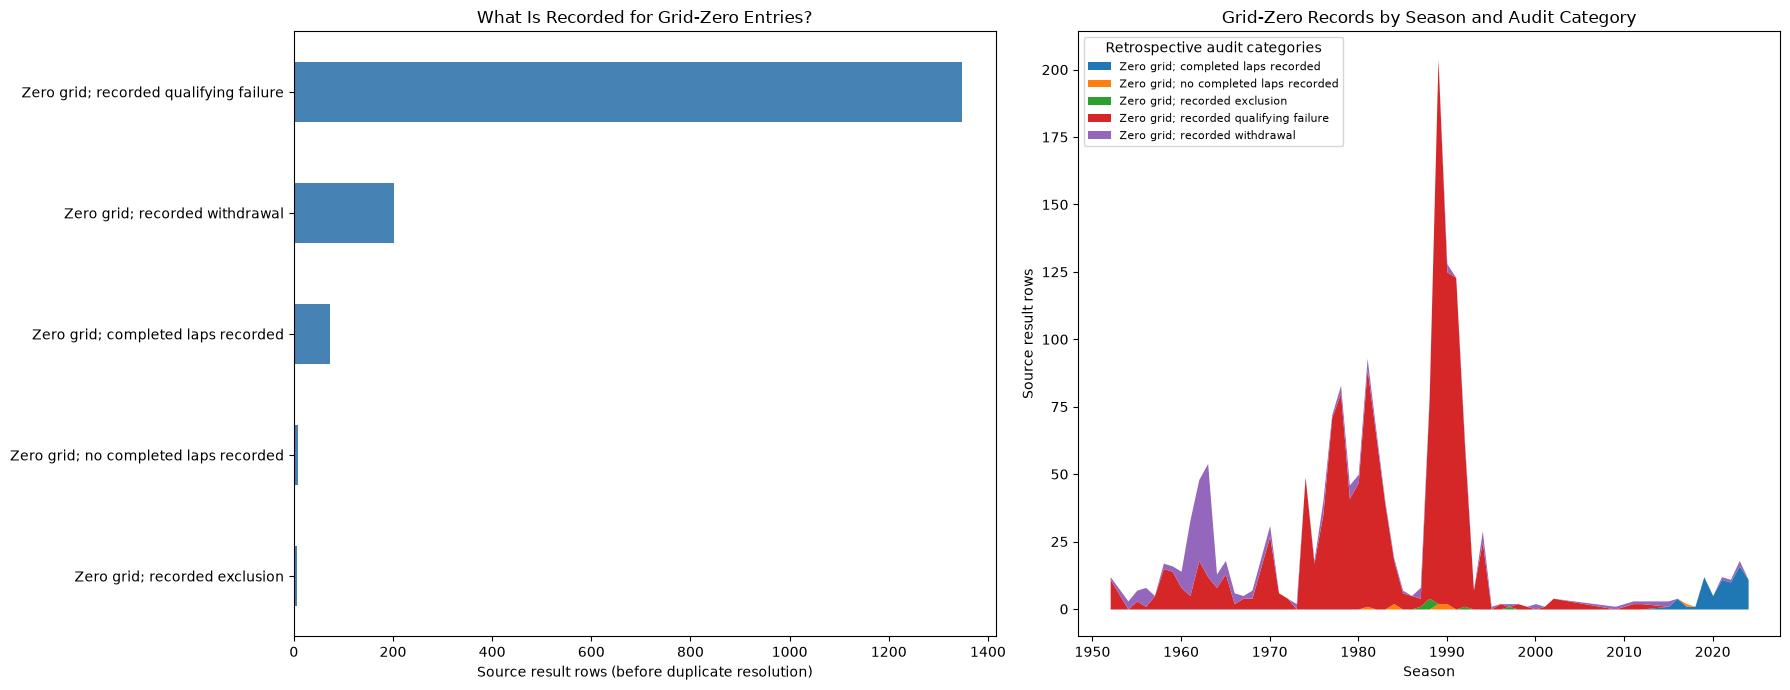

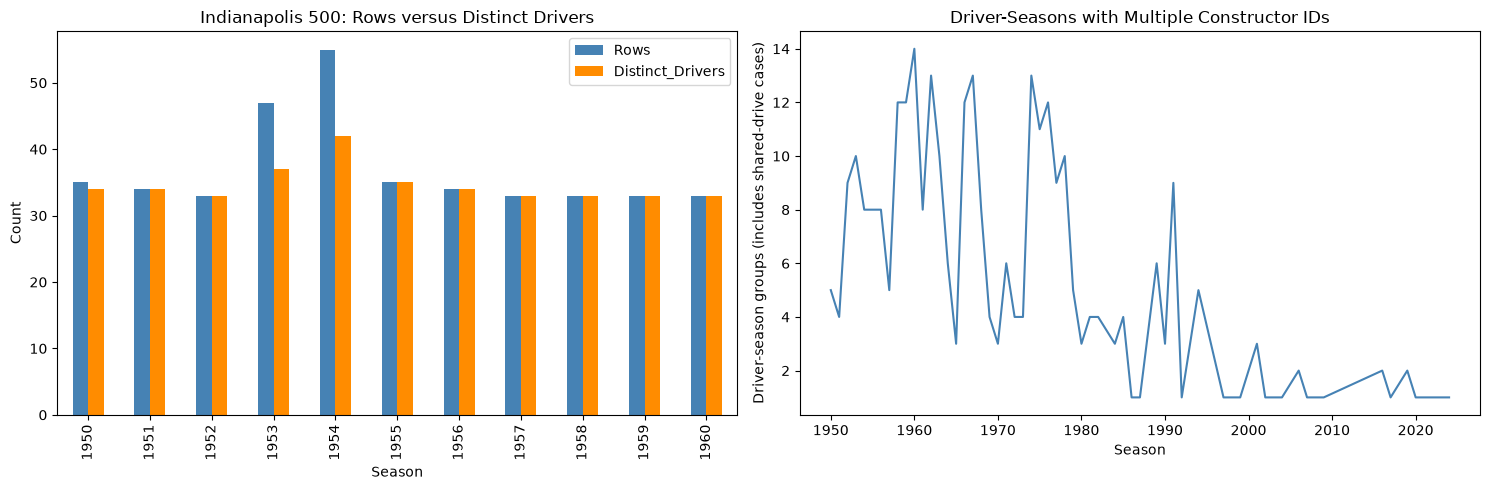

In [145]:
fig, axes = plt.subplots(1, 2, figsize=(18, 7))
grid_zero_rows["grid_zero_audit_group"].value_counts().sort_values().plot.barh(ax=axes[0], color="steelblue")
axes[0].set_title("What Is Recorded for Grid-Zero Entries?")
axes[0].set_xlabel("Source result rows (before duplicate resolution)")
axes[0].set_ylabel("")
grid_zero_by_season.plot.area(ax=axes[1], stacked=True, linewidth=0)
axes[1].set_title("Grid-Zero Records by Season and Audit Category")
axes[1].set_xlabel("Season")
axes[1].set_ylabel("Source result rows")
axes[1].legend(title="Retrospective audit categories", fontsize=8, loc="upper left")
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
indianapolis_event_audit.set_index("year")[["Rows", "Distinct_Drivers"]].plot.bar(
    ax=axes[0], color=["steelblue", "darkorange"]
)
axes[0].set_title("Indianapolis 500: Rows versus Distinct Drivers")
axes[0].set_xlabel("Season")
axes[0].set_ylabel("Count")
multi_constructor_driver_seasons.groupby("year").size().plot(ax=axes[1], color="steelblue")
axes[1].set_title("Driver-Seasons with Multiple Constructor IDs")
axes[1].set_xlabel("Season")
axes[1].set_ylabel("Driver-season groups (includes shared-drive cases)")
plt.tight_layout()
plt.show()


### Interpretation and next-step handoff

- **Grid zero is not a confirmed pit-lane label.** The status/code table and season plot show several recorded situations. The future representation should use grid alone: a zero/unspecified indicator plus an unranked value rather than ranking zero above pole. Do not use retrospective status/laps to determine that predictor. Zero completed laps does not prove a non-start.
- **Keep uncertainty explicit.** A qualifying-failure label with completed laps, and withdrawal/exclusion labels with completed laps, require investigation. The full **participation_conflict_rows** and **eligibility_review_rows** tables retain the evidence. The review queue is not exhaustive proof of eligibility; unflagged records are not certified eligible starters either.
- **Retain unsuccessful outcomes.** Retirements, accidents, mechanical failures, and disqualifications stay in scope when their event is included. R is a recorded retirement code, not an exhaustive DNF/mechanical classifier. Including some non-starters changes class balance and the interpretation of model scores; disclose the broad entrant-population limitation.
- **Indianapolis is optional scope.** With the default exclusion, 11 events (1950-1960), 405 source rows, and 381 distinct driver-race pairs are excluded from the candidate copy. It then contains 26,354 source rows and 26,287 distinct pairs. All 26,759 source rows remain in the cleaned results table. Change **EXCLUDE_INDIANAPOLIS_500** and rerun the section to compare inclusion. These counts describe the current data and default setting; the executed scope table is authoritative.
- **Preserve constructor identity.** Follow constructorId; do not infer team lineage from names. Driver-season changes may be legitimate transfers or shared-drive cases; the separate same-race table identifies conflicts needing step-7 investigation. The identity audit does not automatically merge teams.
- **Step 7 remains necessary.** There are 67 excess driver-race rows in the default candidate copy. Choose a deterministic rule with explicit label/pre-race-feature attribution and verify uniqueness before assembling the modeling table. Audit flags and current-race outcomes never belong in the predictor matrix. Question 3 separately requires a justified race-start denominator.


## Duplicate driver-race resolution (step 7)

Create one row per `(raceId, driverId)` from the population selected in step 6. The source results remain available for car-level and constructor analyses.

**Target rule:** `best_positionOrder = min(positionOrder)`; `podium = int(best_positionOrder <= 3)`. This means a driver is positive if any recorded result in that race is a podium. A driver appearing in two podium positions still gets one positive label. Shared-drive conventions can produce more than three positive drivers in a race. This is a documented driver-level target interpretation, not a reconstruction of official podium ceremonies.

**Grid and constructor rule:** handle each field independently. Retain a value only when every source row supplies the same nonmissing value. Otherwise leave it missing and record the conflict. Zero grid is retained when all rows agree on zero. Do not pick the smallest grid, the lowest result ID, or the best-finishing car for feature attribution. Even a positive grid can refer to a different car: the duplicate records contain multiple positive grids. Consensus is a conservative data rule; the CSVs cannot certify historical starting-car attribution.

**Tie-break and provenance:** all source result IDs are kept in sorted audit tuples. When several records tie for the best finish, the smallest result ID is the representative *label-evidence* ID only; all tied IDs remain in the audit. It never selects grid, constructor, or other predictors. No points, laps, status, time, or fastest-lap fields are combined into the unique table.

**Cutoff limitation:** duplicate membership itself is reconstructed from post-race records. Missingness introduced by conflicts may therefore reflect race events. Audit flags, source counts, and result IDs are excluded from the candidate table and must not become predictors. Before modeling these historical cases, validate original pre-race attribution independently or document an appropriate sensitivity analysis; outcome-invariant aggregation alone does not certify cutoff safety.


In [146]:
DRIVER_RACE_KEY = ["raceId", "driverId"]

def resolve_driver_race_entries(source):
    """Return unique driver-race candidates and a separate attribution audit."""
    required = ["resultId", *DRIVER_RACE_KEY, "grid", "constructorId", "positionOrder"]
    missing_columns = set(required) - set(source.columns)
    if missing_columns:
        raise ValueError(f"Missing columns: {sorted(missing_columns)}")
    if source.empty:
        raise ValueError("The selected population is empty.")
    if source[["resultId", *DRIVER_RACE_KEY]].isna().any().any():
        raise ValueError("Result IDs and driver-race keys must be complete.")
    if not source["resultId"].is_unique:
        raise ValueError("Duplicate resultId: source primary-key validation is required.")
    if source["positionOrder"].isna().any() or not source["positionOrder"].ge(1).all():
        raise ValueError("Complete positive positionOrder values are required for labels.")

    # No outcome columns enter feature consensus. Sorting IDs is for audit display only.
    ordered = source[required].sort_values([*DRIVER_RACE_KEY, "resultId"])
    grouped = ordered.groupby(DRIVER_RACE_KEY, sort=True, observed=True)
    resolved = grouped["positionOrder"].min().rename("best_positionOrder").to_frame()
    audit = grouped.size().rename("source_row_count").to_frame()
    audit["source_result_ids"] = grouped["resultId"].agg(
        lambda values: tuple(int(value) for value in values)
    )
    for field in ["grid", "constructorId"]:
        counts = grouped[field].count()
        distinct = grouped[field].nunique(dropna=True)
        complete_consensus = counts.eq(audit["source_row_count"]) & distinct.eq(1)
        resolved[field] = grouped[field].first().where(complete_consensus).astype("Int64")
        audit[field + "_values"] = grouped[field].agg(
            lambda values: tuple(sorted(int(value) for value in values.dropna().unique()))
        )
        audit[field + "_rule"] = np.select(
            [complete_consensus, distinct.gt(1)],
            ["Complete agreement", "Conflicting values; set missing"],
            default="Incomplete evidence; set missing"
        )

    resolved["podium"] = resolved["best_positionOrder"].le(3).astype("Int64")
    # Keep every tied best-finish record. Representative ID is label evidence only.
    best_mask = ordered["positionOrder"].eq(grouped["positionOrder"].transform("min"))
    label_evidence = ordered.loc[best_mask].groupby(DRIVER_RACE_KEY, sort=True)
    audit["label_evidence_result_ids"] = label_evidence["resultId"].agg(
        lambda values: tuple(int(value) for value in values)
    )
    audit["label_representative_resultId"] = label_evidence["resultId"].min().astype("Int64")
    audit["best_positionOrder"] = resolved["best_positionOrder"]
    audit["podium"] = resolved["podium"]
    audit["resolved_grid"] = resolved["grid"]
    audit["resolved_constructorId"] = resolved["constructorId"]
    audit["needs_attribution_review"] = resolved[["grid", "constructorId"]].isna().any(axis=1)

    resolved = resolved.reset_index()[
        [*DRIVER_RACE_KEY, "grid", "constructorId", "best_positionOrder", "podium"]
    ].astype("Int64")
    return resolved, audit.reset_index()


In [147]:
# Fingerprints guard the raw tables, cleaned tables, and selected source copy.
# These hashes are mutation checks, not exported modeling features.
import hashlib

def step7_frame_fingerprint(frame):
    content = pd.util.hash_pandas_object(frame, index=True).values.tobytes()
    schema = repr([(column, str(dtype)) for column, dtype in frame.dtypes.items()]).encode()
    return hashlib.sha256(content + schema).hexdigest()

def step7_source_fingerprints():
    return {
        **{("raw", name): step7_frame_fingerprint(frame) for name, frame in raw_data.items()},
        **{("clean", name): step7_frame_fingerprint(frame) for name, frame in clean_data.items()},
        ("candidate", "results"): step7_frame_fingerprint(modeling_population_candidates)
    }

assert primary_keys_valid and foreign_keys_valid, "Complete step 5 first."
step7_sources_before = step7_source_fingerprints()
unique_driver_race_candidates, driver_race_resolution_audit = resolve_driver_race_entries(
    modeling_population_candidates
)
duplicate_resolution_audit = driver_race_resolution_audit.loc[
    driver_race_resolution_audit["source_row_count"].gt(1)
].copy()
duplicate_resolution_audit = duplicate_resolution_audit.merge(
    clean_data["races"][["raceId", "year", "date", "name"]],
    on="raceId", how="left", validate="many_to_one"
).merge(
    clean_data["drivers"][["driverId", "forename", "surname"]],
    on="driverId", how="left", validate="many_to_one"
).sort_values(["date", "raceId", "driverId"]).reset_index(drop=True)

duplicate_resolution_source_rows = modeling_population_candidates.merge(
    duplicate_resolution_audit[[
        *DRIVER_RACE_KEY, "year", "name", "surname", "source_result_ids",
        "label_evidence_result_ids", "label_representative_resultId",
        "resolved_grid", "resolved_constructorId", "grid_rule", "constructorId_rule"
    ]], on=DRIVER_RACE_KEY, how="inner", validate="many_to_one"
).merge(
    clean_data["status"][["statusId", "status"]],
    on="statusId", how="left", validate="many_to_one"
).sort_values(["year", "raceId", "driverId", "resultId"]).reset_index(drop=True)
duplicate_resolution_source_rows["supports_podium_label"] = (
    duplicate_resolution_source_rows["positionOrder"].le(3)
)
attribution_review_queue = duplicate_resolution_audit.loc[
    duplicate_resolution_audit["needs_attribution_review"]
].copy()

def step7_scope_counts(frame):
    group_sizes = frame.groupby(DRIVER_RACE_KEY).size()
    return {
        "Rows": len(frame), "Driver-race pairs": len(group_sizes),
        "Duplicate groups": int(group_sizes.gt(1).sum()),
        "Rows in duplicate groups": int(group_sizes.loc[group_sizes.gt(1)].sum()),
        "Excess rows": int((group_sizes - 1).sum()),
        "Races": frame["raceId"].nunique()
    }

duplicate_scope_summary = pd.DataFrame([
    {"Scope": "All cleaned results", **step7_scope_counts(clean_data["results"])},
    {"Scope": "Selected source population", **step7_scope_counts(modeling_population_candidates)},
    {"Scope": "Unique driver-race candidates", **step7_scope_counts(unique_driver_race_candidates)}
])
step7_impact_summary = pd.DataFrame([
    {
        "Stage": "Selected source rows", "Rows": len(modeling_population_candidates),
        "Podium rows": int(modeling_population_candidates["positionOrder"].le(3).sum()),
        "Missing grid": int(modeling_population_candidates["grid"].isna().sum()),
        "Missing constructor": int(modeling_population_candidates["constructorId"].isna().sum())
    },
    {
        "Stage": "Unique driver-race rows", "Rows": len(unique_driver_race_candidates),
        "Podium rows": int(unique_driver_race_candidates["podium"].sum()),
        "Missing grid": int(unique_driver_race_candidates["grid"].isna().sum()),
        "Missing constructor": int(unique_driver_race_candidates["constructorId"].isna().sum())
    }
])
step7_impact_summary["Non-podium rows"] = (
    step7_impact_summary["Rows"] - step7_impact_summary["Podium rows"]
)
step7_impact_summary["Podium rate (%)"] = (
    100 * step7_impact_summary["Podium rows"] / step7_impact_summary["Rows"]
)
step7_rule_summary = duplicate_resolution_audit.groupby(
    ["grid_rule", "constructorId_rule"], dropna=False
).size().rename("Driver-race groups").reset_index()
step7_podiums_per_race = unique_driver_race_candidates.groupby("raceId")["podium"].sum()
step7_races_with_nonstandard_podium_count = step7_podiums_per_race.loc[
    step7_podiums_per_race.ne(3)
].rename("Positive driver labels").reset_index().merge(
    clean_data["races"][["raceId", "year", "name"]],
    on="raceId", how="left", validate="one_to_one"
)


Duplicate resolution: groups and excess rows are different counts


,Scope,Rows,Driver-race pairs,Duplicate groups,Rows in duplicate groups,Excess rows,Races
0,All cleaned results,26759,26668,85,176,91,1125
1,Selected source population,26354,26287,64,131,67,1114
2,Unique driver-race candidates,26287,26287,0,0,0,1114


Cleaning impact (source-row and driver-race denominators differ)


,Stage,Rows,Podium rows,Missing grid,Missing constructor,Non-podium rows,Podium rate (%)
0,Selected source rows,26354,3361,0,0,22993,12.753282
1,Unique driver-race rows,26287,3359,60,5,22928,12.778179


Feature attribution rules applied to duplicate groups


,grid_rule,constructorId_rule,Driver-race groups
0,Complete agreement,Complete agreement,1
1,Complete agreement,Conflicting values; set missing,3
2,Conflicting values; set missing,Complete agreement,58
3,Conflicting values; set missing,Conflicting values; set missing,2


All 64 resolved duplicate groups; complete provenance


,raceId,year,name,driverId,surname,source_result_ids,grid_values,resolved_grid,constructorId_values,resolved_constructorId,best_positionOrder,podium,label_evidence_result_ids
0,838,1950,French Grand Prix,627,Rosier,"(20143, 20182)","(6, 15)",<NA>,"(154,)",154,6,0,"(20182,)"
1,839,1950,Italian Grand Prix,579,Fangio,"(20164, 20184)","(1, 7)",<NA>,"(51,)",51,13,0,"(20184,)"
2,839,1950,Italian Grand Prix,647,Ascari,"(20166, 20183)","(2, 6)",<NA>,"(6,)",6,2,1,"(20183,)"
3,828,1951,French Grand Prix,579,Fangio,"(19928, 20186)","(1, 7)",<NA>,"(51,)",51,1,1,"(20186,)"
4,828,1951,French Grand Prix,647,Ascari,"(19919, 19935)","(3, 6)",<NA>,"(6,)",6,2,1,"(19919,)"
5,828,1951,French Grand Prix,786,Fagioli,"(19918, 20188)","(1, 7)",<NA>,"(51,)",51,1,1,"(19918,)"
6,831,1951,Italian Grand Prix,642,Farina,"(19998, 20189)","(2, 7)",<NA>,"(51,)",51,3,1,"(20189,)"
7,817,1952,Swiss Grand Prix,642,Farina,"(19654, 20190)","(1, 4)",<NA>,"(6,)",6,10,0,"(20190,)"
8,820,1952,French Grand Prix,501,Schell,"(19734, 20192)","(11, 12)",<NA>,"(105,)",105,15,0,"(20192,)"
9,823,1952,Dutch Grand Prix,759,Flinterman,"(19814, 20193)","(15, 16)",<NA>,"(105,)",105,9,0,"(20193,)"


Attribution review queue: 63 groups.
Every original duplicate row, including laps/status/car number, is in duplicate_resolution_source_rows.
Races with a driver-level positive count other than three (retained)


,raceId,Positive driver labels,year,name
0,746,4,1960,Argentine Grand Prix
1,780,4,1957,British Grand Prix
2,784,4,1956,Argentine Grand Prix
3,785,4,1956,Monaco Grand Prix
4,787,4,1956,Belgian Grand Prix
5,789,4,1956,British Grand Prix
6,791,4,1956,Italian Grand Prix
7,792,5,1955,Argentine Grand Prix
8,793,4,1955,Monaco Grand Prix
9,804,4,1954,German Grand Prix


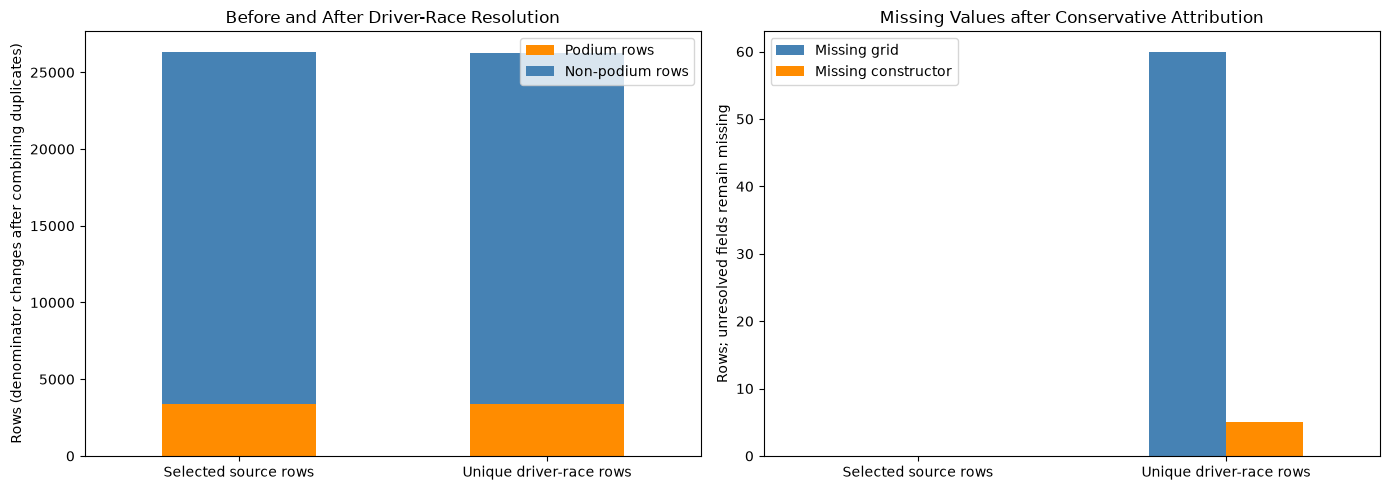

In [148]:
with pd.option_context("display.max_columns", None, "display.max_colwidth", 100):
    print("Duplicate resolution: groups and excess rows are different counts")
    display(duplicate_scope_summary)
    print("Cleaning impact (source-row and driver-race denominators differ)")
    display(step7_impact_summary)
    print("Feature attribution rules applied to duplicate groups")
    display(step7_rule_summary)
    print(f"All {len(duplicate_resolution_audit)} resolved duplicate groups; complete provenance")
    with pd.option_context("display.max_rows", None):
        display(duplicate_resolution_audit[[
            "raceId", "year", "name", "driverId", "surname", "source_result_ids",
            "grid_values", "resolved_grid", "constructorId_values", "resolved_constructorId",
            "best_positionOrder", "podium", "label_evidence_result_ids"
        ]])
    print(f"Attribution review queue: {len(attribution_review_queue)} groups.")
    print("Every original duplicate row, including laps/status/car number, is in duplicate_resolution_source_rows.")
    print("Races with a driver-level positive count other than three (retained)")
    display(step7_races_with_nonstandard_podium_count)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
step7_impact_summary.set_index("Stage")[["Podium rows", "Non-podium rows"]].plot.bar(
    ax=axes[0], stacked=True, color=["darkorange", "steelblue"], rot=0
)
axes[0].set_title("Before and After Driver-Race Resolution")
axes[0].set_ylabel("Rows (denominator changes after combining duplicates)")
axes[0].set_xlabel("")
step7_impact_summary.set_index("Stage")[["Missing grid", "Missing constructor"]].plot.bar(
    ax=axes[1], color=["steelblue", "darkorange"], rot=0
)
axes[1].set_title("Missing Values after Conservative Attribution")
axes[1].set_ylabel("Rows; unresolved fields remain missing")
axes[1].set_xlabel("")
plt.tight_layout()
plt.show()


In [149]:
# Validate grain, coverage, labels, provenance, and field attribution.
resolved = unique_driver_race_candidates
source = modeling_population_candidates
assert not resolved[DRIVER_RACE_KEY].isna().any().any()
assert not resolved.duplicated(DRIVER_RACE_KEY).any()
assert len(resolved) == len(source[DRIVER_RACE_KEY].drop_duplicates())
assert set(map(tuple, resolved[DRIVER_RACE_KEY].to_numpy())) == set(
    map(tuple, source[DRIVER_RACE_KEY].to_numpy())
)
assert set(resolved["raceId"]) == set(source["raceId"])
assert int(driver_race_resolution_audit["source_row_count"].sum()) == len(source)
assert sorted(result_id for ids in driver_race_resolution_audit["source_result_ids"]
              for result_id in ids) == sorted(source["resultId"].tolist())
expected_labels = source.assign(
    podium=source["positionOrder"].le(3).astype("Int64")
).groupby(DRIVER_RACE_KEY)["podium"].max()
pd.testing.assert_series_equal(
    resolved.set_index(DRIVER_RACE_KEY)["podium"], expected_labels
)
single_rows = source.loc[~source.duplicated(DRIVER_RACE_KEY, keep=False)].copy()
single_expected = single_rows[
    [*DRIVER_RACE_KEY, "grid", "constructorId", "positionOrder"]
].rename(columns={"positionOrder": "best_positionOrder"}).set_index(DRIVER_RACE_KEY).sort_index()
single_actual = resolved.set_index(DRIVER_RACE_KEY).loc[
    single_expected.index, ["grid", "constructorId", "best_positionOrder"]
]
pd.testing.assert_frame_equal(single_actual, single_expected)
for field, parent in [("constructorId", "constructors")]:
    assert resolved[field].dropna().isin(clean_data[parent][field]).all()
assert resolved["podium"].isin([0, 1]).all()
assert list(resolved.columns) == [
    *DRIVER_RACE_KEY, "grid", "constructorId", "best_positionOrder", "podium"
]

# Focused adversarial tests: do not use the race outcome or source order to choose features.
step7_fixture = pd.DataFrame([
    # Same driver has two podium records, conflicting grids/constructors.
    [10, 1, 101, 5, 1, 2],
    [11, 1, 101, 8, 2, 3],
    # Equal best finishes; zero grid consensus must remain zero.
    [12, 1, 102, 0, 3, 4],
    [13, 1, 102, 0, 3, 4],
    # One known and one missing grid is incomplete evidence, not agreement.
    [14, 2, 103, 7, 4, 8],
    [15, 2, 103, pd.NA, 4, 9],
    # Zero and positive grid conflict; do not guess the starting-car row.
    [16, 2, 104, 0, 5, 10],
    [17, 2, 104, 6, 5, 1],
    # A singleton is unchanged.
    [18, 2, 105, 2, 6, 5]
], columns=["resultId", "raceId", "driverId", "grid", "constructorId", "positionOrder"]).astype("Int64")
fixture_result, fixture_audit = resolve_driver_race_entries(step7_fixture)
fixture_by_driver = fixture_result.set_index("driverId")
assert len(fixture_result) == 5
assert fixture_by_driver.loc[101, "podium"] == 1
assert pd.isna(fixture_by_driver.loc[101, "grid"])
assert pd.isna(fixture_by_driver.loc[101, "constructorId"])
assert fixture_by_driver.loc[102, "grid"] == 0
assert pd.isna(fixture_by_driver.loc[103, "grid"])
assert pd.isna(fixture_by_driver.loc[104, "grid"])
assert fixture_by_driver.loc[105, "grid"] == 2
assert fixture_audit.set_index("driverId").loc[102, "label_representative_resultId"] == 12
assert fixture_audit.set_index("driverId").loc[102, "label_evidence_result_ids"] == (12, 13)
shuffled_result, shuffled_audit = resolve_driver_race_entries(
    step7_fixture.sample(frac=1, random_state=7)
)
pd.testing.assert_frame_equal(fixture_result, shuffled_result)
pd.testing.assert_frame_equal(fixture_audit, shuffled_audit)
altered_outcomes = step7_fixture.copy(deep=True)
altered_outcomes["positionOrder"] = list(reversed(step7_fixture["positionOrder"].tolist()))
altered_outcomes["laps"] = 999
altered_outcomes["statusId"] = 1
altered_result, _ = resolve_driver_race_entries(altered_outcomes)
pd.testing.assert_frame_equal(
    fixture_result[[*DRIVER_RACE_KEY, "grid", "constructorId"]],
    altered_result[[*DRIVER_RACE_KEY, "grid", "constructorId"]]
)
# Reject an unknown target instead of silently converting it to a negative.
invalid_fixture = step7_fixture.copy(deep=True)
invalid_fixture.loc[0, "positionOrder"] = pd.NA
try:
    resolve_driver_race_entries(invalid_fixture)
except ValueError:
    pass
else:
    raise AssertionError("Missing positionOrder must block label construction.")

# Both population settings must work. This is validation, not a policy change.
all_entries_resolved, _ = resolve_driver_race_entries(clean_data["results"])
assert len(all_entries_resolved) == len(clean_data["results"][DRIVER_RACE_KEY].drop_duplicates())
assert not all_entries_resolved.duplicated(DRIVER_RACE_KEY).any()
assert step7_source_fingerprints() == step7_sources_before, "Source data was mutated."
step7_validation_passed = True
print("PASS: unique keys, exact pair/race coverage, labels, provenance, singleton preservation,")
print("      outcome-independent field rules, order invariance, ties, missingness, both scopes,")
print("      and unchanged raw/clean/candidate source tables.")
print(f"Unique entrant rows: {len(resolved):,}; combined excess rows: {len(source) - len(resolved):,}.")


PASS: unique keys, exact pair/race coverage, labels, provenance, singleton preservation,
      outcome-independent field rules, order invariance, ties, missingness, both scopes,
      and unchanged raw/clean/candidate source tables.
Unique entrant rows: 26,287; combined excess rows: 67.


### Step 7 result and handoff

Use **unique_driver_race_candidates** as the unique entrant base for later joins. Its `best_positionOrder` and `podium` columns are outcomes; keep them out of predictors. It is not a completed feature matrix.

**duplicate_resolution_audit** explains every repeated group; **duplicate_resolution_source_rows** preserves every contributing source record; **attribution_review_queue** lists unresolved grid/constructor assignments. Missing values created by conflicting evidence are intentional. No group is silently removed, and no historical case is declared a confirmed shared drive merely because it repeats.

The target is driver-level podium credit from any recorded result. Do not allocate the aggregated target, points, retirements, or laps to a guessed constructor. Engineering analyses that need car starts or mechanical retirements must use a separately justified grain and denominator.

The executed summaries give the authoritative counts for the current population toggle. Step 8 is next: document missingness and prepare nationality-country and mechanical-status mappings. Historical attribution uncertainty remains explicit; learned imputation belongs after defining the split protocol.


## Missingness and analysis mappings (step 8)

Document missing values after step 7 and prepare lookup tables for the home-country and constructor-reliability questions. The source tables and unique entrant base remain unchanged. No imputation, scaling, or model fitting takes place here.

Distinguish **missing whole records**, **missing fields in existing records**, and **conflicting attribution introduced by step 7**. A null value alone does not prove why it is missing. In particular, absent Q2/Q3 times can reflect session progression, historical formats, incomplete recording, or another cause; do not label every such null as elimination. Schedule nulls likewise do not prove that a session was not held.

All coverage joins are diagnostic. Current-race status, mechanical categories, and retrospective missingness explanations must not become pre-race predictors. The separate mapping policies below are analytical conventions, with ambiguous cases retained for review.


In [150]:
assert step7_validation_passed, "Run and validate step 7 first."
step8_sources_before = step7_source_fingerprints()
step8_unique_before = step7_frame_fingerprint(unique_driver_race_candidates)

def missingness_inventory(tables, stage):
    records = []
    for table_name, table in tables.items():
        for column in table.columns:
            missing = int(table[column].isna().sum())
            records.append({
                "Stage": stage, "Table": table_name, "Column": column,
                "Rows": len(table), "Missing": missing,
                "Available": len(table) - missing,
                "Missing (%)": 100 * missing / len(table) if len(table) else np.nan,
                "Dtype": str(table[column].dtype)
            })
    return pd.DataFrame(records)

step8_missingness_inventory = pd.concat([
    missingness_inventory(clean_data, "Clean source"),
    missingness_inventory({"unique_entrants": unique_driver_race_candidates}, "After step 7")
], ignore_index=True)
step8_missingness_by_table = step8_missingness_inventory.groupby(
    ["Stage", "Table"], sort=False
).agg(Columns=("Column", "size"), Total_cells=("Rows", "sum"),
      Missing_cells=("Missing", "sum")).reset_index()
step8_missingness_by_table["Missing (%)"] = (
    100 * step8_missingness_by_table["Missing_cells"] / step8_missingness_by_table["Total_cells"]
)
step8_unique_missingness = step8_missingness_inventory.loc[
    step8_missingness_inventory["Stage"].eq("After step 7")
].copy()

# Possible explanations are explicitly distinguished from established audit evidence.
step8_missingness_notes = pd.DataFrame([
    ("All source fields", "Sentinels/blanks normalized in step 4", "Observed normalization; remaining nulls are not filled.", "Use the inventory; raw values remain available."),
    ("Unique entrants: grid / constructorId", "Conflicting or incomplete attribution", "Established by the step-7 audit, not a generic missing-data assumption.", "Retain missingness and review source alternatives; assess cutoff safety."),
    ("Qualifying: missing driver-race record", "No matching record in supplied qualifying table", "Established by an entrant-base left join; does not prove the driver skipped qualifying.", "Report record coverage by year before selecting features or scope."),
    ("Qualifying: q1 / q2 / q3", "Session progression, changing format, incomplete recording, or other absence", "Possible explanations only; not individually inferred from nulls.", "Report availability among all entrants and among existing records separately."),
    ("Races: practice / qualifying / sprint schedule", "Historical coverage gaps or sessions not held", "Possible explanations only; absence cannot identify which.", "Report fields by season; do not fabricate session dates or times."),
    ("Results / sprint_results: elapsed and fastest-lap fields", "Outcome-dependent recording and historical coverage", "Possible explanations only; gap text is not elapsed duration.", "Keep out of current-race predictors; missing elapsed time is not zero."),
    ("Drivers: number / code; circuits: altitude", "Incomplete metadata or field not applicable in an era", "Possible explanations only; inspect source/era if used.", "Do not infer missing identifiers or replace altitude with zero."),
    ("Future learned preprocessing", "Imputation and missing indicators require feature/cutoff review", "No learned values are estimated in step 8.", "Fit learned transforms on training data only after the split protocol.")
], columns=["Fields", "Explanation", "Evidence / limitation", "Planned treatment"])
step8_attribution_missingness = driver_race_resolution_audit.groupby(
    ["grid_rule", "constructorId_rule"], dropna=False
).agg(Driver_race_pairs=("driverId", "size")).reset_index()


In [151]:
# Unique entrant denominator: includes drivers with no qualifying row.
qualifying_lookup = clean_data["qualifying"][
    [*DRIVER_RACE_KEY, "qualifyId", "position", "q1", "q2", "q3"]
].rename(columns={"position": "qualifying_position"})

def qualifying_coverage_for_entrants(entrants, qualifying):
    if entrants.duplicated(DRIVER_RACE_KEY).any():
        raise ValueError("Qualifying coverage needs unique entrants.")
    coverage = entrants[DRIVER_RACE_KEY].merge(
        qualifying, on=DRIVER_RACE_KEY, how="left", validate="one_to_one",
        indicator="_qualifying_match"
    )
    coverage["has_qualifying_record"] = coverage["_qualifying_match"].eq("both")
    coverage = coverage.drop(columns="_qualifying_match")
    for field in ["q1", "q2", "q3"]:
        coverage[field + "_available"] = coverage[field].notna()
    coverage["any_session_time_available"] = coverage[["q1", "q2", "q3"]].notna().any(axis=1)
    assert len(coverage) == len(entrants)
    return coverage

qualifying_coverage_audit = qualifying_coverage_for_entrants(
    unique_driver_race_candidates, qualifying_lookup
).merge(
    clean_data["races"][["raceId", "year"]], on="raceId", how="left", validate="many_to_one"
)
qualifying_coverage_by_year = qualifying_coverage_audit.groupby("year").agg(
    Entrants=("driverId", "size"),
    Qualifying_records=("has_qualifying_record", "sum"),
    Q1_available=("q1_available", "sum"), Q2_available=("q2_available", "sum"),
    Q3_available=("q3_available", "sum"),
    Any_session_available=("any_session_time_available", "sum")
).reset_index()
qualifying_coverage_by_year["Missing_whole_records"] = (
    qualifying_coverage_by_year["Entrants"] - qualifying_coverage_by_year["Qualifying_records"]
)
qualifying_coverage_by_year["Record_coverage_pct"] = (
    100 * qualifying_coverage_by_year["Qualifying_records"] / qualifying_coverage_by_year["Entrants"]
)
qualifying_missingness_summary = []
for field in ["q1", "q2", "q3"]:
    present = qualifying_coverage_audit["has_qualifying_record"]
    available = qualifying_coverage_audit[field].notna()
    qualifying_missingness_summary.append({
        "Session": field, "Selected entrants": len(qualifying_coverage_audit),
        "Missing whole records": int((~present).sum()),
        "Existing records": int(present.sum()),
        "Missing field in existing records": int((present & ~available).sum()),
        "Available times": int(available.sum()),
        "Availability among all entrants (%)": 100 * available.mean(),
        "Availability among existing records (%)": (
            100 * available.loc[present].mean() if present.any() else np.nan
        )
    })
qualifying_missingness_summary = pd.DataFrame(qualifying_missingness_summary)
qualifying_missing_record_rows = qualifying_coverage_audit.loc[
    ~qualifying_coverage_audit["has_qualifying_record"]
].copy()
# Qualifying-only rows outside the selected entrant population are reported, not appended.
qualifying_outside_population = qualifying_lookup.merge(
    unique_driver_race_candidates[DRIVER_RACE_KEY], on=DRIVER_RACE_KEY,
    how="left", validate="one_to_one", indicator=True
)
qualifying_outside_population = qualifying_outside_population.loc[
    qualifying_outside_population["_merge"].eq("left_only")
].drop(columns="_merge")

schedule_fields = [
    session + "_" + suffix for session in ["fp1", "fp2", "fp3", "quali", "sprint"]
    for suffix in ["date", "time"]
]
selected_race_schedule = clean_data["races"].loc[
    clean_data["races"]["raceId"].isin(unique_driver_race_candidates["raceId"]),
    ["raceId", "year", *schedule_fields]
].copy()
schedule_missingness_by_year = []
for year, group in selected_race_schedule.groupby("year"):
    for field in schedule_fields:
        schedule_missingness_by_year.append({
            "Year": year, "Field": field, "Selected races": len(group),
            "Missing": int(group[field].isna().sum()),
            "Missing (%)": 100 * group[field].isna().mean()
        })
schedule_missingness_by_year = pd.DataFrame(schedule_missingness_by_year)


### Nationality-country mapping policy

Compare driver nationality with the **country of the circuit**, not the event name, residence, or birthplace. Standardize UK to United Kingdom, USA/United States to United States, UAE to United Arab Emirates, and Korea to South Korea as a dataset convention. Keep the source labels.

For **American-Italian** and **Argentine-Italian**, count either listed country as home; retain the dual-nationality flag for a later sensitivity analysis. Map **East German** to Germany as a geographic harmonization convention, explicitly flagged rather than claiming historically identical national identity. Leave **Rhodesian** unresolved because this label alone does not establish a suitable country assignment. Unknown/unresolved mappings produce a missing home flag, never an automatic away label. `Argentinian` and `Argentine` both map to Argentina after whitespace normalization.

These are documented project choices. They do not settle the engineering question: podium rates and starting-position controls come later.


In [152]:
nationality_country_values = {
    "American": ("United States",), "American-Italian": ("United States", "Italy"),
    "Argentine": ("Argentina",), "Argentine-Italian": ("Argentina", "Italy"),
    "Argentinian": ("Argentina",), "Australian": ("Australia",),
    "Austrian": ("Austria",), "Belgian": ("Belgium",), "Brazilian": ("Brazil",),
    "British": ("United Kingdom",), "Canadian": ("Canada",), "Chilean": ("Chile",),
    "Chinese": ("China",), "Colombian": ("Colombia",), "Czech": ("Czech Republic",),
    "Danish": ("Denmark",), "Dutch": ("Netherlands",), "East German": ("Germany",),
    "Finnish": ("Finland",), "French": ("France",), "German": ("Germany",),
    "Hungarian": ("Hungary",), "Indian": ("India",), "Indonesian": ("Indonesia",),
    "Irish": ("Ireland",), "Italian": ("Italy",), "Japanese": ("Japan",),
    "Liechtensteiner": ("Liechtenstein",), "Malaysian": ("Malaysia",),
    "Mexican": ("Mexico",), "Monegasque": ("Monaco",), "New Zealander": ("New Zealand",),
    "Polish": ("Poland",), "Portuguese": ("Portugal",), "Rhodesian": (),
    "Russian": ("Russia",), "South African": ("South Africa",), "Spanish": ("Spain",),
    "Swedish": ("Sweden",), "Swiss": ("Switzerland",), "Thai": ("Thailand",),
    "Uruguayan": ("Uruguay",), "Venezuelan": ("Venezuela",)
}
nationality_country_mapping = pd.DataFrame([
    {"nationality": label, "home_countries": countries,
     "mapping_basis": (
         "Unresolved historical label" if not countries else
         "Either listed country; dual-nationality convention" if len(countries) > 1 else
         "Historical geographic harmonization" if label == "East German" else
         "Spelling alias" if label == "Argentinian" else "Direct country mapping"
     )}
    for label, countries in nationality_country_values.items()
])
circuit_country_aliases = {
    "UK": "United Kingdom", "USA": "United States", "United States": "United States",
    "UAE": "United Arab Emirates", "Korea": "South Korea"
}
circuit_country_mapping = pd.DataFrame([
    {"country": country, "circuit_country": circuit_country_aliases.get(country, country),
     "mapping_basis": "Explicit alias" if country in circuit_country_aliases else "Unchanged"}
    for country in sorted(clean_data["circuits"]["country"].dropna().unique())
])
unmapped_nationality_rows = clean_data["drivers"].loc[
    ~clean_data["drivers"]["nationality"].isin(nationality_country_mapping["nationality"])
].copy()
assert unmapped_nationality_rows.empty, "Review new or missing nationality labels."
driver_country_lookup = clean_data["drivers"][
    ["driverId", "forename", "surname", "nationality"]
].merge(nationality_country_mapping, on="nationality", how="left", validate="many_to_one")
circuit_country_lookup = clean_data["circuits"][["circuitId", "name", "country"]].rename(
    columns={"name": "circuit_name"}
).merge(circuit_country_mapping[["country", "circuit_country"]],
        on="country", how="left", validate="many_to_one")
unmapped_circuit_country_rows = circuit_country_lookup.loc[
    circuit_country_lookup["circuit_country"].isna()
].copy()
assert unmapped_circuit_country_rows.empty, "Review missing circuit countries."

def classify_home_country(home_countries, circuit_country):
    if not isinstance(home_countries, tuple) or not home_countries or pd.isna(circuit_country):
        return pd.NA
    return circuit_country in home_countries

home_country_audit = unique_driver_race_candidates[DRIVER_RACE_KEY].merge(
    driver_country_lookup, on="driverId", how="left", validate="many_to_one"
).merge(
    clean_data["races"][["raceId", "year", "circuitId"]],
    on="raceId", how="left", validate="many_to_one"
).merge(circuit_country_lookup, on="circuitId", how="left", validate="many_to_one")
home_country_audit["is_home"] = pd.array([
    classify_home_country(countries, country)
    for countries, country in zip(home_country_audit["home_countries"],
                                  home_country_audit["circuit_country"])
], dtype="boolean")
home_country_audit["home_away_label"] = home_country_audit["is_home"].map(
    {True: "Home", False: "Away"}
).fillna("Unresolved")
home_country_summary = home_country_audit.groupby("home_away_label").agg(
    Driver_race_pairs=("driverId", "size"), Distinct_drivers=("driverId", "nunique")
).reset_index()
nationality_mapping_review = driver_country_lookup.loc[
    ~driver_country_lookup["mapping_basis"].isin(["Direct country mapping", "Spelling alias"])
].copy()
home_country_review_rows = home_country_audit.loc[
    home_country_audit["driverId"].isin(nationality_mapping_review["driverId"])
].copy()
home_country_unresolved_rows = home_country_audit.loc[
    home_country_audit["is_home"].isna()
].copy()


### Mechanical-status mapping policy

Classify the **reported status** into `mechanical`, `non_mechanical`, or `uncertain`. Explicit powertrain, electrical, cooling, steering, suspension, and related system faults count as reported mechanical failures; generic "Mechanical"/"Technical" labels are included with a separate rationale. This is a status-based taxonomy, not independent proof of the root cause.

Finished/lapped classifications, crashes/collisions, driver-health causes, regulatory decisions, qualifying failures, withdrawals, and explicitly refuelling-operation statuses do not enter the mechanical numerator. Tyre/puncture/wheel/wing/bodywork labels, unspecified retirement, fuel exhaustion, stalling, fire, and other ambiguous causes remain uncertain: the label may not distinguish component failure from contact, operations, or another cause. Unknown future labels also remain uncertain and trigger review.

`is_mechanical` is a nullable boolean: uncertain cases stay **missing**, not False. The era summary reports source-row counts for 2014-2021 and 2022-2024. It does **not** calculate retirement rates: the engineering question still requires a justified race-start denominator, event-car grain where necessary, and review of ambiguous causes. Zero completed laps alone does not prove a non-start. Current-race statuses and classifications are retrospective analysis fields only.


In [153]:
mechanical_status_groups = [
    ("mechanical", "Reported component/system fault",
     "Explicit component/system fault label; classified by reported cause, not independently verified root cause.",
     "Engine|Gearbox|Transmission|Clutch|Hydraulics|Electrical|Radiator|Suspension|Brakes|Differential|Overheating|Driveshaft|Fuel pressure|Water pressure|Throttle|Steering|Electronics|Heat shield fire|Exhaust|Oil leak|Water leak|Fuel pump|Track rod|Oil pressure|Engine fire|Engine misfire|Pneumatics|Wheel bearing|Fuel system|Oil line|Launch control|Drivetrain|Ignition|Battery|Halfshaft|Crankshaft|Alternator|Oil pump|Fuel leak|Injection|Distributor|Turbo|CV joint|Water pump|Spark plugs|Fuel pipe|Oil pipe|Axle|Water pipe|Magneto|Supercharger|Power Unit|ERS|Cooling system"),
    ("mechanical", "Reported generic technical fault",
     "Reported technical/mechanical cause, but no component specified.", "Mechanical|Technical"),
    ("non_mechanical", "Crash/contact/driving incident",
     "Explicit accident, collision, spin, or debris label; excluded from mechanical failures.",
     "Accident|Collision|Spun off|Fatal accident|Collision damage|Debris"),
    ("non_mechanical", "Driver health",
     "Reported driver health/physical cause; excluded from mechanical failures.",
     "Physical|Injured|Injury|Driver unwell|Eye injury|Illness"),
    ("non_mechanical", "Regulatory",
     "Regulatory or classification decision; excluded from mechanical failures.",
     "Disqualified|107% Rule|Underweight|Excluded"),
    ("non_mechanical", "Withdrawal/qualifying failure",
     "Not a reported mechanical cause; participation/start status needs separate review.",
     "Withdrew|Did not qualify|Did not prequalify"),
    ("non_mechanical", "Refuelling operation",
     "Pit/refuelling operation rather than reported on-car mechanical failure; excluded by policy.",
     "Refuelling|Fuel rig"),
    ("uncertain", "Tyre/wheel/bodywork/safety equipment",
     "Label does not distinguish intrinsic failure, contact damage, wear, or operational cause.",
     "Tyre|Driver Seat|Puncture|Front wing|Wheel|Broken wing|Wheel rim|Tyre puncture|Wheel nut|Rear wing|Chassis|Safety belt|Brake duct|Seat|Undertray"),
    ("uncertain", "Unspecified cause or symptom",
     "Insufficient causal evidence; do not automatically count as mechanical or non-mechanical.",
     "Retired|Not classified|Handling|Fire|Fuel|Power loss|Vibrations|Safety|Stalled|Safety concerns|Not restarted|Damage|Out of fuel")
]
status_policy_by_label = {}
for category, group, rationale, labels in mechanical_status_groups:
    for label in labels.split("|"):
        assert label not in status_policy_by_label, f"Duplicate status rule: {label}"
        status_policy_by_label[label] = (category, group, rationale)

def classify_mechanical_status(label):
    if pd.isna(label):
        return ("uncertain", "Unmapped status", "Missing status label requires review.", False)
    if label == "Finished" or pd.Series([label], dtype="string").str.fullmatch(
        r"\+\d+ Laps?", na=False
    ).iloc[0]:
        return ("non_mechanical", "Finished/lapped classification",
                "Classification reports a finish/lap deficit, not a mechanical cause.", True)
    if label in status_policy_by_label:
        return (*status_policy_by_label[label], True)
    return ("uncertain", "Unmapped status", "New status label requires explicit review.", False)

mechanical_status_mapping = clean_data["status"][["statusId", "status"]].copy()
classified_statuses = pd.DataFrame([
    classify_mechanical_status(label) for label in mechanical_status_mapping["status"]
], columns=["mechanical_class", "cause_group", "classification_rationale", "rule_covered"],
   index=mechanical_status_mapping.index)
mechanical_status_mapping = pd.concat([mechanical_status_mapping, classified_statuses], axis=1)
mechanical_status_mapping["is_mechanical"] = pd.array(
    mechanical_status_mapping["mechanical_class"].map(
        {"mechanical": True, "non_mechanical": False}
    ), dtype="boolean"
)
unmapped_status_rows = mechanical_status_mapping.loc[
    ~mechanical_status_mapping["rule_covered"]
].copy()
assert unmapped_status_rows.empty, "Review new status labels before proceeding."
uncertain_mechanical_statuses = mechanical_status_mapping.loc[
    mechanical_status_mapping["mechanical_class"].eq("uncertain")
].copy()

# Keep constructor/status evidence at original result-row grain for later Q3 work.
results_status_audit = clean_data["results"][
    ["resultId", *DRIVER_RACE_KEY, "constructorId", "statusId", "positionText", "laps"]
].merge(
    mechanical_status_mapping, on="statusId", how="left", validate="many_to_one"
).merge(
    clean_data["races"][["raceId", "year"]], on="raceId", how="left", validate="many_to_one"
)
results_status_audit["analysis_era"] = np.select(
    [results_status_audit["year"].between(2014, 2021),
     results_status_audit["year"].between(2022, 2024)],
    ["2014-2021", "2022-2024"], default="Outside Q3 eras"
)
mechanical_status_summary = results_status_audit.groupby(
    ["mechanical_class", "cause_group"], dropna=False
).agg(Source_result_rows=("resultId", "size"), Distinct_statuses=("statusId", "nunique")).reset_index()
mechanical_status_era_summary = pd.crosstab(
    results_status_audit.loc[results_status_audit["analysis_era"].ne("Outside Q3 eras"), "analysis_era"],
    results_status_audit["mechanical_class"]
).reindex(index=["2014-2021", "2022-2024"],
          columns=["mechanical", "non_mechanical", "uncertain"], fill_value=0)
mechanical_status_review_rows = results_status_audit.loc[
    results_status_audit["mechanical_class"].eq("uncertain")
].copy()
mechanical_status_review_by_label = mechanical_status_review_rows.groupby(
    ["statusId", "status", "analysis_era"], dropna=False
).size().rename("Source_result_rows").reset_index()


Missingness across all 14 cleaned source tables


,Stage,Table,Columns,Total_cells,Missing_cells,Missing (%)
0,Clean source,circuits,9,693,0,0.000000
1,Clean source,constructor_results,5,63125,12608,19.973069
2,Clean source,constructor_standings,7,93737,0,0.000000
3,Clean source,constructors,5,1060,0,0.000000
4,Clean source,driver_standings,7,244041,0,0.000000
5,Clean source,drivers,9,7749,1559,20.118725
6,Clean source,lap_times,6,3534486,0,0.000000
7,Clean source,pit_stops,7,79597,0,0.000000
8,Clean source,qualifying,9,94446,11668,12.354149
9,Clean source,races,18,20250,11349,56.044444


All fields of the unique entrant base after step 7


,Stage,Table,Column,Rows,Missing,Available,Missing (%),Dtype
120,After step 7,unique_entrants,raceId,26287,0,26287,0.000000,Int64
121,After step 7,unique_entrants,driverId,26287,0,26287,0.000000,Int64
122,After step 7,unique_entrants,grid,26287,60,26227,0.228250,Int64
123,After step 7,unique_entrants,constructorId,26287,5,26282,0.019021,Int64
124,After step 7,unique_entrants,best_positionOrder,26287,0,26287,0.000000,Int64
125,After step 7,unique_entrants,podium,26287,0,26287,0.000000,Int64


Largest source-field missingness proportions (first 15; full inventory retained)


...

,mechanical_class,cause_group,Source_result_rows,Distinct_statuses
0,mechanical,Reported component/system fault,6218,54
1,mechanical,Reported generic technical fault,34,2
2,non_mechanical,Crash/contact/driving incident,2775,6
3,non_mechanical,Driver health,65,6
4,non_mechanical,Finished/lapped classification,15161,32
5,non_mechanical,Refuelling operation,3,2
6,non_mechanical,Regulatory,165,4
7,non_mechanical,Withdrawal/qualifying failure,1604,3
8,uncertain,Tyre/wheel/bodywork/safety equipment,260,15
9,uncertain,Unspecified cause or symptom,474,13


Q3-era source-row counts; start denominators are not yet established


mechanical_class,mechanical,non_mechanical,uncertain
analysis_era,,,
2014-2021,287,2896,84
2022-2024,74,1264,21


Uncertain causes within the Q3 eras


,statusId,status,analysis_era,Source_result_rows
0,27,Tyre,2014-2021,4
3,29,Puncture,2014-2021,7
5,31,Retired,2014-2021,38
6,31,Retired,2022-2024,12
8,33,Front wing,2014-2021,2
9,33,Front wing,2022-2024,1
11,36,Wheel,2014-2021,11
16,60,Out of fuel,2014-2021,1
18,61,Wheel nut,2014-2021,3
22,65,Rear wing,2014-2021,2


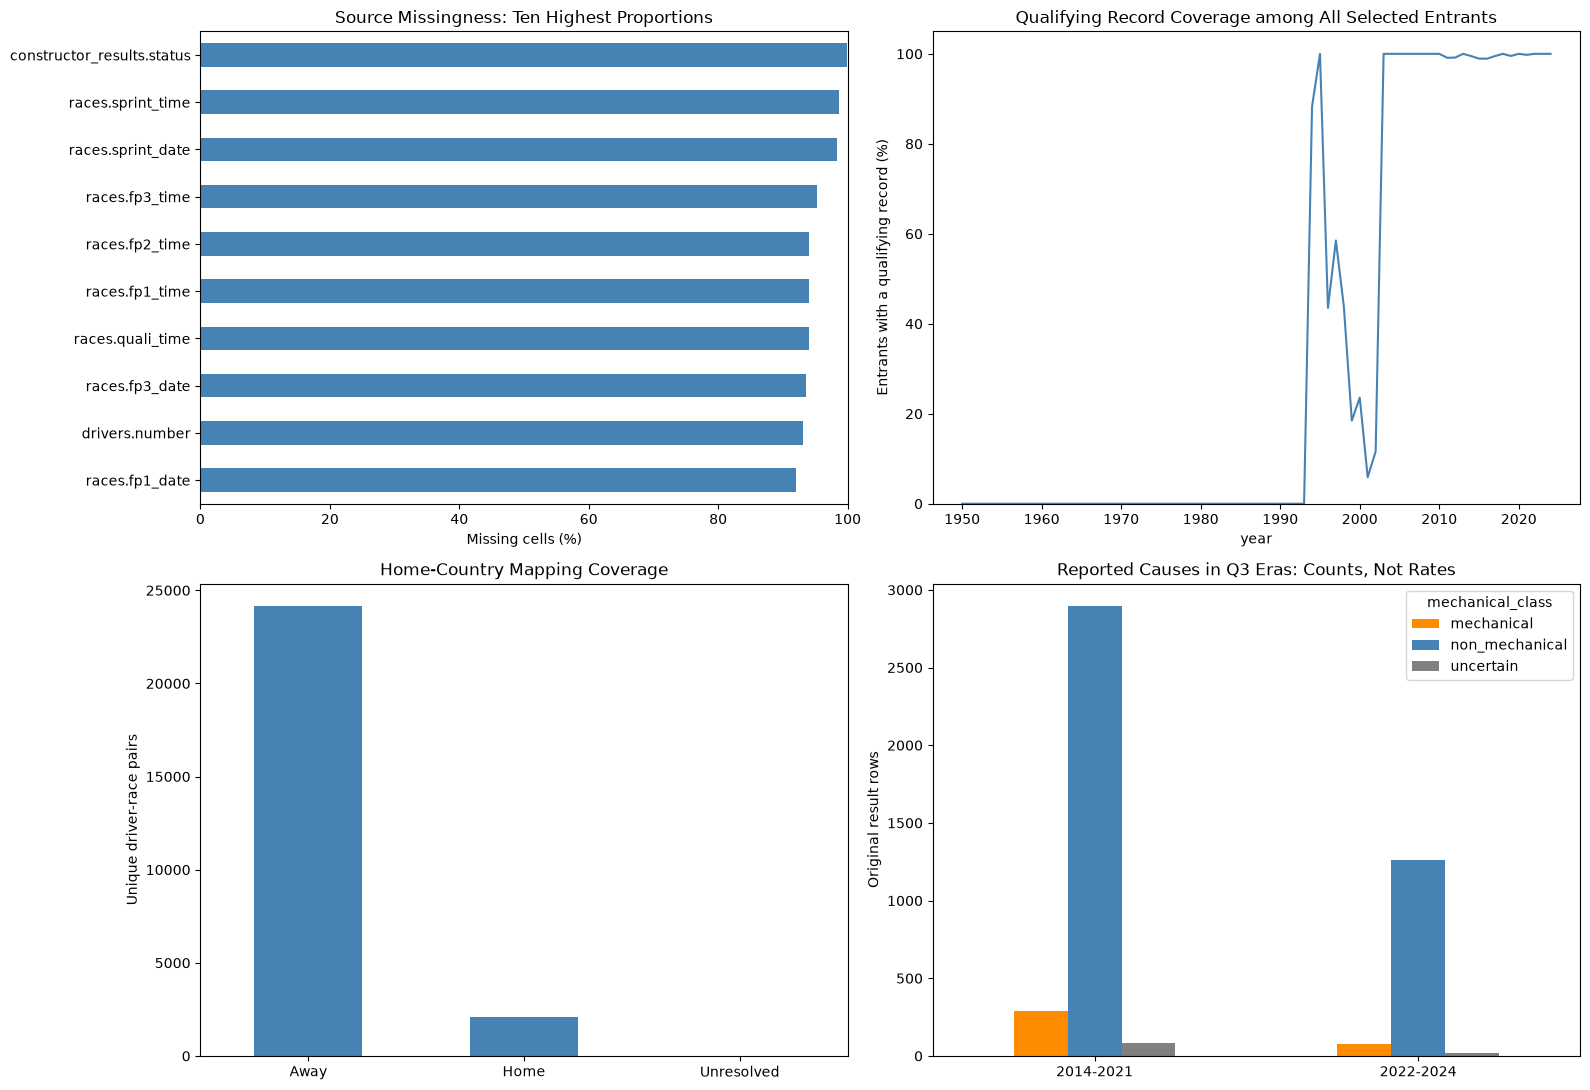

In [154]:
with pd.option_context("display.max_columns", None, "display.max_colwidth", 85):
    print("Missingness across all 14 cleaned source tables")
    display(step8_missingness_by_table)
    print("All fields of the unique entrant base after step 7")
    display(step8_unique_missingness)
    print("Largest source-field missingness proportions (first 15; full inventory retained)")
    display(step8_missingness_inventory.loc[
        step8_missingness_inventory["Stage"].eq("Clean source")
    ].sort_values("Missing (%)", ascending=False).head(15))
    print("Qualifying: whole-record absence versus missing session fields")
    display(qualifying_missingness_summary)
    print(f"Qualifying records outside selected entrants: {len(qualifying_outside_population)}")
    print("Qualifying coverage by season (first and last 8; full series used in plot)")
    display(pd.concat([qualifying_coverage_by_year.head(8), qualifying_coverage_by_year.tail(8)]))
    print("Nationality mapping exceptions requiring a documented convention/review")
    display(nationality_mapping_review)
    print("Home/away counts under the stated mapping conventions")
    display(home_country_summary)
    print("Reported status categories: all original result rows (not retirement rates)")
    display(mechanical_status_summary)
    print("Q3-era source-row counts; start denominators are not yet established")
    display(mechanical_status_era_summary)
    print("Uncertain causes within the Q3 eras")
    display(mechanical_status_review_by_label.loc[
        mechanical_status_review_by_label["analysis_era"].ne("Outside Q3 eras")
    ])

fig, axes = plt.subplots(2, 2, figsize=(16, 11))
source_missing = step8_missingness_inventory.loc[
    step8_missingness_inventory["Stage"].eq("Clean source")
].nlargest(10, "Missing (%)").copy()
source_missing["Field"] = source_missing["Table"] + "." + source_missing["Column"]
source_missing.set_index("Field")["Missing (%)"].sort_values().plot.barh(
    ax=axes[0, 0], color="steelblue"
)
axes[0, 0].set_title("Source Missingness: Ten Highest Proportions")
axes[0, 0].set_xlabel("Missing cells (%)"); axes[0, 0].set_ylabel("")
axes[0, 0].set_xlim(0, 100)
qualifying_coverage_by_year.plot(
    x="year", y="Record_coverage_pct", ax=axes[0, 1], legend=False, color="steelblue"
)
axes[0, 1].set_title("Qualifying Record Coverage among All Selected Entrants")
axes[0, 1].set_ylabel("Entrants with a qualifying record (%)")
axes[0, 1].set_ylim(0, 105)
home_country_summary.set_index("home_away_label")["Driver_race_pairs"].plot.bar(
    ax=axes[1, 0], color="steelblue", rot=0
)
axes[1, 0].set_title("Home-Country Mapping Coverage")
axes[1, 0].set_ylabel("Unique driver-race pairs"); axes[1, 0].set_xlabel("")
mechanical_status_era_summary.plot.bar(
    ax=axes[1, 1], color=["darkorange", "steelblue", "gray"], rot=0
)
axes[1, 1].set_title("Reported Causes in Q3 Eras: Counts, Not Rates")
axes[1, 1].set_ylabel("Original result rows"); axes[1, 1].set_xlabel("")
plt.tight_layout()
plt.show()


In [155]:
# Coverage, nullable semantics, source preservation, and adversarial edge checks.
assert len(step8_missingness_inventory) == sum(len(t.columns) for t in clean_data.values()) + 6
assert (step8_missingness_inventory["Missing"] + step8_missingness_inventory["Available"]).eq(
    step8_missingness_inventory["Rows"]
).all()
assert qualifying_coverage_by_year["Entrants"].sum() == len(unique_driver_race_candidates)
assert not qualifying_coverage_audit.duplicated(DRIVER_RACE_KEY).any()
assert qualifying_missingness_summary["Missing whole records"].add(
    qualifying_missingness_summary["Existing records"]
).eq(len(unique_driver_race_candidates)).all()
assert qualifying_missingness_summary["Missing field in existing records"].add(
    qualifying_missingness_summary["Available times"]
).eq(qualifying_missingness_summary["Existing records"]).all()
assert set(nationality_country_mapping["nationality"]) >= set(
    clean_data["drivers"]["nationality"].dropna()
)
assert nationality_country_mapping["nationality"].is_unique
assert circuit_country_mapping["country"].is_unique
assert len(home_country_audit) == len(unique_driver_race_candidates)
assert not home_country_audit.duplicated(DRIVER_RACE_KEY).any()
assert home_country_summary["Driver_race_pairs"].sum() == len(unique_driver_race_candidates)
assert home_country_audit.loc[
    home_country_audit["home_countries"].map(len).eq(0), "is_home"
].isna().all()
assert classify_home_country(("United Kingdom",), circuit_country_aliases["UK"]) is True
assert classify_home_country(("United States",), circuit_country_aliases["USA"]) is True
assert classify_home_country(("United States", "Italy"), "Italy") is True
assert classify_home_country(("United States", "Italy"), "France") is False
assert pd.isna(classify_home_country((), "South Africa"))
assert pd.isna(classify_home_country(("Italy",), pd.NA))
assert normalized_text(pd.Series(["Argentinian "])).iloc[0] in nationality_country_values

assert len(mechanical_status_mapping) == len(clean_data["status"])
assert mechanical_status_mapping["statusId"].is_unique
assert mechanical_status_mapping["is_mechanical"].isna().equals(
    mechanical_status_mapping["mechanical_class"].eq("uncertain")
)
assert len(results_status_audit) == len(clean_data["results"])
assert results_status_audit["resultId"].tolist() == clean_data["results"]["resultId"].tolist()
assert results_status_audit["mechanical_class"].notna().all()
assert mechanical_status_summary["Source_result_rows"].sum() == len(clean_data["results"])
assert int(mechanical_status_era_summary.to_numpy().sum()) == int(
    clean_data["results"]["raceId"].isin(
        clean_data["races"].loc[clean_data["races"]["year"].between(2014, 2024), "raceId"]
    ).sum()
)
for label in ["Engine", "Gearbox", "ERS", "Cooling system"]:
    assert classify_mechanical_status(label)[0] == "mechanical"
for label in ["Accident", "Collision damage", "Disqualified", "Driver unwell", "Did not qualify"]:
    assert classify_mechanical_status(label)[0] == "non_mechanical"
for label in ["Retired", "Puncture", "Damage", "Out of fuel", "Stalled"]:
    assert classify_mechanical_status(label)[0] == "uncertain"
assert classify_mechanical_status("+1 Lap")[0] == "non_mechanical"
assert classify_mechanical_status("+49 Laps")[0] == "non_mechanical"
assert classify_mechanical_status("New unknown cause")[0] == "uncertain"
assert classify_mechanical_status("New unknown cause")[3] is False
assert classify_mechanical_status(pd.NA)[0] == "uncertain"

# Whole-record absence must remain in the denominator; Q2/Q3 absence is separate.
coverage_fixture = qualifying_coverage_for_entrants(
    pd.DataFrame({"raceId": [1, 1, 2], "driverId": [11, 12, 13]}),
    pd.DataFrame({"raceId": [1], "driverId": [11], "qualifyId": [1],
                  "qualifying_position": [1], "q1": [70.0], "q2": [np.nan], "q3": [np.nan]})
)
assert len(coverage_fixture) == 3
assert coverage_fixture["has_qualifying_record"].sum() == 1
assert coverage_fixture["q1_available"].sum() == 1
assert coverage_fixture["q2_available"].sum() == 0
assert step7_source_fingerprints() == step8_sources_before
assert step7_frame_fingerprint(unique_driver_race_candidates) == step8_unique_before
step8_validation_passed = True
print("PASS: missingness denominators, absent qualifying records, mapping coverage,")
print("      home/away unknowns, mechanical uncertainty, diagnostic join grains,")
print("      era counts, and unchanged source tables / unique entrant base.")
print(f"Nationality labels mapped/documented: {len(nationality_country_mapping)}.")
print(f"Unresolved home-country entrant rows: {len(home_country_unresolved_rows)}.")
print(f"Status labels covered: {len(mechanical_status_mapping)}; uncertain labels: {len(uncertain_mechanical_statuses)}.")


PASS: missingness denominators, absent qualifying records, mapping coverage,
      home/away unknowns, mechanical uncertainty, diagnostic join grains,
      era counts, and unchanged source tables / unique entrant base.
Nationality labels mapped/documented: 43.
Unresolved home-country entrant rows: 18.
Status labels covered: 139; uncertain labels: 28.


### Step 8 result and handoff

**Missingness:** `step8_missingness_inventory` covers every cleaned source field and the unique entrant base. `step8_missingness_notes` distinguishes observed evidence from possible causes. Qualifying summaries retain all selected entrants in their denominator; Q1/Q2/Q3 availability among existing records is a separate measure. `schedule_missingness_by_year` preserves field-level season coverage.

**Geography:** `nationality_country_mapping` and `circuit_country_mapping` document conventions. `home_country_audit` supplies a nullable home flag at unique driver-race grain. Historical/dual-nationality review rows are available for later sensitivity checks; unresolved rows must not silently become away.

**Mechanical causes:** `mechanical_status_mapping` is an explicit, reviewable status taxonomy. `results_status_audit` and `mechanical_status_review_rows` retain original result-grain evidence. Uncertain causes are not forced into either class. Later Q3 work must establish the race-start denominator and report sensitivity to uncertain causes.

Step 9 remains: plausibility checks and a consolidated before/after cleaning report. Feature assembly, learned imputation, engineering-question rates/controls, and final cutoff checks are later work. No source table or unique entrant base is modified here.


## Plausibility and final cleaning impact (step 9)

Check cleaned source values, cross-field consistency, current keys/references, and the unique entrant contract. Preserve questionable records in review tables. No source corrections, imputation, or additional population exclusions are applied in this step.

**ERROR** checks cover explicit data constraints: nonnegative counts/durations, positive IDs/positions, valid geographic coordinates, and birth dates preceding participation. **REVIEW** checks identify unusual values or disagreements that require interpretation. Screening thresholds are project heuristics, not F1 regulations: lap time > 600 seconds, pit duration > 180 seconds, race elapsed > 6 hours, and driver age outside 15-65 years. Long durations may include interruptions. Grid zero, fractional points, negative altitude, and positions above 20 remain allowed; negative points receive review because penalties may be legitimate.

Compare paired time representations within one millisecond. Compare elapsed time against laps multiplied by the reported fastest-lap duration with a one-second tolerance, as a diagnostic only. Non-start-like labels with completed laps and historical duplicate attribution remain review issues from earlier steps.

The final gate certifies the declared structural checks, not every historical value or predictor's availability at the prediction cutoff. Review queues remain relevant to any downstream use of the affected fields.


In [156]:
assert step8_validation_passed, "Run step 8 first."
step9_sources_before = step7_source_fingerprints()
step9_unique_before = step7_frame_fingerprint(unique_driver_race_candidates)
step9_csv_manifest = pd.DataFrame([
    {"File": str(path), "Bytes": path.stat().st_size,
     "SHA256": hashlib.sha256(path.read_bytes()).hexdigest()}
    for path in [dataset_path / name for name in REQUIRED_CSV_FILES]
])
plausibility_records = []
plausibility_review_rows = {}

def record_plausibility_check(rule, table_name, frame, failed, evaluable, fields,
                              severity="REVIEW", rationale=""):
    failed = pd.Series(failed, index=frame.index).fillna(False).astype(bool)
    evaluable = pd.Series(evaluable, index=frame.index).fillna(False).astype(bool)
    failed = failed & evaluable
    assert rule not in {row["Rule"] for row in plausibility_records}, "Rule names must be unique."
    plausibility_records.append({
        "Rule": rule, "Table": table_name, "Severity": severity,
        "Rows": len(frame), "Evaluated": int(evaluable.sum()),
        "Not evaluated": int((~evaluable).sum()), "Flagged": int(failed.sum()),
        "Result": "PASS" if not failed.any() else severity,
        "Rationale / action": rationale
    })
    if failed.any():
        key_fields = [c for c in ["resultId", "raceId", "driverId", "constructorId",
                                  "circuitId", "year", "date", "name"] if c in frame.columns]
        columns = list(dict.fromkeys(key_fields + fields))
        details = frame.loc[failed, columns].copy()
        details.insert(0, "source_row_index", details.index)
        plausibility_review_rows[rule] = details

def numeric_domain_failure(values, minimum=None, maximum=None):
    failed = ~np.isfinite(values)
    if minimum is not None:
        failed = failed | values.lt(minimum)
    if maximum is not None:
        failed = failed | values.gt(maximum)
    return failed.fillna(False) & values.notna()

# All numeric semantic fields are checked for finiteness and appropriate domains.
nonnegative_counts = {"grid", "number", "laps", "wins", "rank"}
positive_ordinals = {"position", "positionOrder", "round", "lap", "stop", "fastestLap"}
for record in semantic_schema_df.to_dict("records"):
    table_name, column, kind = record["Table"], record["Column"], record["Semantic Type"]
    if kind not in {"integer", "number", "milliseconds", "duration_seconds"}:
        continue
    frame = clean_data[table_name]
    values = frame[column]
    lower, upper = None, None
    if column.endswith("Id") or column in positive_ordinals or column == "year":
        lower = 1
    elif column in nonnegative_counts or kind in {"milliseconds", "duration_seconds"}:
        lower = 0
    elif column == "lat":
        lower, upper = -90, 90
    elif column == "lng":
        lower, upper = -180, 180
    elif column == "fastestLapSpeed":
        lower = 0
    record_plausibility_check(
        f"domain:{table_name}.{column}", table_name, frame,
        numeric_domain_failure(values, lower, upper), values.notna(), [column], "ERROR",
        f"Finite available values; allowed minimum={lower}, maximum={upper}. Missingness is audited separately."
    )
    if kind in {"milliseconds", "duration_seconds"}:
        record_plausibility_check(
            f"zero_duration:{table_name}.{column}", table_name, frame,
            values.eq(0), values.notna(), [column], rationale="A recorded zero duration requires source review; missing is not zero."
        )
    if column == "points":
        record_plausibility_check(
            f"negative_points:{table_name}", table_name, frame,
            values.lt(0), values.notna(), [column], rationale="May reflect a penalty; do not automatically remove or clip."
        )

for table_name, seconds_field in [("lap_times", "time"), ("pit_stops", "duration")]:
    frame = clean_data[table_name]
    comparable = frame[[seconds_field, "milliseconds"]].notna().all(axis=1)
    record_plausibility_check(
        f"duration_units:{table_name}", table_name, frame,
        (frame[seconds_field] * 1000 - frame["milliseconds"]).abs().gt(1),
        comparable, [seconds_field, "milliseconds"],
        rationale="Paired seconds and milliseconds should agree within 1 ms; investigate disagreements."
    )
for table_name, field, threshold in [
    ("lap_times", "time", 600), ("pit_stops", "duration", 180),
    ("results", "milliseconds", 6 * 3600 * 1000),
    ("sprint_results", "milliseconds", 6 * 3600 * 1000)
]:
    frame = clean_data[table_name]
    record_plausibility_check(
        f"long_duration:{table_name}", table_name, frame,
        frame[field].gt(threshold), frame[field].notna(), [field],
        rationale=f"Screening threshold {threshold} in the field's units; interruptions may explain long durations."
    )


In [157]:
race_dates = clean_data["races"]
record_plausibility_check(
    "race_year_vs_date", "races", race_dates,
    race_dates["year"].ne(race_dates["date"].dt.year),
    race_dates[["year", "date"]].notna().all(axis=1), ["year", "date"],
    rationale="Calendar date and declared season differ; verify rather than assuming a repair."
)
record_plausibility_check(
    "duplicate_season_round", "races", race_dates,
    race_dates.duplicated(["year", "round"], keep=False),
    race_dates[["year", "round"]].notna().all(axis=1), ["year", "round"],
    rationale="Repeated season-round values need chronology review."
)
chronology = race_dates.sort_values(["year", "round", "raceId"]).copy()
chronology["previous_round_date"] = chronology.groupby("year")["date"].shift()
record_plausibility_check(
    "round_date_order", "races", chronology,
    chronology["date"].lt(chronology["previous_round_date"]),
    chronology[["date", "previous_round_date"]].notna().all(axis=1),
    ["round", "date", "previous_round_date"],
    rationale="Round chronology runs backwards; never substitute numeric raceId order."
)
for session in ["fp1", "fp2", "fp3", "quali", "sprint"]:
    column = session + "_date"
    comparable = race_dates[[column, "date"]].notna().all(axis=1)
    record_plausibility_check(
        f"session_after_race:{session}", "races", race_dates,
        race_dates[column].gt(race_dates["date"]), comparable, [column, "date"],
        rationale="Session date follows its main race date; verify schedule metadata."
    )

dated_results = clean_data["results"].merge(
    race_dates[["raceId", "year", "date", "name"]], on="raceId", how="left", validate="many_to_one"
).merge(
    clean_data["drivers"][["driverId", "dob", "surname"]],
    on="driverId", how="left", validate="many_to_one"
)
dated_results["age_years"] = (dated_results["date"] - dated_results["dob"]).dt.days / 365.2425
record_plausibility_check(
    "birth_after_participation", "results/drivers/races", dated_results,
    dated_results["dob"].gt(dated_results["date"]),
    dated_results[["dob", "date"]].notna().all(axis=1), ["dob", "age_years", "surname"], "ERROR",
    "Birth cannot follow recorded participation; investigate the linked evidence."
)
record_plausibility_check(
    "driver_age_screen", "results/drivers/races", dated_results,
    ~dated_results["age_years"].between(15, 65), dated_results["age_years"].notna(),
    ["dob", "age_years", "surname"],
    rationale="15-65 years is a broad diagnostic range, not an eligibility rule."
)

def elapsed_below_fastest_lap_bound(frame):
    return frame["milliseconds"].div(1000).lt(
        frame["laps"] * frame["fastestLapTime"] - 1
    )

for table_name in ["results", "sprint_results"]:
    frame = clean_data[table_name]
    record_plausibility_check(
        f"fastest_lap_beyond_completed:{table_name}", table_name, frame,
        frame["fastestLap"].gt(frame["laps"]),
        frame[["fastestLap", "laps"]].notna().all(axis=1),
        ["laps", "fastestLap", "fastestLapTime", "statusId"],
        rationale="Reported fastest-lap index exceeds completed laps; inspect timing/classification conventions."
    )
    comparable = frame[["milliseconds", "laps", "fastestLapTime"]].notna().all(axis=1) & frame["laps"].gt(0)
    record_plausibility_check(
        f"elapsed_below_lap_bound:{table_name}", table_name, frame,
        elapsed_below_fastest_lap_bound(frame), comparable,
        ["laps", "time", "milliseconds", "fastestLapTime", "statusId"],
        rationale="Elapsed seconds are below laps times fastest-lap seconds (1 s tolerance); elapsed/gap interpretation may be inconsistent."
    )
    absolute_text = frame["time"].astype("string").str.fullmatch(
        r"\d+(?::[0-5]\d){0,2}(?:\.\d+)?", na=False
    )
    parsed_absolute = duration_to_seconds(frame["time"].where(absolute_text))
    record_plausibility_check(
        f"absolute_result_time_units:{table_name}", table_name, frame,
        (parsed_absolute * 1000 - frame["milliseconds"]).abs().gt(1),
        absolute_text & parsed_absolute.notna() & frame["milliseconds"].notna(),
        ["time", "milliseconds"],
        rationale="Only absolute elapsed text is compared; +gap strings are deliberately excluded."
    )
    record_plausibility_check(
        f"position_vs_order:{table_name}", table_name, frame,
        frame["position"].ne(frame["positionOrder"]),
        frame[["position", "positionOrder"]].notna().all(axis=1),
        ["position", "positionOrder", "positionText", "statusId"],
        rationale="Different classification fields need interpretation; target remains positionOrder <= 3."
    )

# Pair reconciliation supplements the single-column foreign keys from step 5.
result_pair_limits = clean_data["results"].groupby(DRIVER_RACE_KEY).agg(
    max_recorded_laps=("laps", "max")
).reset_index()
for table_name in ["lap_times", "pit_stops", "qualifying", "sprint_results"]:
    frame = clean_data[table_name].merge(
        result_pair_limits, on=DRIVER_RACE_KEY, how="left", validate="many_to_one", indicator=True
    )
    record_plausibility_check(
        f"pair_without_main_result:{table_name}", table_name, frame,
        frame["_merge"].eq("left_only"), pd.Series(True, index=frame.index),
        ["_merge"], rationale="No main-result driver-race pair; could reflect participation differences or missing records."
    )
    if "lap" in frame:
        record_plausibility_check(
            f"lap_beyond_result:{table_name}", table_name, frame,
            frame["lap"].gt(frame["max_recorded_laps"]),
            frame[["lap", "max_recorded_laps"]].notna().all(axis=1),
            ["lap", "max_recorded_laps"],
            rationale="Timing lap exceeds maximum source completed laps; final/aborted-lap conventions need review."
        )

pit_sequence_audit = clean_data["pit_stops"].groupby(DRIVER_RACE_KEY).agg(
    recorded_stops=("stop", "size"), first_stop=("stop", "min"), last_stop=("stop", "max")
).reset_index()
record_plausibility_check(
    "pit_stop_sequence_gaps", "pit_stops (driver-race groups)", pit_sequence_audit,
    pit_sequence_audit["first_stop"].ne(1) | pit_sequence_audit["last_stop"].ne(pit_sequence_audit["recorded_stops"]),
    pd.Series(True, index=pit_sequence_audit.index),
    ["recorded_stops", "first_stop", "last_stop"],
    rationale="Ordinals do not form 1..N; may be missing stops or misassigned fields. No automatic renumbering."
)
plausibility_audit = pd.DataFrame(plausibility_records)
plausibility_flags = plausibility_audit.loc[plausibility_audit["Flagged"].gt(0)].copy()


In [158]:
# Recompute the structural contract from current objects instead of trusting old booleans.
final_primary_key_audit = pd.DataFrame([
    audit_declared_key(clean_data[name], name, keys, "Final cleaned source primary key")
    for name, (_, keys) in table_key_spec.items()
])
(final_foreign_key_audit, final_unmatched_fk_values,
 final_fk_issue_details, final_fk_issue_rows) = audit_foreign_keys(
    clean_data, foreign_key_spec, table_key_spec
)
final_raw_missing_profile = create_missing_profile(raw_data, "Raw")
final_clean_missing_profile = create_missing_profile(clean_data, "Typed")
cleaning_normalization_summary = pd.DataFrame([
    {"Stage": stage, "Rows across all source tables": sum(len(t) for t in tables.values()),
     "Cells": sum(t.size for t in tables.values()),
     "Literal sentinels": int(profile["Sentinel Values"].sum()),
     "Blank strings": int(profile["Empty Strings"].sum()),
     "True missing cells": int(profile["NaN"].sum()),
     "Total unavailable cells": int(profile["Total Unavailable"].sum())}
    for stage, tables, profile in [
        ("Raw sources", raw_data, final_raw_missing_profile),
        ("Normalized and typed sources", clean_data, final_clean_missing_profile)
    ]
])
def cleaning_population_counts(frame, target_column):
    target = pd.to_numeric(frame[target_column], errors="raise")
    positive = target.eq(1) if target_column == "podium" else target.le(3)
    return {
        "Rows": len(frame), "Driver-race pairs": len(frame[DRIVER_RACE_KEY].drop_duplicates()),
        "Races": frame["raceId"].nunique(),
        "Excess driver-race rows": int(frame.duplicated(DRIVER_RACE_KEY).sum()),
        "Positive rows": int(positive.sum()), "Negative rows": int((~positive).sum()),
        "Positive (%)": 100 * positive.mean()
    }
cleaning_population_impact = pd.DataFrame([
    {"Stage": stage, **cleaning_population_counts(frame, target)}
    for stage, frame, target in [
        ("Raw results", raw_data["results"], "positionOrder"),
        ("Typed results", clean_data["results"], "positionOrder"),
        ("Selected result rows", modeling_population_candidates, "positionOrder"),
        ("Unique entrants", unique_driver_race_candidates, "podium")
    ]
])
cleaning_attribution_impact = pd.DataFrame([
    {"Stage": stage, "Rows": len(frame), "Missing grid": int(frame["grid"].isna().sum()),
     "Missing constructor": int(frame["constructorId"].isna().sum())}
    for stage, frame in [
        ("Typed results", clean_data["results"]),
        ("Selected result rows", modeling_population_candidates),
        ("Unique entrants", unique_driver_race_candidates)
    ]
])
cleaning_decision_log = pd.DataFrame([
    ("Normalize unavailable markers", "Cell values normalized",
     int(final_raw_missing_profile[["Sentinel Values", "Empty Strings"]].sum().sum()),
     "Preserved unavailable information; no imputation."),
    ("Type all source columns", "Columns typed", len(semantic_type_audit_df),
     f"Available values lost: {len(conversion_failures_df)}."),
    ("Apply existing event scope", "Rows excluded from candidate copy",
     len(clean_data["results"]) - len(modeling_population_candidates),
     "Optional Indianapolis policy from step 6; source rows preserved."),
    ("Resolve repeated driver-race groups", "Excess rows combined",
     len(modeling_population_candidates) - len(unique_driver_race_candidates),
     "Step-7 target aggregation and independent feature consensus."),
    ("Unresolved grid attribution", "Unique entrant rows",
     int(unique_driver_race_candidates["grid"].isna().sum()), "Missing and audited; no guessed replacement."),
    ("Unresolved constructor attribution", "Unique entrant rows",
     int(unique_driver_race_candidates["constructorId"].isna().sum()), "Missing and audited; no guessed replacement."),
    ("Step-9 value corrections / additional exclusions", "Source rows changed", 0,
     "Review flags preserve evidence; no justified replacement established.")
], columns=["Decision", "Unit", "Count", "Explanation"])

cleaning_review_register = pd.DataFrame([
    ("Plausibility screens", "Flagged rules (may overlap)", len(plausibility_flags),
     "plausibility_review_rows", "Review affected fields before analyses using them."),
    ("Historical pre-race attribution", "Driver-race groups", len(attribution_review_queue),
     "attribution_review_queue", "Validate grid/constructor attribution or document sensitivity; conflict missingness is retrospective."),
    ("Participation-label conflicts", "Source result rows", len(participation_conflict_rows),
     "participation_conflict_rows", "Do not infer starts solely from status or zero completed laps."),
    ("Missing qualifying records", "Selected driver-race pairs", len(qualifying_missing_record_rows),
     "qualifying_missing_record_rows", "Choose feature coverage policy before modeling; no zero-filled lap times."),
    ("Unresolved home country", "Selected driver-race pairs", len(home_country_unresolved_rows),
     "home_country_unresolved_rows", "Keep home flag unknown; document denominator and sensitivity."),
    ("Uncertain mechanical causes", "Status labels", len(uncertain_mechanical_statuses),
     "mechanical_status_review_rows", "Establish start denominators and ambiguity sensitivity for reliability rates."),
    ("Other historical/dual nationality conventions", "Drivers", len(nationality_mapping_review),
     "nationality_mapping_review", "Review documented geographic and dual-nationality conventions.")
], columns=["Issue", "Unit", "Count", "Evidence object", "Downstream treatment"])

# Correct the earlier grid/finish denominator: include every finish >20 in an overflow bin.
final_grid_finish_base = unique_driver_race_candidates.loc[
    unique_driver_race_candidates["grid"].between(1, 20).fillna(False)
].copy()
finish_labels = [str(i) for i in range(1, 21)] + ["21+"]
final_grid_finish_base["finish_bin"] = pd.Categorical(
    final_grid_finish_base["best_positionOrder"].map(lambda v: str(int(v)) if v <= 20 else "21+"),
    categories=finish_labels, ordered=True
)
final_grid_finish_counts = pd.crosstab(
    final_grid_finish_base["grid"], final_grid_finish_base["finish_bin"], dropna=False
).reindex(index=range(1, 21), columns=finish_labels, fill_value=0)
final_grid_finish_pct = final_grid_finish_counts.div(
    final_grid_finish_counts.sum(axis=1).replace(0, np.nan), axis=0
).mul(100)
final_grid_finish_scope = pd.DataFrame([
    ("Included known grids 1-20", len(final_grid_finish_base)),
    ("Included finishes above 20", int(final_grid_finish_base["best_positionOrder"].gt(20).sum())),
    ("Excluded unknown grid", int(unique_driver_race_candidates["grid"].isna().sum())),
    ("Excluded grid zero", int(unique_driver_race_candidates["grid"].eq(0).sum())),
    ("Excluded grids above 20", int(unique_driver_race_candidates["grid"].gt(20).sum()))
], columns=["Scope item", "Unique entrant rows"])


Consolidated cleaning impact: source-row and driver-race denominators differ


,Stage,Rows,Driver-race pairs,Races,Excess driver-race rows,Positive rows,Negative rows,Positive (%)
0,Raw results,26759,26668,1125,91,3397,23362,12.694794
1,Typed results,26759,26668,1125,91,3397,23362,12.694794
2,Selected result rows,26354,26287,1114,67,3361,22993,12.753282
3,Unique entrants,26287,26287,1114,0,3359,22928,12.778179


Unavailable information before/after normalization: all 14 source tables


,Stage,Rows across all source tables,Cells,Literal sentinels,Blank strings,True missing cells,Total unavailable cells
0,Raw sources,701433,4627034,160076,68,0,160144
1,Normalized and typed sources,701433,4627034,0,0,160144,160144


Attribution missingness introduced by explicit conflict handling


...

Remaining review issues and downstream conditions


,Issue,Unit,Count,Evidence object,Downstream treatment
0,Plausibility screens,Flagged rules (may overlap),9,plausibility_review_rows,Review affected fields before analyses using them.
1,Historical pre-race attribution,Driver-race groups,63,attribution_review_queue,Validate grid/constructor attribution or document sensitivity; conflict missingness is retrospec...
2,Participation-label conflicts,Source result rows,25,participation_conflict_rows,Do not infer starts solely from status or zero completed laps.
3,Missing qualifying records,Selected driver-race pairs,15793,qualifying_missing_record_rows,Choose feature coverage policy before modeling; no zero-filled lap times.
4,Unresolved home country,Selected driver-race pairs,18,home_country_unresolved_rows,Keep home flag unknown; document denominator and sensitivity.
5,Uncertain mechanical causes,Status labels,28,mechanical_status_review_rows,Establish start denominators and ambiguity sensitivity for reliability rates.
6,Other historical/dual nationality conventions,Drivers,9,nationality_mapping_review,Review documented geographic and dual-nationality conventions.


Corrected grid/finish plot scope


,Scope item,Unique entrant rows
0,Included known grids 1-20,21797
1,Included finishes above 20,2049
2,Excluded unknown grid,60
3,Excluded grid zero,1635
4,Excluded grids above 20,2795


Duration screens include long values; earlier raw histograms showed only values up to each 99th percentile.


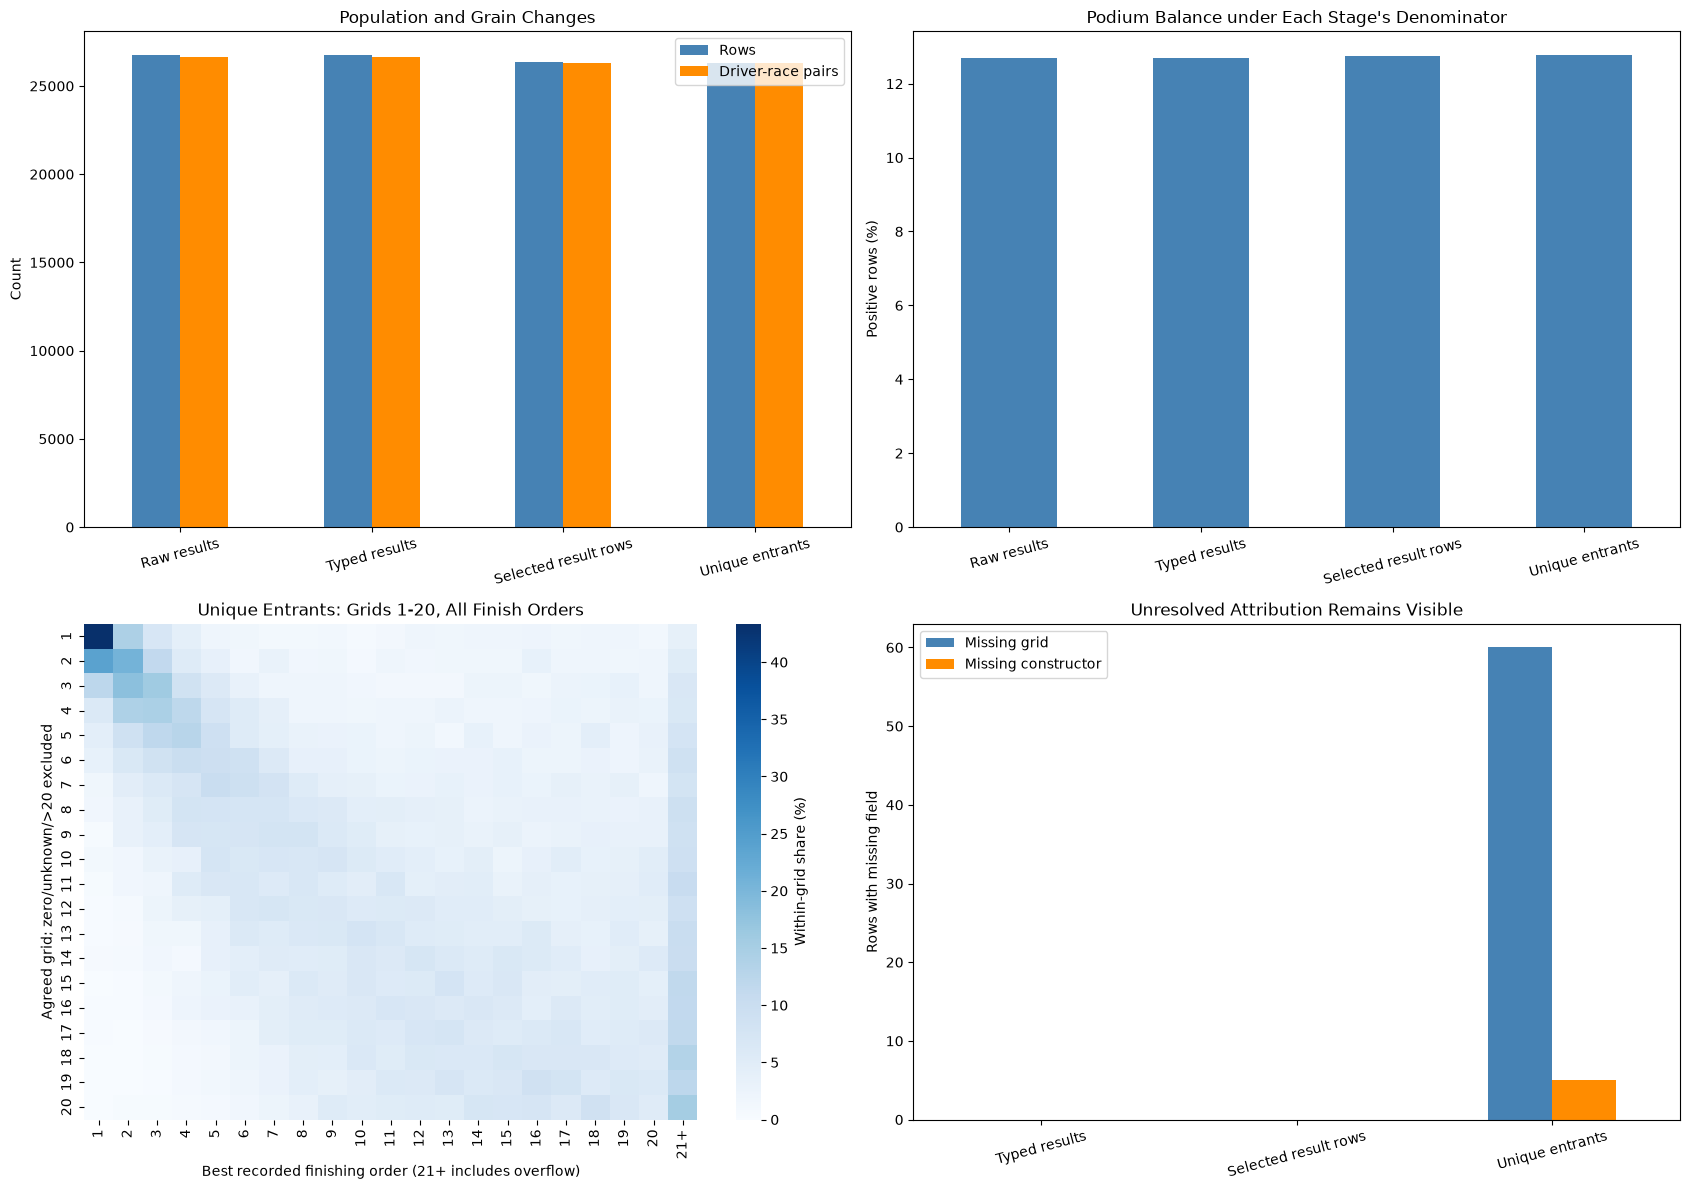

In [159]:
with pd.option_context("display.max_columns", None, "display.max_colwidth", 100):
    print("Consolidated cleaning impact: source-row and driver-race denominators differ")
    display(cleaning_population_impact)
    print("Unavailable information before/after normalization: all 14 source tables")
    display(cleaning_normalization_summary)
    print("Attribution missingness introduced by explicit conflict handling")
    display(cleaning_attribution_impact)
    print("Documented decisions; source CSVs remain intact")
    display(cleaning_decision_log)
    print("Plausibility outcomes by severity; flagged counts overlap and must not be summed as unique rows")
    display(plausibility_audit.groupby(["Severity", "Result"]).size().rename("Rules").reset_index())
    print("All flagged rules; complete row evidence is in plausibility_review_rows")
    with pd.option_context("display.max_rows", None):
        display(plausibility_flags)
    for rule in ["pit_stop_sequence_gaps", "fastest_lap_beyond_completed:results",
                 "elapsed_below_lap_bound:results"]:
        if rule in plausibility_review_rows:
            print(f"{rule}: first 12 records; full evidence retained")
            display(plausibility_review_rows[rule].head(12))
    print("Remaining review issues and downstream conditions")
    display(cleaning_review_register)
    print("Corrected grid/finish plot scope")
    display(final_grid_finish_scope)
    print("Duration screens include long values; earlier raw histograms showed only values up to each 99th percentile.")

fig, axes = plt.subplots(2, 2, figsize=(17, 12))
cleaning_population_impact.set_index("Stage")[["Rows", "Driver-race pairs"]].plot.bar(
    ax=axes[0, 0], rot=15, color=["steelblue", "darkorange"]
)
axes[0, 0].set_title("Population and Grain Changes")
axes[0, 0].set_ylabel("Count"); axes[0, 0].set_xlabel("")
cleaning_population_impact.set_index("Stage")["Positive (%)"].plot.bar(
    ax=axes[0, 1], color="steelblue", rot=15
)
axes[0, 1].set_title("Podium Balance under Each Stage's Denominator")
axes[0, 1].set_ylabel("Positive rows (%)"); axes[0, 1].set_xlabel("")
sns.heatmap(final_grid_finish_pct, cmap="Blues", ax=axes[1, 0],
            cbar_kws={"label": "Within-grid share (%)"})
axes[1, 0].set_title("Unique Entrants: Grids 1-20, All Finish Orders")
axes[1, 0].set_xlabel("Best recorded finishing order (21+ includes overflow)")
axes[1, 0].set_ylabel("Agreed grid; zero/unknown/>20 excluded")
cleaning_attribution_impact.set_index("Stage")[["Missing grid", "Missing constructor"]].plot.bar(
    ax=axes[1, 1], rot=15, color=["steelblue", "darkorange"]
)
axes[1, 1].set_title("Unresolved Attribution Remains Visible")
axes[1, 1].set_ylabel("Rows with missing field"); axes[1, 1].set_xlabel("")
plt.tight_layout()
plt.show()


In [160]:
# Focused edge checks: allow legitimate zeros/altitude/large finishes, detect invalid values.
domain_fixture = pd.Series([-1, 0, 1, 39, pd.NA], dtype="Int64")
assert numeric_domain_failure(domain_fixture, minimum=0).tolist() == [True, False, False, False, False]
assert numeric_domain_failure(domain_fixture, minimum=1).tolist() == [True, True, False, False, False]
assert numeric_domain_failure(pd.Series([-91.0, -90.0, 90.0, 91.0]), -90, 90).tolist() == [True, False, False, True]
assert not numeric_domain_failure(pd.Series([-7.0, 2227.0])).any()  # Altitude has no nonnegative bound.
elapsed_fixture = pd.DataFrame({
    "laps": [44, 50], "fastestLapTime": [100.0, 80.0], "milliseconds": [526, 4000000]
})
assert elapsed_below_fastest_lap_bound(elapsed_fixture).tolist() == [True, False]
assert int(final_grid_finish_counts.to_numpy().sum()) == len(final_grid_finish_base)
assert int(final_grid_finish_counts["21+"].sum()) == int(
    final_grid_finish_base["best_positionOrder"].gt(20).sum()
)
nonempty_grids = final_grid_finish_counts.sum(axis=1).gt(0)
assert np.allclose(final_grid_finish_pct.loc[nonempty_grids].sum(axis=1), 100)
assert len(final_grid_finish_base) + int(unique_driver_race_candidates["grid"].isna().sum()) + int(
    unique_driver_race_candidates["grid"].eq(0).sum()
) + int(unique_driver_race_candidates["grid"].gt(20).sum()) == len(unique_driver_race_candidates)

source_unchanged = step7_source_fingerprints() == step9_sources_before
unique_unchanged = step7_frame_fingerprint(unique_driver_race_candidates) == step9_unique_before
csv_unchanged = all(
    hashlib.sha256(Path(row["File"]).read_bytes()).hexdigest() == row["SHA256"]
    for row in step9_csv_manifest.to_dict("records")
)
expected_scope_ids = population_audit.loc[population_audit["population_keep"], "resultId"]
expected_pair_set = set(map(tuple, modeling_population_candidates[DRIVER_RACE_KEY].to_numpy()))
actual_pair_set = set(map(tuple, unique_driver_race_candidates[DRIVER_RACE_KEY].to_numpy()))
final_label_check = unique_driver_race_candidates.set_index(DRIVER_RACE_KEY)["podium"].equals(
    modeling_population_candidates.assign(
        podium=modeling_population_candidates["positionOrder"].le(3).astype("Int64")
    ).groupby(DRIVER_RACE_KEY)["podium"].max()
)
cleaning_release_gates = pd.DataFrame([
    ("All source primary keys complete and unique", final_primary_key_audit["Status"].eq("PASS").all()),
    ("All declared foreign-key relationships valid", final_foreign_key_audit["Status"].eq("PASS").all()),
    ("No available values lost to semantic conversion", conversion_failures_df.empty),
    ("No remaining sentinel or blank strings", final_clean_missing_profile[["Sentinel Values", "Empty Strings"]].sum().sum() == 0),
    ("Unavailable-cell totals preserved by normalization",
     final_raw_missing_profile["Total Unavailable"].sum() == final_clean_missing_profile["Total Unavailable"].sum()),
    ("All hard plausibility constraints pass", not plausibility_audit.loc[plausibility_audit["Severity"].eq("ERROR"), "Flagged"].gt(0).any()),
    ("Unique non-null entrant keys", not unique_driver_race_candidates[DRIVER_RACE_KEY].isna().any().any()
     and not unique_driver_race_candidates.duplicated(DRIVER_RACE_KEY).any()),
    ("Selected result scope unchanged", set(expected_scope_ids) == set(modeling_population_candidates["resultId"])),
    ("All selected driver-race pairs and races preserved", expected_pair_set == actual_pair_set
     and set(modeling_population_candidates["raceId"]) == set(unique_driver_race_candidates["raceId"])),
    ("Driver-level podium labels reconciled", final_label_check),
    ("Geographic/status mapping policies cover source labels", unmapped_nationality_rows.empty
     and unmapped_circuit_country_rows.empty and unmapped_status_rows.empty),
    ("Source DataFrames, unique entrants, and CSVs unchanged", source_unchanged and unique_unchanged and csv_unchanged)
], columns=["Check", "Passed"])
display(cleaning_release_gates)
assert cleaning_release_gates["Passed"].all(), "Cleaning contract failed: investigate before proceeding."
step9_validation_passed = True
cleaning_structural_checks_passed = True
print(f"PASS: {len(cleaning_release_gates)} release checks; {len(plausibility_audit)} plausibility checks executed.")
print(f"REVIEW: {len(plausibility_flags)} flagged rules; counts can overlap and do not mean confirmed errors.")
print("No source values were corrected or rows additionally excluded in step 9.")
print("The unique entrant base passes structural checks; source-field and cutoff review remains explicit.")


,Check,Passed
0,All source primary keys complete and unique,True
1,All declared foreign-key relationships valid,True
2,No available values lost to semantic conversion,True
3,No remaining sentinel or blank strings,True
4,Unavailable-cell totals preserved by normaliza...,True
5,All hard plausibility constraints pass,True
6,Unique non-null entrant keys,True
7,Selected result scope unchanged,True
8,All selected driver-race pairs and races prese...,True
9,Driver-level podium labels reconciled,True


PASS: 12 release checks; 127 plausibility checks executed.
REVIEW: 9 flagged rules; counts can overlap and do not mean confirmed errors.
No source values were corrected or rows additionally excluded in step 9.
The unique entrant base passes structural checks; source-field and cutoff review remains explicit.


### Cleaning conclusion and remaining conditions

The executed tables are the final cleaning record for the current data and population toggle. **unique_driver_race_candidates** supplies one row per selected driver-race, with documented target aggregation and nullable grid/constructor attribution. **cleaning_release_gates** records structural readiness, while **plausibility_review_rows** retains all flagged evidence.

No plausibility flags are silently repaired or removed. In particular, inspect pit-stop ordinal gaps, fastest-lap indices beyond completed laps, and elapsed durations inconsistent with reported laps before using those source fields. Long durations can include interruptions, and differing position/positionOrder fields do not change the agreed target definition. Source tables remain available for engineering analyses with their own justified grains and denominators.

The corrected grid/finish figure includes finishes above 20; its denominator is all selected unique entrants with agreed grids 1-20. Grid zero, missing grid, and grids above 20 are excluded explicitly in the scope table. Earlier raw plots remain exploratory: their row grain differs, and duration histograms truncate the display at the 99th percentile without deleting data.

Cleaning implementation is complete under the documented rules, with unresolved evidence retained. This does not certify that all historical features are observable before the race. Before modeling, freeze the prediction/split protocol, account for earlier all-year outcome EDA exposure, resolve or test historical attribution assumptions, construct chronological features, and fit learned preprocessing only on training data. Engineering questions still need the documented home-country conventions, uncertain-cause sensitivity, and correct race-start denominators.


## Historical training experiment: 1950–2024 (before step 10)

This independent experiment follows steps 1–9 and precedes the existing 2006-onward modeling table. It trains logistic regression, histogram gradient boosting, and an early-stopping neural network. It does not run ablation, XAI, or preprocessing-order experiments. Variables/functions use `hist_` / `HIST_`; artifacts go to `models/historical_1950/`.

| Partition | Seasons | Purpose |
|---|---|---|
| Training | 1950–2005 | Fit LR/HGB and select their settings using six expanding folds scoring 2000–2005 |
| NN weight fitting | 1950–2003 | Fit NN preprocessing and weights |
| NN stopping | 2004–2005 | Select the best AP checkpoint, patience 15, no refit |
| Validation | 2006–2014 | Select per-model F1 thresholds |
| Test | 2015–2024 | Report performance at frozen thresholds |

**Inputs:** 19 engineered features: grid (2), previous standings (8), last-three-race form (8), and home-country status (1). The four qualifying predictors are omitted entirely. The existing feature definitions, three-race window, NN architecture/optimizer choices, and candidate grids are inherited design choices, not newly established as optimal for this period. LR/HGB settings are selected again entirely within historical training.

**Historical policy:** retain the existing Indianapolis exclusion. Exclude all combined driver–race groups because the source does not establish a unique starting-car/status attribution, any remaining unknown grid/constructor, unknown home-country mappings, and the existing known-nonstarter statuses. Publish the exclusion register and counts. This is a selected historical population: duplicate/attribution exclusions rely on retrospective source structure and may bias representation; they do not establish deployable pre-race eligibility for every historical entrant. No finishing position or outcome chooses the starting car. Positive labels can exceed three per race under historical shared-drive conventions.

Grid zero retains the existing back-of-field encoding. The feature is named `pit_lane_start` for schema compatibility, but historically zero only establishes an unranked recorded grid, not proof of a pit-lane start. Field size is computed before attribution/home exclusions. Missing standings snapshots use the existing zero points/wins convention with an availability flag; the zeros do not prove an actual zero championship total. Debut form stays missing with a zero history count. Numeric imputation/scaling is fitted inside each training fold; binary flags remain known 0/1.

Evaluation is rolling one race ahead: earlier completed validation/test races may supply history for later predictions, never their own or future outcomes. These years have already appeared in prior project analysis and model selection. This is retrospective evaluation, not an untouched blind test; different features and test years also prevent a direct score comparison with the modern experiment.

In [161]:
from pathlib import Path
from itertools import product
from copy import deepcopy
from importlib.metadata import version
import platform
import joblib
import numpy as np
import pandas as pd
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (average_precision_score, roc_auc_score, f1_score,
                             precision_score, recall_score, log_loss)

HIST_SPLITS = {'train': (1950, 2005), 'validation': (2006, 2014), 'test': (2015, 2024)}
HIST_FEATURE_GROUPS = {
    'grid': ['grid_position', 'pit_lane_start'],
    'standings': ['driver_prev_points', 'driver_prev_standing', 'driver_prev_wins',
                  'driver_standing_available', 'constructor_prev_points',
                  'constructor_prev_standing', 'constructor_prev_wins',
                  'constructor_standing_available'],
    'form': ['driver_form_races', 'driver_form_podium_rate', 'driver_form_mean_finish',
             'driver_form_mech_dnf_rate', 'constructor_form_races',
             'constructor_form_podium_rate', 'constructor_form_mean_finish',
             'constructor_form_mech_dnf_rate'],
    'geography': ['is_home'],
}
HIST_FEATURES = [c for group in HIST_FEATURE_GROUPS.values() for c in group]
HIST_BINARY = ['pit_lane_start', 'driver_standing_available',
               'constructor_standing_available', 'is_home']
HIST_NUMERIC = [c for c in HIST_FEATURES if c not in HIST_BINARY]
HIST_NONSTART = ['Did not qualify', 'Did not prequalify', '107% Rule', 'Withdrew']
HIST_OUTPUT_DIR = MODEL_DIR / 'historical_1950'
HIST_FORM_WINDOW = 3


def hist_previous_sum(frame, entity, value, window=3):
    shifted = frame.groupby(entity, sort=False)[value].shift(1)
    return (shifted.groupby(frame[entity], sort=False).rolling(window, min_periods=1)
            .sum().reset_index(level=0, drop=True))


def hist_build_form(history, window=3):
    # History includes all unique entrants, as in step 12; only earlier completed
    # races contribute. Unknown constructors cannot contribute to team history.
    h = history.sort_values(['year', 'round', 'driverId']).reset_index(drop=True).assign(one=1.)
    races = hist_previous_sum(h, 'driverId', 'one', window)
    driver = h[['raceId', 'driverId']].copy()
    driver['driver_form_races'] = races.fillna(0)
    for output, value in [('podium_rate', 'podium'), ('mean_finish', 'finish'),
                          ('mech_dnf_rate', 'mechanical')]:
        driver['driver_form_' + output] = hist_previous_sum(h, 'driverId', value, window) / races
    team = (h.dropna(subset=['constructorId'])
            .groupby(['constructorId', 'year', 'round', 'raceId'], as_index=False)
            .agg(entries=('podium', 'size'), podiums=('podium', 'sum'),
                 finish_sum=('finish', 'sum'), mech=('mechanical', 'sum'))
            .sort_values(['constructorId', 'year', 'round']).reset_index(drop=True)
            .assign(one=1.))
    entries = hist_previous_sum(team, 'constructorId', 'entries', window)
    constructor = team[['raceId', 'constructorId']].copy()
    constructor['constructor_form_races'] = hist_previous_sum(team, 'constructorId', 'one', window).fillna(0)
    for output, value in [('podium_rate', 'podiums'), ('mean_finish', 'finish_sum'),
                          ('mech_dnf_rate', 'mech')]:
        constructor['constructor_form_' + output] = hist_previous_sum(team, 'constructorId', value, window) / entries
    return driver, constructor


def hist_attach_standings(frame, standings, entity, prefix):
    snapshot = standings[['raceId', entity, 'points', 'position', 'wins']].rename(columns={
        'raceId': 'prev_raceId_in_season', 'points': prefix + '_prev_points',
        'position': prefix + '_prev_standing', 'wins': prefix + '_prev_wins'})
    out = frame.merge(snapshot, on=['prev_raceId_in_season', entity],
                      how='left', validate='many_to_one', indicator='_standing')
    out[prefix + '_standing_available'] = out['_standing'].eq('both').astype(int)
    out[prefix + '_prev_points'] = out[prefix + '_prev_points'].fillna(0)
    out[prefix + '_prev_wins'] = out[prefix + '_prev_wins'].fillna(0)
    return out.drop(columns='_standing')


def hist_make_pipeline(model_name, parameters=None):
    parameters = {} if parameters is None else parameters
    numeric_steps = [('imputer', SimpleImputer(strategy='median', keep_empty_features=True))]
    if model_name != 'HGB':
        numeric_steps.append(('scaler', StandardScaler()))
    preprocessing = ColumnTransformer([
        ('numeric', Pipeline(numeric_steps), HIST_NUMERIC),
        ('binary', 'passthrough', HIST_BINARY),
    ], verbose_feature_names_out=False)
    if model_name == 'LR':
        classifier = LogisticRegression(solver='lbfgs', max_iter=5000, tol=1e-4, **parameters)
    elif model_name == 'HGB':
        classifier = HistGradientBoostingClassifier(
            learning_rate=.05, l2_regularization=0., categorical_features=None,
            class_weight=None, early_stopping=False, random_state=0, **parameters)
    elif model_name == 'NN':
        classifier = MLPClassifier(hidden_layer_sizes=(32, 16), activation='relu',
            solver='adam', alpha=.0001, batch_size=64, learning_rate_init=.001,
            max_iter=1000, early_stopping=False, random_state=0)
    else:
        raise ValueError(model_name)
    return Pipeline([('preprocessing', preprocessing), ('classifier', classifier)])


def hist_cv_splits(frame):
    if not frame['year'].between(1950, 2005).all():
        raise ValueError('CV accepts only the 1950–2005 training partition.')
    for score_year in range(2000, 2006):
        fit = frame['year'].lt(score_year).to_numpy()
        score = frame['year'].eq(score_year).to_numpy()
        if not fit.any() or not score.any():
            raise ValueError(f'Empty historical fold: {score_year}')
        assert frame.loc[fit, 'year'].max() < frame.loc[score, 'year'].min()
        assert not set(frame.loc[fit, 'raceId']) & set(frame.loc[score, 'raceId'])
        yield score_year, fit, score


def hist_select_threshold(y, probability):
    # Exact F1 ties: closest to 0.5, then the higher threshold.
    candidates = np.round(np.arange(.005, 1., .005), 3)
    scores = np.array([f1_score(y, probability >= t, zero_division=0) for t in candidates])
    winners = candidates[scores == scores.max()]
    return float(sorted(winners, key=lambda t: (round(abs(t - .5), 12), -t))[0])

In [162]:
assert step9_validation_passed, 'Complete steps 1–9 first.'
hist_sources_before = step7_source_fingerprints()
hist_unique_before = step7_frame_fingerprint(unique_driver_race_candidates)
hist_calendar = (clean_data['races'].loc[
    clean_data['races']['raceId'].isin(clean_data['results']['raceId']),
    ['raceId', 'year', 'round', 'date', 'circuitId']]
    .sort_values(['year', 'round']).reset_index(drop=True))
assert hist_calendar.groupby('year')['date'].apply(lambda x: x.is_monotonic_increasing).all()
hist_calendar['prev_raceId_in_season'] = hist_calendar.groupby('year')['raceId'].shift(1).astype('Int64')
hist_source_status = modeling_population_candidates[['raceId', 'driverId', 'statusId']].merge(
    clean_data['status'][['statusId', 'status']], on='statusId', validate='many_to_one')
hist_nonstart_flags = (hist_source_status.assign(known_nonstart=lambda f: f['status'].isin(HIST_NONSTART))
    .groupby(['raceId', 'driverId'])['known_nonstart'].all().reset_index())
hist_population_audit = (unique_driver_race_candidates.merge(hist_calendar, on='raceId', validate='many_to_one')
    .merge(driver_race_resolution_audit[['raceId', 'driverId', 'source_row_count']],
           on=['raceId', 'driverId'], validate='one_to_one')
    .merge(hist_nonstart_flags, on=['raceId', 'driverId'], validate='one_to_one')
    .merge(home_country_audit[['raceId', 'driverId', 'is_home']],
           on=['raceId', 'driverId'], validate='one_to_one'))
hist_population_audit = hist_population_audit.loc[hist_population_audit['year'].between(1950, 2024)].copy()
# Field size does not shrink when an entrant lacks usable attribution/home data.
hist_field_sizes = (hist_population_audit.loc[~hist_population_audit['known_nonstart']]
                    .groupby('raceId').size().rename('field_size'))
hist_population_audit = hist_population_audit.merge(hist_field_sizes, on='raceId', how='left', validate='many_to_one')
hist_population_audit['exclusion_reason'] = np.select([
    hist_population_audit['source_row_count'].gt(1),
    hist_population_audit[['grid', 'constructorId']].isna().any(axis=1),
    hist_population_audit['known_nonstart'],
    hist_population_audit['is_home'].isna(),
], ['Combined source records: attribution/status uncertain', 'Unknown grid/constructor',
    'Known nonstarter at cutoff', 'Unresolved home-country mapping'], default='Included')
hist_exclusions = hist_population_audit.loc[hist_population_audit['exclusion_reason'].ne('Included')].copy()
hist_features = hist_population_audit.loc[hist_population_audit['exclusion_reason'].eq('Included')].copy()
assert hist_features['grid'].notna().all() and hist_features['grid'].ge(0).all()
hist_features['pit_lane_start'] = hist_features['grid'].eq(0).astype(int)
hist_features['grid_position'] = hist_features['grid'].where(hist_features['grid'].gt(0), hist_features['field_size'])
hist_features['is_home'] = hist_features['is_home'].astype(int)
hist_features = hist_attach_standings(hist_features, clean_data['driver_standings'], 'driverId', 'driver')
hist_features = hist_attach_standings(hist_features, clean_data['constructor_standings'], 'constructorId', 'constructor')

hist_mechanical = (modeling_population_candidates[['raceId', 'driverId', 'statusId']]
    .merge(mechanical_status_mapping[['statusId', 'mechanical_class']], on='statusId', validate='many_to_one')
    .assign(mechanical=lambda f: f['mechanical_class'].eq('mechanical').fillna(False))
    .groupby(['raceId', 'driverId'])['mechanical'].any().astype(float).reset_index())
hist_history = (unique_driver_race_candidates.merge(hist_calendar[['raceId', 'year', 'round']],
    on='raceId', validate='many_to_one').merge(hist_mechanical, on=['raceId', 'driverId'], validate='one_to_one')
    .assign(finish=lambda f: f['best_positionOrder'].astype(float), podium=lambda f: f['podium'].astype(float)))
hist_driver_form, hist_constructor_form = hist_build_form(hist_history, HIST_FORM_WINDOW)
hist_features = (hist_features.merge(hist_driver_form, on=['raceId', 'driverId'], how='left', validate='one_to_one')
    .merge(hist_constructor_form, on=['raceId', 'constructorId'], how='left', validate='many_to_one'))
hist_features['partition'] = pd.Series(pd.NA, index=hist_features.index, dtype='string')
for hist_partition, (hist_first, hist_last) in HIST_SPLITS.items():
    hist_features.loc[hist_features['year'].between(hist_first, hist_last), 'partition'] = hist_partition
HIST_KEYS = ['raceId', 'driverId', 'constructorId', 'circuitId', 'year', 'round', 'date', 'partition']
historical_modeling_table = (hist_features[[*HIST_KEYS, 'podium', *HIST_FEATURES]]
    .sort_values(['year', 'round', 'driverId']).reset_index(drop=True))
assert len(HIST_FEATURES) == 19 and len(set(HIST_FEATURES)) == 19
assert not historical_modeling_table.duplicated(['raceId', 'driverId']).any()
assert historical_modeling_table['partition'].notna().all()
assert historical_modeling_table.groupby('raceId')['partition'].nunique().eq(1).all()
assert historical_modeling_table[HIST_BINARY].isin([0, 1]).all().all()
assert historical_modeling_table.groupby(['raceId', 'constructorId'])[
    HIST_FEATURE_GROUPS['form'][4:]].nunique(dropna=False).le(1).all().all()
assert not {'podium', 'positionOrder', 'best_positionOrder', 'statusId', 'status',
            'points', 'laps', 'q1_gap_to_fastest_pct', 'has_quali_record',
            'q1_time_missing', 'grid_penalty'} & set(HIST_FEATURES)
hist_partition_summary = historical_modeling_table.groupby('partition', sort=False).agg(
    First_season=('year', 'min'), Last_season=('year', 'max'), Races=('raceId', 'nunique'),
    Rows=('driverId', 'size'), Podium_rows=('podium', 'sum'))
hist_partition_summary['Share (%)'] = 100 * hist_partition_summary['Rows'] / len(historical_modeling_table)
hist_exclusion_summary = hist_population_audit.groupby('exclusion_reason').agg(
    Rows=('driverId', 'size'), First_season=('year', 'min'), Last_season=('year', 'max'))
hist_missingness = historical_modeling_table.groupby('partition', sort=False)[HIST_FEATURES].agg(lambda x: x.isna().sum()).T
print('Historical population audit (mutually exclusive reasons, in priority order)')
display(hist_exclusion_summary)
print('Historical split after exclusions')
display(hist_partition_summary)
print('Missing feature counts by partition (numeric values are imputed only inside fitted pipelines)')
display(hist_missingness)
assert step7_source_fingerprints() == hist_sources_before
assert step7_frame_fingerprint(unique_driver_race_candidates) == hist_unique_before

Historical population audit (mutually exclusive reasons, in priority order)


,Rows,First_season,Last_season
exclusion_reason,,,
Combined source records: attribution/status uncertain,64,1950,1978
Included,24602,1950,2024
Known nonstarter at cutoff,1607,1950,2024
Unresolved home-country mapping,14,1962,1972


Historical split after exclusions


,First_season,Last_season,Races,Rows,Podium_rows,Share (%)
partition,,,,,,
train,1950,2005,739,16709,2212,67.917243
validation,2006,2014,166,3686,498,14.982522
test,2015,2024,209,4207,627,17.100236


Missing feature counts by partition (numeric values are imputed only inside fitted pipelines)


partition,train,validation,test
grid_position,0,0,0
pit_lane_start,0,0,0
driver_prev_points,0,0,0
driver_prev_standing,2389,273,220
driver_prev_wins,0,0,0
driver_standing_available,0,0,0
constructor_prev_points,0,0,0
constructor_prev_standing,2429,218,199
constructor_prev_wins,0,0,0
constructor_standing_available,0,0,0


### Historical training-only selection

The six folds fit 1950 through the year before each scoring season, then score 2000, 2001, …, 2005. Each candidate fits fresh preprocessing inside every fold. Rank by mean fold AP; exact ties retain the first candidate in the declared order. LR searches `C={0.1, 1, 10}`. HGB searches the eight combinations of iterations `{100, 200}`, leaves `{7, 15}`, and minimum leaf samples `{40, 20}`. Learning rate stays 0.05. This reproduces the modern search procedure without reusing its selected settings. The fixed last-three-race window and 19-feature schema are inherited choices; there is no feature/architecture search here.

In [163]:
hist_train = historical_modeling_table.loc[historical_modeling_table['partition'].eq('train')].reset_index(drop=True)
hist_validation = historical_modeling_table.loc[historical_modeling_table['partition'].eq('validation')].reset_index(drop=True)
hist_test = historical_modeling_table.loc[historical_modeling_table['partition'].eq('test')].reset_index(drop=True)
hist_X_train = hist_train[HIST_FEATURES].astype('Float64').astype('float64')
hist_y_train = hist_train['podium'].astype(int).to_numpy()
HIST_CANDIDATES = {
    'LR': [{'C': c} for c in [.1, 1., 10.]],
    'HGB': [{'max_iter': n, 'max_leaf_nodes': leaves, 'min_samples_leaf': minimum}
            for n, leaves, minimum in product([100, 200], [7, 15], [40, 20])],
}
hist_cv_rows = []
for hist_name, hist_candidates in HIST_CANDIDATES.items():
    for hist_candidate_id, hist_parameters in enumerate(hist_candidates):
        for hist_score_year, hist_fit_mask, hist_score_mask in hist_cv_splits(hist_train):
            hist_candidate = hist_make_pipeline(hist_name, hist_parameters)
            hist_candidate.fit(hist_X_train.loc[hist_fit_mask], hist_y_train[hist_fit_mask])
            hist_probability = hist_candidate.predict_proba(hist_X_train.loc[hist_score_mask])[:, 1]
            hist_cv_rows.append({'Model': hist_name, 'Candidate': hist_candidate_id,
                'Parameters': str(hist_parameters), 'Fit through': hist_score_year - 1,
                'Score season': hist_score_year, 'Fit rows': int(hist_fit_mask.sum()),
                'Score rows': int(hist_score_mask.sum()),
                'AP': average_precision_score(hist_y_train[hist_score_mask], hist_probability),
                'ROC-AUC': roc_auc_score(hist_y_train[hist_score_mask], hist_probability)})
hist_cv_results = pd.DataFrame(hist_cv_rows)
hist_cv_summary = hist_cv_results.groupby(['Model', 'Candidate', 'Parameters'], sort=False).agg(
    Folds=('AP', 'size'), Mean_AP=('AP', 'mean'), SD_AP=('AP', 'std'),
    Mean_ROC_AUC=('ROC-AUC', 'mean')).reset_index()
assert hist_cv_summary['Folds'].eq(6).all() and len(hist_cv_results) == 66
hist_selected_parameters = {}
for hist_name in HIST_CANDIDATES:
    hist_scores = hist_cv_summary.loc[hist_cv_summary['Model'].eq(hist_name)]
    hist_best = hist_scores.loc[hist_scores['Mean_AP'].idxmax()]
    hist_selected_parameters[hist_name] = dict(HIST_CANDIDATES[hist_name][int(hist_best['Candidate'])])
with pd.option_context('display.max_colwidth', None, 'display.precision', 4):
    display(hist_cv_summary)
print('Selected using 1950–2005 only:', hist_selected_parameters)

,Model,Candidate,Parameters,Folds,Mean_AP,SD_AP,Mean_ROC_AUC
0,LR,0,{'C': 0.1},6,0.6676,0.0962,0.9106
1,LR,1,{'C': 1.0},6,0.6670,0.0982,0.9105
2,LR,2,{'C': 10.0},6,0.6672,0.0981,0.9105
3,HGB,0,"{'max_iter': 100, 'max_leaf_nodes': 7, 'min_samples_leaf': 40}",6,0.6496,0.1153,0.9105
4,HGB,1,"{'max_iter': 100, 'max_leaf_nodes': 7, 'min_samples_leaf': 20}",6,0.6547,0.1142,0.9107
5,HGB,2,"{'max_iter': 100, 'max_leaf_nodes': 15, 'min_samples_leaf': 40}",6,0.6513,0.1091,0.9103
6,HGB,3,"{'max_iter': 100, 'max_leaf_nodes': 15, 'min_samples_leaf': 20}",6,0.6534,0.1147,0.9100
7,HGB,4,"{'max_iter': 200, 'max_leaf_nodes': 7, 'min_samples_leaf': 40}",6,0.6365,0.0995,0.9101
8,HGB,5,"{'max_iter': 200, 'max_leaf_nodes': 7, 'min_samples_leaf': 20}",6,0.6397,0.0976,0.9097
9,HGB,6,"{'max_iter': 200, 'max_leaf_nodes': 15, 'min_samples_leaf': 40}",6,0.6299,0.1031,0.9071


Selected using 1950–2005 only: {'LR': {'C': 0.1}, 'HGB': {'max_iter': 100, 'max_leaf_nodes': 7, 'min_samples_leaf': 20}}


In [164]:
from copy import deepcopy
from sklearn.base import clone
from sklearn.metrics import log_loss


def hist_train_with_patience(template, X_fit, y_fit, X_stop, y_stop,
                           patience=15, max_epochs=1000, min_delta=0.0):
    """Restore best stopping AP; caller provides chronological, race-disjoint sets."""
    if patience < 1 or max_epochs < 1 or min_delta < 0:
        raise ValueError("patience/max_epochs must be positive; min_delta must be nonnegative.")
    if set(np.unique(y_fit)) != {0, 1} or set(np.unique(y_stop)) != {0, 1}:
        raise ValueError("Fitting and stopping sets must each contain both target classes.")
    preprocessor = clone(template.named_steps["preprocessing"])
    Xt_fit = preprocessor.fit_transform(X_fit, y_fit)
    Xt_stop = preprocessor.transform(X_stop)
    if not np.isfinite(Xt_fit).all() or not np.isfinite(Xt_stop).all():
        raise ValueError("Preprocessing produced nonfinite values.")
    classifier = clone(template.named_steps["classifier"])
    if classifier.solver != "adam":
        raise ValueError("This loop is configured for the existing Adam network.")
    # One persistent RNG advances the minibatch shuffle reproducibly across epochs.
    classifier.set_params(early_stopping=False, n_iter_no_change=max_epochs + 1,
                          random_state=np.random.RandomState(0))
    best_score, best_epoch, stale_epochs = -np.inf, None, 0
    best_classifier, best_probability = None, None
    history = []
    stop_reason = "max_epochs"
    for epoch in range(1, max_epochs + 1):
        classifier.partial_fit(Xt_fit, y_fit, classes=np.array([0, 1]))
        probability = classifier.predict_proba(Xt_stop)[:, 1]
        score = float(average_precision_score(y_stop, probability))
        objective = float(classifier.loss_)
        stopping_loss = float(log_loss(y_stop, probability, labels=[0, 1]))
        if not np.isfinite([score, objective, stopping_loss]).all():
            raise RuntimeError(f"Nonfinite training/stopping metric at epoch {epoch}.")
        improved = score > best_score + min_delta
        if improved:
            best_score, best_epoch, stale_epochs = score, epoch, 0
            best_classifier = deepcopy(classifier)
            best_probability = probability.copy()
        else:
            stale_epochs += 1
        history.append({"Epoch": epoch, "Training objective": objective,
                        "Stopping AP": score, "Stopping log loss": stopping_loss,
                        "Improved": improved, "Epochs without improvement": stale_epochs})
        if stale_epochs >= patience:
            stop_reason = "patience"
            break
    restored = Pipeline([("preprocessing", preprocessor), ("classifier", best_classifier)])
    np.testing.assert_allclose(restored.predict_proba(X_stop)[:, 1], best_probability,
                               rtol=1e-12, atol=1e-12)
    info = {"monitor": "average_precision", "mode": "max", "patience": patience,
            "min_delta": min_delta, "max_epochs": max_epochs,
            "best_epoch": best_epoch, "epochs_run": len(history),
            "best_stopping_ap": best_score, "stop_reason": stop_reason,
            "restore_best_weights": True, "random_seed": 0}
    return restored, pd.DataFrame(history), info

In [165]:
hist_models = {}
for hist_name in ['LR', 'HGB']:
    hist_models[hist_name] = hist_make_pipeline(hist_name, hist_selected_parameters[hist_name])
    hist_models[hist_name].fit(hist_X_train, hist_y_train)
    assert all(hist_models[hist_name].named_steps['classifier'].get_params()[key] == value
               for key, value in hist_selected_parameters[hist_name].items())
hist_nn_fit_mask = hist_train['year'].le(2003).to_numpy()
hist_nn_stop_mask = hist_train['year'].between(2004, 2005).to_numpy()
assert hist_nn_fit_mask.any() and hist_nn_stop_mask.any()
assert not set(hist_train.loc[hist_nn_fit_mask, 'raceId']) & set(hist_train.loc[hist_nn_stop_mask, 'raceId'])
hist_models['NN'], hist_nn_history, hist_nn_info = hist_train_with_patience(
    hist_make_pipeline('NN'), hist_X_train.loc[hist_nn_fit_mask], hist_y_train[hist_nn_fit_mask],
    hist_X_train.loc[hist_nn_stop_mask], hist_y_train[hist_nn_stop_mask], patience=15, max_epochs=1000)
for hist_name, hist_model in hist_models.items():
    hist_fit_X = hist_X_train.loc[hist_nn_fit_mask] if hist_name == 'NN' else hist_X_train
    hist_pre = hist_model.named_steps['preprocessing']
    np.testing.assert_allclose(hist_pre.named_transformers_['numeric'].named_steps['imputer'].statistics_,
                               hist_fit_X[HIST_NUMERIC].median().fillna(0).to_numpy())
    assert hist_pre.transform(hist_fit_X).shape[1] == 19
    assert np.isfinite(hist_pre.transform(hist_fit_X)).all()
assert [hist_models['NN'].named_steps['classifier'].coefs_[0].shape[0],
        *hist_models['NN'].named_steps['classifier'].hidden_layer_sizes, 1] == [19, 32, 16, 1]
print('Historical NN stopping:', hist_nn_info)
display(hist_nn_history)

Historical NN stopping: {'monitor': 'average_precision', 'mode': 'max', 'patience': 15, 'min_delta': 0.0, 'max_epochs': 1000, 'best_epoch': 6, 'epochs_run': 21, 'best_stopping_ap': 0.6948029983906056, 'stop_reason': 'patience', 'restore_best_weights': True, 'random_seed': 0}


,Epoch,Training objective,Stopping AP,Stopping log loss,Improved,Epochs without improvement
0,1,0.308933,0.642250,0.278773,True,0
1,2,0.268049,0.665474,0.269896,True,0
2,3,0.263751,0.683709,0.273311,True,0
3,4,0.261733,0.679028,0.277822,False,1
4,5,0.260574,0.694226,0.277362,True,0
5,6,0.259943,0.694803,0.268473,True,0
6,7,0.259371,0.692958,0.272431,False,1
7,8,0.258627,0.689884,0.274127,False,2
8,9,0.258358,0.691476,0.275315,False,3
9,10,0.257411,0.686300,0.273366,False,4


### Historical validation thresholds, final metrics, and separate artifacts

For each model, select the threshold maximizing validation F1 on the 0.005 grid from 0.005 to 0.995. Exact ties prefer the threshold closest to 0.5, then the higher threshold. Validation F1 is a selection score and may be optimistic. Report ROC-AUC, AP, F1, precision, and recall on all three partitions; also report the NN weight-fitting/stopping segments separately. The NN's combined training-period metric includes its stopping rows and is not purely an in-sample score. Training metrics for LR/HGB are in-sample diagnostics. No test outcome selects a parameter, epoch, or threshold in this section.

Each model bundle saves its pipeline, ordered input contract, training protocol, CV parameters, threshold, and metrics. The combined inference bundle consumes engineered records with these same 19 columns; it does not generate historical features from raw inputs. Numeric values can be missing, but all four binary flags must be known 0/1. CSV exports retain prediction keys and thresholds, and record exclusions and model-selection evidence.

In [166]:
hist_X_validation = hist_validation[HIST_FEATURES].astype('Float64').astype('float64')
hist_y_validation = hist_validation['podium'].astype(int).to_numpy()
hist_thresholds = {name: hist_select_threshold(hist_y_validation, model.predict_proba(hist_X_validation)[:, 1])
                   for name, model in hist_models.items()}
# Thresholds are frozen before obtaining test probabilities.
hist_metric_rows, hist_prediction_frames = [], []
for hist_name, hist_model in hist_models.items():
    hist_partitions = {'Training (1950–2005)': hist_train,
                       'Validation (2006–2014)': hist_validation, 'Test (2015–2024)': hist_test}
    if hist_name == 'NN':
        hist_partitions.update({'NN weight fitting (1950–2003)': hist_train.loc[hist_nn_fit_mask],
                                'NN stopping (2004–2005)': hist_train.loc[hist_nn_stop_mask]})
    for hist_label, hist_rows in hist_partitions.items():
        hist_X = hist_rows[HIST_FEATURES].astype('Float64').astype('float64')
        hist_y = hist_rows['podium'].astype(int).to_numpy()
        hist_p = hist_model.predict_proba(hist_X)[:, 1]
        assert np.isfinite(hist_p).all() and ((hist_p >= 0) & (hist_p <= 1)).all()
        hist_predicted = (hist_p >= hist_thresholds[hist_name]).astype(int)
        hist_metric_rows.append({'Model': hist_name, 'Partition': hist_label, 'Rows': len(hist_rows),
            'Threshold': hist_thresholds[hist_name], 'ROC-AUC': roc_auc_score(hist_y, hist_p),
            'AP': average_precision_score(hist_y, hist_p), 'F1': f1_score(hist_y, hist_predicted, zero_division=0),
            'Precision': precision_score(hist_y, hist_predicted, zero_division=0),
            'Recall': recall_score(hist_y, hist_predicted, zero_division=0),
            'F1 at 0.5': f1_score(hist_y, hist_p >= .5, zero_division=0)})
        if hist_label.startswith('Test'):
            hist_prediction_frames.append(hist_rows[['raceId', 'driverId', 'year', 'podium']].assign(
                Model=hist_name, podium_probability=hist_p,
                selected_threshold=hist_thresholds[hist_name], predicted_podium=hist_predicted))
hist_metrics = pd.DataFrame(hist_metric_rows)
hist_test_predictions = pd.concat(hist_prediction_frames, ignore_index=True)
assert len(hist_test_predictions) == 3 * len(hist_test)
assert hist_test_predictions.groupby(['Model', 'raceId', 'driverId']).size().eq(1).all()
hist_versions = {'python': platform.python_version(),
    **{package: version(package) for package in ['scikit-learn', 'numpy', 'pandas', 'joblib']}}
hist_inference_models = {}
HIST_MODEL_FILES = {'LR': 'logistic_regression.joblib', 'HGB': 'hist_gradient_boosting.joblib',
                    'NN': 'shallow_neural_network_early_stopping.joblib'}
HIST_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
for hist_name, hist_model in hist_models.items():
    hist_bundle = {'pipeline': hist_model, 'feature_columns': list(HIST_FEATURES),
        'numeric_features': list(HIST_NUMERIC), 'binary_features': list(HIST_BINARY),
        'feature_groups': HIST_FEATURE_GROUPS, 'target': 'podium', 'positive_class': 1,
        'threshold': hist_thresholds[hist_name], 'threshold_selection': 'validation F1; 0.005 grid; closest to 0.5 then higher',
        'split_boundaries': HIST_SPLITS, 'form_window': HIST_FORM_WINDOW,
        'train_seasons': [1950, 2003] if hist_name == 'NN' else [1950, 2005],
        'stopping_seasons': [2004, 2005] if hist_name == 'NN' else None,
        'validation_seasons': [2006, 2014], 'test_seasons': [2015, 2024],
        'selected_cv_parameters': hist_selected_parameters.get(hist_name),
        'cv_score_seasons': list(range(2000, 2006)) if hist_name != 'NN' else None,
        'training_protocol': 'historical_patience_restore_no_refit' if hist_name == 'NN' else 'historical_expanding_cv',
        'early_stopping': hist_nn_info if hist_name == 'NN' else None,
        'architecture': [19, 32, 16, 1] if hist_name == 'NN' else None,
        'metrics': hist_metrics.loc[hist_metrics['Model'].eq(hist_name)].to_dict('records'),
        'population_policy': 'Existing Indianapolis policy; exclude combined source groups, unknown grid/constructor, known nonstarters, unresolved home country',
        'limitations': 'Retrospective population; inherited feature design; prior exposure to validation/test years; grid zero means unranked, not proven pit lane',
        'versions': hist_versions}
    joblib.dump(hist_bundle, HIST_OUTPUT_DIR / HIST_MODEL_FILES[hist_name], compress=3)
    hist_reloaded = joblib.load(HIST_OUTPUT_DIR / HIST_MODEL_FILES[hist_name])
    np.testing.assert_allclose(hist_reloaded['pipeline'].predict_proba(hist_X_validation),
                               hist_model.predict_proba(hist_X_validation), rtol=1e-12, atol=1e-12)
    hist_inference_models[hist_name] = hist_bundle
joblib.dump(hist_inference_models, HIST_OUTPUT_DIR / 'inference_models.joblib', compress=3)
hist_combined_reload = joblib.load(HIST_OUTPUT_DIR / 'inference_models.joblib')
for hist_name in hist_models:
    assert hist_combined_reload[hist_name]['threshold'] == hist_thresholds[hist_name]
    np.testing.assert_allclose(hist_combined_reload[hist_name]['pipeline'].predict_proba(hist_X_validation),
                               hist_models[hist_name].predict_proba(hist_X_validation), rtol=1e-12, atol=1e-12)
hist_metrics.to_csv(HIST_OUTPUT_DIR / 'metrics.csv', index=False)
hist_test_predictions.to_csv(HIST_OUTPUT_DIR / 'test_predictions.csv', index=False)
hist_cv_results.to_csv(HIST_OUTPUT_DIR / 'cv_results.csv', index=False)
hist_nn_history.to_csv(HIST_OUTPUT_DIR / 'nn_stopping_history.csv', index=False)
hist_exclusions[['raceId', 'driverId', 'year', 'exclusion_reason']].to_csv(HIST_OUTPUT_DIR / 'excluded_entries.csv', index=False)
hist_partition_summary.to_csv(HIST_OUTPUT_DIR / 'partition_summary.csv')
hist_saved_predictions = pd.read_csv(HIST_OUTPUT_DIR / 'test_predictions.csv')
assert len(hist_saved_predictions) == len(hist_test_predictions)
np.testing.assert_array_equal(hist_saved_predictions['predicted_podium'],
    (hist_saved_predictions['podium_probability'] >= hist_saved_predictions['selected_threshold']).astype(int))
assert step7_source_fingerprints() == hist_sources_before
assert step7_frame_fingerprint(unique_driver_race_candidates) == hist_unique_before
with pd.option_context('display.max_columns', None, 'display.precision', 4):
    display(hist_metrics)
print('Historical thresholds:', hist_thresholds)
print('Saved separate historical models and evidence to:', HIST_OUTPUT_DIR.resolve())
print('No historical ablation or XAI. Continue below for the unchanged modern modeling workflow.')

,Model,Partition,Rows,Threshold,ROC-AUC,AP,F1,Precision,Recall,F1 at 0.5
0,LR,Training (1950–2005),16709,0.30,0.8868,0.5186,0.5550,0.4933,0.6343,0.4123
1,LR,Validation (2006–2014),3686,0.30,0.9202,0.6439,0.6549,0.5638,0.7811,0.5126
2,LR,Test (2015–2024),4207,0.30,0.9378,0.7259,0.7005,0.6152,0.8134,0.6297
3,HGB,Training (1950–2005),16709,0.35,0.8968,0.5480,0.5535,0.5148,0.5986,0.4317
4,HGB,Validation (2006–2014),3686,0.35,0.9213,0.6286,0.6482,0.5560,0.7771,0.5845
5,HGB,Test (2015–2024),4207,0.35,0.9379,0.7047,0.6826,0.5739,0.8421,0.6803
6,NN,Training (1950–2005),16709,0.35,0.8904,0.5262,0.5552,0.4970,0.6288,0.4767
7,NN,Validation (2006–2014),3686,0.35,0.9160,0.6185,0.6260,0.5532,0.7209,0.4783
8,NN,Test (2015–2024),4207,0.35,0.9320,0.6857,0.6456,0.6244,0.6683,0.5111
9,NN,NN weight fitting (1950–2003),15987,0.35,0.8899,0.5163,0.5527,0.4942,0.6268,0.4701


Historical thresholds: {'LR': 0.3, 'HGB': 0.35, 'NN': 0.35}
Saved separate historical models and evidence to: /kaggle/working/models/historical_1950
No historical ablation or XAI. Continue below for the unchanged modern modeling workflow.


### Historical experiment handoff

The tables above are the executed historical experiment results. Use `historical_modeling_table`, `hist_metrics`, `hist_cv_results`, `hist_nn_info`, and `hist_exclusions` to inspect this run. All historical model files live in `models/historical_1950/`; the existing modern filenames are not written by this section.

For inference, load `models/historical_1950/inference_models.joblib`, select `LR`, `HGB`, or `NN`, order engineered inputs using that bundle's `feature_columns`, and call its pipeline's `predict_proba`. Apply that bundle's saved `threshold`. Its feature history and missing-value conventions must match this section; do not pass the modern 23-column input directly.

The next section starts the original 2006-onward modeling workflow. Historical results do not alter its data split, feature selection, fitted models, ablation, or XAI.

## Modeling table (step 10)

Build one row per `(raceId, driverId)` for prediction **after qualifying and before the race starts**. The table starts from `unique_driver_race_candidates` and only adds information known at that cutoff.

**Decisions applied (user-approved):**

| Topic | Decision | Reason |
|---|---|---|
| Modeling window | Seasons **2006-2024** | Qualifying-record coverage is about 99.7% from 2006; before 1994 there are no records and 1994-2002 coverage is erratic. All 63 unresolved grid/constructor attributions are from 1950-1978, so this window needs no conflict-based exclusion. All seasons remain available for the engineering questions. |
| Non-starters known at the cutoff | **Exclude** entries whose recorded status is *Did not qualify*, *Did not prequalify*, *107% Rule*, or *Withdrew* | These drivers are known not to take the start once qualifying ends, so a podium prediction for them is not meaningful. This filter removes rows; it never becomes a predictor. *Disqualified* and *Excluded* are decided after the race and stay. Rows coded `W`/`F` with another status (mostly mechanical failures before the start) are **kept** and listed in `modeling_nonstart_code_review`, because their timing relative to the cutoff is not established. |
| Grid recorded as 0 | `pit_lane_start = 1` and `grid_position = field_size` | A raw 0 would rank ahead of pole position. The race's field size places these drivers at the back. This is a fixed rule with no learned values, so it cannot leak across partitions. |
| Missing qualifying record | `quali_position = grid_position`, `has_quali_record = 0`, so `grid_penalty = 0` | These drivers set no classified qualifying time but still received a grid slot; the flag preserves the absence. |
| Q1 time missing | Keep `q1_gap_to_fastest_pct` missing and set `q1_time_missing = 1` | A missing lap time is never zero seconds. Any imputation must be fitted on training data only. |
| Status | **Not a predictor.** Kept only in the separate `modeling_outcomes` table | Status is recorded after the race and directly reveals retirements. It may be used later for strictly earlier-race features, for engineering question 3, and for error analysis. |
| Split | Train 2006-2019, validation 2020-2021, test 2022-2024 | Follows the terminology guide's season boundaries; every race belongs to exactly one partition. |

**Deferred:** rolling driver and constructor form features. Their look-back window has not been chosen yet, so this table contains grid, qualifying, and previous-race standings features only.

In [167]:
assert step9_validation_passed, "Run step 9 first."
step10_sources_before = step7_source_fingerprints()
step10_unique_before = step7_frame_fingerprint(unique_driver_race_candidates)

MODEL_FIRST_YEAR, MODEL_LAST_YEAR = 2006, 2024
SPLIT_BOUNDARIES = {"train": (2006, 2019), "validation": (2020, 2021), "test": (2022, 2024)}
CUTOFF_KNOWN_NONSTART_STATUSES = ["Did not qualify", "Did not prequalify", "107% Rule", "Withdrew"]

# Race order comes from season and round, never from numeric raceId.
held_race_ids = set(clean_data["results"]["raceId"].dropna())
race_calendar = (
    clean_data["races"].loc[clean_data["races"]["raceId"].isin(held_race_ids),
                            ["raceId", "year", "round", "date", "circuitId", "name"]]
    .rename(columns={"name": "race_name"})
    .sort_values(["year", "round"]).reset_index(drop=True)
)
assert race_calendar.groupby("year")["date"].apply(lambda d: d.is_monotonic_increasing).all(), \
    "Round order and date order disagree inside a season."
race_calendar["prev_raceId_in_season"] = (
    race_calendar.groupby("year")["raceId"].shift(1).astype("Int64")
)

# Window: unique entrants in the modeling seasons, with their recorded status for filtering only.
window_entrants = unique_driver_race_candidates.merge(
    race_calendar, on="raceId", how="left", validate="many_to_one"
)
window_entrants = window_entrants.loc[
    window_entrants["year"].between(MODEL_FIRST_YEAR, MODEL_LAST_YEAR)
].reset_index(drop=True)
window_resolution = driver_race_resolution_audit.merge(
    window_entrants[DRIVER_RACE_KEY], on=DRIVER_RACE_KEY, how="inner", validate="one_to_one"
)
assert window_resolution["source_row_count"].eq(1).all(), \
    "The modeling window contains combined duplicate groups; status attribution needs review."
assert not window_resolution["needs_attribution_review"].any()

window_source_rows = modeling_population_candidates[
    ["resultId", *DRIVER_RACE_KEY, "statusId", "positionText", "points", "laps"]
].merge(clean_data["status"][["statusId", "status"]], on="statusId", how="left", validate="many_to_one")
window_source_rows = window_source_rows.loc[
    window_source_rows["raceId"].isin(window_entrants["raceId"])
]
window_entrants = window_entrants.merge(
    window_source_rows, on=DRIVER_RACE_KEY, how="left", validate="one_to_one", indicator="_source"
)
assert window_entrants["_source"].eq("both").all()
window_entrants = window_entrants.drop(columns="_source")

# The filter uses the recorded status label only (user decision).
window_entrants["excluded_known_nonstart"] = (
    window_entrants["status"].isin(CUTOFF_KNOWN_NONSTART_STATUSES).fillna(False)
)
# Retained for review: W/F result codes with another status (mostly pre-start mechanical
# failures). Their timing relative to the cutoff is not established, so they stay in scope.
modeling_nonstart_code_review = window_entrants.loc[
    ~window_entrants["excluded_known_nonstart"]
    & window_entrants["positionText"].isin(["W", "F"]).fillna(False),
    [*DRIVER_RACE_KEY, "year", "race_name", "constructorId", "grid", "status", "positionText", "laps", "podium"]
].sort_values(["year", "raceId", "driverId"]).reset_index(drop=True)
modeling_excluded_nonstarters = window_entrants.loc[
    window_entrants["excluded_known_nonstart"],
    [*DRIVER_RACE_KEY, "year", "race_name", "constructorId", "grid", "status", "positionText", "laps", "podium"]
].sort_values(["year", "raceId", "driverId"]).reset_index(drop=True)
assert modeling_excluded_nonstarters["podium"].eq(0).all()
modeling_population = window_entrants.loc[~window_entrants["excluded_known_nonstart"]].reset_index(drop=True)

modeling_population_summary = pd.DataFrame([
    {"Stage": stage, "Rows": len(frame), "Races": frame["raceId"].nunique(),
     "Podium rows": int(frame["podium"].sum()), "Podium (%)": 100 * frame["podium"].mean()}
    for stage, frame in [
        ("Unique entrants, all seasons", unique_driver_race_candidates),
        (f"Seasons {MODEL_FIRST_YEAR}-{MODEL_LAST_YEAR}", window_entrants),
        ("Excluded: known non-starters at cutoff", modeling_excluded_nonstarters),
        ("Modeling population", modeling_population)
    ]
])
modeling_exclusion_by_status = (
    modeling_excluded_nonstarters.groupby(["status", "positionText"], dropna=False)
    .size().rename("Rows").reset_index()
)
modeling_population_summary

,Stage,Rows,Races,Podium rows,Podium (%)
0,"Unique entrants, all seasons",26287,1114,3359,12.778179
1,Seasons 2006-2024,7914,375,1125,14.215315
2,Excluded: known non-starters at cutoff,21,16,0,0.000000
3,Modeling population,7893,375,1125,14.253136


In [168]:
features = modeling_population[
    [*DRIVER_RACE_KEY, "constructorId", "circuitId", "year", "round", "date",
     "prev_raceId_in_season", "grid", "podium"]
].copy()

# Grid family: grid 0 is an unranked/pit-lane start, placed at the back of the field.
features["field_size"] = features.groupby("raceId")["driverId"].transform("size").astype("Int64")
features["pit_lane_start"] = features["grid"].eq(0).astype("Int64")
features["grid_position"] = features["grid"].where(
    features["grid"].gt(0), features["field_size"]
).astype("Int64")

# Qualifying family: session classification, penalties, and Q1 pace (all known before the race).
qualifying_features = clean_data["qualifying"][[*DRIVER_RACE_KEY, "position", "q1"]].rename(
    columns={"position": "quali_position_recorded"}
)
race_fastest_q1 = clean_data["qualifying"].groupby("raceId")["q1"].min().rename("race_fastest_q1")
features = features.merge(
    qualifying_features, on=DRIVER_RACE_KEY, how="left", validate="one_to_one", indicator="_quali"
).merge(race_fastest_q1, on="raceId", how="left", validate="many_to_one")
features["has_quali_record"] = features["_quali"].eq("both").astype("Int64")
features["quali_position"] = features["quali_position_recorded"].fillna(
    features["grid_position"]
).astype("Int64")
features["grid_penalty"] = (features["grid_position"] - features["quali_position"]).astype("Int64")
features["q1_gap_to_fastest_pct"] = (
    100 * (features["q1"] / features["race_fastest_q1"] - 1)
).astype("Float64")
features["q1_time_missing"] = features["q1_gap_to_fastest_pct"].isna().astype("Int64")

# Standings family: championship state after the previous race of the same season.
# Absent snapshot (season opener or first appearance) means zero points/wins; rank stays missing.
def attach_previous_standings(frame, standings, entity_key, prefix):
    snapshot = standings[["raceId", entity_key, "points", "position", "wins"]].rename(columns={
        "raceId": "prev_raceId_in_season", "points": f"{prefix}_prev_points",
        "position": f"{prefix}_prev_standing", "wins": f"{prefix}_prev_wins"
    })
    merged = frame.merge(
        snapshot, on=["prev_raceId_in_season", entity_key], how="left",
        validate="many_to_one", indicator="_standing"
    )
    merged[f"{prefix}_standing_available"] = merged["_standing"].eq("both").astype("Int64")
    merged[f"{prefix}_prev_points"] = merged[f"{prefix}_prev_points"].fillna(0).astype("Float64")
    merged[f"{prefix}_prev_wins"] = merged[f"{prefix}_prev_wins"].fillna(0).astype("Int64")
    return merged.drop(columns="_standing")

features = attach_previous_standings(features, clean_data["driver_standings"], "driverId", "driver")
features = attach_previous_standings(
    features, clean_data["constructor_standings"], "constructorId", "constructor"
)

features["partition"] = pd.Series(pd.NA, index=features.index, dtype="string")
for partition_name, (first_year, last_year) in SPLIT_BOUNDARIES.items():
    features.loc[features["year"].between(first_year, last_year), "partition"] = partition_name

MODEL_KEY_COLUMNS = [*DRIVER_RACE_KEY, "constructorId", "circuitId", "year", "date", "partition"]
MODEL_TARGET = "podium"
MODEL_FEATURE_GROUPS = {
    "grid": ["grid_position", "pit_lane_start", "field_size"],
    "qualifying": ["quali_position", "has_quali_record", "grid_penalty",
                   "q1_gap_to_fastest_pct", "q1_time_missing"],
    "standings": ["round",
                  "driver_prev_points", "driver_prev_standing", "driver_prev_wins",
                  "driver_standing_available",
                  "constructor_prev_points", "constructor_prev_standing", "constructor_prev_wins",
                  "constructor_standing_available"]
}
MODEL_FEATURE_COLUMNS = [column for group in MODEL_FEATURE_GROUPS.values() for column in group]

modeling_table = features[[*MODEL_KEY_COLUMNS, MODEL_TARGET, *MODEL_FEATURE_COLUMNS]].sort_values(
    ["date", "raceId", "driverId"]
).reset_index(drop=True)

# Post-race information lives here only; never join it into the predictor matrix.
modeling_outcomes = modeling_population[
    [*DRIVER_RACE_KEY, "resultId", "best_positionOrder", "statusId", "status",
     "positionText", "points", "laps"]
].merge(
    mechanical_status_mapping[["statusId", "mechanical_class", "is_mechanical"]],
    on="statusId", how="left", validate="many_to_one"
).sort_values(DRIVER_RACE_KEY).reset_index(drop=True)

Population from unique entrants to the modeling table


,Stage,Rows,Races,Podium rows,Podium (%)
0,"Unique entrants, all seasons",26287,1114,3359,12.778179
1,Seasons 2006-2024,7914,375,1125,14.215315
2,Excluded: known non-starters at cutoff,21,16,0,0.000000
3,Modeling population,7893,375,1125,14.253136


Rows excluded as known non-starters at the cutoff


,status,positionText,Rows
0,Did not qualify,F,4
1,Withdrew,17,2
2,Withdrew,R,2
3,Withdrew,W,13


Retained for review: W/F result codes with another recorded status


...

,Feature,Group,Source,Meaning at the cutoff,Missing-value rule,Missing rows
0,grid_position,grid,results.grid,Starting grid published before the race,Grid 0 -> field_size,0
1,pit_lane_start,grid,results.grid,Grid 0 marker,Never missing,0
2,field_size,grid,Modeling population per race,Entrants after cutoff non-starters removed,Never missing,0
3,quali_position,qualifying,qualifying.position,Qualifying classification,No record -> grid_position,0
4,has_quali_record,qualifying,qualifying,Whether a qualifying record exists,Never missing,0
5,grid_penalty,qualifying,grid_position - quali_position,"Grid changes after qualifying (penalties, pit-lane starts)",No record -> 0,0
6,q1_gap_to_fastest_pct,qualifying,qualifying.q1,Q1 time relative to the race's fastest Q1 time (%),Left missing; training-fitted imputation later,98
7,q1_time_missing,qualifying,qualifying.q1,Q1 time unavailable,Never missing,0
8,round,standings,races.round,Season stage,Never missing,0
9,driver_prev_points,standings,driver_standings at previous race,Championship points before this race,No snapshot -> 0,0


Grid and qualifying encoding checks


,Check,Rows
0,Pit-lane / unranked starts (grid 0),77
1,No qualifying record,23
2,Q1 time missing,98
3,Grid differs from qualifying position,2287
4,Grid position above field size,8
5,Driver standing unavailable,493
6,Constructor standing unavailable,417


First rows of the modeling table


,raceId,driverId,constructorId,circuitId,year,date,partition,podium,grid_position,pit_lane_start,field_size,quali_position,has_quali_record,grid_penalty,q1_gap_to_fastest_pct,q1_time_missing,round,driver_prev_points,driver_prev_standing,driver_prev_wins,driver_standing_available,constructor_prev_points,constructor_prev_standing,constructor_prev_wins,constructor_standing_available
0,53,2,2,3,2006,2006-03-12,train,0,10,0,22,10,1,0,1.018035,0,1,0.0,<NA>,0,0,0.0,<NA>,0,0
1,53,3,3,3,2006,2006-03-12,train,0,12,0,22,12,1,0,0.553915,0,1,0.0,<NA>,0,0,0.0,<NA>,0,0
2,53,4,4,3,2006,2006-03-12,train,1,4,0,22,4,1,0,0.0,0,1,0.0,<NA>,0,0,0.0,<NA>,0,0
3,53,8,1,3,2006,2006-03-12,train,1,22,0,22,22,1,0,<NA>,1,1,0.0,<NA>,0,0,0.0,<NA>,0,0
4,53,11,8,3,2006,2006-03-12,train,0,20,0,22,20,1,0,5.385522,0,1,0.0,<NA>,0,0,0.0,<NA>,0,0


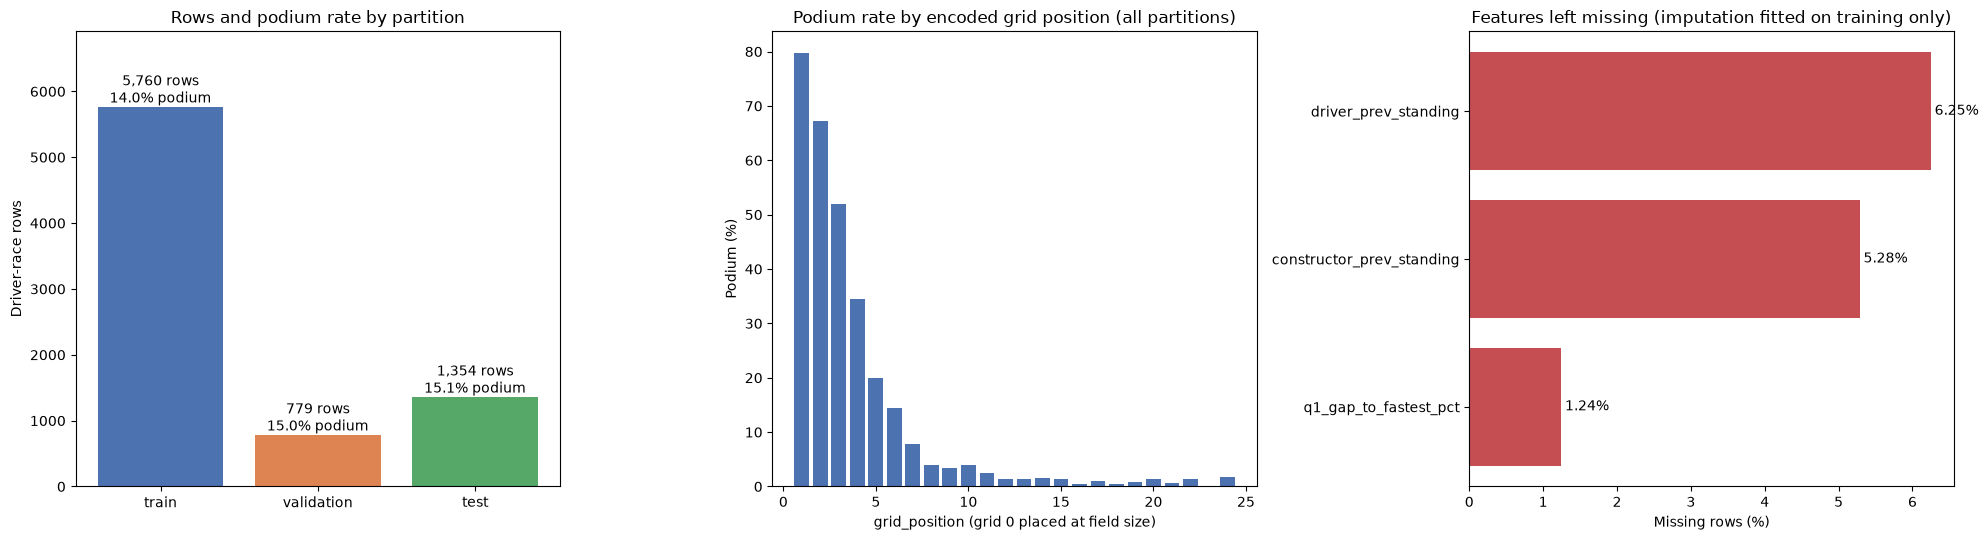

In [169]:
modeling_feature_contract = pd.DataFrame([
    ("grid_position", "grid", "results.grid", "Starting grid published before the race",
     "Grid 0 -> field_size"),
    ("pit_lane_start", "grid", "results.grid", "Grid 0 marker", "Never missing"),
    ("field_size", "grid", "Modeling population per race", "Entrants after cutoff non-starters removed",
     "Never missing"),
    ("quali_position", "qualifying", "qualifying.position", "Qualifying classification",
     "No record -> grid_position"),
    ("has_quali_record", "qualifying", "qualifying", "Whether a qualifying record exists", "Never missing"),
    ("grid_penalty", "qualifying", "grid_position - quali_position",
     "Grid changes after qualifying (penalties, pit-lane starts)", "No record -> 0"),
    ("q1_gap_to_fastest_pct", "qualifying", "qualifying.q1",
     "Q1 time relative to the race's fastest Q1 time (%)", "Left missing; training-fitted imputation later"),
    ("q1_time_missing", "qualifying", "qualifying.q1", "Q1 time unavailable", "Never missing"),
    ("round", "standings", "races.round", "Season stage", "Never missing"),
    ("driver_prev_points", "standings", "driver_standings at previous race",
     "Championship points before this race", "No snapshot -> 0"),
    ("driver_prev_standing", "standings", "driver_standings at previous race",
     "Championship position before this race", "Left missing when no snapshot"),
    ("driver_prev_wins", "standings", "driver_standings at previous race",
     "Season wins before this race", "No snapshot -> 0"),
    ("driver_standing_available", "standings", "driver_standings", "Previous snapshot exists", "Never missing"),
    ("constructor_prev_points", "standings", "constructor_standings at previous race",
     "Team points before this race", "No snapshot -> 0"),
    ("constructor_prev_standing", "standings", "constructor_standings at previous race",
     "Team position before this race", "Left missing when no snapshot"),
    ("constructor_prev_wins", "standings", "constructor_standings at previous race",
     "Team wins before this race", "No snapshot -> 0"),
    ("constructor_standing_available", "standings", "constructor_standings", "Previous snapshot exists",
     "Never missing"),
], columns=["Feature", "Group", "Source", "Meaning at the cutoff", "Missing-value rule"])
modeling_feature_contract["Missing rows"] = modeling_feature_contract["Feature"].map(
    modeling_table[MODEL_FEATURE_COLUMNS].isna().sum()
).astype(int)

modeling_partition_summary = modeling_table.groupby("partition", sort=False).agg(
    First_season=("year", "min"), Last_season=("year", "max"),
    Races=("raceId", "nunique"), Rows=("driverId", "size"), Podium_rows=(MODEL_TARGET, "sum")
).reindex(list(SPLIT_BOUNDARIES)).reset_index()
modeling_partition_summary["Podium (%)"] = (
    100 * modeling_partition_summary["Podium_rows"] / modeling_partition_summary["Rows"]
)
modeling_grid_quali_summary = pd.DataFrame([
    {"Check": "Pit-lane / unranked starts (grid 0)", "Rows": int(modeling_table["pit_lane_start"].sum())},
    {"Check": "No qualifying record", "Rows": int(modeling_table["has_quali_record"].eq(0).sum())},
    {"Check": "Q1 time missing", "Rows": int(modeling_table["q1_time_missing"].sum())},
    {"Check": "Grid differs from qualifying position",
     "Rows": int(modeling_table["grid_penalty"].ne(0).sum())},
    {"Check": "Grid position above field size",
     "Rows": int((features["grid_position"] > features["field_size"]).sum())},
    {"Check": "Driver standing unavailable", "Rows": int(modeling_table["driver_standing_available"].eq(0).sum())},
    {"Check": "Constructor standing unavailable",
     "Rows": int(modeling_table["constructor_standing_available"].eq(0).sum())},
])

with pd.option_context("display.max_columns", None, "display.max_colwidth", 80):
    print("Population from unique entrants to the modeling table")
    display(modeling_population_summary)
    print("Rows excluded as known non-starters at the cutoff")
    display(modeling_exclusion_by_status)
    print("Retained for review: W/F result codes with another recorded status")
    display(modeling_nonstart_code_review.groupby("status").size().rename("Rows").reset_index())
    print("Temporal partitions (each race belongs to exactly one)")
    display(modeling_partition_summary)
    print("Feature contract")
    display(modeling_feature_contract)
    print("Grid and qualifying encoding checks")
    display(modeling_grid_quali_summary)
    print("First rows of the modeling table")
    display(modeling_table.head())

fig, axes = plt.subplots(1, 3, figsize=(20, 5.5))
partition_plot = modeling_partition_summary.set_index("partition")
axes[0].bar(partition_plot.index, partition_plot["Rows"], color=["#4c72b0", "#dd8452", "#55a868"])
for x, (rows, rate) in enumerate(zip(partition_plot["Rows"], partition_plot["Podium (%)"])):
    axes[0].text(x, rows, f"{rows:,} rows\n{rate:.1f}% podium", ha="center", va="bottom")
axes[0].set_title("Rows and podium rate by partition")
axes[0].set_ylabel("Driver-race rows")
axes[0].set_ylim(0, partition_plot["Rows"].max() * 1.2)

podium_by_grid = modeling_table.groupby("grid_position")[MODEL_TARGET].mean().mul(100)
axes[1].bar(podium_by_grid.index.astype(int), podium_by_grid.values, color="#4c72b0")
axes[1].set_title("Podium rate by encoded grid position (all partitions)")
axes[1].set_xlabel("grid_position (grid 0 placed at field size)")
axes[1].set_ylabel("Podium (%)")

missing_pct = modeling_table[MODEL_FEATURE_COLUMNS].isna().mean().mul(100)
missing_pct = missing_pct.loc[missing_pct.gt(0)].sort_values()
axes[2].barh(missing_pct.index, missing_pct.values, color="#c44e52")
for y, value in enumerate(missing_pct.values):
    axes[2].text(value, y, f" {value:.2f}%", va="center")
axes[2].set_title("Features left missing (imputation fitted on training only)")
axes[2].set_xlabel("Missing rows (%)")
plt.tight_layout()
plt.show()

In [170]:
# Validate grain, scope, encodings, cutoff alignment, partitions, and source preservation.
step10_checks = []

def record_step10_check(name, passed, detail):
    step10_checks.append({"Check": name, "Result": "PASS" if passed else "FAIL", "Detail": detail})

mt = modeling_table
forbidden_predictors = {
    "podium", "best_positionOrder", "positionOrder", "position", "positionText", "points",
    "laps", "time", "milliseconds", "fastestLap", "rank", "fastestLapTime", "fastestLapSpeed",
    "statusId", "status", "is_mechanical", "mechanical_class", "grid"
}
record_step10_check("Unique driver-race grain", not mt.duplicated(DRIVER_RACE_KEY).any(),
                    f"{len(mt):,} rows")
record_step10_check(
    "Scope reconciles", len(mt) == len(window_entrants) - len(modeling_excluded_nonstarters)
    and mt["year"].between(MODEL_FIRST_YEAR, MODEL_LAST_YEAR).all(),
    f"{len(window_entrants):,} window rows - {len(modeling_excluded_nonstarters)} excluded"
)
record_step10_check(
    "Every window race retained", mt["raceId"].nunique() == window_entrants["raceId"].nunique(),
    f"{mt['raceId'].nunique()} races"
)
record_step10_check(
    "No outcome or status column among predictors",
    not set(MODEL_FEATURE_COLUMNS) & forbidden_predictors,
    f"{len(MODEL_FEATURE_COLUMNS)} predictors in {len(MODEL_FEATURE_GROUPS)} groups"
)
record_step10_check(
    "Status only in outcome table",
    "status" not in mt.columns and len(modeling_outcomes) == len(mt)
    and not modeling_outcomes.duplicated(DRIVER_RACE_KEY).any(),
    "modeling_outcomes is keyed 1:1 to the modeling table"
)
record_step10_check(
    "No known non-starter remains",
    not modeling_outcomes["status"].isin(CUTOFF_KNOWN_NONSTART_STATUSES).any(),
    f"{len(modeling_excluded_nonstarters)} rows excluded by status; "
    f"{len(modeling_nonstart_code_review)} W/F-coded rows retained for review"
)
record_step10_check(
    "Grid encoding",
    features["grid"].notna().all()
    and features["grid_position"].notna().all() and features["grid_position"].ge(1).all()
    and features["pit_lane_start"].eq(features["grid"].eq(0).astype("Int64")).all()
    and features.loc[features["grid"].eq(0), "grid_position"].eq(
        features.loc[features["grid"].eq(0), "field_size"]).all()
    and features.loc[features["grid"].gt(0), "grid_position"].eq(
        features.loc[features["grid"].gt(0), "grid"]).all(),
    "grid 0 -> field_size; no zero or missing grid positions"
)
no_record = mt["has_quali_record"].eq(0)
record_step10_check(
    "Qualifying fallback",
    mt["quali_position"].notna().all() and mt.loc[no_record, "grid_penalty"].eq(0).all()
    and mt.loc[no_record, "q1_time_missing"].eq(1).all(),
    f"{int(no_record.sum())} rows without a qualifying record"
)
gap = mt["q1_gap_to_fastest_pct"]
record_step10_check(
    "Q1 gap semantics",
    mt["q1_time_missing"].eq(gap.isna().astype("Int64")).all() and gap.dropna().ge(0).all(),
    "Missing Q1 stays missing; available gaps are non-negative"
)
prev = features[["raceId", "prev_raceId_in_season", "year", "round", "date"]].merge(
    race_calendar[["raceId", "year", "round", "date"]].rename(columns={
        "raceId": "prev_raceId_in_season", "year": "prev_year", "round": "prev_round", "date": "prev_date"}),
    on="prev_raceId_in_season", how="left", validate="many_to_one"
)
has_prev = prev["prev_raceId_in_season"].notna()
record_step10_check(
    "Standings come from the previous race of the same season",
    prev.loc[has_prev, "prev_year"].eq(prev.loc[has_prev, "year"]).all()
    and prev.loc[has_prev, "prev_round"].lt(prev.loc[has_prev, "round"]).all()
    and prev.loc[has_prev, "prev_date"].lt(prev.loc[has_prev, "date"]).all()
    and mt.loc[mt["round"].eq(1), ["driver_standing_available", "constructor_standing_available"]].eq(0).all().all(),
    "Season openers carry no snapshot; all others use a strictly earlier race"
)
races_without_snapshot = int(features.loc[has_prev].groupby("raceId")["driver_standing_available"].max().eq(0).sum())
record_step10_check("Every non-opening race has a driver standings snapshot", races_without_snapshot == 0,
                    f"{races_without_snapshot} races without one")
race_partitions = mt.groupby("raceId")["partition"].nunique()
record_step10_check(
    "Partitions are complete and race-disjoint",
    mt["partition"].notna().all() and race_partitions.eq(1).all()
    and all(mt.loc[mt["partition"].eq(p), "year"].between(a, b).all() for p, (a, b) in SPLIT_BOUNDARIES.items()),
    ", ".join(f"{p}: {a}-{b}" for p, (a, b) in SPLIT_BOUNDARIES.items())
)
target_check = mt[[*DRIVER_RACE_KEY, MODEL_TARGET]].merge(
    unique_driver_race_candidates[[*DRIVER_RACE_KEY, "podium"]], on=DRIVER_RACE_KEY,
    suffixes=("", "_source"), validate="one_to_one"
)
record_step10_check("Target matches step-7 labels",
                    target_check[MODEL_TARGET].eq(target_check["podium_source"]).all(),
                    f"{int(mt[MODEL_TARGET].sum()):,} podium rows")
record_step10_check(
    "Sources and unique entrant base unchanged",
    step7_source_fingerprints() == step10_sources_before
    and step7_frame_fingerprint(unique_driver_race_candidates) == step10_unique_before,
    "Raw, cleaned, candidate, and unique-entrant fingerprints"
)

step10_validation = pd.DataFrame(step10_checks)
with pd.option_context("display.max_colwidth", 100):
    display(step10_validation)
step10_validation_passed = step10_validation["Result"].eq("PASS").all()
assert step10_validation_passed, "Step 10 validation failed."
print(f"Step 10 validation passed: {len(step10_validation)} checks; "
      f"modeling_table has {len(mt):,} rows and {len(MODEL_FEATURE_COLUMNS)} predictors.")

,Check,Result,Detail
0,Unique driver-race grain,PASS,"7,893 rows"
1,Scope reconciles,PASS,"7,914 window rows - 21 excluded"
2,Every window race retained,PASS,375 races
3,No outcome or status column among predictors,PASS,17 predictors in 3 groups
4,Status only in outcome table,PASS,modeling_outcomes is keyed 1:1 to the modeling table
5,No known non-starter remains,PASS,21 rows excluded by status; 26 W/F-coded rows retained for review
6,Grid encoding,PASS,grid 0 -> field_size; no zero or missing grid positions
7,Qualifying fallback,PASS,23 rows without a qualifying record
8,Q1 gap semantics,PASS,Missing Q1 stays missing; available gaps are non-negative
9,Standings come from the previous race of the same season,PASS,Season openers carry no snapshot; all others use a strictly earlier race


Step 10 validation passed: 14 checks; modeling_table has 7,893 rows and 17 predictors.


### Step 10 result and handoff

**`modeling_table`**: **7,893 driver-race rows**, **375 races**, **1,125 podium rows (14.3%)**, with no duplicate `(raceId, driverId)` keys. Use `MODEL_FEATURE_COLUMNS` as X and `podium` as y. Key columns (`raceId`, `driverId`, `constructorId`, `circuitId`, `year`, `date`, `partition`) identify rows and are **not** predictors.

| Partition | Seasons | Races | Rows | Podium (%) |
|---|---|---:|---:|---:|
| train | 2006-2019 | 268 | 5,760 | 14.0 |
| validation | 2020-2021 | 39 | 779 | 15.0 |
| test | 2022-2024 | 68 | 1,354 | 15.1 |

**Feature groups (17 predictors):** grid (3), qualifying (5), and previous-race standings (9). Every value is either known after qualifying and before the race start, or is a fixed missing-value rule.

**Encoding outcomes:** 77 grid-zero starts were placed at the back of the field. 23 rows had no qualifying record and use their grid position, and 98 rows have no Q1 time. In 2,287 rows the grid position differs from the qualifying position. For 8 rows the recorded grid slot exceeds the entrant count after exclusions; this is kept as recorded.

**Removed:** 21 rows recorded as *Did not qualify* (4) or *Withdrew* (17), all non-podium. 26 rows coded `W`/`F` with another status (mostly mechanical failures before the start) remain in scope and are listed in `modeling_nonstart_code_review` for a later decision.

**Missing values left for training-fitted imputation:** `q1_gap_to_fastest_pct`, `driver_prev_standing`, and `constructor_prev_standing`. Championship rank is undefined before a driver's or team's first race of the season; the matching `*_standing_available` flag records this.

**Post-race information** (`best_positionOrder`, status, points, laps, `is_mechanical`) is only in **`modeling_outcomes`**. Use it for strictly earlier-race features, engineering question 3, and error analysis. Never merge it into X.

**Limitations and next steps:**
- **Rolling driver and constructor form features are deferred** until a look-back window is chosen; compare candidate windows on the validation seasons only.
- Standings snapshots are taken as recorded. Retrospective penalties may make a few historical snapshots differ from what was published at the time.
- Q1 gaps above roughly 7% usually reflect wet sessions or incidents; they are not clipped.
- Predictions for drivers in the same race are not independent.
- All-year outcome EDA was viewed earlier; disclose this when reporting test results.

## Engineering questions (step 11)

The three data-engineering questions from the brief. To avoid confusion with the qualifying-session columns `q1`/`q2`/`q3`, this section calls them **engineering questions 1-3** and prefixes their objects with `eq1_`, `eq2_`, `eq3_`. Each one combines several tables (multi-hop joins), reports its grain and missingness, and states how the pre-race cutoff applies.

These are **descriptive analyses** of recorded history, not predictive features. They may use the whole cleaned history (step 6 population, Indianapolis 500 excluded), not only the 2006-2024 modeling window. Proportions carry 95% Wilson intervals because many circuit or constructor cells are small.

### Engineering question 1: front-row to podium conversion by circuit, before and after 2014

**Question.** Which circuits convert a front-row start into a podium most often, and does that ranking change after the 2014 hybrid era? Qualifying position and grid position are kept separate.

**Joins.** `unique_driver_race_candidates` -> `races` (year, circuitId) -> `circuits` (name) -> `qualifying` (session classification `position`).

**Grain.** One row per `(raceId, driverId)`. A circuit's conversion rate = podiums / front-row starters at that circuit in that era.

**Definitions.**
- **Starting-grid definition (main answer):** `grid` 1-2, the actual front-row starting slots.
- **Qualifying definition (comparison):** qualifying `position` 1-2, the session classification.
- They differ because of grid penalties, pit-lane starts and sprint-set grids, so both are reported.

**Eras.** The agreed comparison is: **2006-2013** vs **2014-2024**. Both eras use the same knockout qualifying format and have about 99.7% qualifying-record coverage (step 8). Before 2006, qualifying coverage is incomplete, which would bias the qualifying definition only.

Both definitions have separate top-circuit tables, era-change plots, and largest-mover tables. The same eligibility rule is applied independently to each definition.

**Minimum sample.** A circuit is ranked only with **at least 8 front-row starts** in that era (four races).

**Cutoff.** Front-row status is known before the race; the podium is the outcome being summarised.

Engineering question 1: missingness and grid/qualifying differences (driver-race rows, 2006-2024)


,Item,Rows
0,Driver-race rows in engineering-question-1 eras,7914
1,No qualifying record,24
2,Missing grid,0
3,Races with != 2 front-row qualifiers,0
4,Races with != 2 front-row grid slots,2
5,Qualified front row but did not start from it,35
6,Started from front row without qualifying there,33


Overall front-row podium conversion (grid first; qualifying comparison second)


,Definition,Era,Front-row starts,Podium conversion (%)
0,Grid P1-P2,2006-2013 (pre-hybrid),294,69.728
1,Grid P1-P2,2014-2024 (hybrid and later),454,75.991
2,Qualifying P1-P2,2006-2013 (pre-hybrid),294,69.048
3,Qualifying P1-P2,2014-2024 (hybrid and later),456,73.684


Top 10 circuits by Grid P1-P2 podium conversion, 2006-2013 (pre-hybrid) (min 8 observations)


...

,Definition,Circuits eligible in both eras,Spearman rho (pre vs post),p-value
0,Grid P1-P2,15,0.120,0.669
1,Qualifying P1-P2,16,0.437,0.091


Largest decreases and increases (Grid P1-P2, percentage points)


era,2006-2013 (pre-hybrid),2014-2024 (hybrid and later),change_pp
circuit,,,
Hockenheimring,0.875,0.625,-25.000
Hungaroring,0.625,0.591,-3.409
Autodromo Nazionale di Monza,0.750,0.727,-2.273
Circuit Gilles Villeneuve,0.571,0.778,20.635
Autódromo José Carlos Pace,0.562,0.789,22.697
Yas Marina Circuit,0.600,0.864,26.364


Largest decreases and increases (Qualifying P1-P2, percentage points)


era,2006-2013 (pre-hybrid),2014-2024 (hybrid and later),change_pp
circuit,,,
Hockenheimring,0.875,0.625,-25.000
Autodromo Nazionale di Monza,0.750,0.727,-2.273
Silverstone Circuit,0.750,0.750,0.000
Circuit Gilles Villeneuve,0.571,0.722,15.079
Circuit de Barcelona-Catalunya,0.625,0.818,19.318
Yas Marina Circuit,0.600,0.818,21.818


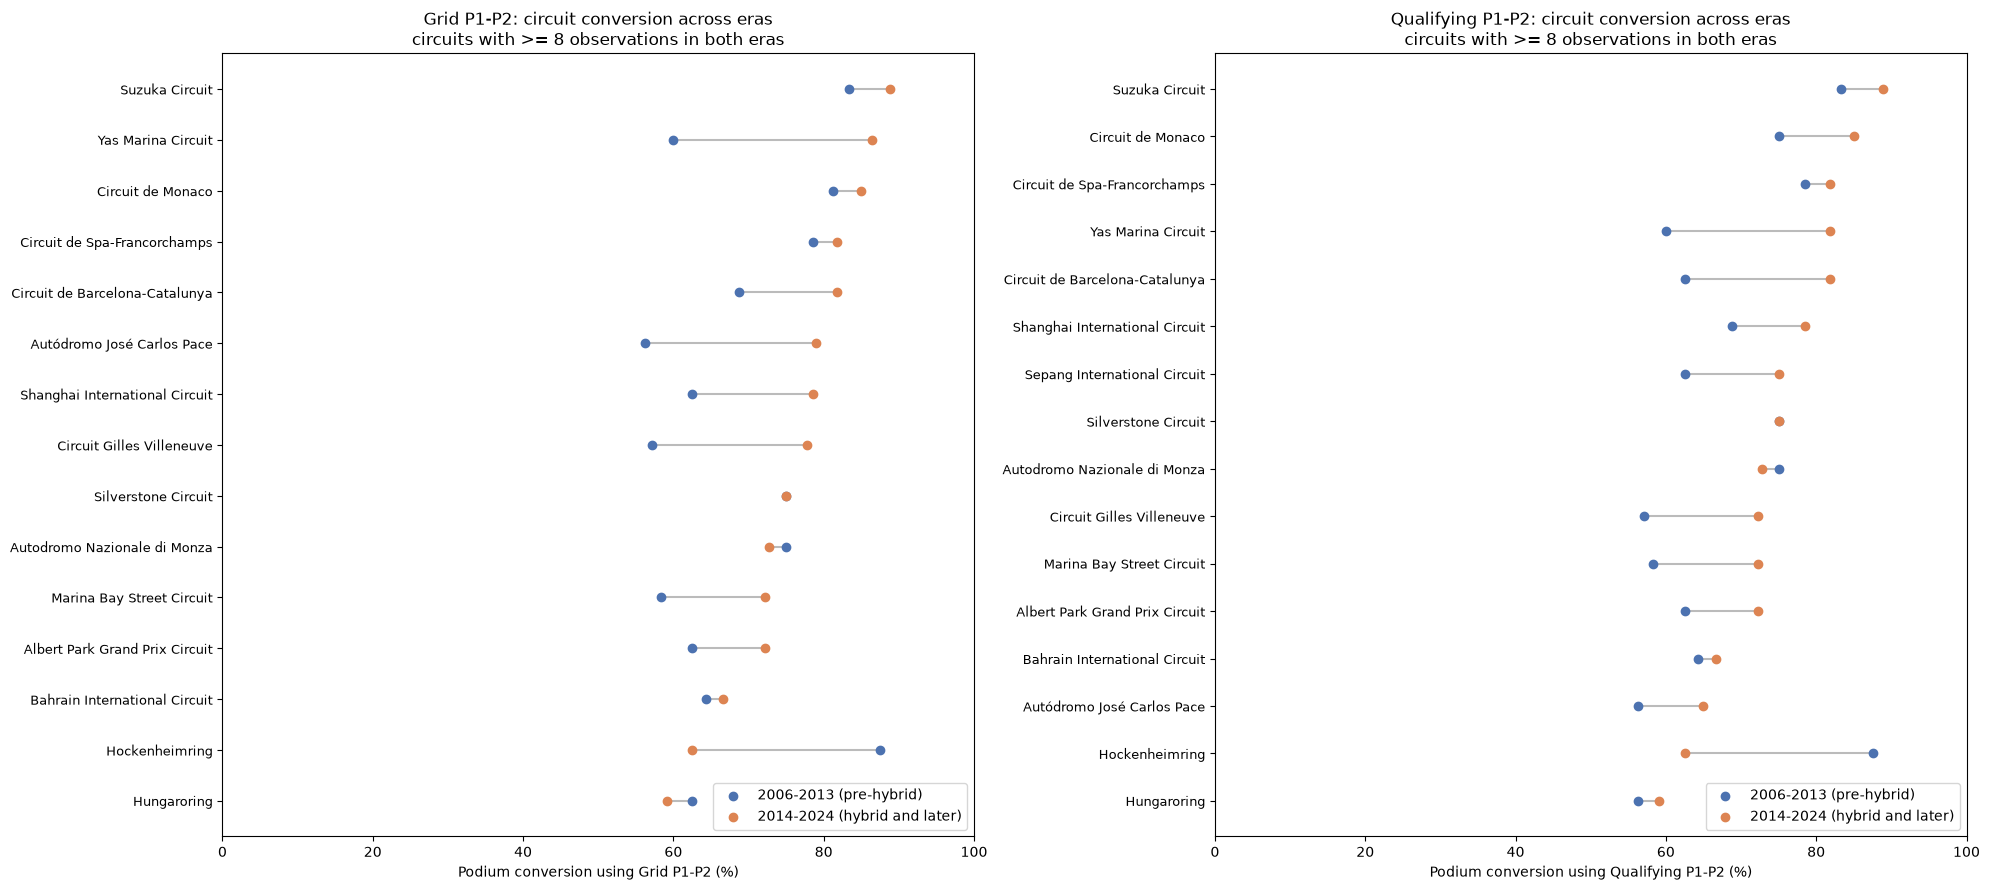

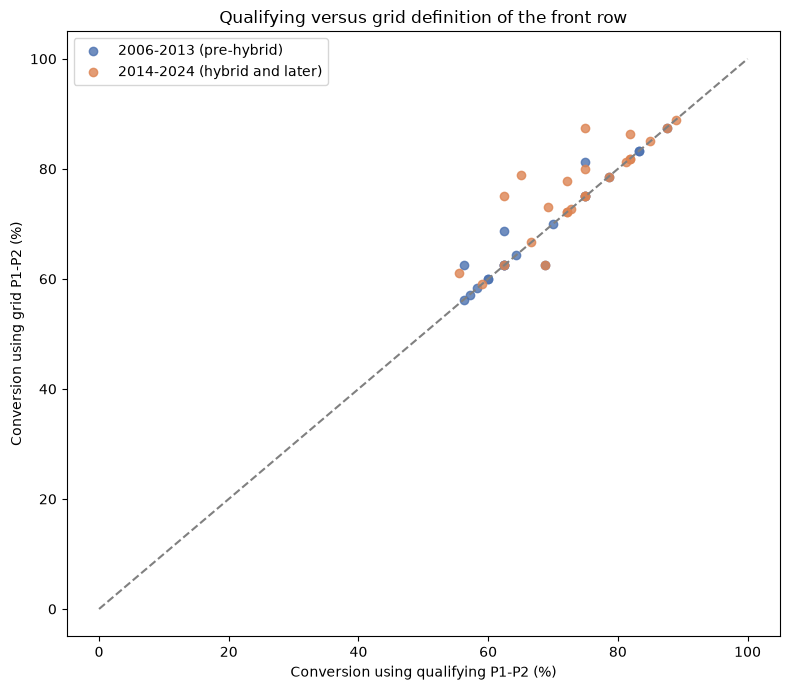

In [171]:
assert step10_validation_passed, "Run step 10 first."
from scipy import stats

step11_sources_before = step7_source_fingerprints()

def wilson_interval(successes, trials, z=1.96):
    """95% Wilson score interval for a proportion (stable for small samples)."""
    successes = np.asarray(successes, dtype=float)
    trials = np.asarray(trials, dtype=float)
    p = successes / trials
    centre = (p + z**2 / (2 * trials)) / (1 + z**2 / trials)
    half = z * np.sqrt(p * (1 - p) / trials + z**2 / (4 * trials**2)) / (1 + z**2 / trials)
    return centre - half, centre + half

# Engineering question 1 base: unique driver-race entrants -> races (year, circuit) -> circuits (name)
#          -> qualifying (session classification). Multi-hop, one row per (raceId, driverId).
EQ1_ERAS = {"2006-2013 (pre-hybrid)": (2006, 2013), "2014-2024 (hybrid and later)": (2014, 2024)}
EQ1_MIN_FRONT_ROW_STARTS = 8

eq1_base = (
    unique_driver_race_candidates[[*DRIVER_RACE_KEY, "grid", "podium"]]
    .merge(clean_data["races"][["raceId", "year", "circuitId"]], on="raceId", how="left",
           validate="many_to_one")
    .merge(clean_data["circuits"][["circuitId", "name"]].rename(columns={"name": "circuit"}),
           on="circuitId", how="left", validate="many_to_one")
    .merge(clean_data["qualifying"][[*DRIVER_RACE_KEY, "position"]].rename(
        columns={"position": "quali_position"}), on=DRIVER_RACE_KEY, how="left", validate="one_to_one")
)
eq1_base["era"] = pd.Series(pd.NA, index=eq1_base.index, dtype="string")
for era_name, (first_year, last_year) in EQ1_ERAS.items():
    eq1_base.loc[eq1_base["year"].between(first_year, last_year), "era"] = era_name
eq1_base = eq1_base.loc[eq1_base["era"].notna()].reset_index(drop=True)
eq1_base["front_row_quali"] = eq1_base["quali_position"].isin([1, 2])
eq1_base["front_row_grid"] = eq1_base["grid"].isin([1, 2])

eq1_missingness = pd.DataFrame([
    {"Item": "Driver-race rows in engineering-question-1 eras", "Rows": len(eq1_base)},
    {"Item": "No qualifying record", "Rows": int(eq1_base["quali_position"].isna().sum())},
    {"Item": "Missing grid", "Rows": int(eq1_base["grid"].isna().sum())},
    {"Item": "Races with != 2 front-row qualifiers",
     "Rows": int(eq1_base.groupby("raceId")["front_row_quali"].sum().ne(2).sum())},
    {"Item": "Races with != 2 front-row grid slots",
     "Rows": int(eq1_base.groupby("raceId")["front_row_grid"].sum().ne(2).sum())},
    {"Item": "Qualified front row but did not start from it",
     "Rows": int((eq1_base["front_row_quali"] & ~eq1_base["front_row_grid"]).sum())},
    {"Item": "Started from front row without qualifying there",
     "Rows": int((~eq1_base["front_row_quali"] & eq1_base["front_row_grid"]).sum())},
])

def front_row_conversion(frame, flag, definition):
    rows = (frame.loc[frame[flag]].groupby(["circuitId", "circuit", "era"], observed=True)
            .agg(front_row_starts=("podium", "size"), podiums=("podium", "sum")).reset_index())
    rows[["front_row_starts", "podiums"]] = rows[["front_row_starts", "podiums"]].astype(int)
    rows["conversion"] = rows["podiums"] / rows["front_row_starts"]
    rows["ci_low"], rows["ci_high"] = wilson_interval(rows["podiums"], rows["front_row_starts"])
    rows["definition"] = definition
    rows["eligible"] = rows["front_row_starts"].ge(EQ1_MIN_FRONT_ROW_STARTS)
    rows["rank_in_era"] = (rows.loc[rows["eligible"]].groupby("era")["conversion"]
                           .rank(ascending=False, method="min"))
    return rows

eq1_conversion = pd.concat([
    front_row_conversion(eq1_base, "front_row_grid", "Grid P1-P2"),
    front_row_conversion(eq1_base, "front_row_quali", "Qualifying P1-P2"),
], ignore_index=True)

era_pre, era_post = list(EQ1_ERAS)
eq1_rank_change = []
eq1_overall = []
for definition, block in eq1_conversion.groupby("definition", sort=False):
    wide = block.loc[block["eligible"]].pivot(index="circuit", columns="era",
                                             values=["conversion", "front_row_starts", "rank_in_era"])
    both = wide.dropna()
    rho, p_value = stats.spearmanr(both[("conversion", era_pre)], both[("conversion", era_post)])
    eq1_rank_change.append({"Definition": definition, "Circuits eligible in both eras": len(both),
                           "Spearman rho (pre vs post)": rho, "p-value": p_value})
    flag = "front_row_quali" if definition.startswith("Qualifying") else "front_row_grid"
    for era_name in EQ1_ERAS:
        sel = eq1_base.loc[eq1_base[flag] & eq1_base["era"].eq(era_name), "podium"]
        eq1_overall.append({"Definition": definition, "Era": era_name, "Front-row starts": len(sel),
                           "Podium conversion (%)": 100 * sel.mean()})
eq1_rank_change = pd.DataFrame(eq1_rank_change)
eq1_overall = pd.DataFrame(eq1_overall)

# Keep both definitions explicit: grid answers actual starts; qualifying is a comparison.
EQ1_DEFINITIONS = {"Grid P1-P2": "front_row_grid", "Qualifying P1-P2": "front_row_quali"}
eq1_top_tables = {}
eq1_both_wide = {}
for definition, flag in EQ1_DEFINITIONS.items():
    eligible = eq1_conversion.loc[
        eq1_conversion["definition"].eq(definition) & eq1_conversion["eligible"]
    ]
    for era_name in EQ1_ERAS:
        eq1_top_tables[(definition, era_name)] = (
            eligible.loc[eligible["era"].eq(era_name)]
            .sort_values(["conversion", "front_row_starts", "circuit"], ascending=[False, False, True])
            .head(10)[["circuit", "front_row_starts", "podiums", "conversion", "ci_low", "ci_high", "rank_in_era"]]
            .reset_index(drop=True)
        )
    both = eligible.pivot(index="circuit", columns="era", values="conversion").dropna()
    both["change_pp"] = 100 * (both[era_post] - both[era_pre])
    eq1_both_wide[definition] = both

# Check both definitions against their actual qualifying/grid row filters.
assert set(eq1_top_tables) == {(definition, era) for definition in EQ1_DEFINITIONS for era in EQ1_ERAS}
for definition, flag in EQ1_DEFINITIONS.items():
    block = eq1_conversion.loc[eq1_conversion["definition"].eq(definition)]
    assert block["front_row_starts"].sum() == int(eq1_base[flag].sum())
    assert block["podiums"].sum() == int(eq1_base.loc[eq1_base[flag], "podium"].sum())
    np.testing.assert_allclose(block["conversion"], block["podiums"] / block["front_row_starts"])
    for era_name in EQ1_ERAS:
        table = eq1_top_tables[(definition, era_name)]
        assert table["front_row_starts"].ge(EQ1_MIN_FRONT_ROW_STARTS).all()
        assert table["conversion"].is_monotonic_decreasing

with pd.option_context("display.max_columns", None, "display.width", 200, "display.precision", 3):
    print("Engineering question 1: missingness and grid/qualifying differences (driver-race rows, 2006-2024)")
    display(eq1_missingness)
    print("Overall front-row podium conversion (grid first; qualifying comparison second)")
    display(eq1_overall)
    for (definition, era_name), table in eq1_top_tables.items():
        print(f"Top 10 circuits by {definition} podium conversion, {era_name} "
              f"(min {EQ1_MIN_FRONT_ROW_STARTS} observations)")
        display(table)
    print("Circuit ranking stability across eras, separately for grid and qualifying")
    display(eq1_rank_change)
    for definition, both in eq1_both_wide.items():
        ordered = both.sort_values("change_pp")
        print(f"Largest decreases and increases ({definition}, percentage points)")
        display(pd.concat([ordered.head(3), ordered.tail(3)]).drop_duplicates())

fig, axes = plt.subplots(1, 2, figsize=(20, 9))
for ax, (definition, both) in zip(axes, eq1_both_wide.items()):
    order = both.sort_values(era_post).index
    y = np.arange(len(order))
    ax.hlines(y, both.loc[order, era_pre] * 100, both.loc[order, era_post] * 100, color="#bbbbbb")
    ax.scatter(both.loc[order, era_pre] * 100, y, color="#4c72b0", label=era_pre, zorder=3)
    ax.scatter(both.loc[order, era_post] * 100, y, color="#dd8452", label=era_post, zorder=3)
    ax.set_yticks(y, order, fontsize=9)
    ax.set_xlim(0, 100)
    ax.set_xlabel(f"Podium conversion using {definition} (%)")
    ax.set_title(f"{definition}: circuit conversion across eras\n"
                 f"circuits with >= {EQ1_MIN_FRONT_ROW_STARTS} observations in both eras")
    ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(8, 7))
compare = eq1_conversion.loc[eq1_conversion["eligible"]].pivot_table(
    index=["circuit", "era"], columns="definition", values="conversion").dropna()
for era_name, colour in zip(EQ1_ERAS, ["#4c72b0", "#dd8452"]):
    part = compare.xs(era_name, level="era")
    ax.scatter(part["Qualifying P1-P2"] * 100, part["Grid P1-P2"] * 100, color=colour,
               label=era_name, alpha=0.8)
ax.plot([0, 100], [0, 100], ls="--", color="grey")
ax.set_xlabel("Conversion using qualifying P1-P2 (%)")
ax.set_ylabel("Conversion using grid P1-P2 (%)")
ax.set_title("Qualifying versus grid definition of the front row")
ax.legend()
plt.tight_layout()
plt.show()


**Answer (engineering question 1).**

The main answer uses **starting-grid P1-P2**. **Qualifying P1-P2** is reported separately because session position can differ from the actual start. The agreed eras remain **2006-2013** and **2014-2024**; rankings require at least eight observations per circuit-era for the relevant definition.

**Starting grid (main answer).** Overall podium conversion is 69.7% from 294 observations in 2006-2013 and 76.0% from 454 in 2014-2024.

- **Leading circuits, 2006-2013:** Hockenheimring (7/8, 87.5%); Istanbul Park (10/12, 83.3%); Suzuka Circuit (10/12, 83.3%).
- **Leading circuits, 2014-2024:** Suzuka Circuit (16/18, 88.9%); Circuit Park Zandvoort (7/8, 87.5%); Jeddah Corniche Circuit (7/8, 87.5%); Yas Marina Circuit (19/22, 86.4%); Circuit de Monaco (17/20, 85.0%).

- **Ranking stability:** among 15 circuits eligible in both eras, Spearman correlation is 0.12 (p = 0.67).
- **Largest conversion decreases:** Hockenheimring (-25.0 percentage points); Hungaroring (-3.4 percentage points); Autodromo Nazionale di Monza (-2.3 percentage points).
- **Largest conversion increases:** Yas Marina Circuit (+26.4 percentage points); Autódromo José Carlos Pace (+22.7 percentage points); Circuit Gilles Villeneuve (+20.6 percentage points).

**Qualifying (comparison).** Overall podium conversion is 69.0% from 294 observations in 2006-2013 and 73.7% from 456 in 2014-2024.

- **Leading circuits, 2006-2013:** Hockenheimring (7/8, 87.5%); Istanbul Park (10/12, 83.3%); Suzuka Circuit (10/12, 83.3%).
- **Leading circuits, 2014-2024:** Suzuka Circuit (16/18, 88.9%); Circuit Park Zandvoort (7/8, 87.5%); Circuit de Monaco (17/20, 85.0%); Circuit de Barcelona-Catalunya (18/22, 81.8%); Circuit de Spa-Francorchamps (18/22, 81.8%); Yas Marina Circuit (18/22, 81.8%).

- **Ranking stability:** among 16 circuits eligible in both eras, Spearman correlation is 0.44 (p = 0.09).
- **Largest conversion decreases:** Hockenheimring (-25.0 percentage points); Autodromo Nazionale di Monza (-2.3 percentage points).
- **Largest conversion increases:** Yas Marina Circuit (+21.8 percentage points); Circuit de Barcelona-Catalunya (+19.3 percentage points); Circuit Gilles Villeneuve (+15.1 percentage points).

**Why show both?** 35 front-row qualifiers did not start on the front row; 33 drivers started there without qualifying there. For example, the grid ranking includes Jeddah among the post-2014 leaders, and Yas Marina converts 19/22 grid front-row starts versus 18/22 front-row qualifiers. The separate era-change panels and grid-versus-qualifying scatter plot show both comparisons.

**Interpretation and uncertainty.** The observed circuit rankings differ between eras under both definitions. The small circuit-era samples and wide Wilson intervals make individual ranks uncertain; the correlations and p-values describe rank association, not a formal test of whether the rankings changed. The descriptive conversion increases do not establish a causal effect of the regulation change.


### Engineering question 2: home-country podium advantage, controlling for starting position

**Question.** Do drivers podium more often at circuits in their home country, comparing drivers who started from similar grid positions?

**Joins.**
- `unique_driver_race_candidates` -> `home_country_audit` from step 8.
- `home_country_audit` already combines `drivers.nationality` -> nationality-country mapping and `races` -> `circuits.country` -> circuit-country mapping.

**Grain.** One row per `(raceId, driverId)`, all seasons.

**Missingness and scope.**
- 18 rows with unresolved home status (Rhodesian label) are excluded, never treated as away.
- 60 rows with a missing grid (unresolved historical attribution) are excluded.
- 1,635 grid-0 rows are excluded: they have no ranked starting slot to control for, and most are historical non-starters.
- Dual nationalities count either country as home (step 8 convention).

**Control.** Podium rates are compared within grid bands (P1, P2-3, P4-6, P7-10, P11+) and pooled with a **Mantel-Haenszel odds ratio** with a CMH test. Two sensitivity checks stratify by exact grid slot, and by exact grid x decade, the second to absorb era changes in field size and reliability. The modeling-window subset (2006-2024) is reported too.

**Cutoff.** Grid and home status are known before the race; the podium is the outcome.

Engineering question 2: scope and exclusions


,Stage,Rows
0,Unique driver-race entrants (all seasons),26287
1,Excluded: home status unresolved (Rhodesian la...,18
2,Excluded: grid missing (unresolved attribution),60
3,Excluded: grid 0 (no ranked starting slot),1635
4,"Analysed rows (ranked grid slot, resolved home...",24578


Home drivers do start from different grid slots (this is why we control for grid)


,count,mean,50%
is_home,,,
False,22647.0,11.713,11.0
True,1931.0,12.748,13.0


Podium rate by grid band, home versus away (all seasons)


,Away rows,Home rows,Away podium %,Home podium %,Home - away (pp)
grid_band,,,,,
P1,1025.0,80.0,64.976,61.250,-3.726
P2-3,2074.0,145.0,50.964,54.483,3.518
P4-6,3100.0,224.0,26.032,26.786,0.753
P7-10,4108.0,336.0,9.226,7.143,-2.083
P11+,12340.0,1146.0,1.653,1.047,-0.606


Pooled home effect after controlling for starting position (Mantel-Haenszel)


,0,1
Sample,All seasons (1950-2024),Modeling window (2006-2024)
Rows,24578,7828
Home rows,1931,297
Home podium %,11.6,14.815
Away podium %,13.746,14.354
Crude OR (no control),0.823,1.038
MH odds ratio | grid bands,0.931,0.872
CI low | grid bands,0.783,0.566
CI high | grid bands,1.107,1.345
CMH chi2 | grid bands,0.574,0.269


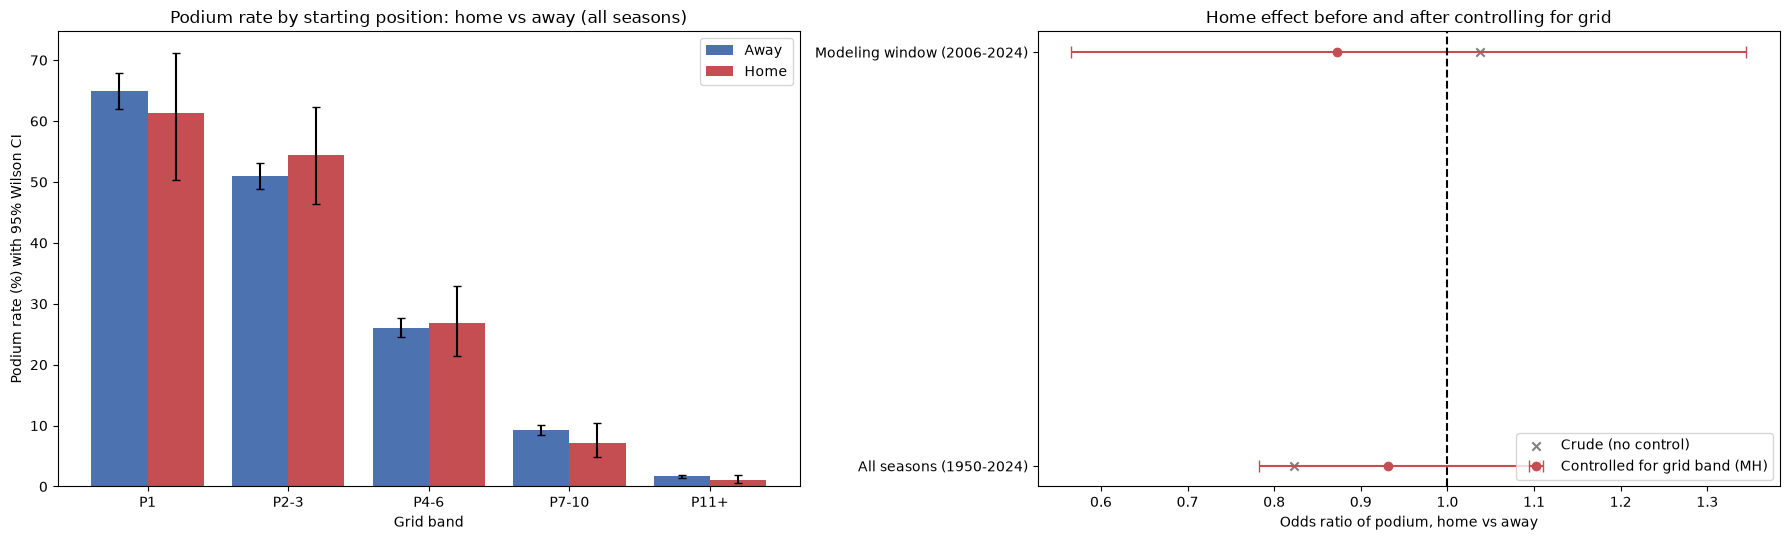

In [172]:
# Engineering question 2 base: unique driver-race entrants -> drivers (nationality -> home countries, step 8 mapping)
#          -> races -> circuits (country). One row per (raceId, driverId), all seasons.
EQ2_GRID_BANDS = [(1, 1, "P1"), (2, 3, "P2-3"), (4, 6, "P4-6"), (7, 10, "P7-10"), (11, 99, "P11+")]

eq2_all = unique_driver_race_candidates[[*DRIVER_RACE_KEY, "grid", "podium"]].merge(
    home_country_audit[[*DRIVER_RACE_KEY, "year", "nationality", "circuit_country", "is_home"]],
    on=DRIVER_RACE_KEY, how="left", validate="one_to_one"
)
eq2_scope = pd.DataFrame([
    {"Stage": "Unique driver-race entrants (all seasons)", "Rows": len(eq2_all)},
    {"Stage": "Excluded: home status unresolved (Rhodesian label)", "Rows": int(eq2_all["is_home"].isna().sum())},
    {"Stage": "Excluded: grid missing (unresolved attribution)", "Rows": int(eq2_all["grid"].isna().sum())},
    {"Stage": "Excluded: grid 0 (no ranked starting slot)",
     "Rows": int(eq2_all["grid"].eq(0).fillna(False).sum())},
])
eq2_base = eq2_all.loc[eq2_all["is_home"].notna() & eq2_all["grid"].gt(0).fillna(False)].copy()
eq2_scope.loc[len(eq2_scope)] = {"Stage": "Analysed rows (ranked grid slot, resolved home status)",
                               "Rows": len(eq2_base)}
eq2_base["is_home"] = eq2_base["is_home"].astype(bool)
eq2_base["podium"] = eq2_base["podium"].astype(int)
eq2_base["grid_band"] = pd.cut(eq2_base["grid"].astype(int),
                              bins=[b[0] - 0.5 for b in EQ2_GRID_BANDS] + [999],
                              labels=[b[2] for b in EQ2_GRID_BANDS])

def mantel_haenszel(frame, stratum):
    """Pooled odds ratio of podium for home vs away across strata, with RGB 95% CI and CMH test."""
    num = den = p_r = p_s_q_r = q_s = 0.0
    cmh_num = cmh_var = 0.0
    for _, g in frame.groupby(stratum, observed=True):
        a = int((g["is_home"] & g["podium"].eq(1)).sum()); b = int((g["is_home"] & g["podium"].eq(0)).sum())
        c = int((~g["is_home"] & g["podium"].eq(1)).sum()); d = int((~g["is_home"] & g["podium"].eq(0)).sum())
        n = a + b + c + d
        if n < 2 or (a + b) == 0 or (c + d) == 0:
            continue
        r, s = a * d / n, b * c / n
        p, q = (a + d) / n, (b + c) / n
        num += r; den += s
        p_r += p * r; p_s_q_r += p * s + q * r; q_s += q * s
        cmh_num += a - (a + b) * (a + c) / n
        cmh_var += (a + b) * (c + d) * (a + c) * (b + d) / (n**2 * (n - 1))
    odds_ratio = num / den
    se = np.sqrt(p_r / (2 * num**2) + p_s_q_r / (2 * num * den) + q_s / (2 * den**2))
    chi2 = (abs(cmh_num) - 0.5) ** 2 / cmh_var
    return {"MH odds ratio": odds_ratio, "CI low": odds_ratio * np.exp(-1.96 * se),
            "CI high": odds_ratio * np.exp(1.96 * se), "CMH chi2": chi2,
            "p-value": stats.chi2.sf(chi2, df=1)}

def crude_odds_ratio(frame):
    a = (frame["is_home"] & frame["podium"].eq(1)).sum(); b = (frame["is_home"] & frame["podium"].eq(0)).sum()
    c = (~frame["is_home"] & frame["podium"].eq(1)).sum(); d = (~frame["is_home"] & frame["podium"].eq(0)).sum()
    return a * d / (b * c)

eq2_by_band = (eq2_base.groupby(["grid_band", "is_home"], observed=True)["podium"]
              .agg(rows="size", podiums="sum").reset_index())
eq2_by_band["podium_pct"] = 100 * eq2_by_band["podiums"] / eq2_by_band["rows"]
eq2_by_band["ci_low"], eq2_by_band["ci_high"] = [100 * x for x in
                                                wilson_interval(eq2_by_band["podiums"], eq2_by_band["rows"])]
eq2_band_wide = eq2_by_band.pivot(index="grid_band", columns="is_home", values=["rows", "podium_pct"])
eq2_band_wide.columns = ["Away rows", "Home rows", "Away podium %", "Home podium %"]
eq2_band_wide["Home - away (pp)"] = eq2_band_wide["Home podium %"] - eq2_band_wide["Away podium %"]

eq2_results = []
for label, frame in [("All seasons (1950-2024)", eq2_base),
                     ("Modeling window (2006-2024)", eq2_base.loc[eq2_base["year"].between(2006, 2024)])]:
    eq2_results.append({
        "Sample": label, "Rows": len(frame), "Home rows": int(frame["is_home"].sum()),
        "Home podium %": 100 * frame.loc[frame["is_home"], "podium"].mean(),
        "Away podium %": 100 * frame.loc[~frame["is_home"], "podium"].mean(),
        "Crude OR (no control)": crude_odds_ratio(frame),
        **{f"{k} | grid bands": v for k, v in mantel_haenszel(frame, "grid_band").items()},
        "MH OR | exact grid": mantel_haenszel(frame, "grid")["MH odds ratio"],
        "MH OR | exact grid + decade": mantel_haenszel(
            frame.assign(stratum=frame["grid"].astype(str) + "_" + (frame["year"] // 10).astype(str)),
            "stratum")["MH odds ratio"],
    })
eq2_results = pd.DataFrame(eq2_results)
eq2_grid_by_home = eq2_base.groupby("is_home")["grid"].describe()[["count", "mean", "50%"]]

with pd.option_context("display.max_columns", None, "display.width", 220, "display.precision", 3):
    print("Engineering question 2: scope and exclusions")
    display(eq2_scope)
    print("Home drivers do start from different grid slots (this is why we control for grid)")
    display(eq2_grid_by_home)
    print("Podium rate by grid band, home versus away (all seasons)")
    display(eq2_band_wide)
    print("Pooled home effect after controlling for starting position (Mantel-Haenszel)")
    display(eq2_results.T)

fig, axes = plt.subplots(1, 2, figsize=(18, 5.5))
bands = [b[2] for b in EQ2_GRID_BANDS]
x = np.arange(len(bands))
for offset, (home_flag, colour, label) in zip([-0.2, 0.2], [(False, "#4c72b0", "Away"), (True, "#c44e52", "Home")]):
    part = eq2_by_band.loc[eq2_by_band["is_home"].eq(home_flag)].set_index("grid_band").reindex(bands)
    axes[0].bar(x + offset, part["podium_pct"], width=0.4, color=colour, label=label,
                yerr=[part["podium_pct"] - part["ci_low"], part["ci_high"] - part["podium_pct"]], capsize=3)
axes[0].set_xticks(x, bands)
axes[0].set_xlabel("Grid band")
axes[0].set_ylabel("Podium rate (%) with 95% Wilson CI")
axes[0].set_title("Podium rate by starting position: home vs away (all seasons)")
axes[0].legend()
forest = eq2_results.set_index("Sample")
yy = np.arange(len(forest))
axes[1].errorbar(forest["MH odds ratio | grid bands"], yy,
                 xerr=[forest["MH odds ratio | grid bands"] - forest["CI low | grid bands"],
                       forest["CI high | grid bands"] - forest["MH odds ratio | grid bands"]],
                 fmt="o", color="#c44e52", capsize=4, label="Controlled for grid band (MH)")
axes[1].scatter(forest["Crude OR (no control)"], yy, marker="x", color="grey", label="Crude (no control)")
axes[1].axvline(1, ls="--", color="black")
axes[1].set_yticks(yy, forest.index)
axes[1].set_xlabel("Odds ratio of podium, home vs away")
axes[1].set_title("Home effect before and after controlling for grid")
axes[1].legend(loc="lower right")
plt.tight_layout()
plt.show()

**Answer (engineering question 2).** **No: there is no evidence of a home podium advantage once starting position is controlled for.**

- **Raw rates.** Home drivers podium *less* often (11.6% vs 13.7%; crude odds ratio 0.82). This is because they start further back (mean grid 12.7 vs 11.7).
- **After controlling for grid band.** The pooled Mantel-Haenszel odds ratio is **0.93 (95% CI 0.78-1.11, p = 0.45)**.
- **Sensitivity checks** give the same answer:
  - exact grid slot: 0.95;
  - exact grid x decade: 0.93;
  - 2006-2024 only: 0.87 (0.57-1.35).
- **Within bands** the home-away differences are small and change sign (P2-3: +3.5 pp; P1: -3.7 pp), all well inside the intervals.

**Limitation.** Nationality is a recorded label, mapped by project convention, not proof of residence or fan support. Home rows are only about 8% of the data, so a small effect (roughly +/-10% on the odds) cannot be ruled out.

### Engineering question 3: constructor mechanical-retirement rates, 2014-2021 vs 2022-2024

**Question.** Which constructors have the highest mechanical-retirement rate in each regulation period?

**Joins.** `results` (car-level row with `statusId`, `positionText`) -> `status` -> step 8 `mechanical_status_mapping` -> `races` (year) -> `constructors` (name).

**Grain.** **One race start of one car.**
- In 2014-2024 every driver-race has exactly one result row, which the code asserts, so the constructor attribution is the recorded one.
- **Denominator = race starts.** Excluded as non-starts: *Did not qualify / prequalify*, *107% Rule*, *Withdrew*, and `positionText = W`. W rows include 17 cars that failed *before* the start; they never started, so they cannot retire from the race.

**Numerator.** Starts whose status the step 8 taxonomy classes as `mechanical` (a car component or system failed). Crash/contact, driver-health, regulatory/disqualification and finished/lapped statuses are excluded, as the brief requires.

**Uncertain causes.** The taxonomy marks some statuses `uncertain` (generic *Retired*, *Power loss*, wheel, tyre, puncture, wing damage). The table shows a **strict rate** (uncertain = not mechanical) and an **upper bound** (uncertain = mechanical).

**Minimum sample.** At least 30 starts per constructor-era.

**Identity.** Constructors are identified by `constructorId`. Rebrands such as Toro Rosso -> AlphaTauri -> RB, or Force India -> Racing Point -> Aston Martin, are separate rows.

**Cutoff.** This is a historical, post-race summary; status never enters the predictive features.

Engineering question 3 denominator: race starts per era


,Result rows,Non-starter status,Withdrawn before start (W),Race starts (denominator),Mechanical retirements,Uncertain cause (sensitivity)
era,,,,,,
2014-2021,3267,9,14,3244,276,82
2022-2024,1359,5,3,1351,71,21


Overall mechanical-retirement rate per start (strict = taxonomy 'mechanical'; upper = also counts 'uncertain')


,starts,rate_strict,rate_upper
era,,,
2014-2021,3244,0.085,0.110
2022-2024,1351,0.053,0.068


Constructors by mechanical-retirement rate, 2014-2021 (min 30 starts)


,constructor,seasons,starts,mech_strict,rate_strict,ci_low,ci_high,rate_upper,rank_strict
0,Caterham,2014-2014,33,7,0.212,0.107,0.378,0.303,1.0
1,Lotus F1,2014-2015,75,12,0.16,0.094,0.259,0.24,2.0
2,Toro Rosso,2014-2019,242,38,0.157,0.117,0.208,0.182,3.0
3,Renault,2016-2020,199,25,0.126,0.087,0.179,0.161,4.0
4,McLaren,2014-2021,315,37,0.117,0.086,0.158,0.152,5.0
5,Red Bull,2014-2021,318,33,0.104,0.075,0.142,0.116,6.0
6,Sauber,2014-2018,199,20,0.101,0.066,0.150,0.131,7.0
7,Marussia,2014-2014,31,3,0.097,0.033,0.249,0.097,8.0
8,AlphaTauri,2020-2021,77,7,0.091,0.045,0.176,0.104,9.0
9,Racing Point,2019-2020,75,6,0.08,0.037,0.164,0.093,10.0


Constructors by mechanical-retirement rate, 2022-2024 (min 30 starts)


,constructor,seasons,starts,mech_strict,rate_strict,ci_low,ci_high,rate_upper,rank_strict
0,Alfa Romeo,2022-2023,88,10,0.114,0.063,0.197,0.125,1.0
1,Alpine F1 Team,2022-2024,135,14,0.104,0.063,0.167,0.104,2.0
2,AlphaTauri,2022-2023,88,6,0.068,0.032,0.141,0.08,3.0
3,Williams,2022-2024,134,7,0.052,0.026,0.104,0.082,4.0
4,Ferrari,2022-2024,134,6,0.045,0.021,0.094,0.067,5.0
5,Mercedes,2022-2024,136,6,0.044,0.020,0.093,0.044,6.0
6,RB F1 Team,2024-2024,48,2,0.042,0.012,0.140,0.104,7.0
7,Haas F1 Team,2022-2024,135,5,0.037,0.016,0.084,0.052,8.0
8,Red Bull,2022-2024,136,5,0.037,0.016,0.083,0.044,9.0
9,McLaren,2022-2024,136,5,0.037,0.016,0.083,0.037,9.0


Uncertain statuses among starts (counted only in the upper bound)


,status,Starts
0,Retired,49
1,Power loss,12
2,Wheel,11
3,Puncture,7
4,Tyre,4
5,Undertray,4
6,Wheel nut,3
7,Rear wing,3
8,Front wing,3
9,Damage,2


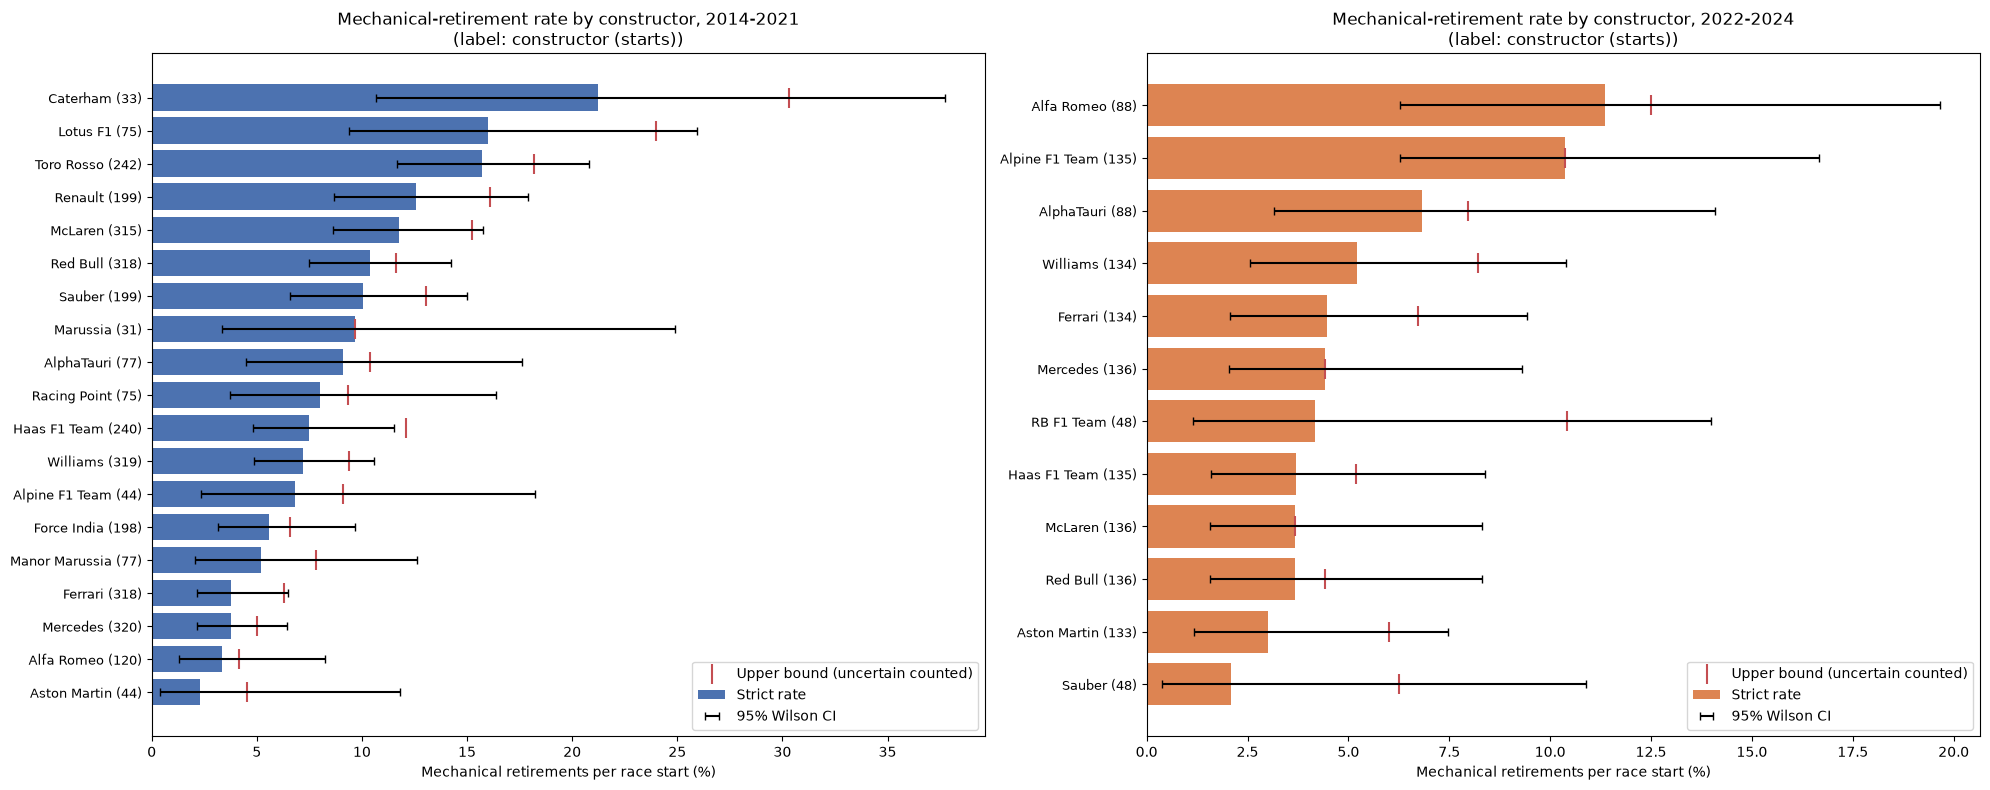

,Check,Passed
0,EQ1 grain is unique driver-race,True
1,EQ1 every race has exactly two qualifying fron...,True
2,EQ1 circuit counts reconcile with front-row to...,True
3,EQ2 grain is unique driver-race and home statu...,True
4,EQ2 scope reconciles,True
5,EQ3 one start per car (driver-race),True
6,EQ3 starts + non-starts = result rows,True
7,EQ3 strict numerator <= upper bound <= starts,True
8,Sources unchanged,True


In [173]:
# Engineering question 3 base: results (car-level row, status) -> status -> step-8 mechanical taxonomy
#          -> races (year) -> constructors (name). Grain: one race start of one car.
EQ3_ERAS = {"2014-2021": (2014, 2021), "2022-2024": (2022, 2024)}
EQ3_MIN_STARTS = 30
EQ3_NOT_A_START_STATUSES = ["Did not qualify", "Did not prequalify", "107% Rule", "Withdrew"]

eq3_rows = (
    modeling_population_candidates[["resultId", *DRIVER_RACE_KEY, "constructorId", "grid",
                                    "positionText", "laps", "statusId"]]
    .merge(clean_data["races"][["raceId", "year"]], on="raceId", how="left", validate="many_to_one")
)
eq3_rows = eq3_rows.loc[eq3_rows["year"].between(2014, 2024)].merge(
    mechanical_status_mapping[["statusId", "status", "mechanical_class", "is_mechanical"]],
    on="statusId", how="left", validate="many_to_one"
).merge(clean_data["constructors"][["constructorId", "name"]].rename(columns={"name": "constructor"}),
        on="constructorId", how="left", validate="many_to_one")
assert not eq3_rows.duplicated(DRIVER_RACE_KEY).any(), "Engineering question 3: expects one car per driver-race in 2014-2024."
eq3_rows["era"] = np.where(eq3_rows["year"].le(2021), "2014-2021", "2022-2024")

# A race start excludes recorded non-starters and positionText W (car withdrawn before the start,
# including cars that failed on the way to the grid: these never started, so they cannot retire).
eq3_rows["not_a_start_reason"] = np.select(
    [eq3_rows["status"].isin(EQ3_NOT_A_START_STATUSES), eq3_rows["positionText"].eq("W").fillna(False)],
    ["Non-starter status", "Withdrawn before start (W)"], default="")
eq3_starts = eq3_rows.loc[eq3_rows["not_a_start_reason"].eq("")].copy()
eq3_starts["mech_strict"] = eq3_starts["mechanical_class"].eq("mechanical")
eq3_starts["mech_upper"] = eq3_starts["mechanical_class"].isin(["mechanical", "uncertain"])

eq3_scope = pd.concat([
    eq3_rows.groupby("era").size().rename("Result rows"),
    eq3_rows.loc[eq3_rows["not_a_start_reason"].ne("")].groupby(["era", "not_a_start_reason"]).size()
    .unstack(fill_value=0),
    eq3_starts.groupby("era").size().rename("Race starts (denominator)"),
    eq3_starts.groupby("era")["mech_strict"].sum().rename("Mechanical retirements"),
    eq3_starts.groupby("era")["mechanical_class"].apply(lambda s: s.eq("uncertain").sum())
    .rename("Uncertain cause (sensitivity)"),
], axis=1)
eq3_uncertain_labels = (eq3_starts.loc[eq3_starts["mechanical_class"].eq("uncertain")]
                       .groupby("status").size().sort_values(ascending=False).rename("Starts").reset_index())

eq3_rates = eq3_starts.groupby(["constructorId", "constructor", "era"]).agg(
    starts=("resultId", "size"), mech_strict=("mech_strict", "sum"), mech_upper=("mech_upper", "sum"),
    seasons=("year", lambda y: f"{y.min()}-{y.max()}")
).reset_index()
eq3_rates["rate_strict"] = eq3_rates["mech_strict"] / eq3_rates["starts"]
eq3_rates["rate_upper"] = eq3_rates["mech_upper"] / eq3_rates["starts"]
eq3_rates["ci_low"], eq3_rates["ci_high"] = wilson_interval(eq3_rates["mech_strict"], eq3_rates["starts"])
eq3_rates["eligible"] = eq3_rates["starts"].ge(EQ3_MIN_STARTS)
eq3_rates["rank_strict"] = (eq3_rates.loc[eq3_rates["eligible"]].groupby("era")["rate_strict"]
                           .rank(ascending=False, method="min"))
eq3_era_overall = eq3_starts.groupby("era").agg(starts=("resultId", "size"),
                                              rate_strict=("mech_strict", "mean"),
                                              rate_upper=("mech_upper", "mean"))
eq3_tables = {era: eq3_rates.loc[eq3_rates["era"].eq(era) & eq3_rates["eligible"]]
             .sort_values("rate_strict", ascending=False)
             [["constructor", "seasons", "starts", "mech_strict", "rate_strict", "ci_low", "ci_high",
               "rate_upper", "rank_strict"]].reset_index(drop=True)
             for era in EQ3_ERAS}

with pd.option_context("display.max_columns", None, "display.width", 220, "display.precision", 3):
    print("Engineering question 3 denominator: race starts per era")
    display(eq3_scope)
    print("Overall mechanical-retirement rate per start (strict = taxonomy 'mechanical'; "
          "upper = also counts 'uncertain')")
    display(eq3_era_overall)
    for era, table in eq3_tables.items():
        print(f"Constructors by mechanical-retirement rate, {era} (min {EQ3_MIN_STARTS} starts)")
        display(table)
    print("Uncertain statuses among starts (counted only in the upper bound)")
    display(eq3_uncertain_labels)

fig, axes = plt.subplots(1, 2, figsize=(20, 8))
for ax, era, colour in zip(axes, EQ3_ERAS, ["#4c72b0", "#dd8452"]):
    t = eq3_tables[era].sort_values("rate_strict")
    yy = np.arange(len(t))
    ax.barh(yy, t["rate_strict"] * 100, color=colour, label="Strict rate")
    ax.errorbar(t["rate_strict"] * 100, yy,
                xerr=[(t["rate_strict"] - t["ci_low"]) * 100, (t["ci_high"] - t["rate_strict"]) * 100],
                fmt="none", ecolor="black", capsize=3, label="95% Wilson CI")
    ax.scatter(t["rate_upper"] * 100, yy, marker="|", s=200, color="#c44e52",
               label="Upper bound (uncertain counted)")
    ax.set_yticks(yy, [f"{c} ({n})" for c, n in zip(t["constructor"], t["starts"])], fontsize=9)
    ax.set_xlabel("Mechanical retirements per race start (%)")
    ax.set_title(f"Mechanical-retirement rate by constructor, {era}\n(label: constructor (starts))")
    ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

# Step 11 validation: grain, denominators and source preservation for all three questions.
step11_checks = [
    ("EQ1 grain is unique driver-race", not eq1_base.duplicated(DRIVER_RACE_KEY).any()),
    ("EQ1 every race has exactly two qualifying front-row starters",
     eq1_base.groupby("raceId")["front_row_quali"].sum().eq(2).all()),
    ("EQ1 circuit counts reconcile with front-row totals",
     all(eq1_conversion.loc[eq1_conversion["definition"].eq(d), "front_row_starts"].sum()
         == int(eq1_base[f].sum()) for d, f in [("Qualifying P1-P2", "front_row_quali"),
                                                ("Grid P1-P2", "front_row_grid")])),
    ("EQ2 grain is unique driver-race and home status resolved",
     not eq2_base.duplicated(DRIVER_RACE_KEY).any() and eq2_base["is_home"].notna().all()),
    ("EQ2 scope reconciles", len(eq2_base) == len(eq2_all) - int((eq2_all["is_home"].isna()
                                                                   | ~eq2_all["grid"].gt(0).fillna(False)).sum())),
    ("EQ3 one start per car (driver-race)", not eq3_starts.duplicated(DRIVER_RACE_KEY).any()),
    ("EQ3 starts + non-starts = result rows",
     len(eq3_starts) + int(eq3_rows["not_a_start_reason"].ne("").sum()) == len(eq3_rows)),
    ("EQ3 strict numerator <= upper bound <= starts",
     (eq3_rates["mech_strict"] <= eq3_rates["mech_upper"]).all()
     and (eq3_rates["mech_upper"] <= eq3_rates["starts"]).all()),
    ("Sources unchanged", step7_source_fingerprints() == step11_sources_before),
]
step11_validation = pd.DataFrame(step11_checks, columns=["Check", "Passed"])
display(step11_validation)
step11_validation_passed = bool(step11_validation["Passed"].all())
assert step11_validation_passed, "Step 11 validation failed."

**Answer (engineering question 3).**

**Overall.** Reliability improved: mechanical retirements per start fell from **8.5% (2014-2021, 3,244 starts)** to **5.3% (2022-2024, 1,351 starts)**. Upper bounds: 11.0% -> 6.8%.

**2014-2021, highest rates:**
- Caterham 21.2% (33 starts, 2014 only; CI 11-38%);
- Lotus F1 16.0% (75);
- Toro Rosso 15.7% (242);
- Renault 12.6%;
- McLaren 11.7% (the 2015-2017 Honda years fall in this period).

**2014-2021, lowest rates:** Mercedes 3.7%, Ferrari 3.8%, Alfa Romeo 3.3%, Aston Martin 2.3% (44 starts).

**2022-2024, highest rates:** Alfa Romeo 11.4% (88 starts), Alpine 10.4% (135), AlphaTauri 6.8%.

**2022-2024, lowest rates:** Sauber 2.1% (48 starts, 2024), Aston Martin 3.0%, and Red Bull / McLaren / Haas at 3.7%.

**Ranking changes.** McLaren and Red Bull moved from the top half to the bottom. Alfa Romeo and Alpine moved up to the top.

**How firm the results are.**
- In 2022-2024 most constructors' intervals overlap, so only the top two stand out.
- The strict and upper-bound rankings agree on the leaders.
- RB F1 Team (2024) depends most on the uncertain statuses: 4.2% strict vs 10.4% upper bound.

## Feature engineering, selection and split (step 12)

This section takes the step-10 `modeling_table` and keeps its grid, qualifying and standings encodings unchanged. It then:
1. Builds the deferred **rolling form** features and tests the look-back window empirically.
2. Justifies every candidate feature with training-only EDA: single-feature association with podium, a focused correlation heatmap, and binned podium-rate plots for representative features.
3. Runs visible feature-set trials and applies a pre-stated selection rule.
4. Justifies the train / validation / test split.

The focused plots compare grid, qualifying pace, pre-race standings, and lagged form. The complete candidate-pair audit is retained for redundancy checks. These are associations, not causal effects; standings and form use only earlier races.

**Protocol (no test data is used).**
- Feature decisions use an **expanding-window time-series CV inside training**: fit on 2006 to year-1, score the year, for 2014-2019.
- Validation (2020-2021) is reported only as confirmation.
- Two quick, untuned models give the evidence: logistic regression (median imputation + scaling, fitted inside each fold) and histogram gradient boosting.
- **PR-AUC is the primary score** because podiums are only about 14% of rows; ROC-AUC is reported alongside.
- These are feature-selection experiments, not the final models.

**Form features.** "Rolling one-race-ahead": history may include any earlier completed race, including pre-2006 races and earlier races in the validation and test seasons, but never the current or a future race. All are computed after `shift(1)`, in season/round order.
- **Driver:** podium rate, mean finishing position, mechanical-DNF rate, and the number of races in the window. Zero races means a debut; the rates are then left missing.
- **Constructor:** the same, computed at team-race level *before* shifting, so a teammate's result in the same race can never leak in.

Candidate windows: **last 3, last 5, last 10 races, and the whole career so far.**

Rolling-form window experiment (PR-AUC is the primary score: podiums are ~14% of rows)


,Feature set,Model,Features,CV ROC-AUC,CV PR-AUC,CV PR-AUC sd,Validation ROC-AUC,Validation PR-AUC
0,No form (step-10 features),Logistic regression,17,0.9439,0.7295,0.0470,0.9308,0.7348
1,No form (step-10 features),Hist gradient boosting,17,0.9415,0.7146,0.0634,0.9173,0.6837
2,"+ form, last 3",Logistic regression,25,0.9439,0.7310,0.0468,0.9295,0.7247
3,"+ form, last 3",Hist gradient boosting,25,0.9423,0.7297,0.0533,0.9237,0.7048
4,"+ form, last 5",Logistic regression,25,0.9436,0.7191,0.0487,0.9311,0.7321
5,"+ form, last 5",Hist gradient boosting,25,0.9411,0.7095,0.0710,0.9204,0.6635
6,"+ form, last 10",Logistic regression,25,0.9437,0.7240,0.0437,0.9337,0.7319
7,"+ form, last 10",Hist gradient boosting,25,0.9493,0.7355,0.0473,0.9235,0.7011
8,"+ form, career so far",Logistic regression,25,0.9422,0.7213,0.0462,0.9326,0.7397
9,"+ form, career so far",Hist gradient boosting,25,0.9385,0.7108,0.0886,0.9222,0.6920


Paired comparison with the no-form feature set on the same six CV folds


,Feature set,Model,Mean fold gain vs no form,Folds improved (of 6)
0,"+ form, last 3",Logistic regression,0.0016,3
1,"+ form, last 3",Hist gradient boosting,0.0152,4
2,"+ form, last 5",Logistic regression,-0.0104,0
3,"+ form, last 5",Hist gradient boosting,-0.0051,2
4,"+ form, last 10",Logistic regression,-0.0055,2
5,"+ form, last 10",Hist gradient boosting,0.0210,5
6,"+ form, career so far",Logistic regression,-0.0082,1
7,"+ form, career so far",Hist gradient boosting,-0.0038,3


Mean CV PR-AUC across both models, per window


,Feature set,Mean CV PR-AUC
0,"+ form, last 3",0.7304
1,"+ form, last 10",0.7297
2,"+ form, career so far",0.7160
3,"+ form, last 5",0.7143


Chosen form window: last 3


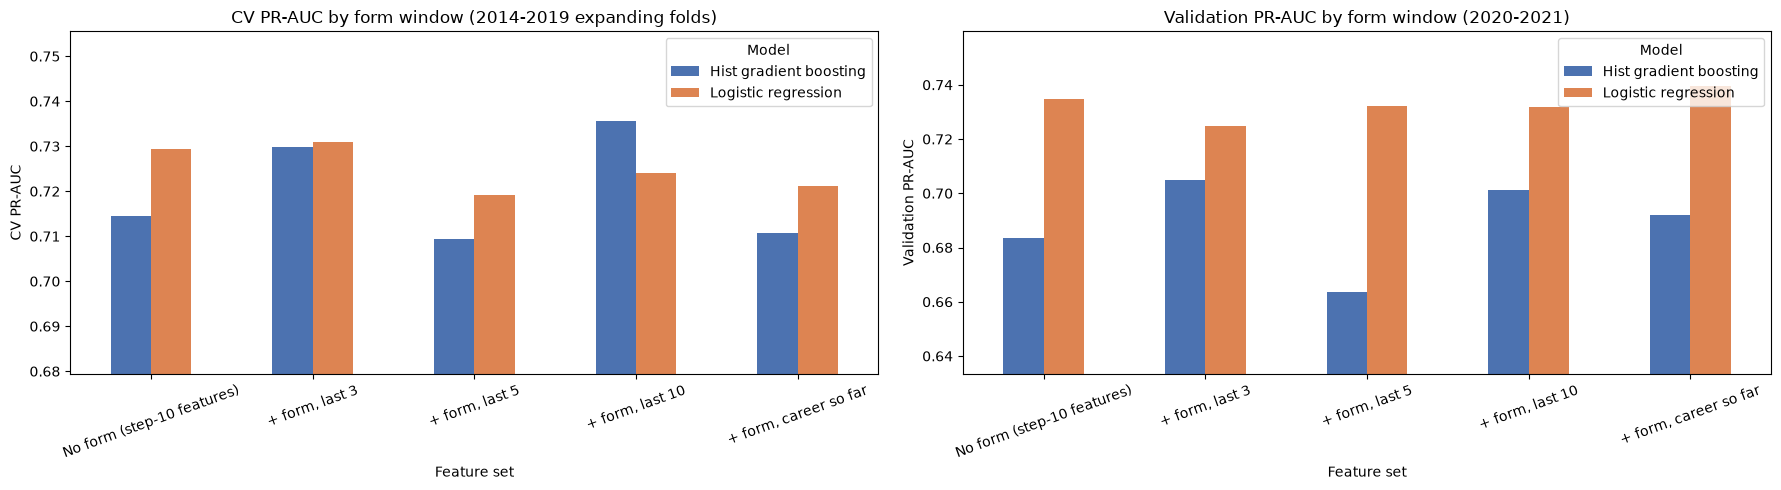

In [174]:
assert step10_validation_passed, "Run step 10 first."
from scipy import stats
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.feature_selection import mutual_info_classif
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, roc_auc_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

step12_sources_before = step7_source_fingerprints()
step12_modeling_before = step7_frame_fingerprint(modeling_table)

# History for form features: every unique entrant of every season (pre-2006 races may supply
# history), ordered by season and round from race_calendar, never by numeric raceId.
form_history = unique_driver_race_candidates[
    [*DRIVER_RACE_KEY, "constructorId", "best_positionOrder", "podium"]
].merge(race_calendar[["raceId", "year", "round"]], on="raceId", how="inner", validate="many_to_one")
driver_race_mechanical = (
    modeling_population_candidates[[*DRIVER_RACE_KEY, "statusId"]]
    .merge(mechanical_status_mapping[["statusId", "mechanical_class"]], on="statusId", how="left",
           validate="many_to_one")
    .assign(mechanical=lambda f: f["mechanical_class"].eq("mechanical").fillna(False))
    .groupby(DRIVER_RACE_KEY)["mechanical"].any().astype(int).reset_index()
)
form_history = form_history.merge(driver_race_mechanical, on=DRIVER_RACE_KEY, how="left",
                                  validate="one_to_one")
assert form_history["mechanical"].notna().all()
form_history = form_history.assign(
    finish=form_history["best_positionOrder"].astype(float),
    podium=form_history["podium"].astype(float),
    mechanical=form_history["mechanical"].astype(float),
).sort_values(["year", "round", "driverId"]).reset_index(drop=True)

def previous_events_sum(frame, group_col, value_col, window):
    """Sum of value_col over the previous `window` events of each group, excluding the current
    event (shift 1). window=None means every earlier event. frame must be in chronological order."""
    shifted = frame.groupby(group_col, sort=False)[value_col].shift(1)
    grouped = shifted.groupby(frame[group_col], sort=False)
    if window is None:
        return grouped.cumsum()
    return grouped.rolling(window, min_periods=1).sum().reset_index(level=0, drop=True)

def build_form_features(window):
    """Driver and constructor form from strictly earlier races. window=None means career so far."""
    h = form_history.assign(one=1.0)
    races = previous_events_sum(h, "driverId", "one", window)
    driver = pd.DataFrame({
        "raceId": h["raceId"], "driverId": h["driverId"],
        "driver_form_races": races.fillna(0),
        "driver_form_podium_rate": previous_events_sum(h, "driverId", "podium", window) / races,
        "driver_form_mean_finish": previous_events_sum(h, "driverId", "finish", window) / races,
        "driver_form_mech_dnf_rate": previous_events_sum(h, "driverId", "mechanical", window) / races,
    })
    # Team form: aggregate each team's race first, then shift by whole team races, so a
    # teammate's result in the same race can never enter the feature.
    team = (h.dropna(subset=["constructorId"])
            .groupby(["constructorId", "year", "round", "raceId"], as_index=False)
            .agg(entries=("podium", "size"), podiums=("podium", "sum"), finish_sum=("finish", "sum"),
                 mech=("mechanical", "sum"))
            .sort_values(["constructorId", "year", "round"]).reset_index(drop=True)
            .assign(one=1.0, entries=lambda f: f["entries"].astype(float)))
    entries = previous_events_sum(team, "constructorId", "entries", window)
    constructor = pd.DataFrame({
        "raceId": team["raceId"], "constructorId": team["constructorId"],
        "constructor_form_races": previous_events_sum(team, "constructorId", "one", window).fillna(0),
        "constructor_form_podium_rate": previous_events_sum(team, "constructorId", "podiums", window) / entries,
        "constructor_form_mean_finish": previous_events_sum(team, "constructorId", "finish_sum", window) / entries,
        "constructor_form_mech_dnf_rate": previous_events_sum(team, "constructorId", "mech", window) / entries,
    })
    out = modeling_table[[*DRIVER_RACE_KEY, "constructorId"]].merge(
        driver, on=DRIVER_RACE_KEY, how="left", validate="one_to_one"
    ).merge(constructor, on=["raceId", "constructorId"], how="left", validate="many_to_one")
    assert len(out) == len(modeling_table)
    return out.drop(columns="constructorId")

FORM_FEATURES = ["driver_form_races", "driver_form_podium_rate", "driver_form_mean_finish",
                 "driver_form_mech_dnf_rate", "constructor_form_races", "constructor_form_podium_rate",
                 "constructor_form_mean_finish", "constructor_form_mech_dnf_rate"]
FORM_WINDOW_CANDIDATES = {"last 3": 3, "last 5": 5, "last 10": 10, "career so far": None}
form_candidates = {name: build_form_features(window) for name, window in FORM_WINDOW_CANDIDATES.items()}

# Evaluation protocol for feature decisions (no test data is touched):
#  * expanding-window time-series CV inside training: fit <= year-1, score year, for 2014-2019;
#  * one fit on all training seasons scored on the validation seasons (2020-2021).
TIME_SERIES_CV_FOLDS = [(list(range(MODEL_FIRST_YEAR, year)), [year]) for year in range(2014, 2020)]
FEATURE_EXPERIMENT_MODELS = {
    "Logistic regression": lambda: make_pipeline(
        SimpleImputer(strategy="median"), StandardScaler(), LogisticRegression(max_iter=5000)),
    "Hist gradient boosting": lambda: HistGradientBoostingClassifier(
        max_iter=200, learning_rate=0.05, max_leaf_nodes=15, random_state=0),
}

def to_matrix(frame, columns):
    return frame[columns].astype("Float64").to_numpy(dtype=float, na_value=np.nan)

def evaluate_feature_set(frame, columns, label):
    """Return CV (mean over folds) and validation ROC-AUC / PR-AUC for every experiment model."""
    rows = []
    y_all = frame[MODEL_TARGET].astype(int).to_numpy()
    X_all = to_matrix(frame, columns)
    for model_name, make_model in FEATURE_EXPERIMENT_MODELS.items():
        fold_scores = []
        for train_years, score_years in TIME_SERIES_CV_FOLDS:
            tr = frame["year"].isin(train_years).to_numpy(); te = frame["year"].isin(score_years).to_numpy()
            p = make_model().fit(X_all[tr], y_all[tr]).predict_proba(X_all[te])[:, 1]
            fold_scores.append((roc_auc_score(y_all[te], p), average_precision_score(y_all[te], p)))
        tr = frame["partition"].eq("train").to_numpy(); va = frame["partition"].eq("validation").to_numpy()
        p = make_model().fit(X_all[tr], y_all[tr]).predict_proba(X_all[va])[:, 1]
        rows.append({"Feature set": label, "Model": model_name, "Features": len(columns),
                     "CV ROC-AUC": np.mean([s[0] for s in fold_scores]),
                     "CV PR-AUC": np.mean([s[1] for s in fold_scores]),
                     "CV PR-AUC sd": np.std([s[1] for s in fold_scores]),
                     "Validation ROC-AUC": roc_auc_score(y_all[va], p),
                     "Validation PR-AUC": average_precision_score(y_all[va], p),
                     "fold_pr_auc": [s[1] for s in fold_scores]})
    return rows

form_window_results = evaluate_feature_set(modeling_table, MODEL_FEATURE_COLUMNS, "No form (step-10 features)")
for name, form_frame in form_candidates.items():
    experiment_frame = modeling_table.merge(form_frame, on=DRIVER_RACE_KEY, validate="one_to_one")
    form_window_results += evaluate_feature_set(
        experiment_frame, MODEL_FEATURE_COLUMNS + FORM_FEATURES, f"+ form, {name}")
form_window_results = pd.DataFrame(form_window_results)

# Decision rule fixed before looking: the window with the best mean CV PR-AUC averaged over both
# models (training seasons only). Validation is reported as a confirmation, not used to choose.
form_window_choice = (form_window_results.loc[form_window_results["Feature set"].str.startswith("+ form")]
                      .groupby("Feature set")["CV PR-AUC"].mean().sort_values(ascending=False))
baseline_folds = form_window_results.loc[form_window_results["Feature set"].str.startswith("No form")].set_index("Model")["fold_pr_auc"]
form_window_paired = pd.DataFrame([
    {"Feature set": r["Feature set"], "Model": r["Model"],
     "Mean fold gain vs no form": np.mean(np.subtract(r["fold_pr_auc"], baseline_folds[r["Model"]])),
     "Folds improved (of 6)": int(np.sum(np.subtract(r["fold_pr_auc"], baseline_folds[r["Model"]]) > 0))}
    for _, r in form_window_results.loc[form_window_results["Feature set"].str.startswith("+ form")].iterrows()
])
FORM_WINDOW_NAME = form_window_choice.index[0].removeprefix("+ form, ")
FORM_WINDOW = FORM_WINDOW_CANDIDATES[FORM_WINDOW_NAME]
form_features = form_candidates[FORM_WINDOW_NAME]

with pd.option_context("display.precision", 4, "display.width", 200):
    print("Rolling-form window experiment (PR-AUC is the primary score: podiums are ~14% of rows)")
    display(form_window_results.drop(columns="fold_pr_auc"))
    print("Paired comparison with the no-form feature set on the same six CV folds")
    display(form_window_paired)
    print("Mean CV PR-AUC across both models, per window")
    display(form_window_choice.rename("Mean CV PR-AUC").reset_index())
    print(f"Chosen form window: {FORM_WINDOW_NAME}")

fig, axes = plt.subplots(1, 2, figsize=(18, 5))
for ax, metric in zip(axes, ["CV PR-AUC", "Validation PR-AUC"]):
    pivot = form_window_results.pivot(index="Feature set", columns="Model", values=metric)
    pivot = pivot.reindex(["No form (step-10 features)"] + [f"+ form, {n}" for n in FORM_WINDOW_CANDIDATES])
    pivot.plot.bar(ax=ax, rot=20, color=["#4c72b0", "#dd8452"])
    ax.set_ylim(pivot.min().min() - 0.03, pivot.max().max() + 0.02)
    ax.set_title(f"{metric} by form window" + (" (2014-2019 expanding folds)" if metric.startswith("CV") else
                                               " (2020-2021)"))
    ax.set_ylabel(metric)
plt.tight_layout()
plt.show()

**Form-window result.**

- **Effect is small.** Form adds only a little over grid + qualifying + standings. Mean CV PR-AUC across both models:
  - no form: 0.722;
  - last 3: 0.730;
  - last 10: 0.730;
  - career: 0.716;
  - last 5: 0.714.
- **Paired fold comparison.** The gain is consistent only for gradient boosting:
  - last 10 improves 5 of 6 folds (+0.021);
  - last 3 improves 4 of 6 (+0.015).
  - For logistic regression the gains are within noise; the CV standard deviation is about 0.05.
- **Why.** The step-10 previous-race standings already summarise most of the season-level form.
- **Choice.** Under the pre-stated rule (best mean CV PR-AUC), the chosen window is **last 3 races**; last 10 is a near-tie.
- The form family is kept because the brief requires one. The later group ablation will quantify its contribution on the final models.

Univariate evidence per candidate feature (training seasons 2006-2019 only)


,Feature,Group,Missing (%),Spearman with podium,Single-feature ROC-AUC,Mutual information,Minority share (%)
3,quali_position,qualifying,0.000,-5.034e-01,0.919,1.742e-01,NaN
0,grid_position,grid,0.000,-5.025e-01,0.918,1.802e-01,NaN
10,driver_prev_standing,standings,6.615,-4.797e-01,0.897,1.402e-01,NaN
23,constructor_form_mean_finish,form,0.590,-4.502e-01,0.874,1.193e-01,NaN
14,constructor_prev_standing,standings,5.503,-4.463e-01,0.870,1.254e-01,NaN
22,constructor_form_podium_rate,form,0.590,5.261e-01,0.867,1.268e-01,NaN
19,driver_form_mean_finish,form,1.024,-4.215e-01,0.850,1.070e-01,NaN
18,driver_form_podium_rate,form,1.024,5.152e-01,0.827,1.167e-01,NaN
6,q1_gap_to_fastest_pct,qualifying,1.319,-3.930e-01,0.826,8.878e-02,NaN
15,constructor_prev_wins,standings,0.000,5.166e-01,0.815,1.121e-01,NaN


Feature pairs with |Spearman rho| >= 0.95 (candidates for redundancy)


,Feature A,Feature B,Spearman rho
0,grid_position,quali_position,0.968


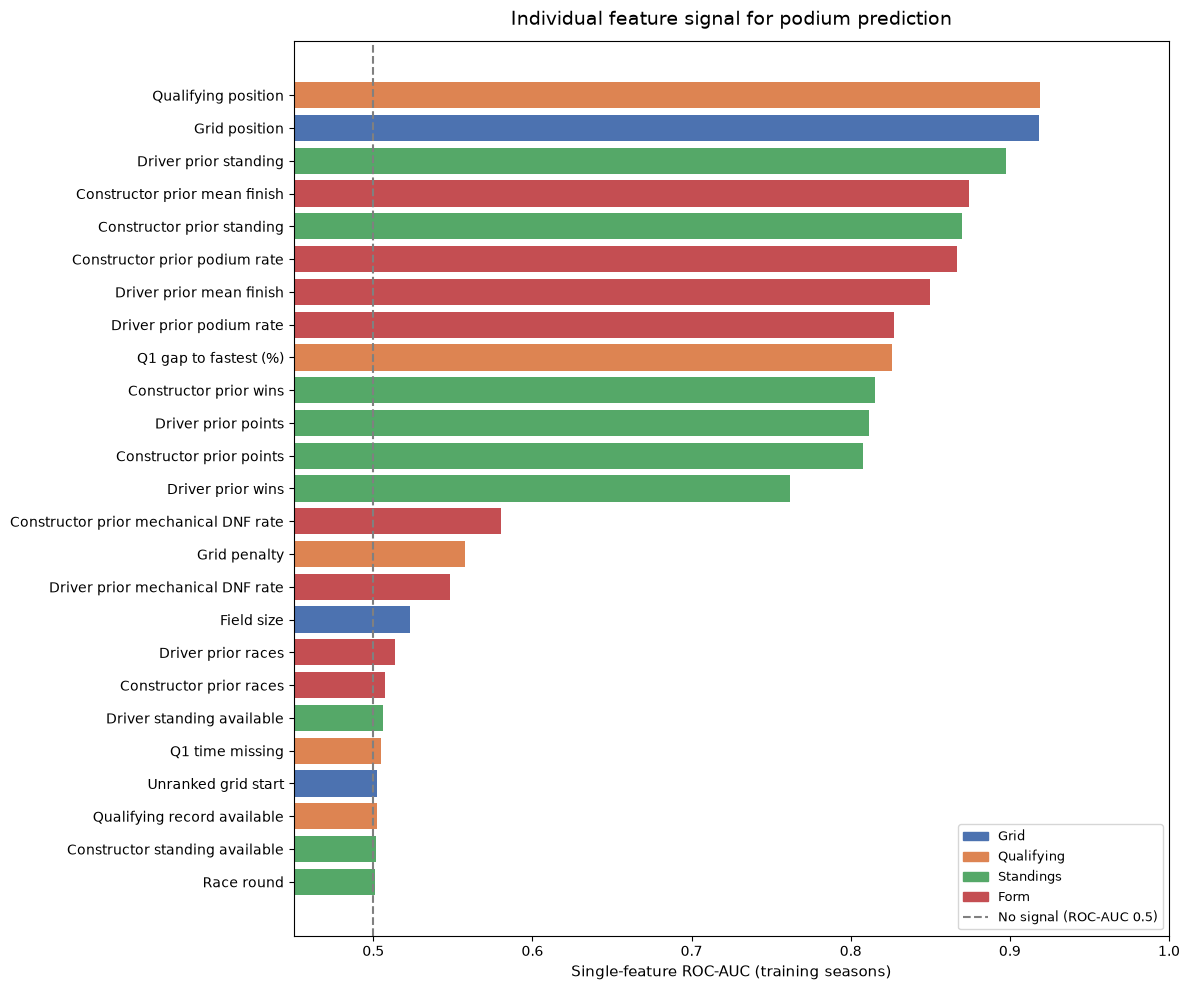

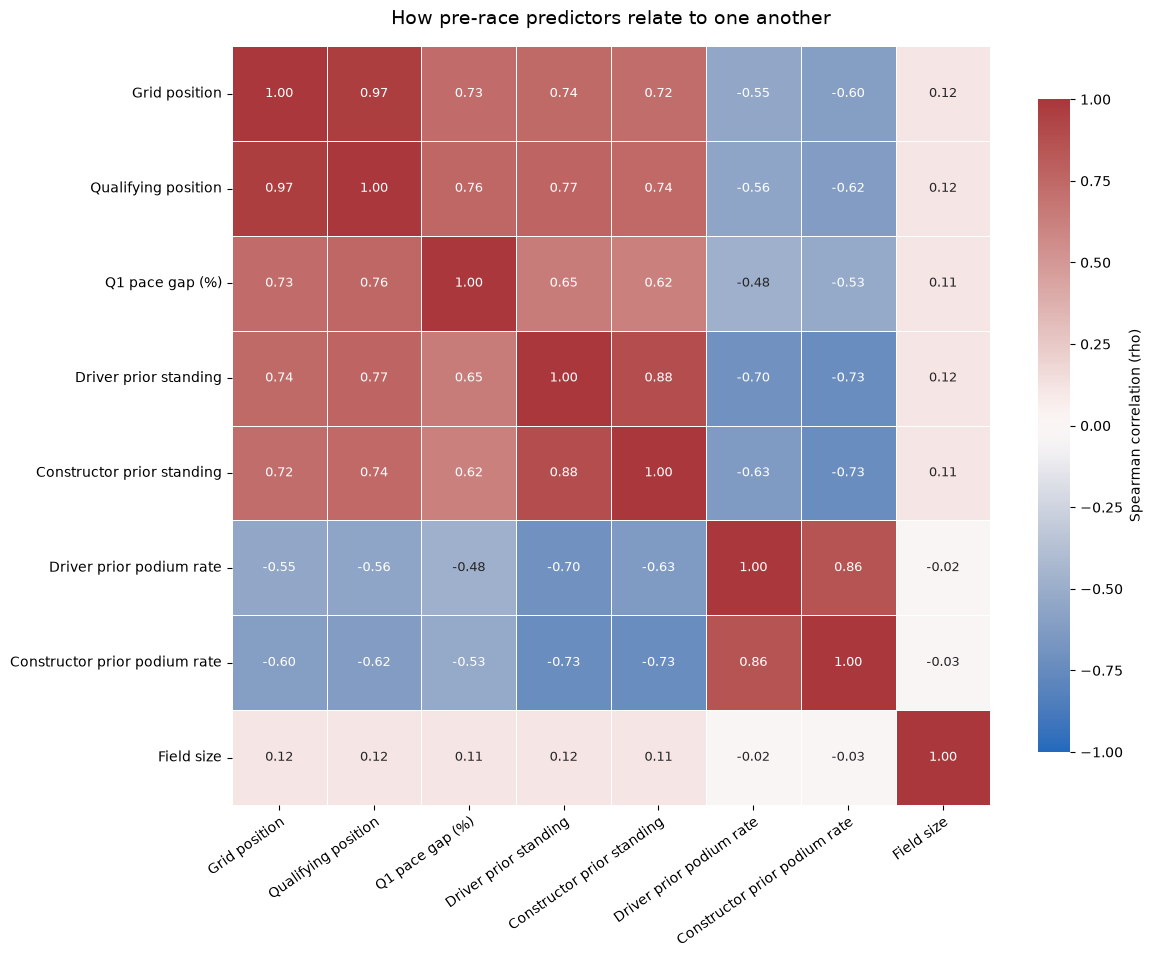

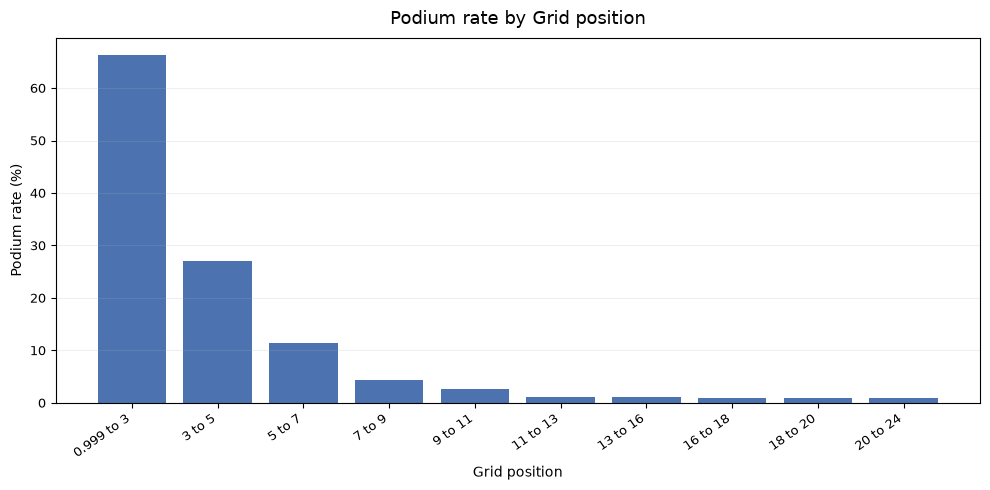

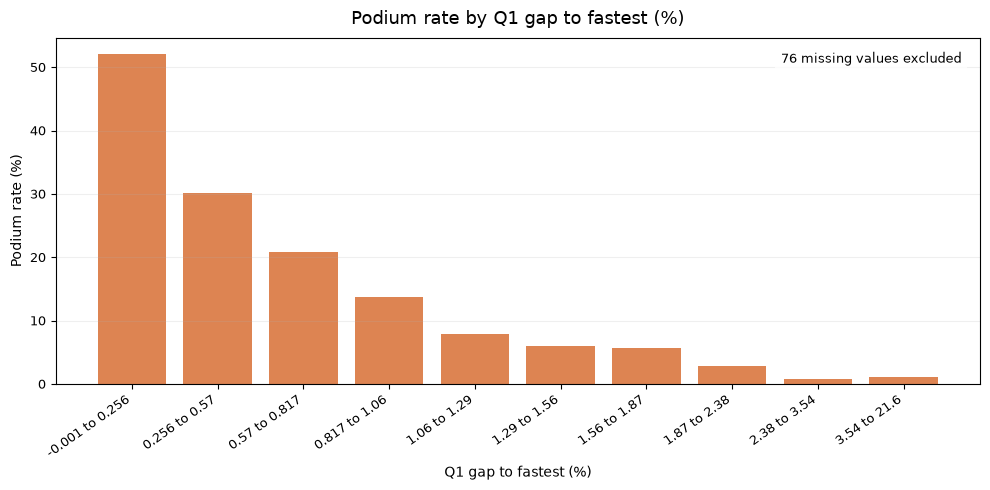

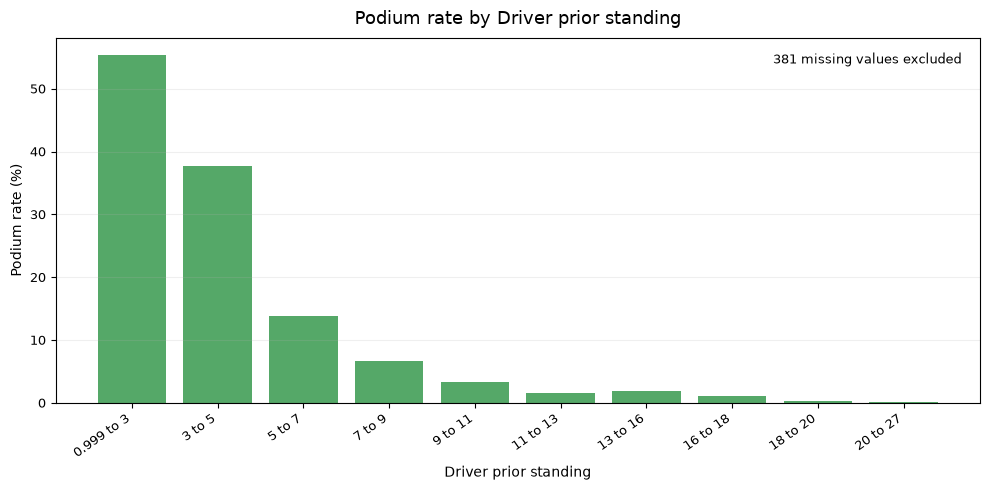

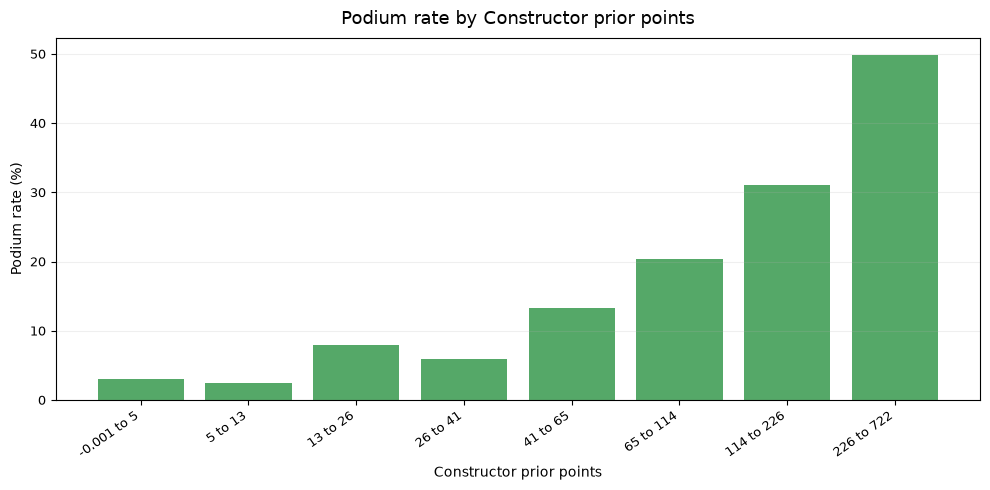

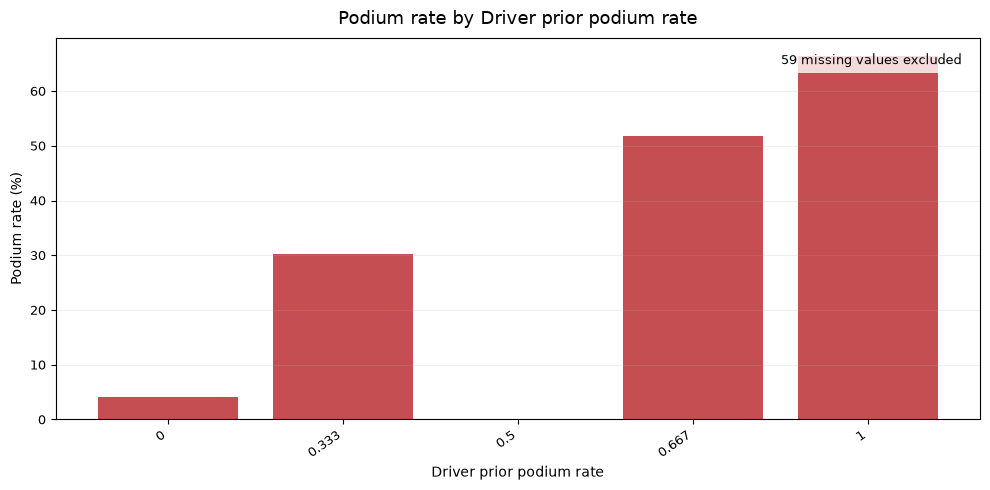

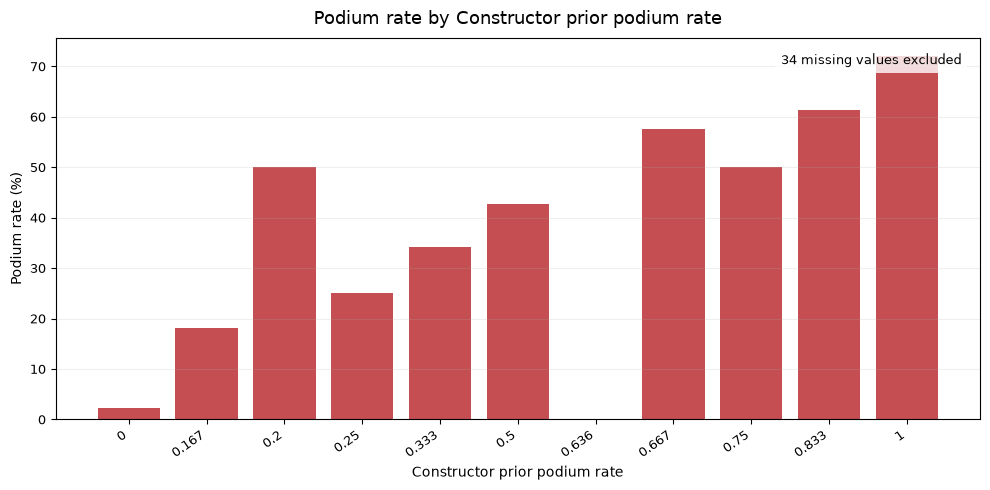

In [175]:
# Exploratory evidence for every candidate feature, computed on TRAINING seasons only
# (2006-2019) so that validation and test outcomes never shape feature decisions.
FE_CANDIDATE_GROUPS = {**MODEL_FEATURE_GROUPS, "form": FORM_FEATURES}
FE_CANDIDATE_COLUMNS = [c for group in FE_CANDIDATE_GROUPS.values() for c in group]
FE_GROUP_OF = {c: g for g, cols in FE_CANDIDATE_GROUPS.items() for c in cols}

fe_candidates = modeling_table.merge(form_features, on=DRIVER_RACE_KEY, how="left", validate="one_to_one")
fe_train = fe_candidates.loc[fe_candidates["partition"].eq("train")].reset_index(drop=True)
y_train_fe = fe_train[MODEL_TARGET].astype(int).to_numpy()
X_train_fe = to_matrix(fe_train, FE_CANDIDATE_COLUMNS)
binary_features = [c for c in FE_CANDIDATE_COLUMNS
                   if set(pd.unique(fe_candidates[c].dropna())) <= {0, 1}]

univariate_rows = []
X_imputed = SimpleImputer(strategy="median").fit_transform(X_train_fe)
mutual_info = mutual_info_classif(X_imputed, y_train_fe,
                                  discrete_features=[c in binary_features for c in FE_CANDIDATE_COLUMNS],
                                  random_state=0)
for j, column in enumerate(FE_CANDIDATE_COLUMNS):
    values = X_train_fe[:, j]; ok = ~np.isnan(values)
    auc = roc_auc_score(y_train_fe[ok], values[ok])
    univariate_rows.append({
        "Feature": column, "Group": FE_GROUP_OF[column],
        "Missing (%)": 100 * (~ok).mean(),
        "Spearman with podium": stats.spearmanr(values[ok], y_train_fe[ok])[0],
        "Single-feature ROC-AUC": max(auc, 1 - auc),
        "Mutual information": mutual_info[j],
        "Minority share (%)": (100 * min(values[ok].mean(), 1 - values[ok].mean())
                               if column in binary_features else np.nan),
    })
feature_univariate_train = pd.DataFrame(univariate_rows)
feature_correlation_train = fe_train[FE_CANDIDATE_COLUMNS].astype(float).corr(method="spearman")
REDUNDANCY_THRESHOLD = 0.95
feature_redundant_pairs = pd.DataFrame([
    {"Feature A": a, "Feature B": b, "Spearman rho": feature_correlation_train.loc[a, b]}
    for i, a in enumerate(FE_CANDIDATE_COLUMNS) for b in FE_CANDIDATE_COLUMNS[i + 1:]
    if abs(feature_correlation_train.loc[a, b]) >= REDUNDANCY_THRESHOLD
])

with pd.option_context("display.precision", 3, "display.width", 200):
    print("Univariate evidence per candidate feature (training seasons 2006-2019 only)")
    display(feature_univariate_train.sort_values("Single-feature ROC-AUC", ascending=False))
    print(f"Feature pairs with |Spearman rho| >= {REDUNDANCY_THRESHOLD} (candidates for redundancy)")
    display(feature_redundant_pairs)

group_colours = {"grid": "#4c72b0", "qualifying": "#dd8452", "standings": "#55a868", "form": "#c44e52"}
feature_labels = {
    "grid_position": "Grid position",
    "pit_lane_start": "Unranked grid start",
    "field_size": "Field size",
    "quali_position": "Qualifying position",
    "has_quali_record": "Qualifying record available",
    "grid_penalty": "Grid penalty",
    "q1_gap_to_fastest_pct": "Q1 gap to fastest (%)",
    "q1_time_missing": "Q1 time missing",
    "round": "Race round",
    "driver_prev_points": "Driver prior points",
    "driver_prev_standing": "Driver prior standing",
    "driver_prev_wins": "Driver prior wins",
    "driver_standing_available": "Driver standing available",
    "constructor_prev_points": "Constructor prior points",
    "constructor_prev_standing": "Constructor prior standing",
    "constructor_prev_wins": "Constructor prior wins",
    "constructor_standing_available": "Constructor standing available",
    "driver_form_races": "Driver prior races",
    "driver_form_podium_rate": "Driver prior podium rate",
    "driver_form_mean_finish": "Driver prior mean finish",
    "driver_form_mech_dnf_rate": "Driver prior mechanical DNF rate",
    "constructor_form_races": "Constructor prior races",
    "constructor_form_podium_rate": "Constructor prior podium rate",
    "constructor_form_mean_finish": "Constructor prior mean finish",
    "constructor_form_mech_dnf_rate": "Constructor prior mechanical DNF rate",
}
fig, ax = plt.subplots(figsize=(12, 10))
ranked = feature_univariate_train.sort_values("Single-feature ROC-AUC")
ranked_labels = ranked["Feature"].map(lambda name: feature_labels.get(name, name.replace("_", " ").title()))
ax.barh(ranked_labels, ranked["Single-feature ROC-AUC"],
       color=ranked["Group"].map(group_colours))
ax.axvline(0.5, ls="--", color="grey", label="No single-feature discrimination")
ax.set_xlim(0.45, 1)
ax.set_xlabel("Single-feature ROC-AUC (training seasons)", fontsize=11)
ax.set_title("Individual feature signal for podium prediction", fontsize=14, pad=12)
ax.tick_params(axis="y", labelsize=10)
ax.tick_params(axis="x", labelsize=10)
ax.legend(handles=[
    *[plt.Rectangle((0, 0), 1, 1, color=c) for c in group_colours.values()],
    plt.Line2D([0], [0], color="grey", linestyle="--"),
], labels=[*[name.title() for name in group_colours], "No signal (ROC-AUC 0.5)"],
   loc="lower right", fontsize=9)
fig.tight_layout()
plt.show()
focused_correlation_features = [
    "grid_position", "quali_position", "q1_gap_to_fastest_pct",
    "driver_prev_standing", "constructor_prev_standing",
    "driver_form_podium_rate", "constructor_form_podium_rate", "field_size",
]
focused_correlation_train = feature_correlation_train.loc[
    focused_correlation_features, focused_correlation_features
]
correlation_labels = {
    "grid_position": "Grid position",
    "quali_position": "Qualifying position",
    "q1_gap_to_fastest_pct": "Q1 pace gap (%)",
    "driver_prev_standing": "Driver prior standing",
    "constructor_prev_standing": "Constructor prior standing",
    "driver_form_podium_rate": "Driver prior podium rate",
    "constructor_form_podium_rate": "Constructor prior podium rate",
    "field_size": "Field size",
}
focused_correlation_display = focused_correlation_train.rename(
    index=correlation_labels, columns=correlation_labels
)
fig, ax = plt.subplots(figsize=(12, 10))
sns.heatmap(
    focused_correlation_display,
    ax=ax,
    cmap="vlag",
    center=0,
    vmin=-1,
    vmax=1,
    annot=True,
    fmt=".2f",
    annot_kws={"size": 9},
    linewidths=0.5,
    square=True,
    cbar_kws={"label": "Spearman correlation (rho)", "shrink": 0.8},
)
ax.set_title("How pre-race predictors relate to one another", fontsize=14, pad=16)
ax.tick_params(axis="x", labelrotation=35, labelsize=10)
ax.tick_params(axis="y", labelrotation=0, labelsize=10)
plt.setp(ax.get_xticklabels(), ha="right", rotation_mode="anchor")
fig.tight_layout()
plt.show()

key_features = ["grid_position", "q1_gap_to_fastest_pct", "driver_prev_standing",
                "constructor_prev_points", "driver_form_podium_rate", "constructor_form_podium_rate"]
for column in key_features:
    values = fe_train[column].astype(float)
    if values.nunique() > 12:
        bins = pd.qcut(values, q=10, duplicates="drop")
    else:
        bins = values
    rate = fe_train.groupby(bins, observed=True)[MODEL_TARGET].agg(["mean", "size"])
    labels = [f"{i.left:.3g} to {i.right:.3g}" if isinstance(i, pd.Interval) else f"{i:.3g}" for i in rate.index]
    fig, ax = plt.subplots(figsize=(10, 5))
    ax.bar(range(len(rate)), 100 * rate["mean"], color=group_colours[FE_GROUP_OF[column]])
    ax.set_xticks(range(len(rate)), labels, rotation=35, ha="right", fontsize=9)
    ax.set_title(f"Podium rate by {feature_labels.get(column, column.replace('_', ' ').title())}", fontsize=13, pad=10)
    ax.set_xlabel(feature_labels.get(column, column.replace("_", " ").title()), fontsize=10)
    ax.set_ylabel("Podium rate (%)", fontsize=10)
    ax.tick_params(axis="y", labelsize=9)
    ax.grid(axis="y", alpha=0.2)
    n_missing = int(values.isna().sum())
    if n_missing:
        ax.text(0.98, 0.96, f"{n_missing:,} missing values excluded", transform=ax.transAxes,
                ha="right", va="top", fontsize=9,
                bbox={"facecolor": "white", "alpha": 0.8, "edgecolor": "none"})
    fig.tight_layout()
    plt.show()


**EDA evidence (training seasons only).**

- **Strong single-feature signal** (single-feature ROC-AUC 0.83-0.92):
  - `quali_position`, `grid_position`;
  - previous championship standing (driver 0.90, constructor 0.87);
  - constructor form (mean finish 0.87, podium rate 0.87);
  - driver form;
  - the Q1 gap to the fastest Q1 time.
- **Plots.** The binned podium-rate plots fall monotonically with grid, Q1 gap and standing, and rise with constructor points and form rates. This is consistent with the hypothesis that car pace plus current competitive state drives podiums.
- **Weaker but real signal:** mechanical-DNF rates (0.55-0.58) and `grid_penalty` (0.56).
- **No univariate signal** (about 0.50-0.52): `round`, `field_size`, the `*_form_races` counts, and the missingness/encoding flags.
  - The flags are kept anyway. They tell a model which values were imputed or encoded (debut, no standings snapshot, no Q1 time, pit-lane start), and the inference function must handle partially missing records.
- **Redundancy.** Only one pair has |rho| >= 0.95: `grid_position` vs `quali_position` (0.97). Together with `grid_penalty` they are exactly collinear (`grid_penalty = grid_position - quali_position`).

Feature-set trials, per model


,Feature set,Model,Features,CV ROC-AUC,CV PR-AUC,CV PR-AUC sd,Validation ROC-AUC,Validation PR-AUC
0,1. grid,Logistic regression,3,0.9275,0.7030,0.0544,0.9094,0.6398
1,1. grid,Hist gradient boosting,3,0.9236,0.6938,0.0658,0.9007,0.6411
2,2. grid + qualifying,Logistic regression,8,0.9350,0.7256,0.0533,0.9238,0.6884
3,2. grid + qualifying,Hist gradient boosting,8,0.9270,0.7016,0.0618,0.9191,0.6805
4,3. + standings (step-10 set),Logistic regression,17,0.9439,0.7295,0.0470,0.9308,0.7348
5,3. + standings (step-10 set),Hist gradient boosting,17,0.9415,0.7146,0.0634,0.9173,0.6837
6,4. + form (all candidates),Logistic regression,25,0.9439,0.7310,0.0468,0.9295,0.7247
7,4. + form (all candidates),Hist gradient boosting,25,0.9423,0.7297,0.0533,0.9237,0.7048
8,5. 4 without redundant,Logistic regression,24,0.9438,0.7307,0.0471,0.9294,0.7244
9,5. 4 without redundant,Hist gradient boosting,24,0.9408,0.7210,0.0589,0.9207,0.6889


Feature-set trials, averaged over both models


,Feature set,Features,Mean_CV_PR_AUC,Mean_CV_ROC_AUC,Mean_validation_PR_AUC
0,1. grid,3,0.6984,0.9256,0.6405
1,2. grid + qualifying,8,0.7136,0.9310,0.6845
2,3. + standings (step-10 set),17,0.7220,0.9427,0.7093
3,4. + form (all candidates),25,0.7304,0.9431,0.7148
4,5. 4 without redundant,24,0.7258,0.9423,0.7067
5,6. 5 without weak,22,0.7260,0.9421,0.7104


Chosen feature set: 6. 5 without weak (22 features)


,Feature,Group,Decision,Reason
2,field_size,grid,dropped,near-zero univariate signal; removal did not c...
3,quali_position,qualifying,dropped,exact linear combination of grid_position and ...
8,round,standings,dropped,near-zero univariate signal; removal did not c...


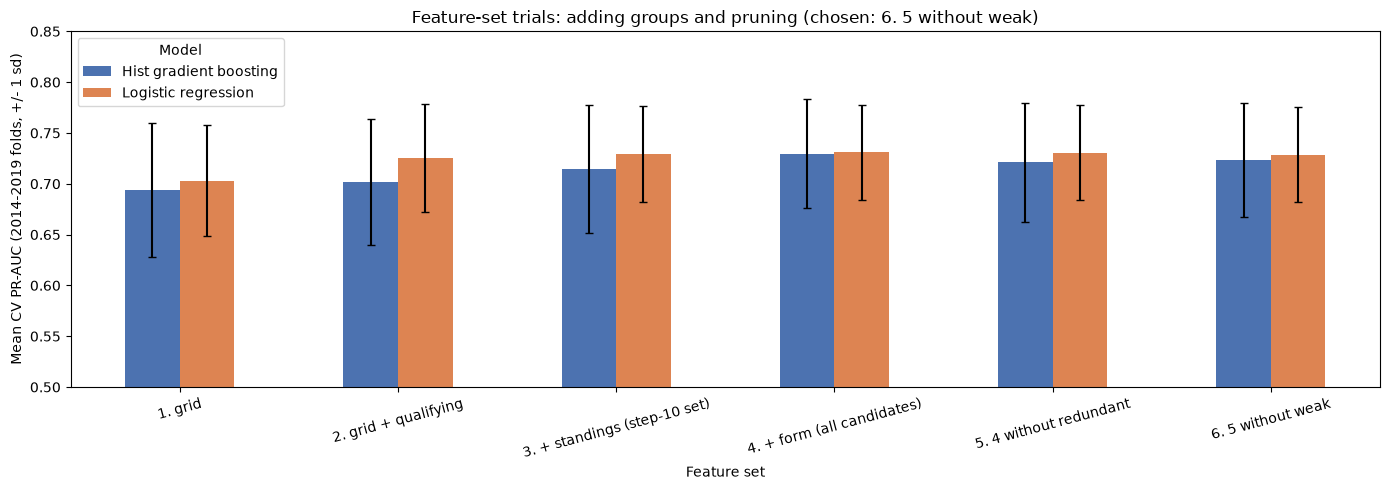

In [176]:
# Empirical feature-set trials (kept for verification). Same protocol as the window experiment:
# expanding CV inside training is the decision score; validation is reported as confirmation.
# quali_position is exactly grid_position - grid_penalty, so the three are perfectly collinear;
# 'round' and 'field_size' show almost no univariate signal in the training EDA.
REDUNDANT_FEATURES = ["quali_position"]
WEAK_FEATURES = ["round", "field_size"]
assert fe_candidates["grid_penalty"].eq(fe_candidates["grid_position"] - fe_candidates["quali_position"]).all()

all_candidates = FE_CANDIDATE_COLUMNS
feature_set_trials = {
    "1. grid": FE_CANDIDATE_GROUPS["grid"],
    "2. grid + qualifying": FE_CANDIDATE_GROUPS["grid"] + FE_CANDIDATE_GROUPS["qualifying"],
    "3. + standings (step-10 set)": MODEL_FEATURE_COLUMNS,
    "4. + form (all candidates)": all_candidates,
    "5. 4 without redundant": [c for c in all_candidates if c not in REDUNDANT_FEATURES],
    "6. 5 without weak": [c for c in all_candidates if c not in REDUNDANT_FEATURES + WEAK_FEATURES],
}
feature_group_results = pd.DataFrame([
    row for label, cols in feature_set_trials.items() for row in evaluate_feature_set(fe_candidates, cols, label)
]).drop(columns="fold_pr_auc")
feature_set_summary = feature_group_results.groupby("Feature set", sort=False).agg(
    Features=("Features", "first"), Mean_CV_PR_AUC=("CV PR-AUC", "mean"),
    Mean_CV_ROC_AUC=("CV ROC-AUC", "mean"), Mean_validation_PR_AUC=("Validation PR-AUC", "mean")
).reset_index()

# Decision rule (fixed in advance): among sets 4-6, take the smallest set whose mean CV PR-AUC is
# within 0.005 of the full set (set 4). Simpler and less collinear sets win near-ties.
SIMPLIFICATION_TOLERANCE = 0.005
cv_score = feature_set_summary.set_index("Feature set")["Mean_CV_PR_AUC"]
full_set = "4. + form (all candidates)"
chosen_set = full_set
for simpler in ["5. 4 without redundant", "6. 5 without weak"]:
    if cv_score[simpler] >= cv_score[full_set] - SIMPLIFICATION_TOLERANCE:
        chosen_set = simpler
FE_FEATURE_COLUMNS = feature_set_trials[chosen_set]
FE_FEATURE_GROUPS = {g: [c for c in cols if c in FE_FEATURE_COLUMNS] for g, cols in FE_CANDIDATE_GROUPS.items()}
feature_selection_log = pd.DataFrame([
    {"Feature": c, "Group": FE_GROUP_OF[c],
     "Decision": "kept" if c in FE_FEATURE_COLUMNS else "dropped",
     "Reason": ("exact linear combination of grid_position and grid_penalty" if c in REDUNDANT_FEATURES
                else "near-zero univariate signal; removal did not cost CV PR-AUC" if c in WEAK_FEATURES
                and c not in FE_FEATURE_COLUMNS else "kept: signal or required missingness/encoding flag")}
    for c in all_candidates
])

with pd.option_context("display.precision", 4, "display.width", 200):
    print("Feature-set trials, per model")
    display(feature_group_results)
    print("Feature-set trials, averaged over both models")
    display(feature_set_summary)
    print(f"Chosen feature set: {chosen_set} ({len(FE_FEATURE_COLUMNS)} features)")
    display(feature_selection_log.loc[feature_selection_log["Decision"].eq("dropped")])

fig, ax = plt.subplots(figsize=(14, 5))
plot = feature_group_results.pivot(index="Feature set", columns="Model", values="CV PR-AUC") \
    .reindex(list(feature_set_trials))
errors = feature_group_results.pivot(index="Feature set", columns="Model", values="CV PR-AUC sd") \
    .reindex(list(feature_set_trials))
plot.plot.bar(ax=ax, yerr=errors, capsize=3, rot=15, color=["#4c72b0", "#dd8452"])
ax.set_ylim(0.5, 0.85)
ax.set_ylabel("Mean CV PR-AUC (2014-2019 folds, +/- 1 sd)")
ax.set_title(f"Feature-set trials: adding groups and pruning (chosen: {chosen_set})")
plt.tight_layout()
plt.show()

**Feature-set trials and selection.**

- **Adding groups helps, in order.** Mean CV PR-AUC: grid 0.698 -> + qualifying 0.714 -> + standings 0.722 -> + form 0.730. Validation PR-AUC follows the same order (0.641 -> 0.685 -> 0.709 -> 0.715).
- **Pruning trials.**
  - Dropping the collinear `quali_position` gives 0.726.
  - Also dropping the no-signal `round` and `field_size` gives 0.726.
- **Pre-stated rule.** Take the smallest set within 0.005 CV PR-AUC of the full set. This selects **22 features** in four groups:
  - **grid:** `grid_position`, `pit_lane_start`;
  - **qualifying:** `has_quali_record`, `grid_penalty`, `q1_gap_to_fastest_pct`, `q1_time_missing`;
  - **standings:** driver and constructor previous points, standing, wins, and standing-available flags;
  - **form (last 3):** driver and constructor podium rate, mean finish, mechanical-DNF rate, and races in window.
- **Unchanged.** `quali_position`, `round` and `field_size` remain in `modeling_table` with their step-10 meaning; they are only excluded from X. The qualifying position stays available implicitly as `grid_position - grid_penalty`.

Partitions (each race in exactly one)


,partition,First_season,Last_season,Races,Rows,Podium_rows,Podium (%)
0,train,2006,2019,268,5760,804,13.96
1,validation,2020,2021,39,779,117,15.02
2,test,2022,2024,68,1354,204,15.07


Why not a random split


,Split,Races spread over >1 partition (%),Test rows from seasons the model trained on (%)
0,"Temporal (used): train 2006-2019, validation 2020-2021, test 2022-2024",0.00,0.0
1,"Random row split, same proportions (counterfactual)",99.73,100.0


Expanding-window CV folds inside training (used for feature and, later, hyperparameter choices)


,Fold,Fit seasons,Score season,Fit rows,Score rows
0,1,2006-2013,2014,3281,405
1,2,2006-2014,2015,3686,375
2,3,2006-2015,2016,4061,460
3,4,2006-2016,2017,4521,400
4,5,2006-2017,2018,4921,420
5,6,2006-2018,2019,5341,419


Median of selected features per partition (distribution shift to watch)


,grid_position,field_size,driver_prev_points,q1_gap_to_fastest_pct,constructor_form_podium_rate
partition,,,,,
train,11.0,22.0,11.0,1.29,0.0
validation,11.0,20.0,18.0,1.06,0.0
test,11.0,20.0,17.0,0.91,0.0


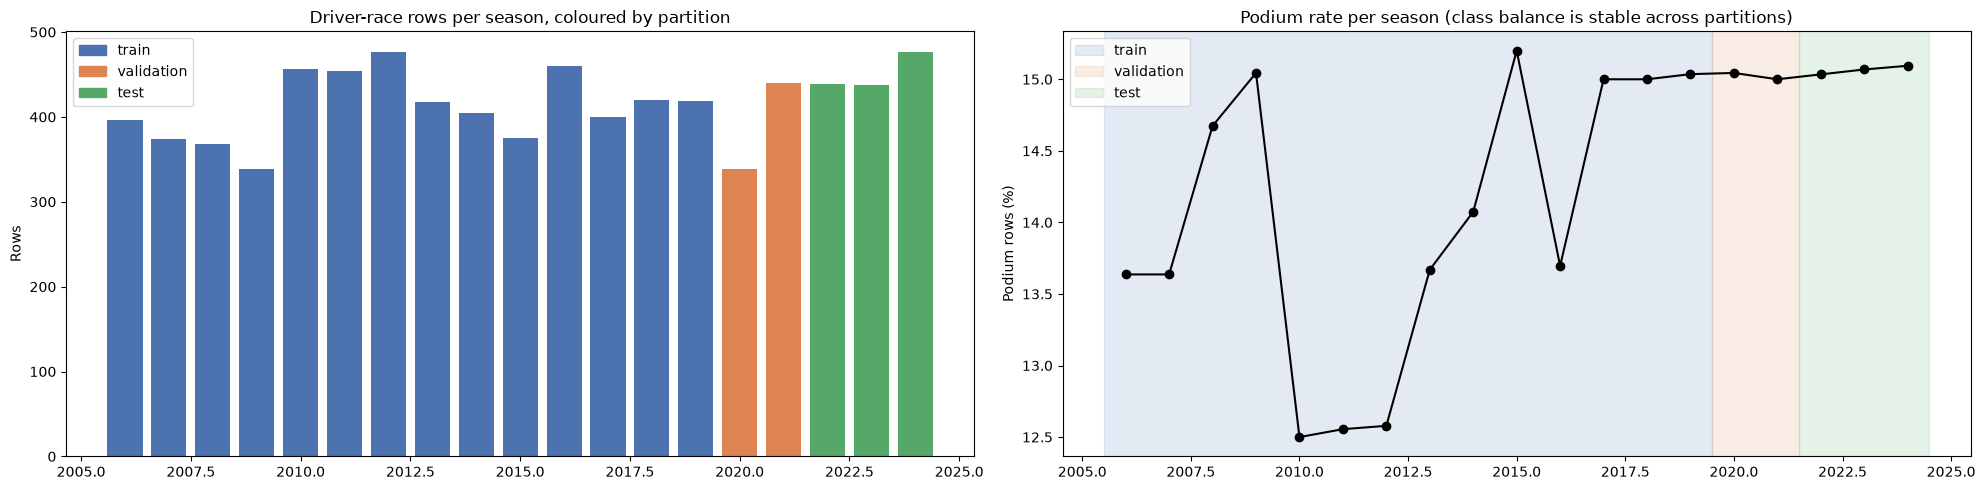

In [177]:
# Split justification: temporal, race-disjoint partitions (from step 10) versus a random row split.
season_summary = modeling_table.groupby(["year", "partition"]).agg(
    races=("raceId", "nunique"), rows=("driverId", "size"), podium_pct=(MODEL_TARGET, "mean")
).reset_index()
season_summary["podium_pct"] *= 100

rng = np.random.default_rng(0)
random_partition = pd.Series(rng.choice(["train", "validation", "test"], size=len(modeling_table),
                                        p=[0.73, 0.10, 0.17]), index=modeling_table.index)
races_split_randomly = modeling_table.assign(rp=random_partition).groupby("raceId")["rp"].nunique()
max_train_year_random = modeling_table.loc[random_partition.eq("train"), "year"].max()
split_comparison = pd.DataFrame([
    {"Split": "Temporal (used): train 2006-2019, validation 2020-2021, test 2022-2024",
     "Races spread over >1 partition (%)": 100 * modeling_table.groupby("raceId")["partition"].nunique().gt(1).mean(),
     "Test rows from seasons the model trained on (%)": 100 * modeling_table.loc[
         modeling_table["partition"].eq("test"), "year"].le(SPLIT_BOUNDARIES["train"][1]).mean()},
    {"Split": "Random row split, same proportions (counterfactual)",
     "Races spread over >1 partition (%)": 100 * races_split_randomly.gt(1).mean(),
     "Test rows from seasons the model trained on (%)": 100 * modeling_table.loc[
         random_partition.eq("test"), "year"].le(max_train_year_random).mean()},
])
time_series_cv_table = pd.DataFrame([
    {"Fold": i + 1, "Fit seasons": f"{tr[0]}-{tr[-1]}", "Score season": te[0],
     "Fit rows": int(modeling_table["year"].isin(tr).sum()), "Score rows": int(modeling_table["year"].isin(te).sum())}
    for i, (tr, te) in enumerate(TIME_SERIES_CV_FOLDS)
])
drift_columns = ["grid_position", "field_size", "driver_prev_points", "q1_gap_to_fastest_pct",
                 "constructor_form_podium_rate"]
partition_drift = fe_candidates.groupby("partition")[drift_columns].median().reindex(list(SPLIT_BOUNDARIES))

with pd.option_context("display.precision", 2, "display.width", 200, "display.max_colwidth", 80):
    print("Partitions (each race in exactly one)")
    display(modeling_partition_summary)
    print("Why not a random split")
    display(split_comparison)
    print("Expanding-window CV folds inside training (used for feature and, later, hyperparameter choices)")
    display(time_series_cv_table)
    print("Median of selected features per partition (distribution shift to watch)")
    display(partition_drift)

fig, axes = plt.subplots(1, 2, figsize=(20, 5))
colours = {"train": "#4c72b0", "validation": "#dd8452", "test": "#55a868"}
axes[0].bar(season_summary["year"], season_summary["rows"], color=season_summary["partition"].map(colours))
axes[0].set_title("Driver-race rows per season, coloured by partition")
axes[0].set_ylabel("Rows")
axes[0].legend(handles=[plt.Rectangle((0, 0), 1, 1, color=c) for c in colours.values()], labels=list(colours))
axes[1].plot(season_summary["year"], season_summary["podium_pct"], marker="o", color="black")
for name, (a, b) in SPLIT_BOUNDARIES.items():
    axes[1].axvspan(a - 0.5, b + 0.5, color=colours[name], alpha=0.15, label=name)
axes[1].set_title("Podium rate per season (class balance is stable across partitions)")
axes[1].set_ylabel("Podium rows (%)")
axes[1].legend()
plt.tight_layout()
plt.show()

**Split justification.**

- **Temporal split, as in the terminology guide.** Train 2006-2019 (268 races, 5,760 rows), validation 2020-2021 (39 races, 779 rows), test 2022-2024 (68 races, 1,354 rows).
- **Why temporal.**
  1. Predictions are always made for a *future* race, so the evaluation must score seasons the model has never seen.
  2. The roughly 20 drivers of a race are not independent: they share weather, safety cars and exactly three podium places. A random row split would put **99.7% of races** in more than one partition, and every test row would come from a season seen in training.
  3. The 2022 ground-effect regulations fall inside the test period, so the test measures generalisation to a new car generation. This is harder but honest.
- **Class balance** is stable: 14.0% / 15.0% / 15.1% podium.
- **Distribution shift to report.**
  - Median `driver_prev_points` is higher after 2010 because of the points-system change; the step-10 encoding was deliberately kept.
  - `field_size` falls from 22 to 20.
  - Median Q1 gaps shrink (1.29% -> 0.91%).
- **Within training,** the six expanding folds (`TIME_SERIES_CV_FOLDS`) replace a random K-fold for any later hyperparameter search. Training-only expanding CV selects LR/HGB hyperparameters; validation selects model thresholds; test is reserved for final reporting (with prior 0.5 results disclosed).

In [178]:
# Final feature-engineered table and leakage checks.
# User-requested geography feature, added after the 22-feature CV selection above.
# Existing trial scores describe the original selected set, not this 23-feature set.
# Home means recorded nationality matches the actual circuit country (step-8 conventions).
selected_columns_before_home = [c for c in FE_FEATURE_COLUMNS if c != "is_home"]
modeling_table_fe = fe_candidates[
    [*MODEL_KEY_COLUMNS, MODEL_TARGET, *selected_columns_before_home]
].merge(
    home_country_audit[[*DRIVER_RACE_KEY, "is_home"]],
    on=DRIVER_RACE_KEY, how="left", validate="one_to_one", sort=False
)
# Preserve unknowns; never turn an unresolved home country into an away value.
modeling_table_fe["is_home"] = modeling_table_fe["is_home"].astype("Int64")
FE_FEATURE_COLUMNS = [*selected_columns_before_home, "is_home"]
FE_FEATURE_GROUPS = {**FE_FEATURE_GROUPS, "geography": ["is_home"]}
FE_GROUP_OF = {**FE_GROUP_OF, "is_home": "geography"}
feature_selection_log = pd.concat([
    feature_selection_log.loc[feature_selection_log["Feature"].ne("is_home")],
    pd.DataFrame([{
        "Feature": "is_home", "Group": "geography", "Decision": "kept",
        "Reason": "User-requested home-country feature; predictive gain not yet evaluated"
    }])
], ignore_index=True)
FE_IMPUTE_COLUMNS = [c for c in FE_FEATURE_COLUMNS if modeling_table_fe[c].isna().any()]

step12_checks = []
def record_step12_check(name, passed, detail):
    step12_checks.append({"Check": name, "Result": "PASS" if passed else "FAIL", "Detail": detail})

mfe = modeling_table_fe
record_step12_check("Grain and rows unchanged from step 10",
                    len(mfe) == len(modeling_table) and not mfe.duplicated(DRIVER_RACE_KEY).any()
                    and mfe[[*DRIVER_RACE_KEY, "partition", MODEL_TARGET]].equals(
                        modeling_table[[*DRIVER_RACE_KEY, "partition", MODEL_TARGET]]),
                    f"{len(mfe):,} rows, same keys/partitions/target")
# Independently recompute home status from the driver and circuit lookups, checking
# join alignment and the exact mapping semantics for every final modeling row.
home_check = mfe[[*DRIVER_RACE_KEY, "circuitId", "is_home"]].merge(
    driver_country_lookup[["driverId", "home_countries"]],
    on="driverId", how="left", validate="many_to_one"
).merge(
    circuit_country_lookup[["circuitId", "circuit_country"]],
    on="circuitId", how="left", validate="many_to_one"
)
expected_home = pd.Series(pd.array([
    classify_home_country(countries, country)
    for countries, country in zip(home_check["home_countries"], home_check["circuit_country"])
], dtype="Int64"), index=home_check.index)
record_step12_check("Home-country feature is complete and matches source mappings",
                    home_check["is_home"].notna().all()
                    and home_check["is_home"].isin([0, 1]).all()
                    and home_check["is_home"].equals(expected_home),
                    f"{int(mfe['is_home'].eq(1).sum())} home, "
                    f"{int(mfe['is_home'].eq(0).sum())} away; no unresolved rows in 2006-2024")
record_step12_check("Final feature registry matches table and groups",
                    mfe.columns.tolist() == [*MODEL_KEY_COLUMNS, MODEL_TARGET, *FE_FEATURE_COLUMNS]
                    and len(FE_FEATURE_COLUMNS) == len(set(FE_FEATURE_COLUMNS))
                    and FE_FEATURE_COLUMNS == [c for cols in FE_FEATURE_GROUPS.values() for c in cols],
                    "23 predictors including the user-requested geography feature")
forbidden = {"podium", "best_positionOrder", "positionOrder", "position", "positionText", "points", "laps",
             "time", "milliseconds", "fastestLap", "rank", "fastestLapTime", "fastestLapSpeed",
             "statusId", "status", "is_mechanical", "mechanical_class", "grid", "mechanical", "finish"}
record_step12_check("No outcome column among predictors", not set(FE_FEATURE_COLUMNS) & forbidden,
                    f"{len(FE_FEATURE_COLUMNS)} predictors")

# Brute-force recomputation of form features for a random sample, using only races strictly before.
sample = mfe.sample(300, random_state=0)
calendar_pos = race_calendar.assign(order=np.arange(len(race_calendar))).set_index("raceId")["order"]
hist = form_history.assign(order=form_history["raceId"].map(calendar_pos))
driver_ok = team_ok = True
for _, row in sample.iterrows():
    now = calendar_pos[row["raceId"]]
    past = hist.loc[hist["driverId"].eq(row["driverId"]) & hist["order"].lt(now)].sort_values("order")
    past = past.tail(FORM_WINDOW) if FORM_WINDOW else past
    expected = past["podium"].mean() if len(past) else np.nan
    got = row["driver_form_podium_rate"]
    driver_ok &= (pd.isna(expected) and pd.isna(got)) or np.isclose(expected, got)
    team_races = hist.loc[hist["constructorId"].eq(row["constructorId"]) & hist["order"].lt(now)]
    last_orders = sorted(team_races["order"].unique())
    last_orders = last_orders[-FORM_WINDOW:] if FORM_WINDOW else last_orders
    team_past = team_races.loc[team_races["order"].isin(last_orders)]
    expected = team_past["podium"].mean() if len(team_past) else np.nan
    got = row["constructor_form_podium_rate"]
    team_ok &= (pd.isna(expected) and pd.isna(got)) or np.isclose(expected, got)
record_step12_check("Driver form uses only strictly earlier races", bool(driver_ok),
                    f"Brute-force recomputation of 300 sampled rows, window = {FORM_WINDOW_NAME}")
record_step12_check("Constructor form uses only strictly earlier team races", bool(team_ok),
                    "Brute-force recomputation; same-race teammate results never included")
teammates_equal = mfe.groupby(["raceId", "constructorId"])["constructor_form_podium_rate"] \
    .nunique(dropna=False).le(1).all()
record_step12_check("Teammates share identical constructor form", bool(teammates_equal),
                    "Team form is a team-level, pre-race quantity")
expected_missing = {"q1_gap_to_fastest_pct", "driver_prev_standing", "constructor_prev_standing",
                    "driver_form_podium_rate", "driver_form_mean_finish", "driver_form_mech_dnf_rate",
                    "constructor_form_podium_rate", "constructor_form_mean_finish",
                    "constructor_form_mech_dnf_rate"}
record_step12_check("Missing values only in documented columns", set(FE_IMPUTE_COLUMNS) <= expected_missing,
                    ", ".join(FE_IMPUTE_COLUMNS))
no_history = mfe["driver_form_races"].eq(0)
record_step12_check("Form missing exactly when there is no history",
                    mfe.loc[no_history, "driver_form_podium_rate"].isna().all()
                    and mfe.loc[~no_history, "driver_form_podium_rate"].notna().all(),
                    f"{int(no_history.sum())} driver debuts (driver_form_races = 0)")
record_step12_check("Feature decisions used no test rows",
                    all(max(tr + te) <= SPLIT_BOUNDARIES["train"][1] for tr, te in TIME_SERIES_CV_FOLDS),
                    "Choices use CV inside 2006-2019; validation only reported")
record_step12_check("Sources and step-10 table unchanged",
                    step7_source_fingerprints() == step12_sources_before
                    and step7_frame_fingerprint(modeling_table) == step12_modeling_before,
                    "Raw/clean fingerprints and modeling_table")

step12_validation = pd.DataFrame(step12_checks)
feature_engineering_contract = pd.DataFrame([
    {"Feature": c, "Group": FE_GROUP_OF[c], "Missing rows": int(mfe[c].isna().sum()),
     "Needs training-fitted imputation": c in FE_IMPUTE_COLUMNS}
    for c in FE_FEATURE_COLUMNS
])
with pd.option_context("display.max_colwidth", 100, "display.width", 200):
    print("Final feature contract")
    display(feature_engineering_contract)
    display(step12_validation)
step12_validation_passed = step12_validation["Result"].eq("PASS").all()
assert step12_validation_passed, "Step 12 validation failed."
print(f"Step 12 validation passed: {len(step12_validation)} checks; modeling_table_fe has "
      f"{len(mfe):,} rows and {len(FE_FEATURE_COLUMNS)} predictors in {len(FE_FEATURE_GROUPS)} groups.")

Final feature contract


,Feature,Group,Missing rows,Needs training-fitted imputation
0,grid_position,grid,0,False
1,pit_lane_start,grid,0,False
2,has_quali_record,qualifying,0,False
3,grid_penalty,qualifying,0,False
4,q1_gap_to_fastest_pct,qualifying,98,True
5,q1_time_missing,qualifying,0,False
6,driver_prev_points,standings,0,False
7,driver_prev_standing,standings,493,True
8,driver_prev_wins,standings,0,False
9,driver_standing_available,standings,0,False


,Check,Result,Detail
0,Grain and rows unchanged from step 10,PASS,"7,893 rows, same keys/partitions/target"
1,Home-country feature is complete and matches source mappings,PASS,"298 home, 7595 away; no unresolved rows in 2006-2024"
2,Final feature registry matches table and groups,PASS,23 predictors including the user-requested geography feature
3,No outcome column among predictors,PASS,23 predictors
4,Driver form uses only strictly earlier races,PASS,"Brute-force recomputation of 300 sampled rows, window = last 3"
5,Constructor form uses only strictly earlier team races,PASS,Brute-force recomputation; same-race teammate results never included
6,Teammates share identical constructor form,PASS,"Team form is a team-level, pre-race quantity"
7,Missing values only in documented columns,PASS,"q1_gap_to_fastest_pct, driver_prev_standing, constructor_prev_standing, driver_form_podium_rate,..."
8,Form missing exactly when there is no history,PASS,73 driver debuts (driver_form_races = 0)
9,Feature decisions used no test rows,PASS,Choices use CV inside 2006-2019; validation only reported


Step 12 validation passed: 11 checks; modeling_table_fe has 7,893 rows and 23 predictors in 5 groups.


### Step 12 result and handoff

**`modeling_table_fe`** contains:
- the step-10 keys, partition and `podium` target;
- 7,893 rows;
- **23 predictors** in `FE_FEATURE_GROUPS`: grid 2, qualifying 4, standings 8, form 8, geography 1.

Use `FE_FEATURE_COLUMNS` as X.

**Home-country feature (`is_home`).** User-requested addition after the original 22-feature selection:
- 1 when the driver's recorded nationality maps to the actual circuit country; 0 otherwise.
- Reuses step-8 country aliases and the convention that either listed dual-nationality country is home.
- Unknown mappings stay missing; all rows in the 2006-2024 modeling window are resolved.
- Joined on `(raceId, driverId)` with one-to-one validation. It uses no race outcomes.
- Earlier feature-selection scores describe the original 22-feature set. Steps 16-17 evaluate the predictive contribution of `is_home` through ablation and permutation importance.
- `modeling_table` remains the step-10 base; `modeling_table_fe` is the final table with this feature.

**Imputation.** Columns in `FE_IMPUTE_COLUMNS` still contain missing values, and each has a matching flag or count:
- `q1_gap_to_fastest_pct` (98);
- `driver_prev_standing` (493), `constructor_prev_standing` (417);
- driver form rates (73 debuts) and constructor form rates (40 team debuts).

Imputation must be fitted on training rows only, inside the model pipeline.

**Validation.** Eleven checks are required:
- unchanged grain, partitions and target;
- complete binary home status matching driver/circuit mappings, and consistent feature registries;
- no outcome columns in X;
- form recomputed by brute force from strictly earlier races, for driver and team;
- teammates share identical team form;
- missingness confined to documented columns;
- no test rows used in any decision;
- sources and step-10 table unchanged.

**Reusable objects:** `TIME_SERIES_CV_FOLDS`, `evaluate_feature_set`, `FORM_WINDOW`, `form_window_results`, `feature_univariate_train`, `feature_group_results`, `feature_selection_log`.

**Next.** Step 12b reports preprocessing-order trials; step 12c selects statistical-model settings on training-only CV; steps 13-15 fit the final models; steps 16-17 report ablation/XAI; step 18 selects validation thresholds, reports test metrics for the selected pipeline, and demonstrates inference.

**Disclosure.** The all-year outcome EDA was viewed earlier in the notebook.

## Preprocessing-order experiments (step 12b)

These controlled experiments use **logistic regression**, the same 23 selected features, fixed baseline hyperparameters, and the six expanding time-series folds already used during training-only feature selection. The 2020-2021 validation period is a confirmation set; the 2022-2024 test set is not loaded or scored here. Every imputer and scaler is fitted afresh on each fold's training years.

1. **Median imputation vs. scaling order:** compare median imputation → standardization (the baseline order) with standardization of observed values → median imputation. The two fitted transformations need not be equivalent because the scaler in the first order also sees median-filled values. The fold and validation results show whether that difference matters here.
2. **Missingness-indicator order:** compare generating missingness indicators from raw values before imputation with a negative-control order that attempts to generate indicators after imputation. The latter loses the missingness signal because imputation has already replaced missing values. Both variants retain the same fixed-width feature layout and otherwise use identical preprocessing and classifier settings.

PR-AUC (average precision) is the primary comparison metric because podiums are the minority class; ROC-AUC is reported alongside. Fold-level paired results are retained so the comparison is not hidden by an average.

In [179]:
N_FEATURES = len(FE_FEATURE_COLUMNS)
BINARY_FEATURES = [
    "pit_lane_start", "has_quali_record", "q1_time_missing",
    "driver_standing_available", "constructor_standing_available",
    "is_home",
]
N_NUMERIC = N_FEATURES - len(BINARY_FEATURES)

assert len(set(FE_FEATURE_COLUMNS)) == N_FEATURES
assert set(BINARY_FEATURES).issubset(FE_FEATURE_COLUMNS)
assert set(FE_FEATURE_COLUMNS).issubset(modeling_table_fe.columns)

print(f"{N_FEATURES} features: {N_NUMERIC} numeric, "
      f"{len(BINARY_FEATURES)} binary")

23 features: 17 numeric, 6 binary


In [180]:
assert step12_validation_passed, "Run step 12 successfully first."

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    average_precision_score, f1_score, precision_score, recall_score, roc_auc_score
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

PREPROCESSING_EXPERIMENT_FEATURES = list(FE_FEATURE_COLUMNS)
PREPROCESSING_EXPERIMENT_BINARY = [
    "pit_lane_start", "has_quali_record", "q1_time_missing",
    "driver_standing_available", "constructor_standing_available", "is_home"
]
PREPROCESSING_EXPERIMENT_NUMERIC = [
    c for c in PREPROCESSING_EXPERIMENT_FEATURES if c not in PREPROCESSING_EXPERIMENT_BINARY
]
assert len(PREPROCESSING_EXPERIMENT_FEATURES) == 23
assert len(PREPROCESSING_EXPERIMENT_NUMERIC) == 17

preprocess_rows = modeling_table_fe.loc[
    modeling_table_fe["partition"].isin(["train", "validation"])
].copy().reset_index(drop=True)
preprocess_train = preprocess_rows.loc[preprocess_rows["partition"].eq("train")].copy()
preprocess_validation = preprocess_rows.loc[
    preprocess_rows["partition"].eq("validation")
].copy()
assert preprocess_train["year"].between(2006, 2019).all()
assert preprocess_validation["year"].between(2020, 2021).all()
assert set(preprocess_train["raceId"]).isdisjoint(preprocess_validation["raceId"])

preprocess_X = preprocess_rows[PREPROCESSING_EXPERIMENT_FEATURES].astype("Float64").astype("float64")
preprocess_y = preprocess_rows[MODEL_TARGET].astype(int).to_numpy()
preprocess_train_mask = preprocess_rows["partition"].eq("train").to_numpy()
preprocess_validation_mask = preprocess_rows["partition"].eq("validation").to_numpy()
PREPROCESSING_EXPERIMENT_THRESHOLD = 0.5


def make_preprocessing_lr(numeric_order):
    """Make the fixed LR baseline, changing only numeric imputation/scaling order."""
    if numeric_order == "impute_then_scale":
        numeric_steps = [
            ("imputer", SimpleImputer(strategy="median", keep_empty_features=True)),
            ("scaler", StandardScaler()),
        ]
    elif numeric_order == "scale_then_impute":
        numeric_steps = [
            ("scaler", StandardScaler()),
            ("imputer", SimpleImputer(strategy="median", keep_empty_features=True)),
        ]
    else:
        raise ValueError(f"Unknown preprocessing order: {numeric_order}")
    preprocessor = ColumnTransformer(
        transformers=[
            ("numeric", Pipeline(numeric_steps), PREPROCESSING_EXPERIMENT_NUMERIC),
            ("binary", "passthrough", PREPROCESSING_EXPERIMENT_BINARY),
        ],
        remainder="drop",
        verbose_feature_names_out=False,
    )
    return Pipeline([
        ("preprocessing", preprocessor),
        ("classifier", LogisticRegression(
            C=1.0, **LR_L2_KWARGS, solver="lbfgs", class_weight=None,
            fit_intercept=True, max_iter=5000, tol=1e-4,
        )),
    ])


def preprocessing_metric_record(experiment, variant, split, y_true, probability):
    prediction = (probability >= PREPROCESSING_EXPERIMENT_THRESHOLD).astype(int)
    return {
        "Experiment": experiment,
        "Variant": variant,
        "Split": split,
        "Rows": len(y_true),
        "ROC-AUC": roc_auc_score(y_true, probability),
        "PR-AUC (average precision)": average_precision_score(y_true, probability),
        "F1": f1_score(y_true, prediction, zero_division=0),
        "Precision": precision_score(y_true, prediction, zero_division=0),
        "Recall": recall_score(y_true, prediction, zero_division=0),
    }


preprocessing_experiment_rows = []
preprocessing_fold_rows = []

# Experiment 1: compare the two actual sklearn preprocessing orders.
for variant, order in [
    ("Median imputation → scaling (baseline)", "impute_then_scale"),
    ("Scaling → median imputation", "scale_then_impute"),
]:
    for fold_number, (fit_years, score_years) in enumerate(TIME_SERIES_CV_FOLDS, start=1):
        fit_mask = preprocess_rows["year"].isin(fit_years).to_numpy()
        score_mask = preprocess_rows["year"].isin(score_years).to_numpy()
        assert fit_mask.any() and score_mask.any()
        model = make_preprocessing_lr(order)
        model.fit(preprocess_X.loc[fit_mask], preprocess_y[fit_mask])
        probability = model.predict_proba(preprocess_X.loc[score_mask])[:, 1]
        fold_result = preprocessing_metric_record(
            "Imputation/scaling order", variant, f"CV fold {fold_number} ({min(score_years)}-{max(score_years)})",
            preprocess_y[score_mask], probability,
        )
        preprocessing_fold_rows.append(fold_result)
    model = make_preprocessing_lr(order)
    model.fit(preprocess_X.loc[preprocess_train_mask], preprocess_y[preprocess_train_mask])
    probability = model.predict_proba(preprocess_X.loc[preprocess_validation_mask])[:, 1]
    preprocessing_experiment_rows.append(preprocessing_metric_record(
        "Imputation/scaling order", variant, "Validation (2020-2021)",
        preprocess_y[preprocess_validation_mask], probability,
    ))

# Experiment 2: keep a fixed-width set of missingness flags, but vary when they are made.
# "Before imputation" is valid; "after imputation" is an intentionally lossy negative control.
def fit_missingness_order(fit_mask, score_mask, indicator_order):
    X_numeric = preprocess_X[PREPROCESSING_EXPERIMENT_NUMERIC].to_numpy(dtype=float)
    X_binary = preprocess_X[PREPROCESSING_EXPERIMENT_BINARY].to_numpy(dtype=float)
    X_fit_numeric = X_numeric[fit_mask]
    X_score_numeric = X_numeric[score_mask]
    imputer = SimpleImputer(strategy="median", keep_empty_features=True)
    fit_imputed = imputer.fit_transform(X_fit_numeric)
    score_imputed = imputer.transform(X_score_numeric)
    scaler = StandardScaler().fit(fit_imputed)
    fit_scaled = scaler.transform(fit_imputed)
    score_scaled = scaler.transform(score_imputed)
    if indicator_order == "before_imputation":
        fit_indicators = np.isnan(X_fit_numeric).astype(float)
        score_indicators = np.isnan(X_score_numeric).astype(float)
    elif indicator_order == "after_imputation":
        fit_indicators = np.isnan(fit_imputed).astype(float)
        score_indicators = np.isnan(score_imputed).astype(float)
        assert not fit_indicators.any() and not score_indicators.any()
    else:
        raise ValueError(f"Unknown missingness-indicator order: {indicator_order}")
    X_fit = np.column_stack([fit_scaled, X_binary[fit_mask], fit_indicators])
    X_score = np.column_stack([score_scaled, X_binary[score_mask], score_indicators])
    assert X_fit.shape[1] == X_score.shape[1] == N_FEATURES + N_NUMERIC
    assert np.isfinite(X_fit).all() and np.isfinite(X_score).all()
    classifier = LogisticRegression(
        C=1.0, **LR_L2_KWARGS, solver="lbfgs", class_weight=None,
        fit_intercept=True, max_iter=5000, tol=1e-4,
    ).fit(X_fit, preprocess_y[fit_mask])
    return classifier.predict_proba(X_score)[:, 1]


missingness_order_names = [
    ("Indicators from raw values → imputation", "before_imputation"),
    ("Imputation → indicators (negative control)", "after_imputation"),
]
for variant, indicator_order in missingness_order_names:
    for fold_number, (fit_years, score_years) in enumerate(TIME_SERIES_CV_FOLDS, start=1):
        fit_mask = preprocess_rows["year"].isin(fit_years).to_numpy()
        score_mask = preprocess_rows["year"].isin(score_years).to_numpy()
        probability = fit_missingness_order(fit_mask, score_mask, indicator_order)
        fold_result = preprocessing_metric_record(
            "Missingness-indicator order", variant, f"CV fold {fold_number} ({min(score_years)}-{max(score_years)})",
            preprocess_y[score_mask], probability,
        )
        preprocessing_fold_rows.append(fold_result)
    probability = fit_missingness_order(
        preprocess_train_mask, preprocess_validation_mask, indicator_order
    )
    preprocessing_experiment_rows.append(preprocessing_metric_record(
        "Missingness-indicator order", variant, "Validation (2020-2021)",
        preprocess_y[preprocess_validation_mask], probability,
    ))

preprocessing_fold_results = pd.DataFrame(preprocessing_fold_rows)
preprocessing_validation_results = pd.DataFrame(preprocessing_experiment_rows)
preprocessing_cv_summary = (
    preprocessing_fold_results.groupby(["Experiment", "Variant"], sort=False)
    .agg(
        CV_folds=("Split", "size"),
        CV_ROC_AUC_mean=("ROC-AUC", "mean"),
        CV_ROC_AUC_sd=("ROC-AUC", "std"),
        CV_PR_AUC_mean=("PR-AUC (average precision)", "mean"),
        CV_PR_AUC_sd=("PR-AUC (average precision)", "std"),
    )
    .reset_index()
)
preprocessing_experiment_results = preprocessing_cv_summary.merge(
    preprocessing_validation_results.drop(columns="Split"),
    on=["Experiment", "Variant"], validate="one_to_one"
)

assert len(preprocessing_fold_results) == 24
assert len(preprocessing_experiment_results) == 4
assert preprocessing_experiment_results["Rows"].eq(len(preprocess_validation)).all()
with pd.option_context("display.max_columns", None, "display.precision", 4):
    print("Preprocessing-order experiments: training-only expanding CV; validation confirms")
    display(preprocessing_experiment_results)
    print("Paired fold-level PR-AUC by experiment (same yearly folds for each variant)")
    for experiment_name, fold_results in preprocessing_fold_results.groupby("Experiment", sort=False):
        print(experiment_name)
        display(fold_results.pivot(
            index="Split", columns="Variant", values="PR-AUC (average precision)"
        ))

print("Experiment 1: compare fold and validation scores; no assumption of improvement.")
print("Experiment 2: flags must be recorded before imputation; after-imputation flags are all zero.")
print("No test rows were selected, transformed, or scored in these experiments.")

Preprocessing-order experiments: training-only expanding CV; validation confirms


,Experiment,Variant,CV_folds,CV_ROC_AUC_mean,CV_ROC_AUC_sd,CV_PR_AUC_mean,CV_PR_AUC_sd,Rows,ROC-AUC,PR-AUC (average precision),F1,Precision,Recall
0,Imputation/scaling order,Median imputation → scaling (baseline),6,0.9414,0.0130,0.7276,0.0518,779,0.9284,0.7228,0.6636,0.72,0.6154
1,Imputation/scaling order,Scaling → median imputation,6,0.9418,0.0128,0.7277,0.0517,779,0.9281,0.7224,0.6636,0.72,0.6154
2,Missingness-indicator order,Indicators from raw values → imputation,6,0.9425,0.0125,0.7276,0.0519,779,0.9291,0.7244,0.6636,0.72,0.6154
3,Missingness-indicator order,Imputation → indicators (negative control),6,0.9414,0.0130,0.7276,0.0518,779,0.9284,0.7228,0.6636,0.72,0.6154


Paired fold-level PR-AUC by experiment (same yearly folds for each variant)
Imputation/scaling order


Variant,Median imputation → scaling (baseline),Scaling → median imputation
Split,,
CV fold 1 (2014-2014),0.6823,0.6807
CV fold 2 (2015-2015),0.8158,0.8161
CV fold 3 (2016-2016),0.7621,0.7608
CV fold 4 (2017-2017),0.7063,0.7064
CV fold 5 (2018-2018),0.6859,0.6873
CV fold 6 (2019-2019),0.7134,0.7147


Missingness-indicator order


Variant,Imputation → indicators (negative control),Indicators from raw values → imputation
Split,,
CV fold 1 (2014-2014),0.6823,0.6815
CV fold 2 (2015-2015),0.8158,0.8162
CV fold 3 (2016-2016),0.7621,0.7603
CV fold 4 (2017-2017),0.7063,0.7044
CV fold 5 (2018-2018),0.6859,0.6850
CV fold 6 (2019-2019),0.7134,0.7184


Experiment 1: compare fold and validation scores; no assumption of improvement.
Experiment 2: flags must be recorded before imputation; after-imputation flags are all zero.
No test rows were selected, transformed, or scored in these experiments.


### Step 12b results

The two experiments do **not** show a meaningful change in cross-validation performance:

- **Imputation/scaling order:** mean CV PR-AUC was **0.7276** for imputation → scaling and **0.7277** for scaling → imputation (mean ROC-AUC **0.9414** vs. **0.9418**). Validation PR-AUC was **0.7228** vs. **0.7224**, respectively. The tiny CV difference does not carry through to validation, so keep the simple, established impute-then-scale baseline.
- **Missingness-indicator order:** indicators created before imputation gave mean CV PR-AUC **0.7276** (mean ROC-AUC **0.9425**); the after-imputation negative control also gave **0.7276** (ROC-AUC **0.9414**). Validation PR-AUC was **0.7244** vs. **0.7228**. Fold-level variation is substantial relative to these small differences, so this is not evidence for changing the model. The negative-control indicators are all zero by construction; existing missingness/availability features may already carry much of this signal.

The lesson is procedural: if missingness indicators are needed, create them **before** imputation. These experiments do not justify a claim of a robust predictive gain, and test data played no role in either comparison.

## Why these evaluation metrics are used

The target is a driver's podium finish in a race. There are **117 podiums among 779 validation entries (15.02%)** and **204 among 1,354 test entries (15.07%)**. Predicting no podium for every validation entry would achieve **84.98% accuracy but zero podium recall**, so accuracy alone would hide failure on the outcome of interest.

**Primary metric: average precision (AP).** Throughout this notebook, the label “PR-AUC (average precision)” means scikit-learn's `average_precision_score`: precision averaged over increases in recall, not trapezoidal area under an interpolated PR curve. AP assesses how well podiums are ranked ahead of non-podiums across score cutoffs. It directly exposes false positives among predicted podiums and missed podiums through the precision–recall relationship. The positive-class prevalence provides a useful no-skill reference (about 0.15 here). AP selects LR/HGB configurations and the NN stopping checkpoint; it does not select the final binary threshold. [Definition of AP](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.average_precision_score.html).

**Secondary metric: ROC-AUC.** This measures separation of podium and non-podium entries across thresholds, providing a complementary ranking check. Its false-positive rate uses all negatives as the denominator, so a high ROC-AUC can coexist with lower precision when positives are uncommon. It therefore supplements AP rather than replacing it. Differences in AP and ROC-AUC rankings are reported rather than resolved by choosing whichever metric favors a model.

**Operating-point metrics: F1, precision and recall.** Step 18 chooses the threshold maximizing validation F1, the harmonic mean of precision and recall. Precision shows how many predicted podiums are correct; recall shows how many actual podiums are recovered. This is a stated evaluation rule, not evidence that false positives and false negatives have equal real-world costs. No cost model is supplied. A per-entry threshold also does not enforce exactly three podium predictions per race.

**Interpretation limits.** These metrics do not establish probability calibration. Validation F1 is a threshold-selection score, and the winning CV AP is also a selection score; neither is an unbiased estimate of the selected procedure's future performance. Fold spreads describe variation across the six seasons, not confidence intervals from independent races. Entries share races, drivers and teams, and no uncertainty analysis establishes that small model differences are statistically reliable.


## Hyperparameter selection using training-only time-series CV (step 12c)

Before fitting the final statistical baselines, compare a small, predeclared set of hyperparameters using only the six expanding time-series folds inside the **2006-2019 training partition**. Each fold fits its own imputer/scaler and model using earlier seasons, then scores the next season. Select the configuration with the highest mean fold **PR-AUC (average precision)**; this is the primary metric because podiums are the minority class. The 2020-2021 validation period and 2022-2024 test period do not participate in this search.

- Logistic regression: `C ∈ {0.1, 1, 10}`; other settings and impute-then-scale preprocessing remain fixed.
- Histogram gradient boosting: the eight combinations of `max_iter ∈ {100, 200}`, `max_leaf_nodes ∈ {7, 15}`, and `min_samples_leaf ∈ {20, 40}`; learning rate 0.05 and other settings remain fixed.
- Neural network: retain the shallow 23→32→16→1 architecture and documented Adam/regularization settings. Its training duration is selected by the existing patience-15 procedure using only the latest two seasons inside its training partition (2018-2019 for the final fit), restoring the best average-precision checkpoint. Validation/test rows never select its epoch.

Tie rule: if configurations have exactly equal mean CV PR-AUC, retain the first in the explicit, simplest-first search order below. CV is for configuration selection; validation remains a separate confirmation and threshold-selection set.

In [181]:
assert step12_validation_passed, "Run step 12 successfully first."

from itertools import product
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.impute import SimpleImputer
from sklearn.metrics import average_precision_score, roc_auc_score
from sklearn.pipeline import Pipeline

TUNING_FEATURES = list(FE_FEATURE_COLUMNS)
TUNING_BINARY = ["pit_lane_start", "has_quali_record", "q1_time_missing",
                 "driver_standing_available", "constructor_standing_available", "is_home"]
TUNING_NUMERIC = [column for column in TUNING_FEATURES if column not in TUNING_BINARY]
TUNING_FRAME = modeling_table_fe.loc[modeling_table_fe["partition"].eq("train")].copy().reset_index(drop=True)
TUNING_X = TUNING_FRAME[TUNING_FEATURES].astype("Float64").astype("float64")
TUNING_Y = TUNING_FRAME[MODEL_TARGET].astype(int).to_numpy()
assert TUNING_FRAME["year"].between(2006, 2019).all()
assert TUNING_FRAME["partition"].eq("train").all()
assert len(TUNING_FRAME) == 5760

LR_C_CANDIDATES = [0.1, 1.0, 10.0]
HGB_PARAMETER_CANDIDATES = [
    {"max_iter": n_iter, "max_leaf_nodes": leaves, "min_samples_leaf": min_leaf}
    for n_iter, leaves, min_leaf in product([100, 200], [7, 15], [40, 20])
]


def make_tuning_hgb(parameters):
    preprocessor = ColumnTransformer(
        transformers=[
            ("numeric", SimpleImputer(strategy="median", keep_empty_features=True), TUNING_NUMERIC),
            ("binary", "passthrough", TUNING_BINARY),
        ], remainder="drop", verbose_feature_names_out=False,
    )
    classifier = HistGradientBoostingClassifier(
        loss="log_loss", learning_rate=0.05, l2_regularization=0.0,
        class_weight=None, early_stopping=False, random_state=0, **parameters,
    )
    return Pipeline([("preprocessing", preprocessor), ("classifier", classifier)])


def evaluate_cv_candidate(model_name, parameter_label, make_model):
    fold_rows = []
    for fold_number, (fit_years, score_years) in enumerate(TIME_SERIES_CV_FOLDS, start=1):
        fit_mask = TUNING_FRAME["year"].isin(fit_years).to_numpy()
        score_mask = TUNING_FRAME["year"].isin(score_years).to_numpy()
        assert fit_mask.any() and score_mask.any()
        assert TUNING_FRAME.loc[fit_mask, "year"].max() < TUNING_FRAME.loc[score_mask, "year"].min()
        model = make_model()
        model.fit(TUNING_X.loc[fit_mask], TUNING_Y[fit_mask])
        probabilities = model.predict_proba(TUNING_X.loc[score_mask])[:, 1]
        fold_rows.append({
            "Model": model_name, "Parameters": parameter_label,
            "Fold": f"{min(score_years)}", "Fit through": max(fit_years),
            "PR-AUC": average_precision_score(TUNING_Y[score_mask], probabilities),
            "ROC-AUC": roc_auc_score(TUNING_Y[score_mask], probabilities),
        })
    return fold_rows


tuning_fold_rows = []
for candidate_c in LR_C_CANDIDATES:
    tuning_fold_rows.extend(evaluate_cv_candidate(
        "Logistic regression", f"C={candidate_c:g}",
        lambda c=candidate_c: make_preprocessing_lr("impute_then_scale").set_params(
            classifier__C=c
        ),
    ))
for candidate in HGB_PARAMETER_CANDIDATES:
    label = (f"max_iter={candidate['max_iter']}, "
             f"max_leaf_nodes={candidate['max_leaf_nodes']}, "
             f"min_samples_leaf={candidate['min_samples_leaf']}")
    tuning_fold_rows.extend(evaluate_cv_candidate(
        "Histogram gradient boosting", label,
        lambda parameters=candidate: make_tuning_hgb(parameters),
    ))

tuning_fold_results = pd.DataFrame(tuning_fold_rows)
tuning_cv_summary = (
    tuning_fold_results.groupby(["Model", "Parameters"], sort=False)
    .agg(
        CV_folds=("Fold", "size"),
        Mean_CV_PR_AUC=("PR-AUC", "mean"),
        SD_CV_PR_AUC=("PR-AUC", "std"),
        Mean_CV_ROC_AUC=("ROC-AUC", "mean"),
    )
    .reset_index()
)
assert tuning_cv_summary["CV_folds"].eq(len(TIME_SERIES_CV_FOLDS)).all()

best_rows = tuning_cv_summary.loc[
    tuning_cv_summary.groupby("Model", sort=False)["Mean_CV_PR_AUC"].idxmax()
].set_index("Model")
LR_SELECTED_C = float(best_rows.loc["Logistic regression", "Parameters"].split("=")[1])
HGB_SELECTED_PARAMS = next(
    candidate for candidate in HGB_PARAMETER_CANDIDATES
    if (f"max_iter={candidate['max_iter']}, max_leaf_nodes={candidate['max_leaf_nodes']}, "
        f"min_samples_leaf={candidate['min_samples_leaf']}") == best_rows.loc[
            "Histogram gradient boosting", "Parameters"]
)

with pd.option_context("display.max_columns", None, "display.precision", 4):
    print("Training-only hyperparameter search (six expanding folds; ranked by mean PR-AUC)")
    display(tuning_cv_summary.sort_values(["Model", "Mean_CV_PR_AUC"], ascending=[True, False]))
print("Selected logistic regression C:", LR_SELECTED_C)
print("Selected HGB parameters:", HGB_SELECTED_PARAMS)
print("The shallow NN retains its documented architecture/settings; patience-based epoch selection uses training-only stopping seasons.")
print("No validation or test rows were included in hyperparameter selection.")

Training-only hyperparameter search (six expanding folds; ranked by mean PR-AUC)


,Model,Parameters,CV_folds,Mean_CV_PR_AUC,SD_CV_PR_AUC,Mean_CV_ROC_AUC
4,Histogram gradient boosting,"max_iter=100, max_leaf_nodes=7, min_samples_le...",6,0.7521,0.0594,0.9485
3,Histogram gradient boosting,"max_iter=100, max_leaf_nodes=7, min_samples_le...",6,0.7433,0.0562,0.9479
7,Histogram gradient boosting,"max_iter=200, max_leaf_nodes=7, min_samples_le...",6,0.7429,0.0562,0.9463
8,Histogram gradient boosting,"max_iter=200, max_leaf_nodes=7, min_samples_le...",6,0.7416,0.0552,0.9462
6,Histogram gradient boosting,"max_iter=100, max_leaf_nodes=15, min_samples_l...",6,0.7408,0.0635,0.9448
5,Histogram gradient boosting,"max_iter=100, max_leaf_nodes=15, min_samples_l...",6,0.7386,0.0635,0.9452
9,Histogram gradient boosting,"max_iter=200, max_leaf_nodes=15, min_samples_l...",6,0.7253,0.0592,0.9414
10,Histogram gradient boosting,"max_iter=200, max_leaf_nodes=15, min_samples_l...",6,0.7223,0.0669,0.9420
2,Logistic regression,C=10,6,0.7276,0.0527,0.9430
1,Logistic regression,C=1,6,0.7276,0.0518,0.9414


Selected logistic regression C: 10.0
Selected HGB parameters: {'max_iter': 100, 'max_leaf_nodes': 7, 'min_samples_leaf': 20}
The shallow NN retains its documented architecture/settings; patience-based epoch selection uses training-only stopping seasons.
No validation or test rows were included in hyperparameter selection.


### What the hyperparameter search establishes

LR's mean CV AP is **0.724543**, **0.727615** and **0.727645** for `C=0.1`, `1` and `10`, respectively. The rule selects **C=10**, but its gain over C=1 is only **0.000030 AP**. This is a numerical winner, not evidence of a meaningful advantage over C=1.

HGB selects **100 boosting iterations, at most 7 leaves per tree, and at least 20 samples per leaf**, with mean CV AP **0.7521**. The next candidate scores **0.7433**. These results support the selected settings within the eight tested combinations; they do not establish a global optimum. The modest tree size and iteration count also show that the largest tested configuration was not necessary for the best observed CV score.

The NN's architecture, optimizer, batch size, learning rate and regularization are **fixed design choices**, not winners of a comparable configuration search. Only its stopping epoch is selected by the documented internal chronological holdout. Accordingly, the comparison evaluates these particular training procedures, with different tuning budgets, rather than proving which model family is best in general.


## Logistic regression model (step 13)

This is the final logistic model using the `C` selected by step 12c's six training-only expanding CV folds. The next cells fit preprocessing on 2006-2019 only, report a **0.5-threshold baseline diagnostic** on 2020-2021, and save the selected model. The final operating threshold is selected separately from validation F1 in step 18; the 0.5 results here are not the final threshold-based comparison.

- Use the same 23 pre-race features, rows, and L2 logistic-regression family as the original baseline.
- Impute and standardize the 17 numeric features inside the training-only pipeline; pass the six binary flags through.
- All settings other than `C` remain fixed (`solver="lbfgs"`, no class weighting, intercept, `max_iter=5000`, `tol=1e-4`). The selected `C` comes from training-only CV, not validation/test.
- Save the fitted pipeline and selected CV parameter to `models/logistic_regression_baseline.joblib`.

The final model reports ROC-AUC and average precision independently of threshold, and reports F1/precision/recall at the validation-selected threshold in step 18.

### Mechanics, rationale and limitations

Logistic regression forms a weighted sum of the inputs and an intercept, then applies a sigmoid to obtain a podium probability: $p=1/(1+e^{-z})$, where $z=b+\sum_j w_jx_j$. Training minimizes logistic loss with L2 regularization; a larger `C` means weaker regularization. Numeric scaling gives the penalty a more comparable scale across numeric inputs. This supplies an interpretable baseline whose conditional feature effects can be inspected directly. [Estimator documentation](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html).

The model is additive and linear in **log-odds**, so it cannot learn arbitrary thresholds or interactions unless they are encoded as features. Correlated standings, form and qualifying variables can redistribute coefficient signs and magnitudes. Median imputation and missingness flags make incomplete inputs usable but do not recover their true values. No class weighting or resampling comparison was performed, so their omission is not an experimentally demonstrated optimum.


In [182]:
# Imports and train/validation inputs. Test rows are not selected.
assert step12_validation_passed, "Run step 12 successfully first."

import warnings
import platform
from importlib.metadata import version
import joblib
from sklearn.compose import ColumnTransformer
from sklearn.exceptions import ConvergenceWarning
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    roc_auc_score, average_precision_score, f1_score, precision_score, recall_score,
    confusion_matrix, ConfusionMatrixDisplay, PrecisionRecallDisplay, RocCurveDisplay
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

LR_BASELINE_FEATURES = list(FE_FEATURE_COLUMNS)
LR_BASELINE_BINARY_FEATURES = [
    "pit_lane_start", "has_quali_record", "q1_time_missing",
    "driver_standing_available", "constructor_standing_available", "is_home"
]
LR_BASELINE_NUMERIC_FEATURES = [
    c for c in LR_BASELINE_FEATURES if c not in LR_BASELINE_BINARY_FEATURES
]
LR_BASELINE_THRESHOLD = 0.5
assert len(LR_BASELINE_FEATURES) == len(set(LR_BASELINE_FEATURES)) == 23
assert set(LR_BASELINE_BINARY_FEATURES) <= set(LR_BASELINE_FEATURES)
assert len(LR_BASELINE_NUMERIC_FEATURES) == 17
assert not set(MODEL_KEY_COLUMNS + [MODEL_TARGET]) & set(LR_BASELINE_FEATURES)

lr_train_rows = modeling_table_fe.loc[modeling_table_fe["partition"].eq("train")].copy()
lr_validation_rows = modeling_table_fe.loc[modeling_table_fe["partition"].eq("validation")].copy()
assert len(lr_train_rows) == 5760 and len(lr_validation_rows) == 779
assert lr_train_rows["year"].between(2006, 2019).all()
assert lr_validation_rows["year"].between(2020, 2021).all()
assert set(lr_train_rows["raceId"]).isdisjoint(lr_validation_rows["raceId"])

# Convert pandas nullable missing values to NaN while preserving column names.
lr_X_train = lr_train_rows[LR_BASELINE_FEATURES].astype("Float64").astype("float64")
lr_X_validation = lr_validation_rows[LR_BASELINE_FEATURES].astype("Float64").astype("float64")
lr_y_train = lr_train_rows[MODEL_TARGET].astype(int)
lr_y_validation = lr_validation_rows[MODEL_TARGET].astype(int)
for frame, target in [(lr_X_train, lr_y_train), (lr_X_validation, lr_y_validation)]:
    assert set(target.unique()) == {0, 1}
    assert frame[LR_BASELINE_BINARY_FEATURES].notna().all().all()
    assert frame[LR_BASELINE_BINARY_FEATURES].isin([0, 1]).all().all()
    assert not np.isinf(frame.to_numpy()).any()
assert lr_X_train[LR_BASELINE_NUMERIC_FEATURES].notna().any().all(), \
    "A feature has no observed training values; review before median imputation."

lr_baseline_partition_summary = pd.DataFrame([
    {"Partition": name, "First season": int(rows["year"].min()),
     "Last season": int(rows["year"].max()), "Rows": len(rows),
     "Podium rows": int(rows[MODEL_TARGET].sum()), "Podium rate": rows[MODEL_TARGET].mean()}
    for name, rows in [("train", lr_train_rows), ("validation", lr_validation_rows)]
])
display(lr_baseline_partition_summary)


,Partition,First season,Last season,Rows,Podium rows,Podium rate
0,train,2006,2019,5760,804,0.139583
1,validation,2020,2021,779,117,0.150193


In [183]:
# Fit one baseline. Every learned preprocessing operation uses training rows only.
lr_numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median", keep_empty_features=True)),
    ("scaler", StandardScaler())
])
lr_preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", lr_numeric_pipeline, LR_BASELINE_NUMERIC_FEATURES),
        ("binary", "passthrough", LR_BASELINE_BINARY_FEATURES)
    ],
    remainder="drop", verbose_feature_names_out=False
)
lr_baseline = Pipeline([
    ("preprocessing", lr_preprocessor),
    # Use the runtime-appropriate spelling of pure L2 regularization.
    ("classifier", LogisticRegression(
        C=LR_SELECTED_C, **LR_L2_KWARGS, solver="lbfgs", class_weight=None,
        fit_intercept=True, max_iter=5000, tol=1e-4
    ))
])
# Stop before reporting/saving if the optimizer does not converge.
with warnings.catch_warnings():
    warnings.simplefilter("error", ConvergenceWarning)
    lr_baseline.fit(lr_X_train, lr_y_train)

assert np.array_equal(lr_baseline.classes_, [0, 1])
lr_fitted_preprocessor = lr_baseline.named_steps["preprocessing"]
lr_fitted_numeric = lr_fitted_preprocessor.named_transformers_["numeric"]
np.testing.assert_allclose(
    lr_fitted_numeric.named_steps["imputer"].statistics_,
    lr_X_train[LR_BASELINE_NUMERIC_FEATURES].median().to_numpy()
)
assert np.all(lr_fitted_numeric.named_steps["scaler"].n_samples_seen_ == len(lr_X_train))
lr_transformed_names = lr_fitted_preprocessor.get_feature_names_out().tolist()
assert len(lr_transformed_names) == 23 and set(lr_transformed_names) == set(LR_BASELINE_FEATURES)
print(f"Baseline fitted on {len(lr_X_train):,} training rows and 23 features.")
print("Solver iterations:", lr_baseline.named_steps["classifier"].n_iter_.tolist())


Baseline fitted on 5,760 training rows and 23 features.
Solver iterations: [91]


,Model,Partition,Rows,Threshold,ROC-AUC,PR-AUC (average precision),F1,Precision,Recall,Predicted podium rows,Validation podium rate
0,Logistic regression baseline,validation (2020-2021),779,0.5,0.9298,0.7259,0.6636,0.72,0.6154,100,0.1502


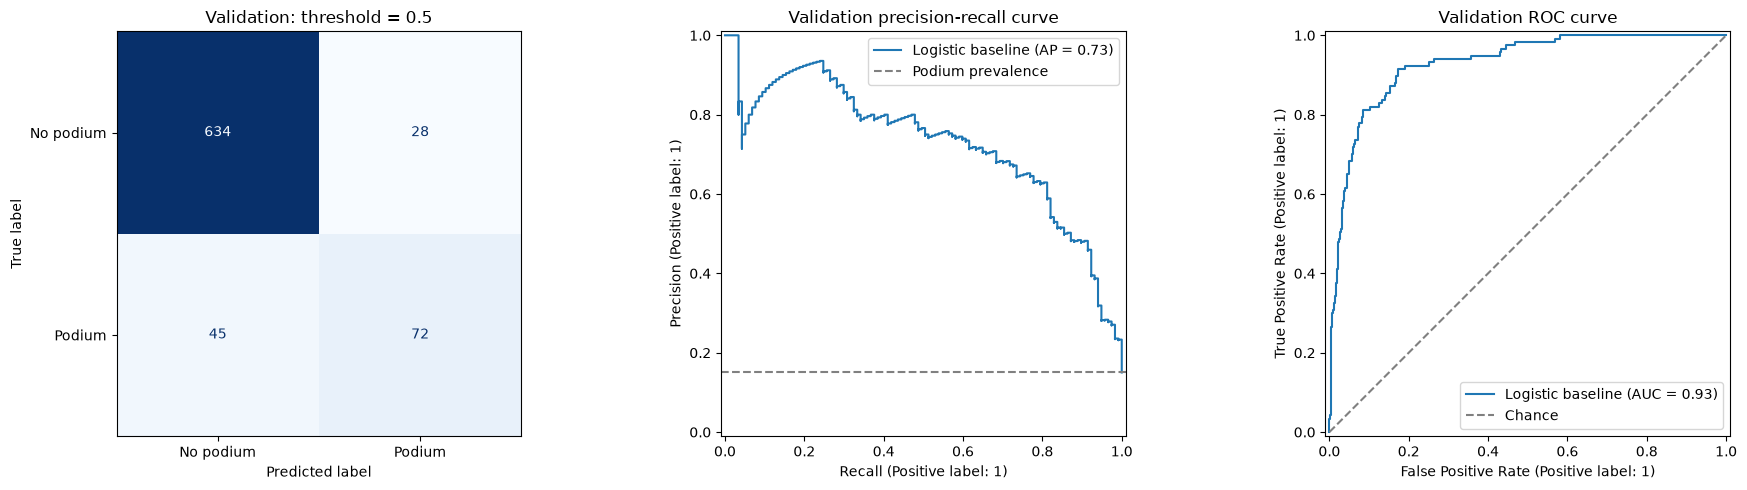

In [184]:
# Validation probabilities and classifications at the fixed threshold.
lr_validation_probability = lr_baseline.predict_proba(lr_X_validation)[:, 1]
assert np.isfinite(lr_validation_probability).all()
assert ((lr_validation_probability >= 0) & (lr_validation_probability <= 1)).all()
lr_validation_prediction = (lr_validation_probability >= LR_BASELINE_THRESHOLD).astype(int)

lr_baseline_metrics = pd.DataFrame([{
    "Model": "Logistic regression baseline", "Partition": "validation (2020-2021)",
    "Rows": len(lr_y_validation), "Threshold": LR_BASELINE_THRESHOLD,
    "ROC-AUC": roc_auc_score(lr_y_validation, lr_validation_probability),
    "PR-AUC (average precision)": average_precision_score(lr_y_validation, lr_validation_probability),
    "F1": f1_score(lr_y_validation, lr_validation_prediction, zero_division=0),
    "Precision": precision_score(lr_y_validation, lr_validation_prediction, zero_division=0),
    "Recall": recall_score(lr_y_validation, lr_validation_prediction, zero_division=0),
    "Predicted podium rows": int(lr_validation_prediction.sum()),
    "Validation podium rate": float(lr_y_validation.mean())
}])
with pd.option_context("display.max_columns", None, "display.precision", 4):
    display(lr_baseline_metrics)

lr_validation_predictions = lr_validation_rows[[*MODEL_KEY_COLUMNS, MODEL_TARGET]].copy()
lr_validation_predictions["podium_probability"] = lr_validation_probability
lr_validation_predictions["predicted_podium"] = lr_validation_prediction
lr_baseline_confusion_matrix = confusion_matrix(lr_y_validation, lr_validation_prediction, labels=[0, 1])

fig, axes = plt.subplots(1, 3, figsize=(19, 5))
ConfusionMatrixDisplay(lr_baseline_confusion_matrix, display_labels=["No podium", "Podium"]).plot(
    ax=axes[0], cmap="Blues", colorbar=False
)
axes[0].set_title("Validation: threshold = 0.5")
PrecisionRecallDisplay.from_predictions(
    lr_y_validation, lr_validation_probability, name="Logistic baseline", ax=axes[1]
)
axes[1].axhline(lr_y_validation.mean(), color="grey", linestyle="--", label="Podium prevalence")
axes[1].set_title("Validation precision-recall curve")
axes[1].legend()
RocCurveDisplay.from_predictions(
    lr_y_validation, lr_validation_probability, name="Logistic baseline", ax=axes[2]
)
axes[2].plot([0, 1], [0, 1], color="grey", linestyle="--", label="Chance")
axes[2].set_title("Validation ROC curve")
axes[2].legend()
plt.tight_layout()
plt.show()


In [185]:
# Coefficients follow the transformed order: numeric features, then binary flags.
lr_baseline_coefficients = pd.DataFrame({
    "Feature": lr_transformed_names,
    "Coefficient (log odds)": lr_baseline.named_steps["classifier"].coef_[0]
})
lr_baseline_coefficients["Group"] = lr_baseline_coefficients["Feature"].map(FE_GROUP_OF)
lr_baseline_coefficients["Unit of increase"] = lr_baseline_coefficients["Feature"].map(
    lambda c: "0 to 1" if c in LR_BASELINE_BINARY_FEATURES else "1 training standard deviation"
)
lr_baseline_coefficients["Absolute coefficient"] = lr_baseline_coefficients["Coefficient (log odds)"].abs()
lr_baseline_coefficients = lr_baseline_coefficients.sort_values(
    "Absolute coefficient", ascending=False
).reset_index(drop=True)
with pd.option_context("display.max_rows", 30, "display.max_columns", None, "display.precision", 4):
    display(lr_baseline_coefficients)
print("Intercept (log odds):", float(lr_baseline.named_steps["classifier"].intercept_[0]))
print("Positive coefficients increase predicted podium log odds, holding other inputs fixed.")
print("Coefficients describe this regularized model; they are not causal effects or significance tests.")


,Feature,Coefficient (log odds),Group,Unit of increase,Absolute coefficient
0,q1_time_missing,4.1974,qualifying,0 to 1,4.1974
1,grid_position,-2.1094,grid,1 training standard deviation,2.1094
2,pit_lane_start,-1.5974,grid,0 to 1,1.5974
3,has_quali_record,1.5455,qualifying,0 to 1,1.5455
4,constructor_standing_available,-0.4877,standings,0 to 1,0.4877
5,driver_prev_standing,-0.4636,standings,1 training standard deviation,0.4636
6,constructor_prev_points,-0.3299,standings,1 training standard deviation,0.3299
7,constructor_form_mean_finish,-0.3284,form,1 training standard deviation,0.3284
8,driver_prev_points,0.3125,standings,1 training standard deviation,0.3125
9,grid_penalty,0.2724,qualifying,1 training standard deviation,0.2724


Intercept (log odds): -4.959709943031972
Positive coefficients increase predicted podium log odds, holding other inputs fixed.
Coefficients describe this regularized model; they are not causal effects or significance tests.


### What the fitted logistic model learned

The coefficient for `grid_position` is **-2.1094**: increasing this numeric feature by one training standard deviation lowers the predicted log-odds of a podium, holding other inputs fixed. `driver_prev_standing` is also negative (**-0.4636**), while `driver_prev_points` is positive (**0.3126**). These fitted directions connect better starting positions and driver standings with higher predicted podium probability.

The largest absolute coefficient is `q1_time_missing` (**+4.1976**), but it is an **unscaled binary flag**: its coefficient describes a 0-to-1 change, whereas numeric coefficients describe a one-standard-deviation change. Coefficient magnitude alone therefore does not rank overall predictive importance. In particular, this positive flag coefficient does not establish that missing a qualifying time improves a driver's prospects. Likewise, the negative `constructor_prev_points` coefficient (**-0.3299**) is conditional on the other correlated features, not evidence that stronger constructors cause worse outcomes. Step 17 checks importance on actual validation predictions.

Validation AP is **0.7259** and ROC-AUC is **0.9298**. At the diagnostic 0.5 threshold, precision is **0.7200**, recall **0.6154**, and F1 **0.6636**: the model misses a substantial share of podiums at that cutoff. Step 18 reports the separately selected operating threshold.


In [186]:
# Save preprocessing + classifier with their input contract and evaluation metadata.
LR_BASELINE_MODEL_PATH = MODEL_DIR / "logistic_regression_baseline.joblib"
lr_baseline_bundle = {
    "pipeline": lr_baseline,
    "feature_columns": LR_BASELINE_FEATURES,
    "binary_features": LR_BASELINE_BINARY_FEATURES,
    "numeric_features": LR_BASELINE_NUMERIC_FEATURES,
    "target": MODEL_TARGET,
    "positive_class": 1,
    "threshold": LR_BASELINE_THRESHOLD,
    "selected_cv_parameters": {"C": LR_SELECTED_C, "selection_metric": "mean_cv_average_precision"},
    "train_seasons": [2006, 2019],
    "validation_seasons": [2020, 2021],
    "form_window": FORM_WINDOW,
    "home_definition": "Recorded nationality matches actual circuit country; step-8 country mappings",
    "validation_metrics": lr_baseline_metrics.iloc[0].to_dict(),
    "pr_auc_definition": "average_precision_score (not trapezoidal PR integration)",
    "versions": {
        "python": platform.python_version(),
        **{package: version(package) for package in ["scikit-learn", "scipy", "numpy", "pandas", "joblib"]}
    }
}
LR_BASELINE_MODEL_PATH.parent.mkdir(parents=True, exist_ok=True)
joblib.dump(lr_baseline_bundle, LR_BASELINE_MODEL_PATH, compress=3)

# Reload without refitting and check that the saved model reproduces predictions.
lr_reloaded_bundle = joblib.load(LR_BASELINE_MODEL_PATH)
np.testing.assert_allclose(
    lr_reloaded_bundle["pipeline"].predict_proba(
        lr_X_validation[lr_reloaded_bundle["feature_columns"]]
    )[:, 1],
    lr_validation_probability, rtol=1e-12, atol=1e-12
)
print(f"Saved reusable baseline: {LR_BASELINE_MODEL_PATH.resolve()}")
print("Reload check passed. No test-set evaluation was performed.")


Saved reusable baseline: /kaggle/working/models/logistic_regression_baseline.joblib
Reload check passed. No test-set evaluation was performed.


### Reuse the saved baseline

The save cell creates the file when you run it. Loading the bundle does not retrain the model. Use compatible package versions (recorded inside the bundle).

```python
import joblib

saved_baseline = joblib.load("models/logistic_regression_baseline.joblib")
# Example with existing validation records. New records must contain the same
# engineered pre-race features, calculated using the existing history rules.
inputs = lr_validation_rows[saved_baseline["feature_columns"]].astype("Float64").astype("float64")
probabilities = saved_baseline["pipeline"].predict_proba(inputs)[:, 1]
predictions = (probabilities >= saved_baseline["threshold"]).astype(int)
```

Supply all 23 feature columns. The pipeline imputes missing nonbinary values using training medians; binary flags must be available as 0/1. The artifact consumes engineered features and does not build them from raw race records.

Review `lr_baseline_metrics`, `lr_validation_predictions`, `lr_baseline_confusion_matrix`, and `lr_baseline_coefficients` after execution. The model uses the C selected in step 12c. This individual bundle retains the diagnostic 0.5 threshold; use the step-18 inference bundle for validation-selected thresholds.

## Histogram gradient boosting model (step 14)

This is the final HGB model using the three settings selected by step 12c's six training-only expanding CV folds. Median imputation is fitted on 2006-2019 only; binary flags pass through. This section's 0.5-threshold validation metrics are baseline diagnostics. Step 18 selects each model's final decision threshold from validation F1 and applies it unchanged to test.

- Use the same 23 features, target, and temporal rows as logistic regression.
- Select `max_iter`, `max_leaf_nodes`, and `min_samples_leaf` from the predeclared eight-candidate grid. Keep learning rate 0.05, `l2_regularization=0`, `class_weight=None`, `random_state=0`, and `early_stopping=False` fixed.
- Each CV fold fits preprocessing/model on earlier seasons and scores the following year; validation and test rows do not choose these settings.
- Save the pipeline and selected configuration to `models/hist_gradient_boosting_baseline.joblib`.

The tree model needs no scaling. Its global/local explanations are in step 17.

### Mechanics, rationale and limitations

Histogram gradient boosting bins numeric inputs and builds an additive sequence of decision trees to reduce classification log loss. Later trees update the current predictions; the learning rate controls the size of those updates. Splits can represent nonlinear effects and interactions without explicitly constructing every product or threshold feature. This makes HGB a useful comparison with additive logistic regression on the same tabular predictors. [Estimator documentation](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.HistGradientBoostingClassifier.html).

The chosen limits on leaves, leaf sample counts and iterations constrain model capacity. They do not guarantee protection against overfitting or changing season patterns. Tree splits do not require standardization. Although this estimator supports missing values natively, this project uses training-median imputation for a consistent preprocessing contract; native missing-value handling was not tested as a final-model alternative. The ensemble also needs post-hoc explanations because it has no single coefficient per feature.


In [187]:
# Imports and the same training/validation population used by logistic regression.
assert step12_validation_passed, "Run step 12 successfully first."

import platform
from importlib.metadata import version
import joblib
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    roc_auc_score, average_precision_score, f1_score, precision_score, recall_score,
    confusion_matrix, ConfusionMatrixDisplay, PrecisionRecallDisplay, RocCurveDisplay
)
from sklearn.pipeline import Pipeline

HGB_BASELINE_FEATURES = list(FE_FEATURE_COLUMNS)
HGB_BASELINE_BINARY_FEATURES = [
    "pit_lane_start", "has_quali_record", "q1_time_missing",
    "driver_standing_available", "constructor_standing_available", "is_home"
]
HGB_BASELINE_NUMERIC_FEATURES = [
    c for c in HGB_BASELINE_FEATURES if c not in HGB_BASELINE_BINARY_FEATURES
]
HGB_BASELINE_THRESHOLD = 0.5
assert len(HGB_BASELINE_FEATURES) == len(set(HGB_BASELINE_FEATURES)) == 23
assert set(HGB_BASELINE_BINARY_FEATURES) <= set(HGB_BASELINE_FEATURES)
assert len(HGB_BASELINE_NUMERIC_FEATURES) == 17
assert not set(MODEL_KEY_COLUMNS + [MODEL_TARGET]) & set(HGB_BASELINE_FEATURES)

hgb_train_rows = modeling_table_fe.loc[modeling_table_fe["partition"].eq("train")].copy()
hgb_validation_rows = modeling_table_fe.loc[modeling_table_fe["partition"].eq("validation")].copy()
assert len(hgb_train_rows) == 5760 and len(hgb_validation_rows) == 779
assert hgb_train_rows["year"].between(2006, 2019).all()
assert hgb_validation_rows["year"].between(2020, 2021).all()
assert set(hgb_train_rows["raceId"]).isdisjoint(hgb_validation_rows["raceId"])

hgb_X_train = hgb_train_rows[HGB_BASELINE_FEATURES].astype("Float64").astype("float64")
hgb_X_validation = hgb_validation_rows[HGB_BASELINE_FEATURES].astype("Float64").astype("float64")
hgb_y_train = hgb_train_rows[MODEL_TARGET].astype(int)
hgb_y_validation = hgb_validation_rows[MODEL_TARGET].astype(int)
for frame, target in [(hgb_X_train, hgb_y_train), (hgb_X_validation, hgb_y_validation)]:
    assert set(target.unique()) == {0, 1}
    assert frame[HGB_BASELINE_BINARY_FEATURES].notna().all().all()
    assert frame[HGB_BASELINE_BINARY_FEATURES].isin([0, 1]).all().all()
    assert not np.isinf(frame.to_numpy()).any()
assert hgb_X_train[HGB_BASELINE_NUMERIC_FEATURES].notna().any().all(), \
    "A feature has no observed training values; review before median imputation."

hgb_baseline_partition_summary = pd.DataFrame([
    {"Partition": name, "First season": int(rows["year"].min()),
     "Last season": int(rows["year"].max()), "Rows": len(rows),
     "Podium rows": int(rows[MODEL_TARGET].sum()), "Podium rate": rows[MODEL_TARGET].mean()}
    for name, rows in [("train", hgb_train_rows), ("validation", hgb_validation_rows)]
])
display(hgb_baseline_partition_summary)


,Partition,First season,Last season,Rows,Podium rows,Podium rate
0,train,2006,2019,5760,804,0.139583
1,validation,2020,2021,779,117,0.150193


In [188]:
# Fit the CV-selected HGB; median imputation learns only from training rows.
hgb_preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", SimpleImputer(strategy="median", keep_empty_features=True), HGB_BASELINE_NUMERIC_FEATURES),
        ("binary", "passthrough", HGB_BASELINE_BINARY_FEATURES)
    ],
    remainder="drop", verbose_feature_names_out=False
)
hgb_baseline = Pipeline([
    ("preprocessing", hgb_preprocessor),
    ("classifier", HistGradientBoostingClassifier(
        loss="log_loss", learning_rate=0.05, **HGB_SELECTED_PARAMS,
        l2_regularization=0.0,
        categorical_features=None, class_weight=None,
        early_stopping=False, random_state=0
    ))
])
hgb_baseline.fit(hgb_X_train, hgb_y_train)

assert np.array_equal(hgb_baseline.classes_, [0, 1])
hgb_fitted_preprocessor = hgb_baseline.named_steps["preprocessing"]
np.testing.assert_allclose(
    hgb_fitted_preprocessor.named_transformers_["numeric"].statistics_,
    hgb_X_train[HGB_BASELINE_NUMERIC_FEATURES].median().to_numpy()
)
hgb_transformed_names = hgb_fitted_preprocessor.get_feature_names_out().tolist()
assert len(hgb_transformed_names) == 23 and set(hgb_transformed_names) == set(HGB_BASELINE_FEATURES)
assert np.isfinite(hgb_fitted_preprocessor.transform(hgb_X_train)).all()
assert np.isfinite(hgb_fitted_preprocessor.transform(hgb_X_validation)).all()
assert not hgb_baseline.named_steps["classifier"].do_early_stopping_
assert hgb_baseline.named_steps["classifier"].n_iter_ == HGB_SELECTED_PARAMS["max_iter"]
assert all(hgb_baseline.named_steps["classifier"].get_params()[key] == value
           for key, value in HGB_SELECTED_PARAMS.items())
print(f"HGB baseline fitted on {len(hgb_X_train):,} training rows and 23 features.")
print("Boosting iterations:", hgb_baseline.named_steps["classifier"].n_iter_)


HGB baseline fitted on 5,760 training rows and 23 features.
Boosting iterations: 100


,Model,Partition,Rows,Threshold,ROC-AUC,PR-AUC (average precision),F1,Precision,Recall,Predicted podium rows,Validation podium rate
0,Histogram gradient boosting baseline,validation (2020-2021),779,0.5,0.9259,0.7115,0.6878,0.7308,0.6496,104,0.1502


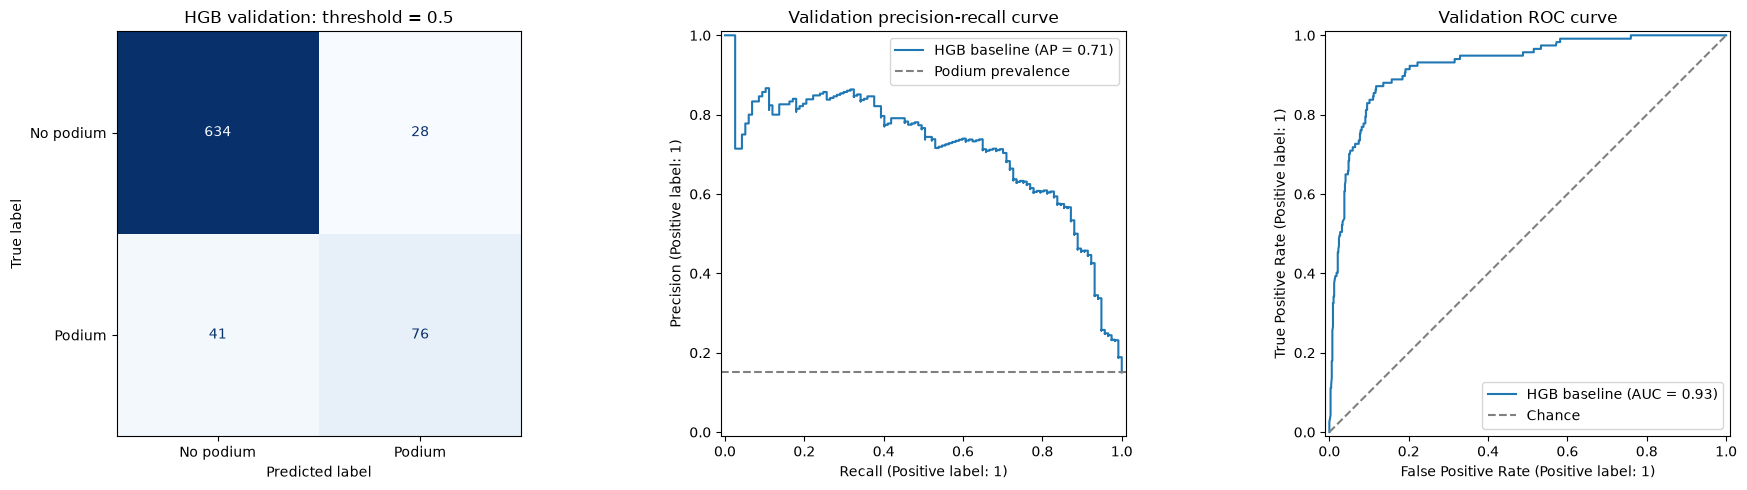

In [189]:
# Validation metrics use probabilities for AUC and threshold 0.5 for classifications.
def hgb_validation_metric_record(model_name, y_true, probabilities, threshold):
    probabilities = np.asarray(probabilities, dtype=float)
    assert len(probabilities) == len(y_true)
    assert np.isfinite(probabilities).all()
    assert ((probabilities >= 0) & (probabilities <= 1)).all()
    predictions = (probabilities >= threshold).astype(int)
    return {
        "Model": model_name, "Partition": "validation (2020-2021)",
        "Rows": len(y_true), "Threshold": threshold,
        "ROC-AUC": roc_auc_score(y_true, probabilities),
        "PR-AUC (average precision)": average_precision_score(y_true, probabilities),
        "F1": f1_score(y_true, predictions, zero_division=0),
        "Precision": precision_score(y_true, predictions, zero_division=0),
        "Recall": recall_score(y_true, predictions, zero_division=0),
        "Predicted podium rows": int(predictions.sum()),
        "Validation podium rate": float(y_true.mean())
    }

hgb_validation_probability = hgb_baseline.predict_proba(hgb_X_validation)[:, 1]
hgb_validation_prediction = (hgb_validation_probability >= HGB_BASELINE_THRESHOLD).astype(int)
hgb_baseline_metrics = pd.DataFrame([hgb_validation_metric_record(
    "Histogram gradient boosting baseline", hgb_y_validation,
    hgb_validation_probability, HGB_BASELINE_THRESHOLD
)])
with pd.option_context("display.max_columns", None, "display.precision", 4):
    display(hgb_baseline_metrics)

hgb_validation_predictions = hgb_validation_rows[[*MODEL_KEY_COLUMNS, MODEL_TARGET]].copy()
hgb_validation_predictions["podium_probability"] = hgb_validation_probability
hgb_validation_predictions["predicted_podium"] = hgb_validation_prediction
hgb_baseline_confusion_matrix = confusion_matrix(hgb_y_validation, hgb_validation_prediction, labels=[0, 1])

fig, axes = plt.subplots(1, 3, figsize=(19, 5))
ConfusionMatrixDisplay(hgb_baseline_confusion_matrix, display_labels=["No podium", "Podium"]).plot(
    ax=axes[0], cmap="Blues", colorbar=False
)
axes[0].set_title("HGB validation: threshold = 0.5")
PrecisionRecallDisplay.from_predictions(
    hgb_y_validation, hgb_validation_probability, name="HGB baseline", ax=axes[1]
)
axes[1].axhline(hgb_y_validation.mean(), color="grey", linestyle="--", label="Podium prevalence")
axes[1].set_title("Validation precision-recall curve")
axes[1].legend()
RocCurveDisplay.from_predictions(
    hgb_y_validation, hgb_validation_probability, name="HGB baseline", ax=axes[2]
)
axes[2].plot([0, 1], [0, 1], color="grey", linestyle="--", label="Chance")
axes[2].set_title("Validation ROC curve")
axes[2].legend()
plt.tight_layout()
plt.show()


In [190]:
# Compare with the saved logistic baseline on these exact validation rows.
# Recompute its metrics instead of copying scores from a potentially stale notebook output.
hgb_lr_comparison_path = MODEL_DIR / "logistic_regression_baseline.joblib"
hgb_baseline_comparison = hgb_baseline_metrics.copy()
if hgb_lr_comparison_path.exists():
    hgb_lr_reference = joblib.load(hgb_lr_comparison_path)
    assert hgb_lr_reference["feature_columns"] == HGB_BASELINE_FEATURES, "Logistic feature schema differs."
    assert hgb_lr_reference["binary_features"] == HGB_BASELINE_BINARY_FEATURES
    assert hgb_lr_reference["numeric_features"] == HGB_BASELINE_NUMERIC_FEATURES
    assert hgb_lr_reference["target"] == MODEL_TARGET
    assert hgb_lr_reference["train_seasons"] == [2006, 2019]
    assert hgb_lr_reference["validation_seasons"] == [2020, 2021]
    assert hgb_lr_reference["form_window"] == FORM_WINDOW
    assert hgb_lr_reference["threshold"] == HGB_BASELINE_THRESHOLD
    hgb_lr_pipeline = hgb_lr_reference["pipeline"]
    assert np.array_equal(hgb_lr_pipeline.classes_, [0, 1])
    # Compare fitted medians and the logistic scaler's training count as consistency checks.
    hgb_lr_numeric = hgb_lr_pipeline.named_steps["preprocessing"].named_transformers_["numeric"]
    np.testing.assert_allclose(
        hgb_lr_numeric.named_steps["imputer"].statistics_,
        hgb_fitted_preprocessor.named_transformers_["numeric"].statistics_
    )
    assert np.all(hgb_lr_numeric.named_steps["scaler"].n_samples_seen_ == len(hgb_X_train))
    hgb_lr_validation_probability = hgb_lr_pipeline.predict_proba(hgb_X_validation)[:, 1]
    hgb_lr_metrics = hgb_validation_metric_record(
        "Logistic regression baseline", hgb_y_validation,
        hgb_lr_validation_probability, HGB_BASELINE_THRESHOLD
    )
    hgb_baseline_comparison = pd.concat([
        pd.DataFrame([hgb_lr_metrics]), hgb_baseline_metrics
    ], ignore_index=True)
    with pd.option_context("display.max_columns", None, "display.precision", 4):
        display(hgb_baseline_comparison)
    hgb_metric_columns = ["ROC-AUC", "PR-AUC (average precision)", "F1", "Precision", "Recall"]
    hgb_baseline_deltas = pd.DataFrame({
        "Metric": hgb_metric_columns,
        "HGB minus logistic": [float(hgb_baseline_metrics.iloc[0][m]) - hgb_lr_metrics[m]
                               for m in hgb_metric_columns]
    })
    display(hgb_baseline_deltas)
    print("Both models scored on the same 779 validation rows; no refitting or test scoring.")
else:
    print("Logistic comparison skipped: run step 13's save cell, then rerun this comparison cell.")


,Model,Partition,Rows,Threshold,ROC-AUC,PR-AUC (average precision),F1,Precision,Recall,Predicted podium rows,Validation podium rate
0,Logistic regression baseline,validation (2020-2021),779,0.5,0.9298,0.7259,0.6636,0.7200,0.6154,100,0.1502
1,Histogram gradient boosting baseline,validation (2020-2021),779,0.5,0.9259,0.7115,0.6878,0.7308,0.6496,104,0.1502


,Metric,HGB minus logistic
0,ROC-AUC,-0.003893
1,PR-AUC (average precision),-0.014480
2,F1,0.024188
3,Precision,0.010769
4,Recall,0.034188


Both models scored on the same 779 validation rows; no refitting or test scoring.


In [191]:
# Save this baseline separately from the logistic model.
HGB_BASELINE_MODEL_PATH = MODEL_DIR / "hist_gradient_boosting_baseline.joblib"
hgb_baseline_bundle = {
    "pipeline": hgb_baseline,
    "feature_columns": HGB_BASELINE_FEATURES,
    "binary_features": HGB_BASELINE_BINARY_FEATURES,
    "numeric_features": HGB_BASELINE_NUMERIC_FEATURES,
    "target": MODEL_TARGET, "positive_class": 1,
    "threshold": HGB_BASELINE_THRESHOLD,
    "train_seasons": [2006, 2019], "validation_seasons": [2020, 2021],
    "form_window": FORM_WINDOW,
    "home_definition": "Recorded nationality matches actual circuit country; step-8 country mappings",
    "preprocessing": "Training median imputation for nonbinary features; binary passthrough; no scaling",
    "validation_metrics": hgb_baseline_metrics.iloc[0].to_dict(),
    "pr_auc_definition": "average_precision_score (not trapezoidal PR integration)",
    "classifier_parameters": hgb_baseline.named_steps["classifier"].get_params(),
    "selected_cv_parameters": {**HGB_SELECTED_PARAMS, "selection_metric": "mean_cv_average_precision"},
    "versions": {
        "python": platform.python_version(),
        **{package: version(package) for package in ["scikit-learn", "scipy", "numpy", "pandas", "joblib"]}
    }
}
HGB_BASELINE_MODEL_PATH.parent.mkdir(parents=True, exist_ok=True)
joblib.dump(hgb_baseline_bundle, HGB_BASELINE_MODEL_PATH, compress=3)
hgb_reloaded_bundle = joblib.load(HGB_BASELINE_MODEL_PATH)
np.testing.assert_allclose(
    hgb_reloaded_bundle["pipeline"].predict_proba(
        hgb_X_validation[hgb_reloaded_bundle["feature_columns"]]
    )[:, 1],
    hgb_validation_probability, rtol=1e-12, atol=1e-12
)
print(f"Saved reusable HGB baseline: {HGB_BASELINE_MODEL_PATH.resolve()}")
print("Reload check passed. No test-set evaluation was performed.")


Saved reusable HGB baseline: /kaggle/working/models/hist_gradient_boosting_baseline.joblib
Reload check passed. No test-set evaluation was performed.


### What HGB adds in the observed validation results

HGB validation AP is **0.7115**, below LR's **0.7259**, despite its higher mean training-fold CV AP. At threshold 0.5, HGB's F1 is **0.6878** versus LR's **0.6636**, with precision **0.7308** and recall **0.6496**. The improved classification result at one cutoff does not imply a better overall AP ranking. This difference is why the primary ranking metric and the threshold-dependent metrics are kept separate.

HGB's training AP is **0.7610**, compared with validation AP **0.7115**. That gap warrants caution about generalization, but these are different seasons; it cannot be attributed entirely to overfitting from this comparison alone.

### Reuse and next comparison

After running the save cell, load the HGB bundle without retraining:

```python
import joblib

saved_hgb = joblib.load("models/hist_gradient_boosting_baseline.joblib")
inputs = hgb_validation_rows[saved_hgb["feature_columns"]].astype("Float64").astype("float64")
probabilities = saved_hgb["pipeline"].predict_proba(inputs)[:, 1]
predictions = (probabilities >= saved_hgb["threshold"]).astype(int)
```

Supply all 23 engineered feature columns with the same pre-race definitions. Nonbinary missing values use stored training medians; binary flags must be known as 0/1. The saved model does not build features from raw data. Use a compatible environment with the package versions stored in the bundle.

Review `hgb_baseline_metrics`, `hgb_baseline_comparison`, `hgb_validation_predictions`, and `hgb_baseline_confusion_matrix`. Higher validation scores alone do not establish a statistically reliable improvement. Step 12c selects hyperparameters using training-only CV; step 15 fits the early-stopping NN. This individual bundle retains the diagnostic 0.5 threshold; use the step-18 inference bundle for validation-selected thresholds and final test reporting.


<a id="nn-early-stopping"></a>
## Neural network with early stopping (step 15)

**To reproduce this saved run, execute the setup cell and following four code cells in order after steps 1-14.**

This implements the lab callback's **patience=15, restore_best_weights=True** behavior
for the existing scikit-learn network. The architecture remains **23 -> 32 -> 16 -> 1**,
with the same Adam optimizer, batch size, learning rate, regularization and threshold.
This is the project’s sole neural-network model; later ablation and explanation sections use it.

- Fit preprocessing and weights on **2006-2017** only.
- Monitor **2018-2019** as a chronological stopping set within the training partition.
- Evaluate **2020-2021** only after restoring the checkpoint; **2022-2024 stays reserved**.
- Monitor **average precision (AP)**, the project's primary metric, rather than accuracy.
  A strictly higher score resets patience (`min_delta=0`). Ties/decreases count toward
  patience. Stop after **15 consecutive epochs without improvement**, at most 1,000 epochs.
- Restore the best checkpoint even if the epoch budget is reached. `partial_fit` runs
  one complete epoch and preserves Adam state; a deep copy preserves the best model.
  Built-in `early_stopping=False` is intentional because the loop implements stopping.

The stopping score is a selection diagnostic. The restored model is not refitted on
2018-2019, so it uses fewer weight-fitting seasons than a model trained on all 2006-2019
rows. The save cell writes `models/shallow_neural_network_early_stopping.joblib`.

The saved execution stopped after 34 epochs and restored epoch 19. Weight-fitting AP (2006-2017) is **0.737579**, stopping/selection AP (2018-2019) is **0.687825**, and validation AP (2020-2021) is **0.737901**. The artifact, ablation, XAI, and final test comparison all use this same early-stopping model; the test set is scored only in step 18.

### Mechanics and justification of the fixed design

The network has two hidden layers with **32 and 16 ReLU units**, followed by one sigmoid output, for **1,313 trainable weights and biases**. Successive learned transformations allow nonlinear combinations of the 23 predictors. Adam updates weights using minibatches of 64 with learning rate 0.001; `alpha=0.0001` supplies L2 regularization. Numeric scaling helps keep inputs on comparable scales during optimization. [Estimator documentation](https://scikit-learn.org/stable/modules/generated/sklearn.neural_network.MLPClassifier.html).

This compact architecture supplies a nonlinear neural comparison without a large network. Adam and the regularization settings define a reproducible training setup, while stopping on later training seasons controls training duration using the project's primary metric. These are design rationales, not evidence that these layer sizes or optimizer settings are best: no architecture, optimizer, learning-rate or regularization search is reported. Training optimizes a regularized log-loss objective, while checkpoint selection monitors AP; the two need not improve together.

Limitations include sensitivity to initialization and training settings, a single reported random seed, correlated inputs, and difficulty interpreting the learned transformations directly. The stopping set uses **839 entries from 2018–2019**, leaving **4,921 entries from 2006–2017** for weight fitting, versus **5,760 entries from 2006–2019** for LR/HGB. This is a valid holdout-based stopping protocol, but it means later model differences cannot be assigned solely to architecture. All three still use the same 23 predictors and the same external validation/test rows.


In [192]:
# Imports and train/validation inputs. Test rows are not selected.
nn_required_objects = [
    "step12_validation_passed", "FE_FEATURE_COLUMNS", "MODEL_KEY_COLUMNS",
    "MODEL_TARGET", "modeling_table_fe", "FORM_WINDOW"
]
nn_missing_objects = [name for name in nn_required_objects if name not in globals()]
if nn_missing_objects:
    raise RuntimeError(
        "Run steps 1-12 in this kernel first. Missing: " + ", ".join(nn_missing_objects)
    )
assert step12_validation_passed, "Run step 12 successfully first."

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
import warnings
import platform
from importlib.metadata import version
import joblib
from sklearn.compose import ColumnTransformer
from sklearn.exceptions import ConvergenceWarning
from sklearn.impute import SimpleImputer
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (
    roc_auc_score, average_precision_score, f1_score, precision_score, recall_score,
    confusion_matrix, ConfusionMatrixDisplay, PrecisionRecallDisplay, RocCurveDisplay
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

NN_EARLY_STOPPING_FEATURES = list(FE_FEATURE_COLUMNS)
NN_EARLY_STOPPING_BINARY_FEATURES = [
    "pit_lane_start", "has_quali_record", "q1_time_missing",
    "driver_standing_available", "constructor_standing_available", "is_home"
]
NN_EARLY_STOPPING_NUMERIC_FEATURES = [
    c for c in NN_EARLY_STOPPING_FEATURES if c not in NN_EARLY_STOPPING_BINARY_FEATURES
]
NN_EARLY_STOPPING_THRESHOLD = 0.5
assert len(NN_EARLY_STOPPING_FEATURES) == len(set(NN_EARLY_STOPPING_FEATURES)) == 23
assert set(NN_EARLY_STOPPING_BINARY_FEATURES) <= set(NN_EARLY_STOPPING_FEATURES)
assert len(NN_EARLY_STOPPING_NUMERIC_FEATURES) == 17
assert not set(MODEL_KEY_COLUMNS + [MODEL_TARGET]) & set(NN_EARLY_STOPPING_FEATURES)

nn_train_rows = modeling_table_fe.loc[modeling_table_fe["partition"].eq("train")].copy()
nn_validation_rows = modeling_table_fe.loc[modeling_table_fe["partition"].eq("validation")].copy()
assert len(nn_train_rows) == 5760 and len(nn_validation_rows) == 779
assert nn_train_rows["year"].between(2006, 2019).all()
assert nn_validation_rows["year"].between(2020, 2021).all()
assert set(nn_train_rows["raceId"]).isdisjoint(nn_validation_rows["raceId"])

# Convert pandas nullable missing values to NaN while preserving column names.
nn_X_train = nn_train_rows[NN_EARLY_STOPPING_FEATURES].astype("Float64").astype("float64")
nn_X_validation = nn_validation_rows[NN_EARLY_STOPPING_FEATURES].astype("Float64").astype("float64")
nn_y_train = nn_train_rows[MODEL_TARGET].astype(int)
nn_y_validation = nn_validation_rows[MODEL_TARGET].astype(int)
for frame, target in [(nn_X_train, nn_y_train), (nn_X_validation, nn_y_validation)]:
    assert set(target.unique()) == {0, 1}
    assert frame[NN_EARLY_STOPPING_BINARY_FEATURES].notna().all().all()
    assert frame[NN_EARLY_STOPPING_BINARY_FEATURES].isin([0, 1]).all().all()
    assert not np.isinf(frame.to_numpy()).any()
assert nn_X_train[NN_EARLY_STOPPING_NUMERIC_FEATURES].notna().any().all(), \
    "A feature has no observed training values; review before median imputation."

nn_es_template_partition_summary = pd.DataFrame([
    {"Partition": name, "First season": int(rows["year"].min()),
     "Last season": int(rows["year"].max()), "Rows": len(rows),
     "Podium rows": int(rows[MODEL_TARGET].sum()), "Podium rate": rows[MODEL_TARGET].mean()}
    for name, rows in [("train", nn_train_rows), ("validation", nn_validation_rows)]
])
display(nn_es_template_partition_summary)

assert not nn_train_rows.duplicated(["raceId", "driverId"]).any()
assert not nn_validation_rows.duplicated(["raceId", "driverId"]).any()

# Unfitted architecture and preprocessing template; the early-stopping helper fits fresh copies.
nn_numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median", keep_empty_features=True)),
    ("scaler", StandardScaler())
])
nn_preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", nn_numeric_pipeline, NN_EARLY_STOPPING_NUMERIC_FEATURES),
        ("binary", "passthrough", NN_EARLY_STOPPING_BINARY_FEATURES)
    ],
    remainder="drop", verbose_feature_names_out=False
)
nn_es_template = Pipeline([
    ("preprocessing", nn_preprocessor),
    ("classifier", MLPClassifier(
        hidden_layer_sizes=(32, 16), activation="relu", solver="adam",
        alpha=0.0001, batch_size=64, learning_rate_init=0.001,
        max_iter=1000, tol=1e-4, n_iter_no_change=20,
        shuffle=True, early_stopping=False, random_state=0
    ))
])

def nn_metric_record(model_name, partition, y_true, probabilities, threshold=0.5):
    probabilities = np.asarray(probabilities, dtype=float)
    assert probabilities.shape == (len(y_true),)
    assert np.isfinite(probabilities).all()
    assert ((probabilities >= 0) & (probabilities <= 1)).all()
    predictions = (probabilities >= threshold).astype(int)
    return {
        "Model": model_name, "Partition": partition,
        "Rows": len(y_true), "Threshold": threshold,
        "ROC-AUC": roc_auc_score(y_true, probabilities),
        "PR-AUC (average precision)": average_precision_score(y_true, probabilities),
        "F1": f1_score(y_true, predictions, zero_division=0),
        "Precision": precision_score(y_true, predictions, zero_division=0),
        "Recall": recall_score(y_true, predictions, zero_division=0),
        "Predicted podium rows": int(predictions.sum()),
        "Podium rate": float(np.mean(y_true))
    }


,Partition,First season,Last season,Rows,Podium rows,Podium rate
0,train,2006,2019,5760,804,0.139583
1,validation,2020,2021,779,117,0.150193


In [193]:
from copy import deepcopy
from sklearn.base import clone
from sklearn.metrics import log_loss


def nn_train_with_patience(template, X_fit, y_fit, X_stop, y_stop,
                           patience=15, max_epochs=1000, min_delta=0.0):
    """Restore best stopping AP; caller provides chronological, race-disjoint sets."""
    if patience < 1 or max_epochs < 1 or min_delta < 0:
        raise ValueError("patience/max_epochs must be positive; min_delta must be nonnegative.")
    if set(np.unique(y_fit)) != {0, 1} or set(np.unique(y_stop)) != {0, 1}:
        raise ValueError("Fitting and stopping sets must each contain both target classes.")
    preprocessor = clone(template.named_steps["preprocessing"])
    Xt_fit = preprocessor.fit_transform(X_fit, y_fit)
    Xt_stop = preprocessor.transform(X_stop)
    if not np.isfinite(Xt_fit).all() or not np.isfinite(Xt_stop).all():
        raise ValueError("Preprocessing produced nonfinite values.")
    classifier = clone(template.named_steps["classifier"])
    if classifier.solver != "adam":
        raise ValueError("This loop is configured for the existing Adam network.")
    # One persistent RNG advances the minibatch shuffle reproducibly across epochs.
    classifier.set_params(early_stopping=False, n_iter_no_change=max_epochs + 1,
                          random_state=np.random.RandomState(0))
    best_score, best_epoch, stale_epochs = -np.inf, None, 0
    best_classifier, best_probability = None, None
    history = []
    stop_reason = "max_epochs"
    for epoch in range(1, max_epochs + 1):
        classifier.partial_fit(Xt_fit, y_fit, classes=np.array([0, 1]))
        probability = classifier.predict_proba(Xt_stop)[:, 1]
        score = float(average_precision_score(y_stop, probability))
        objective = float(classifier.loss_)
        stopping_loss = float(log_loss(y_stop, probability, labels=[0, 1]))
        if not np.isfinite([score, objective, stopping_loss]).all():
            raise RuntimeError(f"Nonfinite training/stopping metric at epoch {epoch}.")
        improved = score > best_score + min_delta
        if improved:
            best_score, best_epoch, stale_epochs = score, epoch, 0
            best_classifier = deepcopy(classifier)
            best_probability = probability.copy()
        else:
            stale_epochs += 1
        history.append({"Epoch": epoch, "Training objective": objective,
                        "Stopping AP": score, "Stopping log loss": stopping_loss,
                        "Improved": improved, "Epochs without improvement": stale_epochs})
        if stale_epochs >= patience:
            stop_reason = "patience"
            break
    restored = Pipeline([("preprocessing", preprocessor), ("classifier", best_classifier)])
    np.testing.assert_allclose(restored.predict_proba(X_stop)[:, 1], best_probability,
                               rtol=1e-12, atol=1e-12)
    info = {"monitor": "average_precision", "mode": "max", "patience": patience,
            "min_delta": min_delta, "max_epochs": max_epochs,
            "best_epoch": best_epoch, "epochs_run": len(history),
            "best_stopping_ap": best_score, "stop_reason": stop_reason,
            "restore_best_weights": True, "random_seed": 0}
    return restored, pd.DataFrame(history), info

In [194]:
# The unfitted template supplies architecture settings only; each fit starts from fresh weights.
nn_es_fit_completed = False
NN_ES_PATIENCE = 15
NN_ES_MAX_EPOCHS = 1000
NN_ES_MIN_DELTA = 0.0
nn_es_fit_rows = nn_train_rows.loc[nn_train_rows["year"].between(2006, 2017)].copy()
nn_es_stop_rows = nn_train_rows.loc[nn_train_rows["year"].between(2018, 2019)].copy()
assert len(nn_es_fit_rows) + len(nn_es_stop_rows) == len(nn_train_rows)
assert not nn_es_fit_rows.empty and not nn_es_stop_rows.empty
assert nn_es_fit_rows["date"].max() < nn_es_stop_rows["date"].min()
assert nn_es_stop_rows["date"].max() < nn_validation_rows["date"].min()
assert set(nn_es_fit_rows["raceId"]).isdisjoint(nn_es_stop_rows["raceId"])
assert set(nn_train_rows["raceId"]).isdisjoint(nn_validation_rows["raceId"])
nn_es_X_fit = nn_es_fit_rows[NN_EARLY_STOPPING_FEATURES].astype("Float64").astype("float64")
nn_es_X_stop = nn_es_stop_rows[NN_EARLY_STOPPING_FEATURES].astype("Float64").astype("float64")
nn_es_y_fit = nn_es_fit_rows[MODEL_TARGET].astype(int)
nn_es_y_stop = nn_es_stop_rows[MODEL_TARGET].astype(int)
assert nn_es_X_fit[NN_EARLY_STOPPING_NUMERIC_FEATURES].notna().any().all()
nn_es_pipeline, nn_es_history, nn_es_info = nn_train_with_patience(
    nn_es_template, nn_es_X_fit, nn_es_y_fit, nn_es_X_stop, nn_es_y_stop,
    patience=NN_ES_PATIENCE, max_epochs=NN_ES_MAX_EPOCHS, min_delta=NN_ES_MIN_DELTA
)
nn_es_numeric = nn_es_pipeline.named_steps["preprocessing"].named_transformers_["numeric"]
np.testing.assert_allclose(nn_es_numeric.named_steps["imputer"].statistics_,
                           nn_es_X_fit[NN_EARLY_STOPPING_NUMERIC_FEATURES].median().to_numpy())
assert np.all(nn_es_numeric.named_steps["scaler"].n_samples_seen_ == len(nn_es_X_fit))
assert [
    w.shape
    for w in nn_es_pipeline.named_steps["classifier"].coefs_
] == [(N_FEATURES, 32), (32, 16), (16, 1)]
nn_es_fit_completed = True
print(f"Fitting rows: {len(nn_es_fit_rows):,}; stopping rows: {len(nn_es_stop_rows):,}")
print(f"Stopped after {nn_es_info['epochs_run']} epochs ({nn_es_info['stop_reason']}). "
      f"Restored epoch {nn_es_info['best_epoch']}; stopping AP = {nn_es_info['best_stopping_ap']:.4f}.")

Fitting rows: 4,921; stopping rows: 839
Stopped after 34 epochs (patience). Restored epoch 19; stopping AP = 0.6878.


,Model,Partition,Rows,Threshold,ROC-AUC,PR-AUC (average precision),F1,Precision,Recall,Predicted podium rows,Podium rate
0,NN with early stopping,weight fitting (2006-2017),4921,0.5,0.9435,0.7376,0.6729,0.7129,0.6372,606,0.1378
1,NN with early stopping,stopping / selection (2018-2019),839,0.5,0.9342,0.6878,0.6721,0.6949,0.6508,118,0.1502
2,NN with early stopping,validation (2020-2021),779,0.5,0.9293,0.7379,0.6606,0.7129,0.6154,101,0.1502


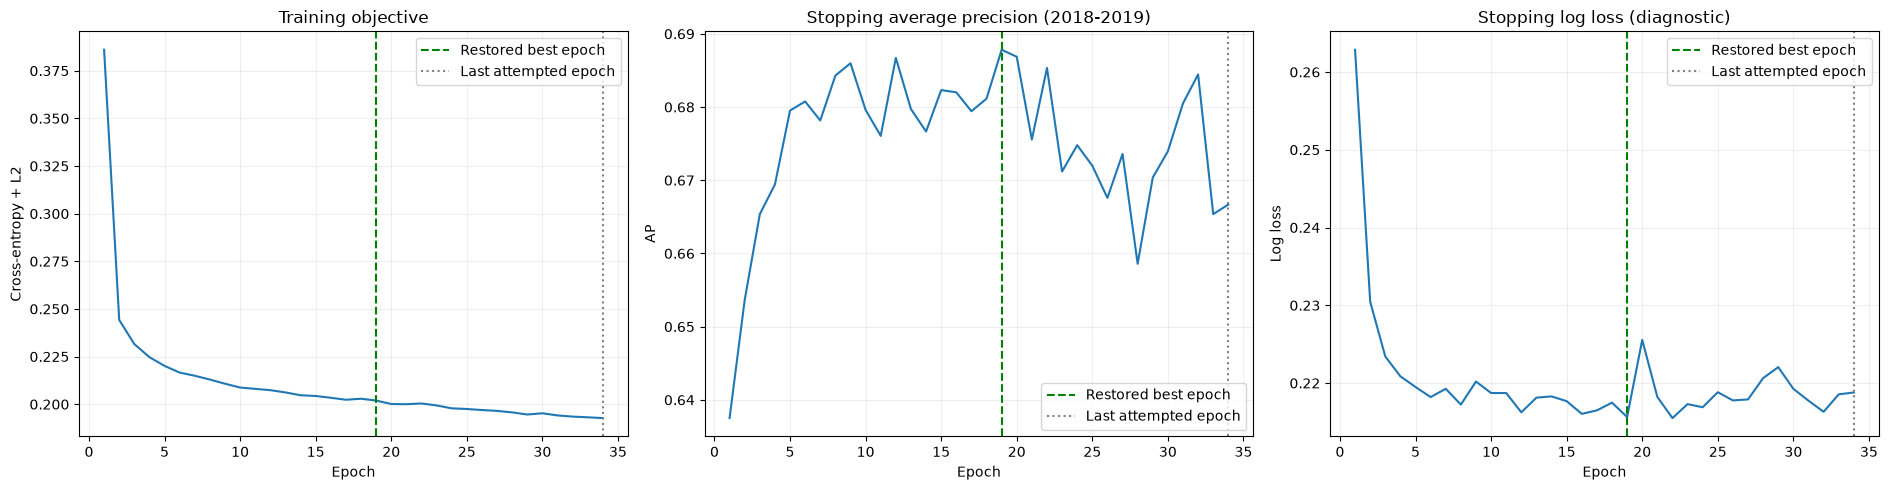

Stopping-set scores are selection diagnostics. Use external validation for comparison.


In [195]:
assert nn_es_fit_completed, "Run the early-stopping fit cell first."
nn_es_metrics = pd.DataFrame([
    nn_metric_record("NN with early stopping", label, target,
                     nn_es_pipeline.predict_proba(inputs)[:, 1], NN_EARLY_STOPPING_THRESHOLD)
    for label, inputs, target in [
        ("weight fitting (2006-2017)", nn_es_X_fit, nn_es_y_fit),
        ("stopping / selection (2018-2019)", nn_es_X_stop, nn_es_y_stop),
        ("validation (2020-2021)", nn_X_validation, nn_y_validation)
    ]
])
nn_es_validation_probability = nn_es_pipeline.predict_proba(nn_X_validation)[:, 1]
with pd.option_context("display.max_columns", None, "display.precision", 4):
    display(nn_es_metrics)

fig, axes = plt.subplots(1, 3, figsize=(19, 5))
axes[0].plot(nn_es_history["Epoch"], nn_es_history["Training objective"])
axes[0].set(title="Training objective", xlabel="Epoch", ylabel="Cross-entropy + L2")
axes[1].plot(nn_es_history["Epoch"], nn_es_history["Stopping AP"])
axes[1].set(title="Stopping average precision (2018-2019)", xlabel="Epoch", ylabel="AP")
axes[2].plot(nn_es_history["Epoch"], nn_es_history["Stopping log loss"])
axes[2].set(title="Stopping log loss (diagnostic)", xlabel="Epoch", ylabel="Log loss")
for ax in axes:
    ax.axvline(nn_es_info["best_epoch"], color="green", linestyle="--", label="Restored best epoch")
    ax.axvline(nn_es_info["epochs_run"], color="grey", linestyle=":", label="Last attempted epoch")
    ax.legend()
    ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()
print("Stopping-set scores are selection diagnostics. Use external validation for comparison.")

### Reading the learning curves and restored checkpoint

Stopping AP rises from **0.6375** at epoch 1 to its best value of **0.6878 at epoch 19**. By epoch 34, it is **0.6667**, and 15 consecutive epochs have failed to exceed the best score. The loop therefore stops and restores epoch 19.

Between epochs 19 and 34, the training objective continues to fall (**0.2019 → 0.1927**), but stopping log loss rises (**0.2156 → 0.2188**). Continued optimization on fitting rows did not improve the monitored later-season ranking. These observed curves justify restoring the earlier checkpoint rather than retaining the last epoch; they do not establish that epoch 19 would be optimal for another seed or season split.

The restored NN has weight-fitting AP **0.7376**, stopping AP **0.6878**, and external validation AP **0.7379**. Its validation AP is higher than LR/HGB's in this run, but validation F1 at the diagnostic threshold 0.5 is **0.6606**, below both. The higher validation AP than stopping AP compares different seasons and is not evidence of leakage or proof of consistently better future performance. Threshold selection and the test comparison follow in step 18.


In [196]:
# Save the restored early-stopping checkpoint.
assert nn_es_fit_completed, "Run the early-stopping fit cell first."
np.testing.assert_allclose(nn_es_pipeline.predict_proba(nn_X_validation)[:, 1],
                           nn_es_validation_probability, rtol=1e-12, atol=1e-12)
NN_ES_MODEL_PATH = MODEL_DIR / "shallow_neural_network_early_stopping.joblib"
nn_es_bundle = {
    "pipeline": nn_es_pipeline,
    "feature_columns": list(NN_EARLY_STOPPING_FEATURES),
    "numeric_features": list(NN_EARLY_STOPPING_NUMERIC_FEATURES),
    "binary_features": list(NN_EARLY_STOPPING_BINARY_FEATURES),
    "target": MODEL_TARGET, "positive_class": 1, "threshold": NN_EARLY_STOPPING_THRESHOLD,
    "train_seasons": [2006, 2017], "stopping_seasons": [2018, 2019],
    "validation_seasons": [2020, 2021], "form_window": FORM_WINDOW,
    "architecture": [len(NN_EARLY_STOPPING_FEATURES), 32, 16, 1],
    "parameter_count": sum(
        a.size
        for a in (
            nn_es_pipeline.named_steps["classifier"].coefs_
            + nn_es_pipeline.named_steps["classifier"].intercepts_
        )
    ),
    "preprocessing": "2006-2017 median imputation and numeric scaling; binary passthrough",
    "home_definition": "Recorded nationality matches circuit country; step-8 mappings",
    "early_stopping": dict(nn_es_info),
    "epochs_completed": nn_es_info["epochs_run"], "best_epoch": nn_es_info["best_epoch"],
    "history": nn_es_history.to_dict("records"),
    "training_metrics": nn_es_metrics.iloc[0].to_dict(),
    "stopping_metrics": nn_es_metrics.iloc[1].to_dict(),
    "validation_metrics": nn_es_metrics.iloc[2].to_dict(),
    "pr_auc_definition": "average_precision_score",
    "versions": {"python": platform.python_version(),
                 **{package: version(package) for package in ["scikit-learn", "numpy", "pandas", "joblib"]}}
}
NN_ES_MODEL_PATH.parent.mkdir(parents=True, exist_ok=True)
joblib.dump(nn_es_bundle, NN_ES_MODEL_PATH, compress=3)
nn_es_reloaded = joblib.load(NN_ES_MODEL_PATH)
np.testing.assert_allclose(nn_es_reloaded["pipeline"].predict_proba(nn_X_validation)[:, 1],
                           nn_es_validation_probability, rtol=1e-12, atol=1e-12)
print(f"Saved restored epoch {nn_es_info['best_epoch']}: {NN_ES_MODEL_PATH.resolve()}")
print("Reload predictions match. No test-set evaluation performed.")

Saved restored epoch 19: /kaggle/working/models/shallow_neural_network_early_stopping.joblib
Reload predictions match. No test-set evaluation performed.


## Feature-group ablation (step 16)

> **Updated 16 October 2026: uses the step-15 early-stopping NN.** Full-set validation PR-AUC must match **0.7379005251** for the current saved artifact.

**Question.** Step 12 justified each feature *before* training with exploratory evidence (training-season univariate ROC-AUC, mutual information, correlations, binned podium rates) and with cumulative feature-set trials. An ablation measures each group's contribution *after* training: remove one group, retrain from scratch, and see how much performance drops.

**Protocol**
- **Groups** come from `FE_FEATURE_GROUPS`: grid (2 features), qualifying (4), standings (8), form (8), geography (1, `is_home`). Each is removed on its own (leave-one-group-out). A **supplementary** run removes grid and qualifying together, because both describe the starting position: `grid_position` and `q1_gap_to_fastest_pct` can partly stand in for each other, so removing only one of them can hide how much the starting position matters.
- **Models:** logistic regression, histogram gradient boosting, and the **neural network with early stopping from step 15** (`models/shallow_neural_network_early_stopping.joblib`). Their classifier settings are copied from the saved bundles with `clone()` (settings only; nothing fitted is reused). Each run rebuilds the same preprocessing for the reduced column list: training-median imputation, scaling for logistic regression and the NN, binary flags passed through. The NN holds out the last two training seasons for stopping (patience 15 on average precision), fits weights and preprocessing on earlier seasons, and retains the best checkpoint without refitting. For validation, weights fit on 2006-2017 and stopping uses 2018-2019, exactly as in step 15. Outer scoring rows never choose the epoch.
- **Scores:**
  - The **six expanding time-series folds** inside training (fit 2006..y-1, score y, y = 2014-2019) are the main evidence. This is the same protocol used for the step-12 feature decisions. We report the mean PR-AUC, the paired mean drop versus the full set, its spread, and how many of the six folds got worse.
  - LR/HGB fit on 2006-2019; NN weights fit on 2006-2017 with stopping on 2018-2019. Scoring on **validation 2020-2021** gives ROC-AUC, PR-AUC and F1 at the baselines' fixed 0.5 threshold.
  - **Drop = full-set score - ablated score**, so a positive drop means the group helped.
- **No test rows** are used (`year <= 2021` is asserted). The full-set validation runs must reproduce the saved baselines' validation PR-AUC, which checks that the reruns match the baselines.
- **Reading the results:** an ablation drop measures what the *other* groups cannot replace. A small drop does not mean a group carries no information. It can mean that information is redundant with another group.

Runtime: 7 feature sets x 3 models x 7 splits = 147 model evaluations. Each NN evaluation includes internal stopping and best-checkpoint restoration; the four-worker run may take several minutes.

In [197]:
# Ablation setup: reuse the exact classifier settings saved in steps 13-15 (unfitted clones).
ablation_required_objects = [
    "step12_validation_passed", "modeling_table_fe", "FE_FEATURE_COLUMNS", "FE_FEATURE_GROUPS",
    "TIME_SERIES_CV_FOLDS", "MODEL_TARGET", "FORM_WINDOW", "feature_univariate_train",
    "nn_train_with_patience"
]
ablation_missing_objects = [name for name in ablation_required_objects if name not in globals()]
if ablation_missing_objects:
    raise RuntimeError("Run steps 1-14 and the step-15 setup first. Missing: " + ", ".join(ablation_missing_objects))
assert step12_validation_passed, "Run step 12 successfully first."

import time
import warnings
from pathlib import Path
import joblib
from joblib import Parallel, delayed, parallel_config
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.exceptions import ConvergenceWarning
from sklearn.impute import SimpleImputer
from sklearn.metrics import average_precision_score, f1_score, roc_auc_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

ABLATION_THRESHOLD = 0.5
ABLATION_BINARY_FEATURES = [
    "pit_lane_start", "has_quali_record", "q1_time_missing",
    "driver_standing_available", "constructor_standing_available", "is_home"
]
# Each saved baseline supplies its classifier settings; scale=True means the model was trained
# with standard scaling of the nonbinary features (logistic and NN), False for the tree model.
ABLATION_MODEL_SOURCES = {
    "Logistic regression": ((MODEL_DIR / "logistic_regression_baseline.joblib"), True),
    "Histogram gradient boosting": ((MODEL_DIR / "hist_gradient_boosting_baseline.joblib"), False),
    "Neural network with early stopping": ((MODEL_DIR / "shallow_neural_network_early_stopping.joblib"), True),
}
ablation_classifiers = {}
ablation_nn_settings = None
for model_name, (model_path, scale) in ABLATION_MODEL_SOURCES.items():
    if not Path(model_path).exists():
        raise FileNotFoundError(f"{model_path} is missing: run the save cell of steps 13-15 first.")
    bundle = joblib.load(model_path)
    assert bundle["feature_columns"] == list(FE_FEATURE_COLUMNS), f"{model_name}: feature schema differs."
    assert bundle["binary_features"] == ABLATION_BINARY_FEATURES
    assert bundle["validation_seasons"] == [2020, 2021]
    assert bundle["form_window"] == FORM_WINDOW and bundle["threshold"] == ABLATION_THRESHOLD
    if model_name == "Neural network with early stopping":
        assert bundle["train_seasons"] == [2006, 2017]
        assert bundle["stopping_seasons"] == [2018, 2019]
        procedure = bundle["early_stopping"]
        assert procedure["monitor"] == "average_precision" and procedure["mode"] == "max"
        assert procedure["restore_best_weights"] and procedure["random_seed"] == 0
        ablation_nn_settings = {key: procedure[key] for key in
                                ["patience", "max_epochs", "min_delta"]}
        ablation_nn_settings["stopping_seasons"] = 2
        print(f"Step 15b NN: {model_path}; best epoch {bundle['best_epoch']}; "
              f"saved validation PR-AUC {bundle['validation_metrics']['PR-AUC (average precision)']:.10f}")
    else:
        assert bundle["train_seasons"] == [2006, 2019]
    # clone() copies hyperparameters only: nothing fitted is reused, every run retrains from scratch.
    ablation_classifiers[model_name] = (clone(bundle["pipeline"].named_steps["classifier"]), scale)

def ablation_fit_nn(template, X, y, years, patience=15, max_epochs=1000,
                    min_delta=0.0, stopping_seasons=2):
    """Step 15b: retain the best checkpoint; never refit on stopping rows."""
    years, y = np.asarray(years), np.asarray(y)
    if len(X) != len(y) or len(X) != len(years):
        raise ValueError("X, y and years must have equal lengths.")
    seasons = np.sort(np.unique(years))
    if stopping_seasons < 1 or len(seasons) <= stopping_seasons:
        raise ValueError("Need earlier fitting seasons plus the stopping seasons.")
    stop = np.isin(years, seasons[-stopping_seasons:])
    fit = ~stop
    assert years[fit].max() < years[stop].min()
    model, history, info = nn_train_with_patience(
        template, X.loc[fit], y[fit], X.loc[stop], y[stop],
        patience=patience, max_epochs=max_epochs, min_delta=min_delta
    )
    info.update({"weight_fit_last_season": int(years[fit].max()),
                 "selection_last_season": int(years[stop].max()),
                 "weight_fit_rows": int(fit.sum()), "stopping_rows": int(stop.sum())})
    return model, history, info


def ablation_pipeline(model_name, columns):
    """Same preprocessing recipe as steps 13-15, rebuilt for a reduced column list."""
    classifier, scale = ablation_classifiers[model_name]
    binary = [c for c in columns if c in ABLATION_BINARY_FEATURES]
    numeric = [c for c in columns if c not in ABLATION_BINARY_FEATURES]
    numeric_steps = [("imputer", SimpleImputer(strategy="median", keep_empty_features=True))]
    if scale:
        numeric_steps.append(("scaler", StandardScaler()))
    preprocessor = ColumnTransformer(
        [("numeric", Pipeline(numeric_steps), numeric), ("binary", "passthrough", binary)],
        remainder="drop", verbose_feature_names_out=False
    )
    return Pipeline([("preprocessing", preprocessor), ("classifier", clone(classifier))])

# Feature sets: the full set, then one group removed at a time (leave-one-group-out).
# Supplementary: grid and qualifying together, because both describe the starting position
# (grid_position and q1_gap_to_fastest_pct overlap), so removing one can be masked by the other.
ABLATION_SETS = {"Full (all 23 features)": list(FE_FEATURE_COLUMNS)}
for group, group_columns in FE_FEATURE_GROUPS.items():
    ABLATION_SETS[f"without {group}"] = [c for c in FE_FEATURE_COLUMNS if c not in group_columns]
ABLATION_SETS["without grid + qualifying (supplementary)"] = [
    c for c in FE_FEATURE_COLUMNS
    if c not in FE_FEATURE_GROUPS["grid"] + FE_FEATURE_GROUPS["qualifying"]
]
ablation_set_summary = pd.DataFrame([
    {"Feature set": name, "Features kept": len(cols),
     "Removed": ", ".join(c for c in FE_FEATURE_COLUMNS if c not in cols) or "-"}
    for name, cols in ABLATION_SETS.items()
])
with pd.option_context("display.max_colwidth", 140, "display.width", 220):
    display(ablation_set_summary)

# Inputs: training seasons only for CV; one training fit scored on validation. No test rows.
ablation_frame = modeling_table_fe.loc[modeling_table_fe["partition"].isin(["train", "validation"])].reset_index(drop=True)
assert ablation_frame["year"].max() <= 2021
ablation_X = ablation_frame[FE_FEATURE_COLUMNS].astype("Float64").astype("float64")
ablation_y = ablation_frame[MODEL_TARGET].astype(int).to_numpy()
ablation_splits = {
    f"CV {score_years[0]}": (ablation_frame["year"].isin(train_years).to_numpy(),
                             ablation_frame["year"].isin(score_years).to_numpy())
    for train_years, score_years in TIME_SERIES_CV_FOLDS
}
ablation_splits["validation 2020-2021"] = (ablation_frame["partition"].eq("train").to_numpy(),
                                           ablation_frame["partition"].eq("validation").to_numpy())
assert all(ablation_frame.loc[fit, "year"].max() < ablation_frame.loc[score, "year"].min()
           for fit, score in ablation_splits.values()), "Every split must fit on earlier seasons only."
print(f"{len(ABLATION_SETS)} feature sets x {len(ablation_classifiers)} models x "
      f"{len(ablation_splits)} splits = {len(ABLATION_SETS) * len(ablation_classifiers) * len(ablation_splits)} fits.")

Step 15b NN: /kaggle/working/models/shallow_neural_network_early_stopping.joblib; best epoch 19; saved validation PR-AUC 0.7379005251


,Feature set,Features kept,Removed
0,Full (all 23 features),23,-
1,without grid,21,"grid_position, pit_lane_start"
2,without qualifying,19,"has_quali_record, grid_penalty, q1_gap_to_fastest_pct, q1_time_missing"
3,without standings,15,"driver_prev_points, driver_prev_standing, driver_prev_wins, driver_standing_available, constructor_prev_points, constructor_prev_standin..."
4,without form,15,"driver_form_races, driver_form_podium_rate, driver_form_mean_finish, driver_form_mech_dnf_rate, constructor_form_races, constructor_form..."
5,without geography,22,is_home
6,without grid + qualifying (supplementary),17,"grid_position, pit_lane_start, has_quali_record, grid_penalty, q1_gap_to_fastest_pct, q1_time_missing"


7 feature sets x 3 models x 7 splits = 147 fits.


In [198]:
# Retrain every model on every reduced feature set (runs in parallel; NN fits dominate the time).
def ablation_run(set_name, model_name, split_name):
    columns = ABLATION_SETS[set_name]
    fit_rows, score_rows = ablation_splits[split_name]
    model = ablation_pipeline(model_name, columns)
    selected_epochs = np.nan
    selection_last_year = np.nan
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter("always", ConvergenceWarning)
        if model_name == "Neural network with early stopping":
            model, _, info = ablation_fit_nn(
                model, ablation_X.loc[fit_rows, columns], ablation_y[fit_rows],
                ablation_frame.loc[fit_rows, "year"].to_numpy(), **ablation_nn_settings
            )
            selected_epochs = info["best_epoch"]
            selection_last_year = info["selection_last_season"]
            assert selection_last_year < ablation_frame.loc[score_rows, "year"].min()
            assert info["weight_fit_rows"] + info["stopping_rows"] == int(fit_rows.sum())
            assert info["weight_fit_last_season"] < selection_last_year
        else:
            model.fit(ablation_X.loc[fit_rows, columns], ablation_y[fit_rows])
    probability = model.predict_proba(ablation_X.loc[score_rows, columns])[:, 1]
    y_true = ablation_y[score_rows]
    if (model_name == "Neural network with early stopping"
            and set_name == "Full (all 23 features)" and split_name == "validation 2020-2021"):
        saved = joblib.load(ABLATION_MODEL_SOURCES[model_name][0])
        np.testing.assert_allclose(
            probability, saved["pipeline"].predict_proba(ablation_X.loc[score_rows, columns])[:, 1],
            rtol=1e-10, atol=1e-12,
            err_msg="Full-set NN must reproduce the step-15 checkpoint."
        )
    return {
        "Feature set": set_name, "Model": model_name, "Split": split_name,
        "ROC-AUC": roc_auc_score(y_true, probability),
        "PR-AUC": average_precision_score(y_true, probability),
        "F1 at 0.5": f1_score(y_true, (probability >= ABLATION_THRESHOLD).astype(int), zero_division=0),
        "Selected epochs": selected_epochs, "Selection last season": selection_last_year,
        "Evaluation first season": int(ablation_frame.loc[score_rows, "year"].min()),
        "Convergence warning": any(issubclass(w.category, ConvergenceWarning) for w in caught),
    }

ablation_start = time.time()
with parallel_config(backend="loky", inner_max_num_threads=1):
    ablation_runs = pd.DataFrame(Parallel(n_jobs=N_JOBS, backend="loky")(
        delayed(ablation_run)(s, m, p)
        for s in ABLATION_SETS for m in ablation_classifiers for p in ablation_splits
    ))
print(f"Ablation finished in {time.time() - ablation_start:.0f} s; "
      f"{int(ablation_runs['Convergence warning'].sum())} runs reported a convergence warning.")

# Consistency check: the full-set validation fit must reproduce the saved baselines' validation PR-AUC.
for model_name, (model_path, _) in ABLATION_MODEL_SOURCES.items():
    saved_ap = joblib.load(model_path)["validation_metrics"]["PR-AUC (average precision)"]
    rerun_ap = ablation_runs.query(
        "`Feature set` == 'Full (all 23 features)' and Model == @model_name and Split == 'validation 2020-2021'"
    )["PR-AUC"].item()
    assert np.isclose(saved_ap, rerun_ap, atol=1e-6), f"{model_name}: full-set rerun differs from saved baseline."

cv_runs = ablation_runs.loc[ablation_runs["Split"].str.startswith("CV")]
validation_runs = ablation_runs.loc[ablation_runs["Split"].eq("validation 2020-2021")].set_index(["Feature set", "Model"])
full_cv = cv_runs.loc[cv_runs["Feature set"].eq("Full (all 23 features)")].set_index(["Model", "Split"])["PR-AUC"]
ablation_rows = []
for (set_name, model_name), runs in cv_runs.groupby(["Feature set", "Model"], sort=False):
    paired = full_cv.loc[model_name].reindex(runs["Split"]).to_numpy() - runs["PR-AUC"].to_numpy()
    val = validation_runs.loc[(set_name, model_name)]
    val_full = validation_runs.loc[("Full (all 23 features)", model_name)]
    ablation_rows.append({
        "Feature set": set_name, "Model": model_name,
        "CV PR-AUC": runs["PR-AUC"].mean(), "CV PR-AUC sd": runs["PR-AUC"].std(ddof=0),
        "CV PR-AUC drop": paired.mean(), "CV drop sd": paired.std(ddof=0),
        "Folds worse (of 6)": int((paired > 0).sum()),
        "CV ROC-AUC": runs["ROC-AUC"].mean(),
        "Validation ROC-AUC": val["ROC-AUC"], "Validation PR-AUC": val["PR-AUC"],
        "Validation PR-AUC drop": val_full["PR-AUC"] - val["PR-AUC"],
        "Validation F1 at 0.5": val["F1 at 0.5"],
        "Validation F1 drop": val_full["F1 at 0.5"] - val["F1 at 0.5"],
        "Any convergence warning": bool(runs["Convergence warning"].any() or val["Convergence warning"]),
    })
ablation_results = pd.DataFrame(ablation_rows)
with pd.option_context("display.max_columns", None, "display.width", 250, "display.precision", 4):
    print("Leave-one-group-out ablation. Drop = full-set score minus ablated score "
          "(positive = the group helped). CV = 2014-2019 expanding folds inside training.")
    display(ablation_results)

Ablation finished in 41 s; 0 runs reported a convergence warning.
Leave-one-group-out ablation. Drop = full-set score minus ablated score (positive = the group helped). CV = 2014-2019 expanding folds inside training.


,Feature set,Model,CV PR-AUC,CV PR-AUC sd,CV PR-AUC drop,CV drop sd,Folds worse (of 6),CV ROC-AUC,Validation ROC-AUC,Validation PR-AUC,Validation PR-AUC drop,Validation F1 at 0.5,Validation F1 drop,Any convergence warning
0,Full (all 23 features),Logistic regression,0.7276,0.0481,0.0000,0.0000,0,0.9430,0.9298,0.7259,0.0000,0.6636,0.0000,False
1,Full (all 23 features),Histogram gradient boosting,0.7521,0.0542,0.0000,0.0000,0,0.9485,0.9259,0.7115,0.0000,0.6878,0.0000,False
2,Full (all 23 features),Neural network with early stopping,0.7089,0.0537,0.0000,0.0000,0,0.9423,0.9293,0.7379,0.0000,0.6606,0.0000,False
3,without grid,Logistic regression,0.6761,0.0510,0.0515,0.0209,6,0.9275,0.8874,0.6548,0.0712,0.5842,0.0794,False
4,without grid,Histogram gradient boosting,0.7031,0.0508,0.0490,0.0263,6,0.9347,0.9002,0.6543,0.0571,0.6207,0.0671,False
5,without grid,Neural network with early stopping,0.6704,0.0505,0.0385,0.0606,5,0.9256,0.8897,0.6709,0.0670,0.6087,0.0519,False
6,without qualifying,Logistic regression,0.7297,0.0486,-0.0020,0.0045,2,0.9400,0.9230,0.7161,0.0098,0.6667,-0.0031,False
7,without qualifying,Histogram gradient boosting,0.7528,0.0512,-0.0007,0.0057,2,0.9480,0.9257,0.7099,0.0016,0.6881,-0.0003,False
8,without qualifying,Neural network with early stopping,0.7117,0.0443,-0.0028,0.0463,4,0.9429,0.9288,0.7234,0.0145,0.6783,-0.0177,False
9,without standings,Logistic regression,0.7313,0.0405,-0.0037,0.0210,3,0.9405,0.9262,0.6798,0.0461,0.6286,0.0350,False


Exploratory evidence before training (training seasons) next to the measured ablation drop


,Features,Strongest_feature,Best_single_feature_ROC_AUC,CV PR-AUC drop: Histogram gradient boosting,CV PR-AUC drop: Logistic regression,CV PR-AUC drop: Neural network with early stopping
Group,,,,,,
form,8.0,constructor_form_mean_finish,0.8744,0.0170,-0.0040,-0.0254
geography,1.0,is_home,0.5022,0.0000,0.0008,-0.0168
grid,2.0,grid_position,0.9181,0.0490,0.0515,0.0385
grid + qualifying,NaN,NaN,NaN,0.0780,0.0674,0.0512
qualifying,4.0,q1_gap_to_fastest_pct,0.8262,-0.0007,-0.0020,-0.0028
standings,8.0,driver_prev_standing,0.8974,0.0069,-0.0037,-0.0165


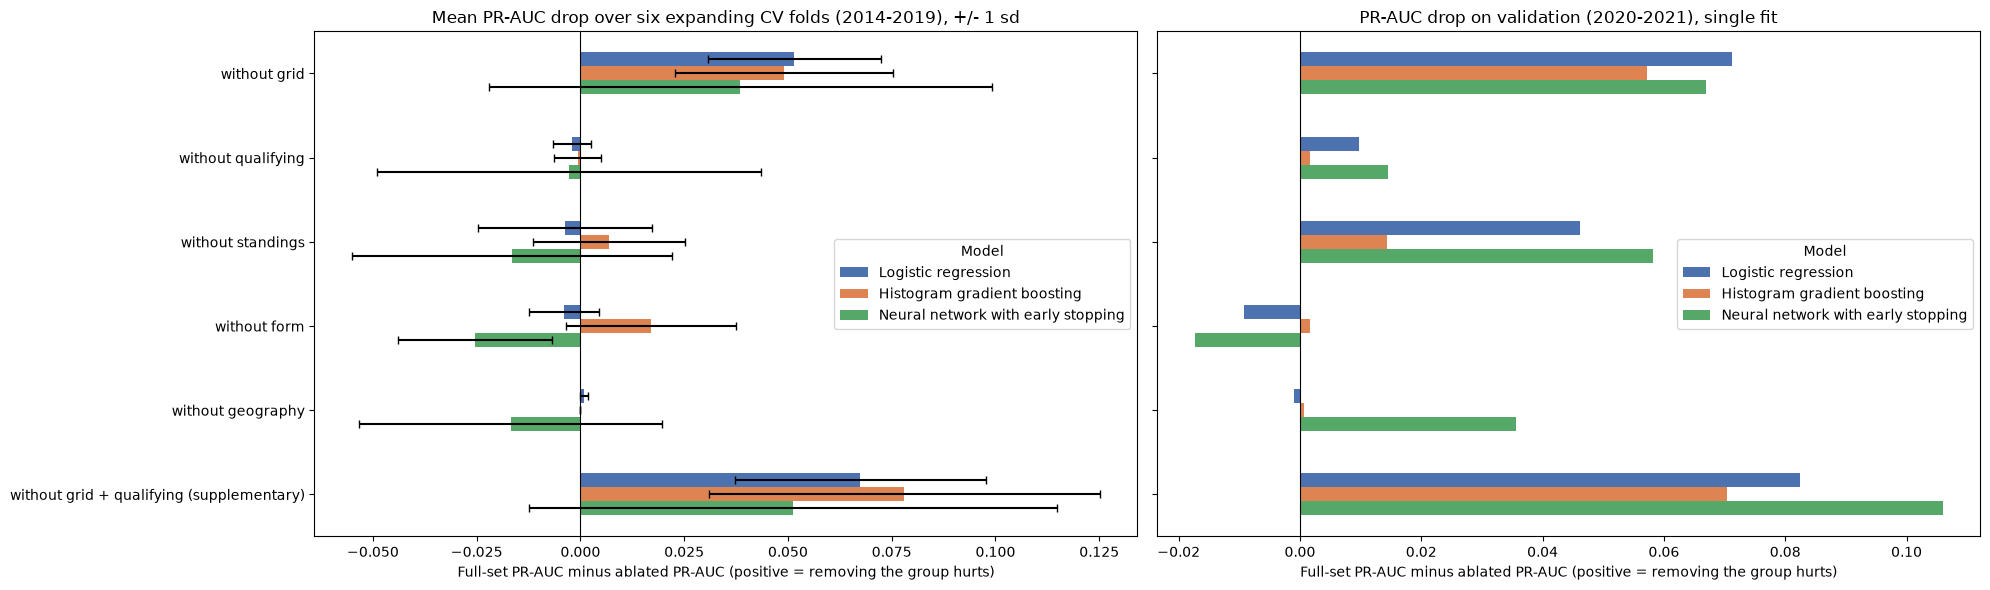

,Check,Passed
0,Every feature set x model x split was run,True
1,Each leave-one-group-out set removes exactly i...,True
2,Every split fits on strictly earlier seasons; ...,True
3,NN duration selection precedes every scored se...,True
4,Full-set validation reruns reproduce the saved...,True


In [199]:
# Before training (step-12 EDA on training seasons) versus after training (ablation drop).
ablation_train_rows = modeling_table_fe.loc[modeling_table_fe["partition"].eq("train")]
home_auc = roc_auc_score(ablation_train_rows[MODEL_TARGET].astype(int), ablation_train_rows["is_home"].astype(float))
ablation_eda = pd.concat([
    feature_univariate_train.loc[feature_univariate_train["Feature"].isin(FE_FEATURE_COLUMNS),
                                 ["Feature", "Group", "Single-feature ROC-AUC", "Mutual information"]],
    pd.DataFrame([{"Feature": "is_home", "Group": "geography",
                   "Single-feature ROC-AUC": max(home_auc, 1 - home_auc), "Mutual information": np.nan}])
], ignore_index=True)
ablation_eda_by_group = ablation_eda.groupby("Group").agg(
    Features=("Feature", "size"),
    Strongest_feature=("Single-feature ROC-AUC", lambda s: ablation_eda.loc[s.idxmax(), "Feature"]),
    Best_single_feature_ROC_AUC=("Single-feature ROC-AUC", "max"),
)
group_drop = ablation_results.loc[ablation_results["Feature set"].str.startswith("without")].assign(
    Group=lambda f: f["Feature set"].str.removeprefix("without ").str.removesuffix(" (supplementary)")
).pivot(index="Group", columns="Model", values="CV PR-AUC drop")
ablation_before_after = ablation_eda_by_group.join(group_drop.add_prefix("CV PR-AUC drop: "), how="outer")
with pd.option_context("display.max_columns", None, "display.width", 250, "display.precision", 4):
    print("Exploratory evidence before training (training seasons) next to the measured ablation drop")
    display(ablation_before_after)

model_order = list(ablation_classifiers)
set_order = [s for s in ABLATION_SETS if s.startswith("without")]
colours = ["#4c72b0", "#dd8452", "#55a868"]
fig, axes = plt.subplots(1, 2, figsize=(20, 6), sharey=True)
for ax, (value, error, title) in zip(axes, [
    ("CV PR-AUC drop", "CV drop sd", "Mean PR-AUC drop over six expanding CV folds (2014-2019), +/- 1 sd"),
    ("Validation PR-AUC drop", None, "PR-AUC drop on validation (2020-2021), single fit"),
]):
    pivot = ablation_results.pivot(index="Feature set", columns="Model", values=value).reindex(set_order)[model_order]
    errors = (ablation_results.pivot(index="Feature set", columns="Model", values=error)
              .reindex(set_order)[model_order] if error else None)
    pivot.plot.barh(ax=ax, xerr=errors, capsize=3, color=colours)
    ax.axvline(0, color="black", linewidth=0.8)
    ax.set_xlabel("Full-set PR-AUC minus ablated PR-AUC (positive = removing the group hurts)")
    ax.set_title(title)
    ax.invert_yaxis()
axes[0].set_ylabel("")
plt.tight_layout()
plt.show()

# Step-16 checks (assertion-backed claims made in the result cell).
step16_checks = pd.DataFrame([
    {"Check": "Every feature set x model x split was run",
     "Passed": len(ablation_runs) == len(ABLATION_SETS) * len(ablation_classifiers) * len(ablation_splits)},
    {"Check": "Each leave-one-group-out set removes exactly its group",
     "Passed": all(set(FE_FEATURE_COLUMNS) - set(ABLATION_SETS[f"without {g}"]) == set(cols)
                   for g, cols in FE_FEATURE_GROUPS.items())},
    {"Check": "Every split fits on strictly earlier seasons; no test season used",
     "Passed": bool(ablation_frame["year"].max() <= 2021)},
    {"Check": "NN duration selection precedes every scored season",
     "Passed": bool((ablation_runs.loc[ablation_runs["Model"].eq("Neural network with early stopping"), "Selection last season"]
                     < ablation_runs.loc[ablation_runs["Model"].eq("Neural network with early stopping"), "Evaluation first season"]).all())},
    {"Check": "Full-set validation reruns reproduce the saved baselines (asserted above)", "Passed": True},
])
display(step16_checks)
step16_validation_passed = bool(step16_checks["Passed"].all())
assert step16_validation_passed, "Step 16 checks failed."

### What the feature-group experiments establish

All **147** feature-set/model/split evaluations completed without convergence warnings, and full-set validation AP reproduces the saved baselines. Full-set mean CV AP is **0.7276 (LR), 0.7521 (HGB), and 0.7089 (NN)**. The table below summarizes paired changes after **retraining**; a positive drop means removing the group hurts AP, and a negative drop means removal improves it.

| Removed group | LR CV AP drop | HGB CV AP drop | NN CV AP drop |
| --- | --- | --- | --- |
| grid | +0.0515 | +0.0490 | +0.0385 |
| qualifying | -0.0020 | -0.0007 | -0.0028 |
| standings | -0.0037 | +0.0069 | -0.0165 |
| form | -0.0040 | +0.0170 | -0.0254 |
| geography | +0.0008 | +0.0000 | -0.0168 |
| grid + qualifying (supplementary) | +0.0674 | +0.0780 | +0.0512 |

**Grid has the clearest incremental contribution.** Removing it reduces AP in all six folds for LR/HGB and five of six for the NN. Removing grid and qualifying together produces a larger mean drop for every model, consistent with partly overlapping information. Qualifying alone has small negative mean drops, so this experiment does not demonstrate a robust incremental AP gain from qualifying once the other predictors are available. That is a narrower conclusion than claiming qualifying contains no useful information.

**Standings and form have model-dependent value.** HGB loses mean CV AP when either group is removed, whereas LR and the NN improve slightly or more substantially in these CV comparisons. On external validation, removing standings reduces AP by **0.0461 (LR), 0.0143 (HGB), and 0.0582 (NN)**. The disagreement across periods prevents a blanket claim that standings always help, even though their validation contribution is positive here. Form also cannot be claimed to improve all three models.

**Home-race status has weak or inconsistent support.** Its CV drop is near zero for LR/HGB. Removing it improves NN mean CV AP by **0.0168**, but lowers NN validation AP by **0.0355**. This instability does not support a general home advantage in prediction. The existing feature contract is retained for this documented comparison; these results are not used to retune features against the test set.

Ablation asks whether a newly trained model can replace the removed information. Permutation importance in step 17 instead asks how much the **already fitted** model relies on information when it is shuffled. A group can have positive permutation importance even when a retrained model performs better without it; the experiments answer different questions.


## Model explainability (step 17)

The model audit below identifies every saved artifact and verifies its validation AP. All explanations use the saved models evaluated in the preceding sections.

Explain the saved logistic regression, histogram gradient boosting, and **step-15 neural network with early stopping** (`models/shallow_neural_network_early_stopping.joblib`). Nothing is retrained. Explanations use validation seasons **2020-2021**; test seasons **2022-2024** remain reserved. Background statistics use each model's actual weight-fitting seasons: 2006-2019 for LR/HGB and 2006-2017 for the NN.

- **Permutation importance:** per-feature and grouped drops in validation average precision, 30 seeded shuffles. Group shuffling preserves relationships within a group, but correlations with other groups remain a limitation.
- **SHAP:** exact linear SHAP for LR under independent masking; tree-path-dependent TreeSHAP for HGB; approximate permutation SHAP for the NN, with an explicitly sampled 100-row fitting background and a fixed budget of 470 masked-input evaluations per row. All outputs are in log-odds. Additivity is checked on all validation rows; this checks reconstruction, not convergence of the approximate NN attributions. Different reference distributions and masking assumptions also affect cross-model comparisons. Plots show original feature units.
- **Local SHAP:** case A for all three models and case B for LR and NN. Cases are fixed by LR's most confident miss and false alarm, preserving the same examples for comparison; LR is not claimed to be the best model.
- **LIME:** case A for all three models. Each sampler uses its model's fitting rows and saved imputation statistics, with binary flags treated as categorical. Wrapper predictions are checked against the saved pipelines on every validation row, including missing inputs. The table reports local surrogate R^2 and its absolute probability error at the explained row. Poor fidelity is a limitation, not proof of a wrong model.

**Interpretation:** explanations describe model behavior, not causal effects. Correlated or unrealistic perturbed inputs can affect both SHAP and LIME. A low-fidelity LIME surrogate should not support a strong explanation of the original model.

References: [SHAP permutation explainer](https://shap.readthedocs.io/en/latest/generated/shap.PermutationExplainer.html), [LIME API and fidelity score](https://lime-ml.readthedocs.io/en/latest/lime.html).


Verified explanation models: saved pipelines, no retraining


,Model,Artifact,Weight-fitting rows,Weight-fitting seasons,Validation PR-AUC,Artifact SHA256
0,Logistic regression,/kaggle/working/models/logistic_regression_baseline.joblib,5760,"[2006, 2019]",0.7259439101,643aeee1a8621a5d41d8ce7dcb6c9fc7121d8313dc483a8d6327a9dd7912503a
1,Histogram gradient boosting,/kaggle/working/models/hist_gradient_boosting_baseline.joblib,5760,"[2006, 2019]",0.7114640787,fde3284f14836b265fa5431935b1e769c95115cb6fd29ddd1c6c3702c13cf80d
2,Neural network with early stopping,/kaggle/working/models/shallow_neural_network_early_stopping.joblib,4921,"[2006, 2017]",0.7379005251,42ec371713f53ad28f900558cf26e6628f33db628fdb6bcd7d2badb0b636f12c


Installed versions: {'shap': '0.54.1', 'lime': '0.2.0.1', 'scikit-learn': '1.9.1'}
Grouped permutation importance on validation (drop in PR-AUC; 30 shuffles)


Model,Histogram gradient boosting,Logistic regression,Neural network with early stopping
Group,,,
grid,3.1197e-01,0.4082,0.3224
standings,3.1083e-02,0.0948,0.0977
qualifying,8.3771e-03,0.0521,0.0064
form,5.5113e-02,0.0154,0.0620
geography,8.6764e-05,-0.0007,0.0032


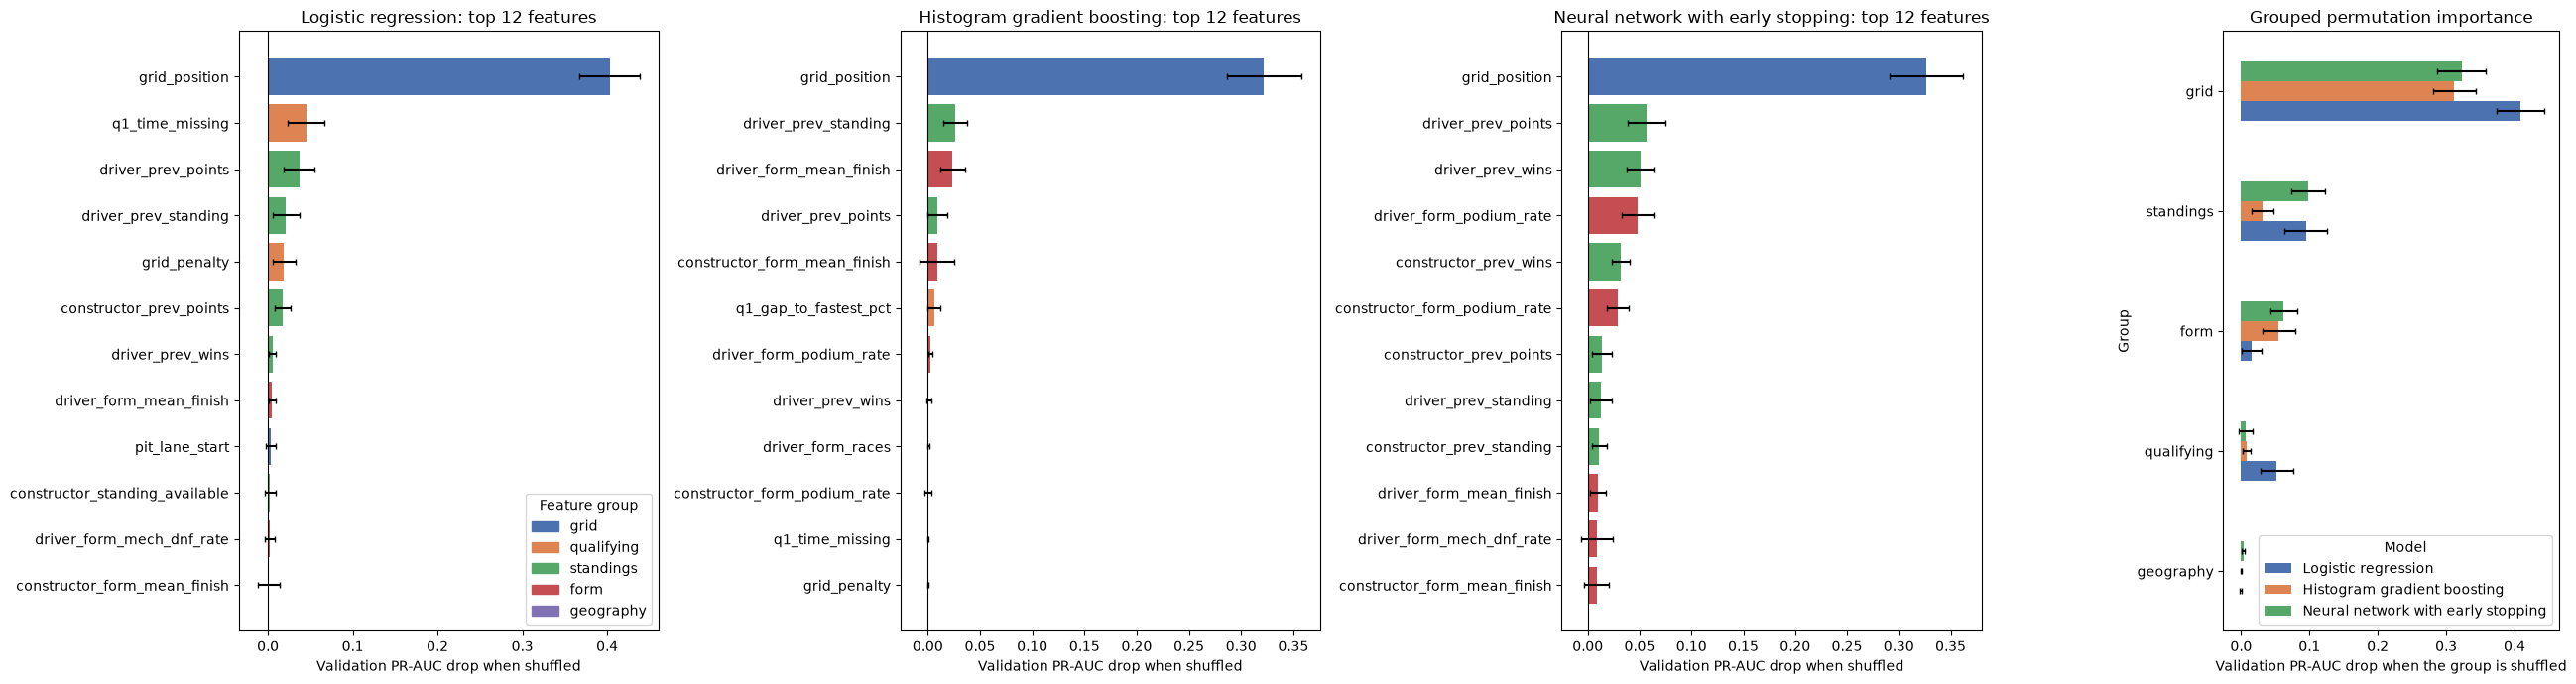

In [200]:
# XAI setup and global permutation importance, computed on VALIDATION rows (2020-2021).
xai_required_objects = [
    "step12_validation_passed", "modeling_table_fe", "FE_FEATURE_COLUMNS", "FE_FEATURE_GROUPS",
    "FE_GROUP_OF", "MODEL_KEY_COLUMNS", "MODEL_TARGET", "FORM_WINDOW", "clean_data"
]
xai_missing_objects = [name for name in xai_required_objects if name not in globals()]
if xai_missing_objects:
    raise RuntimeError("Run steps 1-12 in this kernel first. Missing: " + ", ".join(xai_missing_objects))
assert step12_validation_passed, "Run step 12 successfully first."

from pathlib import Path
import joblib
import hashlib
from importlib.metadata import version
from joblib import parallel_config
import shap
import lime
import lime.lime_tabular
from sklearn.inspection import permutation_importance
from sklearn.metrics import average_precision_score

XAI_RANDOM_STATE = 0
XAI_N_REPEATS = 30
XAI_MODEL_PATHS = {
    "Logistic regression": (MODEL_DIR / "logistic_regression_baseline.joblib"),
    "Histogram gradient boosting": (MODEL_DIR / "hist_gradient_boosting_baseline.joblib"),
    "Neural network with early stopping": (MODEL_DIR / "shallow_neural_network_early_stopping.joblib"),
}
xai_bundles = {}
for model_name, model_path in XAI_MODEL_PATHS.items():
    if not Path(model_path).exists():
        raise FileNotFoundError(f"{model_path} is missing: run the save cells of steps 13, 14 and 15 first.")
    xai_bundles[model_name] = joblib.load(model_path)
    assert xai_bundles[model_name]["feature_columns"] == list(FE_FEATURE_COLUMNS)
    assert xai_bundles[model_name]["form_window"] == FORM_WINDOW
    bundle = xai_bundles[model_name]
    assert bundle["target"] == MODEL_TARGET and bundle["positive_class"] == 1
    assert bundle["validation_seasons"] == [2020, 2021] and bundle["threshold"] == 0.5
    np.testing.assert_array_equal(bundle["pipeline"].classes_, [0, 1])
    if model_name == "Neural network with early stopping":
        assert bundle["train_seasons"] == [2006, 2017] and bundle["stopping_seasons"] == [2018, 2019]
        assert bundle["early_stopping"]["monitor"] == "average_precision"
        assert bundle["early_stopping"]["restore_best_weights"]
        assert len(bundle["pipeline"].named_steps["classifier"].loss_curve_) == bundle["best_epoch"]
    else:
        assert bundle["train_seasons"] == [2006, 2019]
XAI_FEATURES = list(FE_FEATURE_COLUMNS)
XAI_BINARY_FEATURES = list(xai_bundles["Logistic regression"]["binary_features"])
XAI_NUMERIC_FEATURES = [c for c in XAI_FEATURES if c not in XAI_BINARY_FEATURES]

xai_train_rows = modeling_table_fe.loc[modeling_table_fe["partition"].eq("train")].reset_index(drop=True)
xai_validation_rows = modeling_table_fe.loc[modeling_table_fe["partition"].eq("validation")].reset_index(drop=True)
xai_X_train = xai_train_rows[XAI_FEATURES].astype("Float64").astype("float64")
xai_X_validation = xai_validation_rows[XAI_FEATURES].astype("Float64").astype("float64")
xai_y_validation = xai_validation_rows[MODEL_TARGET].astype(int).to_numpy()
xai_validation_probability = {
    name: bundle["pipeline"].predict_proba(xai_X_validation)[:, 1] for name, bundle in xai_bundles.items()
}
for name, bundle in xai_bundles.items():   # the explained models are exactly the saved baselines
    assert np.isclose(average_precision_score(xai_y_validation, xai_validation_probability[name]),
                      bundle["validation_metrics"]["PR-AUC (average precision)"], atol=1e-9)

# Audit the artifact identity and the preprocessing learned from its actual fitting seasons.
xai_reference_X = {}
xai_model_audit_rows = []
for name, bundle in xai_bundles.items():
    fit = xai_train_rows["year"].between(*bundle["train_seasons"])
    reference = xai_X_train.loc[fit].copy()
    xai_reference_X[name] = reference
    numeric = bundle["pipeline"].named_steps["preprocessing"].named_transformers_["numeric"]
    imputer = numeric.named_steps["imputer"] if hasattr(numeric, "named_steps") else numeric
    np.testing.assert_allclose(imputer.statistics_, reference[bundle["numeric_features"]].median())
    if hasattr(numeric, "named_steps") and "scaler" in numeric.named_steps:
        assert np.all(numeric.named_steps["scaler"].n_samples_seen_ == len(reference))
    xai_model_audit_rows.append({
        "Model": name, "Artifact": XAI_MODEL_PATHS[name], "Weight-fitting rows": len(reference),
        "Weight-fitting seasons": str(bundle["train_seasons"]),
        "Validation PR-AUC": average_precision_score(xai_y_validation, xai_validation_probability[name]),
        "Artifact SHA256": hashlib.sha256(Path(XAI_MODEL_PATHS[name]).read_bytes()).hexdigest(),
    })
xai_model_audit = pd.DataFrame(xai_model_audit_rows)
with pd.option_context("display.max_columns", None, "display.max_colwidth", 100, "display.precision", 10):
    print("Verified explanation models: saved pipelines, no retraining")
    display(xai_model_audit)
print("Installed versions:", {p: version(p) for p in ["shap", "lime", "scikit-learn"]})

# 1) Per-feature permutation importance: drop in validation PR-AUC when one column is shuffled.
xai_permutation_rows = []
for name, bundle in xai_bundles.items():
    with parallel_config(backend="loky", inner_max_num_threads=1):
        result = permutation_importance(
            bundle["pipeline"], xai_X_validation, xai_y_validation, scoring="average_precision",
            n_repeats=XAI_N_REPEATS, random_state=XAI_RANDOM_STATE, n_jobs=N_JOBS
        )
    xai_permutation_rows += [
        {"Model": name, "Feature": feature, "Group": FE_GROUP_OF[feature],
         "PR-AUC drop (mean)": result.importances_mean[j], "PR-AUC drop (sd)": result.importances_std[j]}
        for j, feature in enumerate(XAI_FEATURES)
    ]
xai_permutation_importance = pd.DataFrame(xai_permutation_rows)

# 2) Grouped permutation importance: shuffle every column of a group with the SAME row order.
# Correlated features (grid vs qualifying gap) can stand in for each other when shuffled one
# at a time; shuffling the whole group removes that substitution.
xai_group_rows = []
for name, bundle in xai_bundles.items():
    rng = np.random.default_rng(XAI_RANDOM_STATE)
    reference = average_precision_score(xai_y_validation, xai_validation_probability[name])
    for group, columns in FE_FEATURE_GROUPS.items():
        drops = []
        for _ in range(XAI_N_REPEATS):
            shuffled = xai_X_validation.copy()
            shuffled[columns] = xai_X_validation[columns].to_numpy()[rng.permutation(len(shuffled))]
            drops.append(reference - average_precision_score(
                xai_y_validation, bundle["pipeline"].predict_proba(shuffled)[:, 1]))
        xai_group_rows.append({"Model": name, "Group": group, "Features": len(columns),
                               "PR-AUC drop (mean)": np.mean(drops), "PR-AUC drop (sd)": np.std(drops)})
xai_group_permutation_importance = pd.DataFrame(xai_group_rows)

with pd.option_context("display.precision", 4, "display.width", 200):
    print("Grouped permutation importance on validation (drop in PR-AUC; 30 shuffles)")
    display(xai_group_permutation_importance.pivot(index="Group", columns="Model", values="PR-AUC drop (mean)")
            .sort_values("Logistic regression", ascending=False))

group_colours = {"grid": "#4c72b0", "qualifying": "#dd8452", "standings": "#55a868",
                 "form": "#c44e52", "geography": "#8172b3"}
fig, axes = plt.subplots(1, 4, figsize=(26, 7), gridspec_kw={"width_ratios": [1, 1, 1, 0.8]})
for ax, name in zip(axes[:3], xai_bundles):
    top = (xai_permutation_importance.loc[xai_permutation_importance["Model"].eq(name)]
           .nlargest(12, "PR-AUC drop (mean)").iloc[::-1])
    ax.barh(top["Feature"], top["PR-AUC drop (mean)"], xerr=top["PR-AUC drop (sd)"], capsize=2,
            color=top["Group"].map(group_colours))
    ax.axvline(0, color="black", linewidth=0.8)
    ax.set_title(f"{name}: top 12 features")
    ax.set_xlabel("Validation PR-AUC drop when shuffled")
grouped = xai_group_permutation_importance.pivot(index="Group", columns="Model", values="PR-AUC drop (mean)")
grouped_sd = xai_group_permutation_importance.pivot(index="Group", columns="Model", values="PR-AUC drop (sd)")
order = grouped.mean(axis=1).sort_values().index
grouped.loc[order, list(xai_bundles)].plot.barh(ax=axes[3], xerr=grouped_sd.loc[order, list(xai_bundles)],
                                                capsize=2, color=["#4c72b0", "#dd8452", "#55a868"])
axes[3].set_title("Grouped permutation importance")
axes[3].set_xlabel("Validation PR-AUC drop when the group is shuffled")
axes[0].legend(handles=[plt.Rectangle((0, 0), 1, 1, color=c) for c in group_colours.values()],
               labels=list(group_colours), loc="lower right", title="Feature group")
plt.tight_layout()
plt.show()

### Global permutation importance: reliance on the fitted inputs

The starting validation AP values are **0.7259 (LR), 0.7115 (HGB), and 0.7379 (NN)**. The grouped table reports how much these scores fall, on average, when a group is shuffled. Larger positive drops mean greater reliance by the fitted model.

| Shuffled group | LR AP drop | HGB AP drop | NN AP drop |
| --- | --- | --- | --- |
| grid | 0.4082 | 0.3120 | 0.3224 |
| qualifying | 0.0521 | 0.0084 | 0.0064 |
| standings | 0.0948 | 0.0311 | 0.0977 |
| form | 0.0153 | 0.0551 | 0.0620 |
| geography | -0.0007 | 0.0001 | 0.0032 |

**Grid dominates every fitted model.** Shuffling it reduces AP by 0.4082, 0.3120 and 0.3224, respectively; `grid_position` is also the highest-ranked individual feature for all three. The models therefore agree on the leading source of predictive information despite their different structures.

Beyond grid, LR relies most on **standings and qualifying**, HGB on **form and standings**, and the NN on **standings and form**. Qualifying has a larger permutation effect for LR than for HGB/NN. Geography contributes almost nothing to the fitted LR/HGB scores and only a small NN drop. LR's slightly negative geography value means that shuffling marginally improves AP; it is not evidence of a harmful causal effect of racing at home.

The grid-drop standard deviations across 30 shuffles are **0.0347 (LR), 0.0311 (HGB), and 0.0356 (NN)**. These quantify shuffle variability on these validation rows, not uncertainty across future seasons. Joint shuffling preserves relationships inside each group but breaks relationships with other groups, including grid versus qualifying. Some resulting feature combinations may be unrealistic, so the magnitudes are measures of model reliance under this perturbation protocol, not causal contributions. [Permutation-importance interpretation](https://scikit-learn.org/stable/modules/permutation_importance.html).


,Model,Rows explained,Maximum additivity error
0,Logistic regression,779,3.108624e-15
1,Histogram gradient boosting,779,7.105427e-15
2,Neural network with early stopping,779,3.807219e-09


Mean |SHAP| per feature (log-odds), validation rows; top 12 by logistic regression


,Logistic regression,Histogram gradient boosting,Neural network with early stopping
grid_position,1.699,1.133,1.365
driver_prev_standing,0.362,0.393,0.183
constructor_form_mean_finish,0.254,0.418,0.071
constructor_prev_points,0.248,0.019,0.087
driver_prev_points,0.234,0.086,0.098
driver_form_podium_rate,0.141,0.051,0.387
grid_penalty,0.120,0.010,0.139
constructor_prev_standing,0.114,0.034,0.307
q1_time_missing,0.103,0.004,0.003
q1_gap_to_fastest_pct,0.101,0.160,0.131


Mean |sum of SHAP within group| (log-odds)


,Logistic regression,Histogram gradient boosting,Neural network with early stopping
grid,1.735,1.133,1.387
standings,0.543,0.463,0.676
form,0.306,0.526,0.581
qualifying,0.235,0.164,0.241
geography,0.012,0.001,0.024


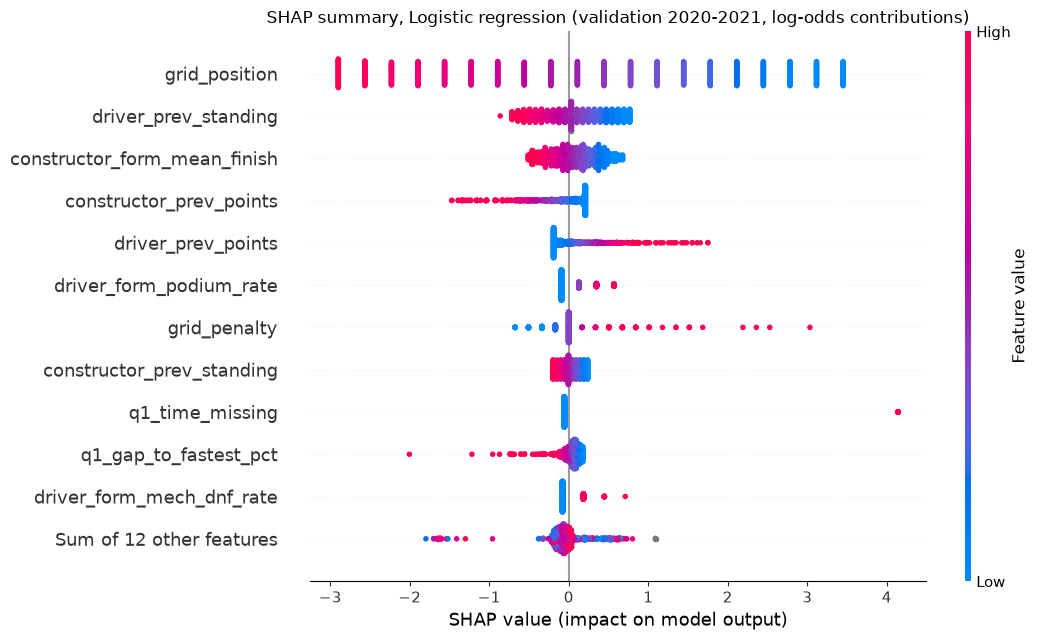

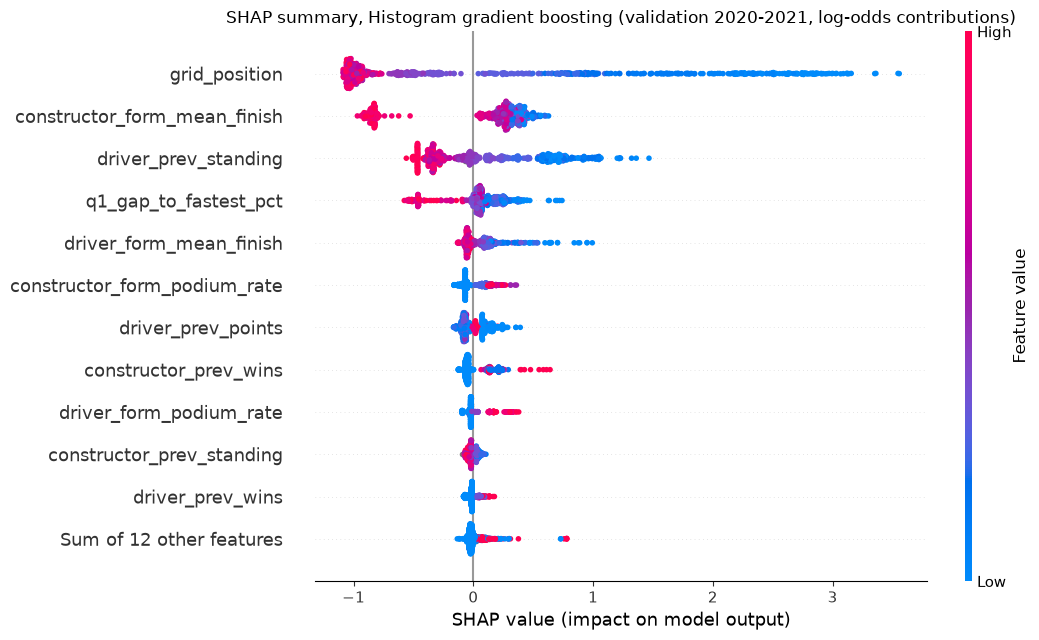

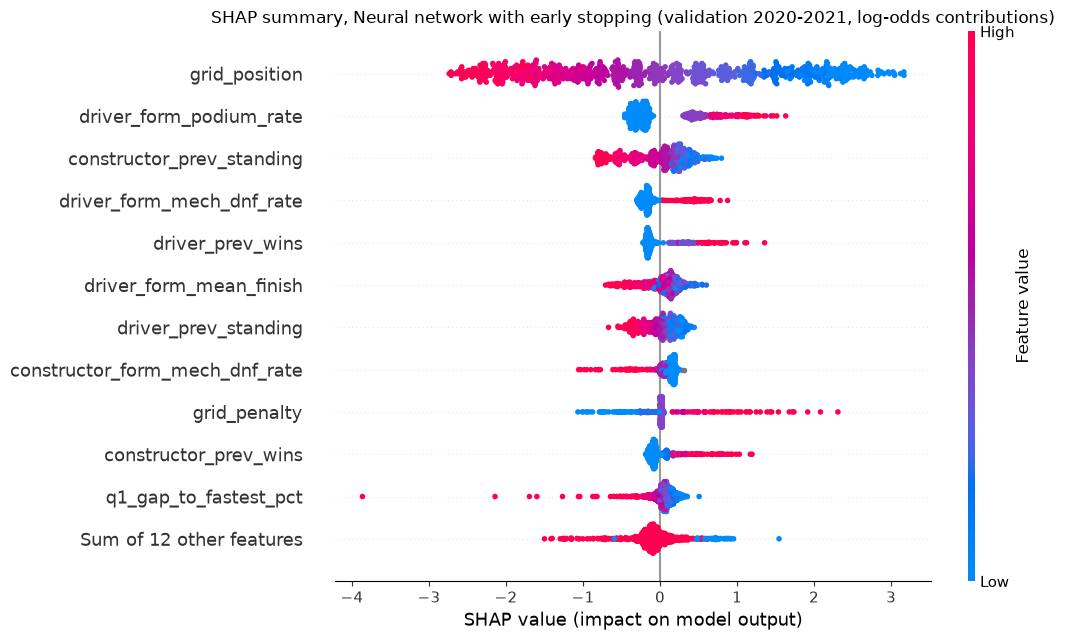

In [201]:
# Global SHAP on validation rows. All three are explained on the LOG-ODDS scale so they compare.
def xai_transformed(name, frame):
    """Inputs exactly as the classifier sees them (training-median imputation, scaling if any)."""
    preprocessing = xai_bundles[name]["pipeline"].named_steps["preprocessing"]
    return pd.DataFrame(preprocessing.transform(frame), columns=preprocessing.get_feature_names_out(),
                        index=frame.index)

def xai_logit(probability):
    probability = np.clip(probability, 1e-12, 1 - 1e-12)
    return np.log(probability / (1 - probability))

xai_shap = {}
xai_Xt_train = {name: xai_transformed(name, xai_reference_X[name]) for name in xai_bundles}
xai_Xt_validation = {name: xai_transformed(name, xai_X_validation) for name in xai_bundles}
xai_column_order = {name: list(xai_Xt_validation[name].columns) for name in xai_bundles}

# Logistic regression: exact linear SHAP, feature effect = coef * (x - training mean).
lr_classifier = xai_bundles["Logistic regression"]["pipeline"].named_steps["classifier"]
lr_explainer = shap.LinearExplainer(lr_classifier, shap.maskers.Independent(xai_Xt_train["Logistic regression"],
                                                                            max_samples=len(xai_X_train)))
xai_shap["Logistic regression"] = lr_explainer(xai_Xt_validation["Logistic regression"])

# Gradient boosting: exact TreeSHAP on the raw boosting score (log-odds).
hgb_classifier = xai_bundles["Histogram gradient boosting"]["pipeline"].named_steps["classifier"]
hgb_explainer = shap.TreeExplainer(hgb_classifier)
xai_shap["Histogram gradient boosting"] = hgb_explainer(xai_Xt_validation["Histogram gradient boosting"].to_numpy())

# Neural network: model-agnostic permutation SHAP on the logit of its probability,
# with a fixed 100-row training background sample.
nn_classifier_xai = xai_bundles["Neural network with early stopping"]["pipeline"].named_steps["classifier"]
nn_background_rows = shap.utils.sample(
    xai_Xt_train["Neural network with early stopping"].to_numpy(),
    nsamples=100, random_state=XAI_RANDOM_STATE
)
nn_background = shap.maskers.Independent(nn_background_rows, max_samples=100)
nn_explainer = shap.PermutationExplainer(
    lambda z: xai_logit(nn_classifier_xai.predict_proba(np.asarray(z, dtype=float))[:, 1]), nn_background, seed=XAI_RANDOM_STATE
)
xai_shap["Neural network with early stopping"] = nn_explainer(xai_Xt_validation["Neural network with early stopping"].to_numpy(),
                                                  max_evals=10 * (2 * len(XAI_FEATURES) + 1), silent=True)

# Verify the transformed classifier path against the original saved pipeline, including missing rows.
for name, bundle in xai_bundles.items():
    np.testing.assert_allclose(
        bundle["pipeline"].named_steps["classifier"].predict_proba(xai_Xt_validation[name].to_numpy())[:, 1],
        xai_validation_probability[name], rtol=1e-12, atol=1e-12
    )
xai_shap_checks = []

# Re-express every explanation in the original feature order with RAW feature values
# (unscaled, missing shown as NaN) so plots read in racing units.
for name, explanation in list(xai_shap.items()):
    order = [xai_column_order[name].index(c) for c in XAI_FEATURES]
    values = np.asarray(explanation.values)[:, order]
    base = np.broadcast_to(np.asarray(explanation.base_values, dtype=float).reshape(-1), (len(values),)).copy()
    xai_shap[name] = shap.Explanation(values=values, base_values=base,
                                      data=xai_X_validation[XAI_FEATURES].to_numpy(), feature_names=XAI_FEATURES)
    # Additivity: base value + feature contributions reproduces each model's log-odds output.
    expected = xai_logit(xai_validation_probability[name])
    np.testing.assert_allclose(base + values.sum(axis=1), expected, rtol=0, atol=1e-4,
                               err_msg=f"{name}: SHAP values are not additive.")
    xai_shap_checks.append({"Model": name, "Rows explained": len(values),
                            "Maximum additivity error": float(np.max(np.abs(base + values.sum(axis=1) - expected)))})
xai_shap_checks = pd.DataFrame(xai_shap_checks)
display(xai_shap_checks)

xai_shap_importance = pd.DataFrame({name: np.abs(e.values).mean(axis=0) for name, e in xai_shap.items()},
                                   index=XAI_FEATURES)
xai_shap_group_importance = pd.DataFrame({
    name: {group: np.abs(e.values[:, [XAI_FEATURES.index(c) for c in cols]].sum(axis=1)).mean()
           for group, cols in FE_FEATURE_GROUPS.items()}
    for name, e in xai_shap.items()
})
with pd.option_context("display.precision", 3, "display.width", 200):
    print("Mean |SHAP| per feature (log-odds), validation rows; top 12 by logistic regression")
    display(xai_shap_importance.sort_values("Logistic regression", ascending=False).head(12))
    print("Mean |sum of SHAP within group| (log-odds)")
    display(xai_shap_group_importance.sort_values("Logistic regression", ascending=False))

for name, explanation in xai_shap.items():
    plt.figure()
    shap.plots.beeswarm(explanation, max_display=12, show=False)
    plt.gcf().set_size_inches(11, 6.5)
    plt.title(f"SHAP summary, {name} (validation 2020-2021, log-odds contributions)")
    plt.tight_layout()
    plt.show()

### Global SHAP: magnitude and direction of prediction changes

In the beeswarm plots, each dot is a validation entry. Its horizontal position is the feature's contribution in **log-odds**: positive raises the predicted podium probability relative to that model's reference prediction, and negative lowers it. Red indicates a higher original feature value and blue a lower one. Mean absolute SHAP summarizes magnitude, not direction or AP improvement. [How to read a beeswarm](https://shap.readthedocs.io/en/latest/generated/shap.plots.beeswarm.html).

| Feature group | LR mean absolute net SHAP | HGB | NN |
| --- | --- | --- | --- |
| grid | 1.7347 | 1.1328 | 1.3874 |
| qualifying | 0.2346 | 0.1641 | 0.2407 |
| standings | 0.5432 | 0.4629 | 0.6758 |
| form | 0.3058 | 0.5265 | 0.5807 |
| geography | 0.0117 | 0.0013 | 0.0244 |

Here a group's value is the mean of the **absolute sum of its feature contributions for each entry**. Opposing contributions inside a group can cancel; this is not the sum of the features' individual mean absolute values.

Grid is the largest group for every model, agreeing with permutation importance and ablation. Standings is second for LR/NN, while form is second for HGB. Among individual features after grid, LR emphasizes driver standing and constructor mean recent finish; HGB emphasizes constructor mean recent finish and driver standing; the NN emphasizes driver recent podium rate and constructor standing. The methods therefore agree on grid but do not give identical secondary rankings: SHAP measures contribution magnitude, whereas permutation measures lost AP.

The grid direction is also supported numerically. Mean `grid_position` SHAP for starts **1–3** is **+3.116 (LR), +2.566 (HGB), and +2.407 (NN)**; for starts **11 or worse** it is **−1.430, −0.996, and −1.386**, respectively. Better starting positions generally push predictions upward, but these are group averages rather than a rule for every entry. Geography's net SHAP magnitude is small for all three models.

All **779 validation entries** are explained per model. Maximum reconstruction errors are below **1e-4** for all three, confirming that base log-odds plus contributions recover model outputs within the asserted tolerance. This check does not establish convergence of the approximate NN attribution estimates. Different backgrounds and masking assumptions also mean that cross-model SHAP magnitudes should not be treated as directly comparable causal effects.


,Case,Driver,Race,Actual podium,LR probability,HGB probability,NN probability,grid_position,q1_gap_to_fastest_pct,driver_prev_points,constructor_form_podium_rate
0,A: most confident miss,Sebastian Vettel,2020 Turkish Grand Prix,1,0.007,0.005,0.007,11.0,4.997,18.0,0.0
1,B: most confident false alarm,Lewis Hamilton,2020 Italian Grand Prix,0,0.887,0.862,0.833,1.0,0.000,157.0,1.0


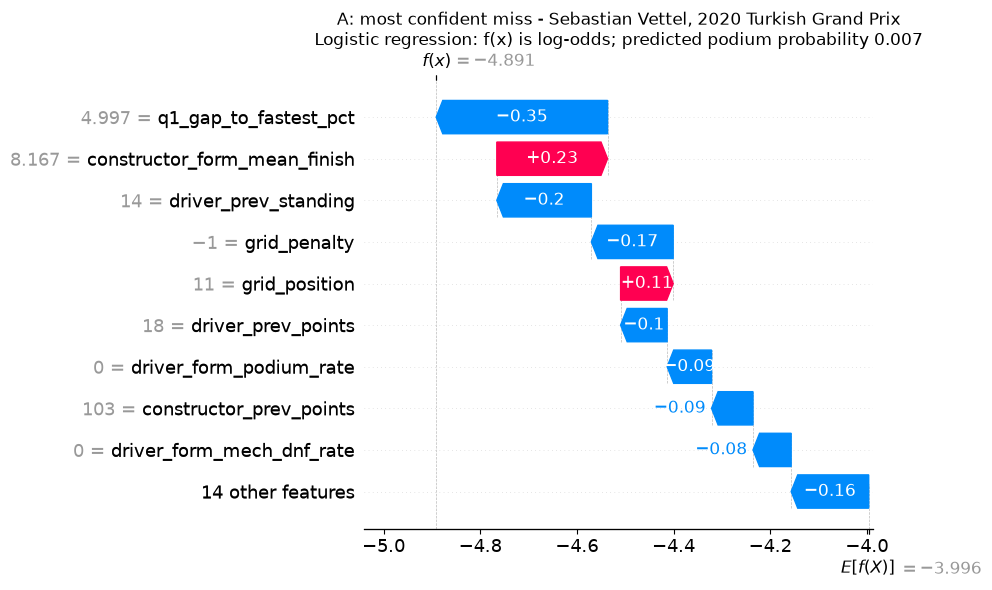

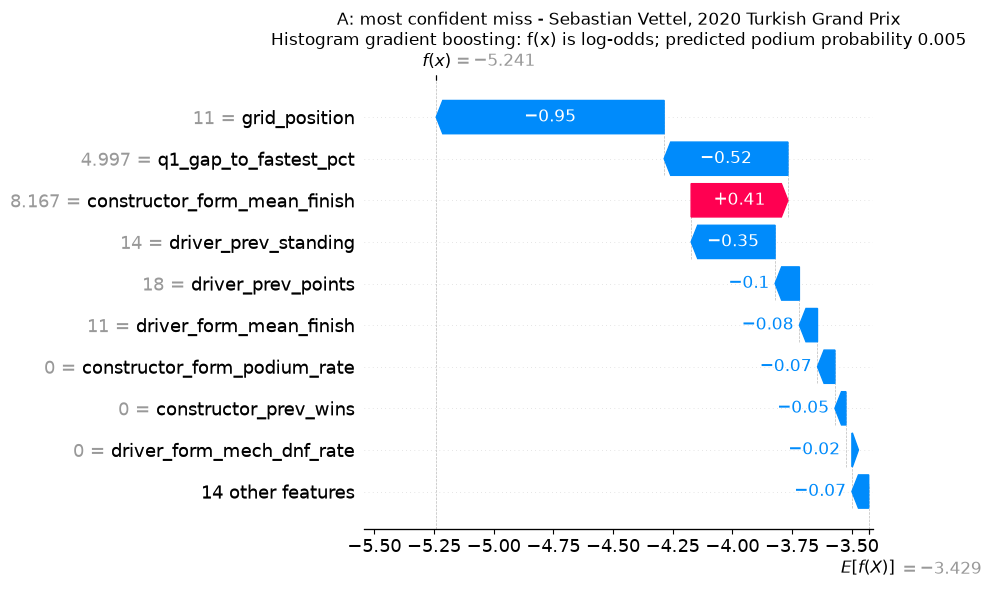

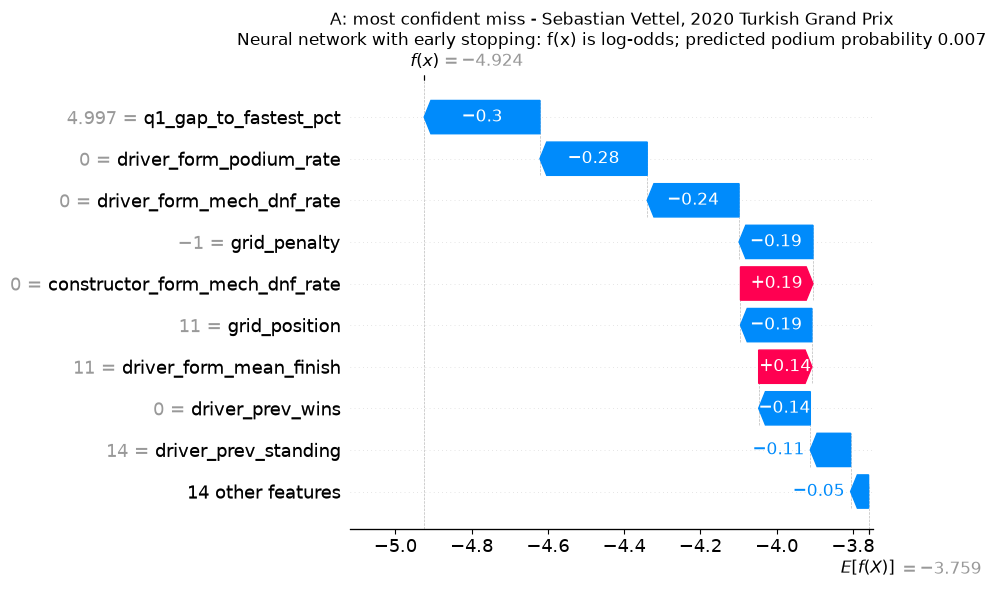

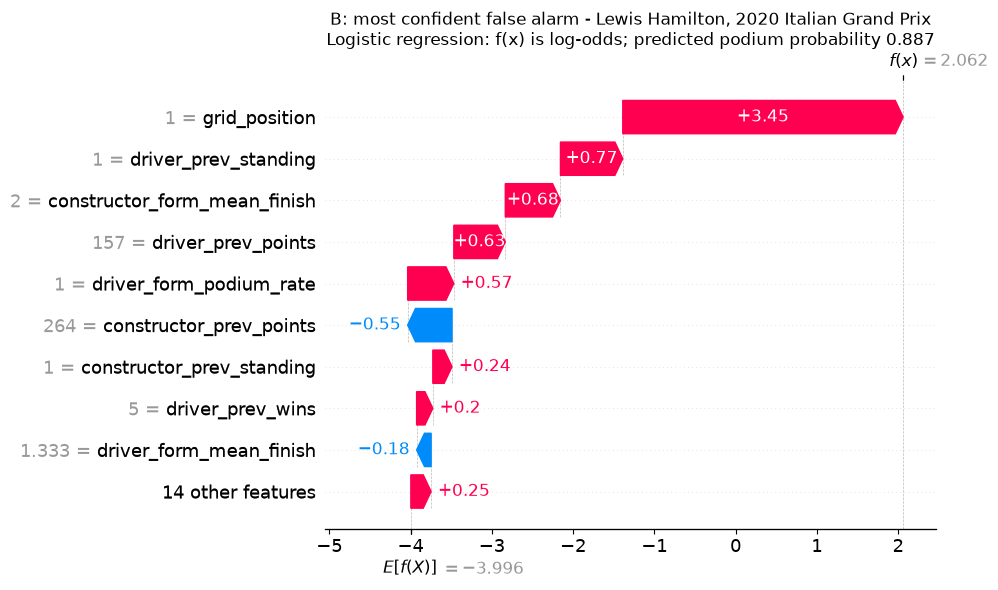

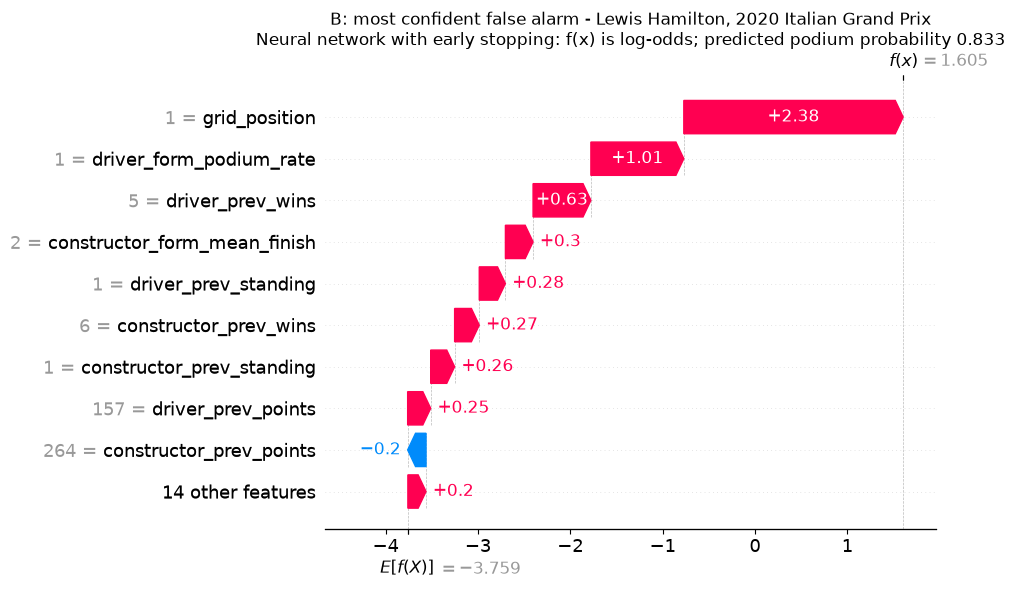

In [202]:
# Local explanations for two single validation predictions chosen using logistic regression as a fixed reference.
# Rows are chosen by a fixed rule, not by hand: (A) the actual podium the model rated LEAST likely
# (its most confident miss) and (B) the non-podium it rated MOST likely (its most confident false alarm).
xai_cases = xai_validation_rows[[*MODEL_KEY_COLUMNS, MODEL_TARGET]].copy()
xai_cases["LR probability"] = xai_validation_probability["Logistic regression"]
xai_cases["HGB probability"] = xai_validation_probability["Histogram gradient boosting"]
xai_cases["NN probability"] = xai_validation_probability["Neural network with early stopping"]
driver_names = clean_data["drivers"].assign(
    Driver=lambda f: f["forename"].astype(str) + " " + f["surname"].astype(str))[["driverId", "Driver"]]
race_names = clean_data["races"][["raceId", "name"]].rename(columns={"name": "Race"})
xai_cases = xai_cases.merge(driver_names, on="driverId", how="left", validate="many_to_one") \
                     .merge(race_names, on="raceId", how="left", validate="many_to_one")
assert len(xai_cases) == len(xai_validation_rows)
XAI_CASE_INDEX = {
    "A: most confident miss": int(xai_cases.loc[xai_cases[MODEL_TARGET].eq(1), "LR probability"].idxmin()),
    "B: most confident false alarm": int(xai_cases.loc[xai_cases[MODEL_TARGET].eq(0), "LR probability"].idxmax()),
}
xai_case_table = pd.DataFrame([
    {"Case": case, "Driver": xai_cases.loc[i, "Driver"], "Race": f'{xai_cases.loc[i, "year"]} {xai_cases.loc[i, "Race"]}',
     "Actual podium": int(xai_cases.loc[i, MODEL_TARGET]),
     "LR probability": xai_cases.loc[i, "LR probability"], "HGB probability": xai_cases.loc[i, "HGB probability"],
     "NN probability": xai_cases.loc[i, "NN probability"],
     **{f: xai_X_validation.loc[i, f] for f in ["grid_position", "q1_gap_to_fastest_pct", "driver_prev_points",
                                                "constructor_form_podium_rate"]}}
    for case, i in XAI_CASE_INDEX.items()
])
with pd.option_context("display.precision", 3, "display.width", 250, "display.max_columns", None):
    display(xai_case_table)

# SHAP waterfalls: case A for all three models; case B for logistic regression and the NN.
for case, name in [("A: most confident miss", "Logistic regression"),
                   ("A: most confident miss", "Histogram gradient boosting"),
                   ("A: most confident miss", "Neural network with early stopping"),
                   ("B: most confident false alarm", "Logistic regression"),
                   ("B: most confident false alarm", "Neural network with early stopping")]:
    i = XAI_CASE_INDEX[case]
    plt.figure()
    shap.plots.waterfall(xai_shap[name][i], max_display=10, show=False)
    plt.gcf().set_size_inches(10, 6)
    probability = xai_validation_probability[name][i]
    plt.title(f"{case} - {xai_cases.loc[i, 'Driver']}, {xai_cases.loc[i, 'year']} {xai_cases.loc[i, 'Race']}\n"
              f"{name}: f(x) is log-odds; predicted podium probability {probability:.3f}")
    plt.tight_layout()
    plt.show()

### Local SHAP: why these two errors received their predictions

Waterfalls start at a model's reference log-odds and add the entry's feature contributions to reach its predicted log-odds. A contribution of +1 is **not** a one-percentage-point probability increase; the sigmoid converts the total to probability. The two entries are selected by a fixed rule using LR's extreme errors, so they are useful case studies but not a representative error-rate sample. [How to read a waterfall](https://shap.readthedocs.io/en/latest/generated/shap.plots.waterfall.html).

**Case A — Sebastian Vettel, 2020 Turkish Grand Prix: an actual podium predicted as very unlikely.** Podium probabilities are **0.75% (LR), 0.53% (HGB), and 0.72% (NN)**. The inputs include grid position 11, a Q1 gap of **4.9972%**, driver standing 14, and 18 prior driver points.

- **LR:** Q1 gap contributes **−0.355** log-odds, driver standing **−0.196**, and `grid_penalty=-1` **−0.169**. Constructor recent mean finish offsets part of that with **+0.229**. Grid position contributes a small **+0.109**, not a negative contribution: position 11 is favorable relative to this linear explainer's background reference. That is compatible with a negative grid coefficient and with negative average contributions for the wider group starting 11 or worse.
- **HGB:** grid contributes **−0.955**, Q1 gap **−0.519**, and driver standing **−0.352**; constructor recent mean finish offsets them by **+0.406**. Its negative grid attribution differs from LR because the fitted function and explanation reference differ.
- **NN:** Q1 gap contributes **−0.304**, a recent driver podium rate of zero **−0.281**, and grid **−0.187**. A zero driver mechanical-DNF rate also receives a negative attribution (**−0.241**) in this model. This is a conditional model explanation, not evidence that reliability harms race performance.

The three low probabilities are consistent with the recorded pre-race features and each fitted model's reference prediction. The actual podium demonstrates an outcome the models failed to anticipate. These explanations do **not** establish which race events produced that result.

**Case B — Lewis Hamilton, 2020 Italian Grand Prix: a non-podium predicted as very likely.** Probabilities are **88.71% (LR), 86.17% (HGB), and 83.27% (NN)**. Recorded inputs include grid position 1, zero Q1 gap, driver standing 1, 157 prior driver points, and a recent driver podium rate of 1.0.

The plotted LR waterfall is driven upward by grid (**+3.450**), driver standing (**+0.767**), constructor recent mean finish (**+0.679**), driver points (**+0.634**) and driver recent podium rate (**+0.568**). Its negative constructor-points contribution (**−0.546**) partly offsets these positives. In the plotted NN waterfall, grid (**+2.375**), driver recent podium rate (**+1.006**) and five prior driver wins (**+0.626**) are prominent positive contributions. These features explain the confident predictions; the waterfall does not explain why the observed race ended without a podium. HGB's probability is included in the shared case table, while case B waterfalls are shown only for LR and NN.


LIME, case A: Sebastian Vettel, 2020 Turkish Grand Prix


,Condition,Weight toward podium,Model
0,q1_time_missing=0,-0.3635,Logistic regression
1,grid_penalty <= 0.00,-0.0753,Logistic regression
2,pit_lane_start=0,0.0558,Logistic regression
3,has_quali_record=1,0.0412,Logistic regression
4,constructor_form_mean_finish <= 8.17,0.0401,Logistic regression
5,constructor_prev_points > 87.00,-0.0352,Logistic regression
6,6.00 < grid_position <= 11.00,-0.0269,Logistic regression
7,constructor_standing_available=1,-0.0268,Logistic regression
8,driver_form_mech_dnf_rate <= 0.00,-0.0255,Logistic regression
9,11.00 < driver_prev_standing <= 16.00,-0.0220,Logistic regression


,Model,Model probability,LIME input probability,Surrogate prediction,Absolute probability gap,Surrogate R^2 (local fit)
0,Logistic regression,0.0075,0.0075,0.0333,0.0258,0.1515
1,Histogram gradient boosting,0.0053,0.0053,0.0069,0.0016,0.0868
2,Neural network with early stopping,0.0072,0.0072,0.0334,0.0262,0.1191


LIME fidelity is a diagnostic, not a correctness pass: low R^2 or a large probability gap means the surrogate poorly represents the model. Perturbations can break feature correlations.


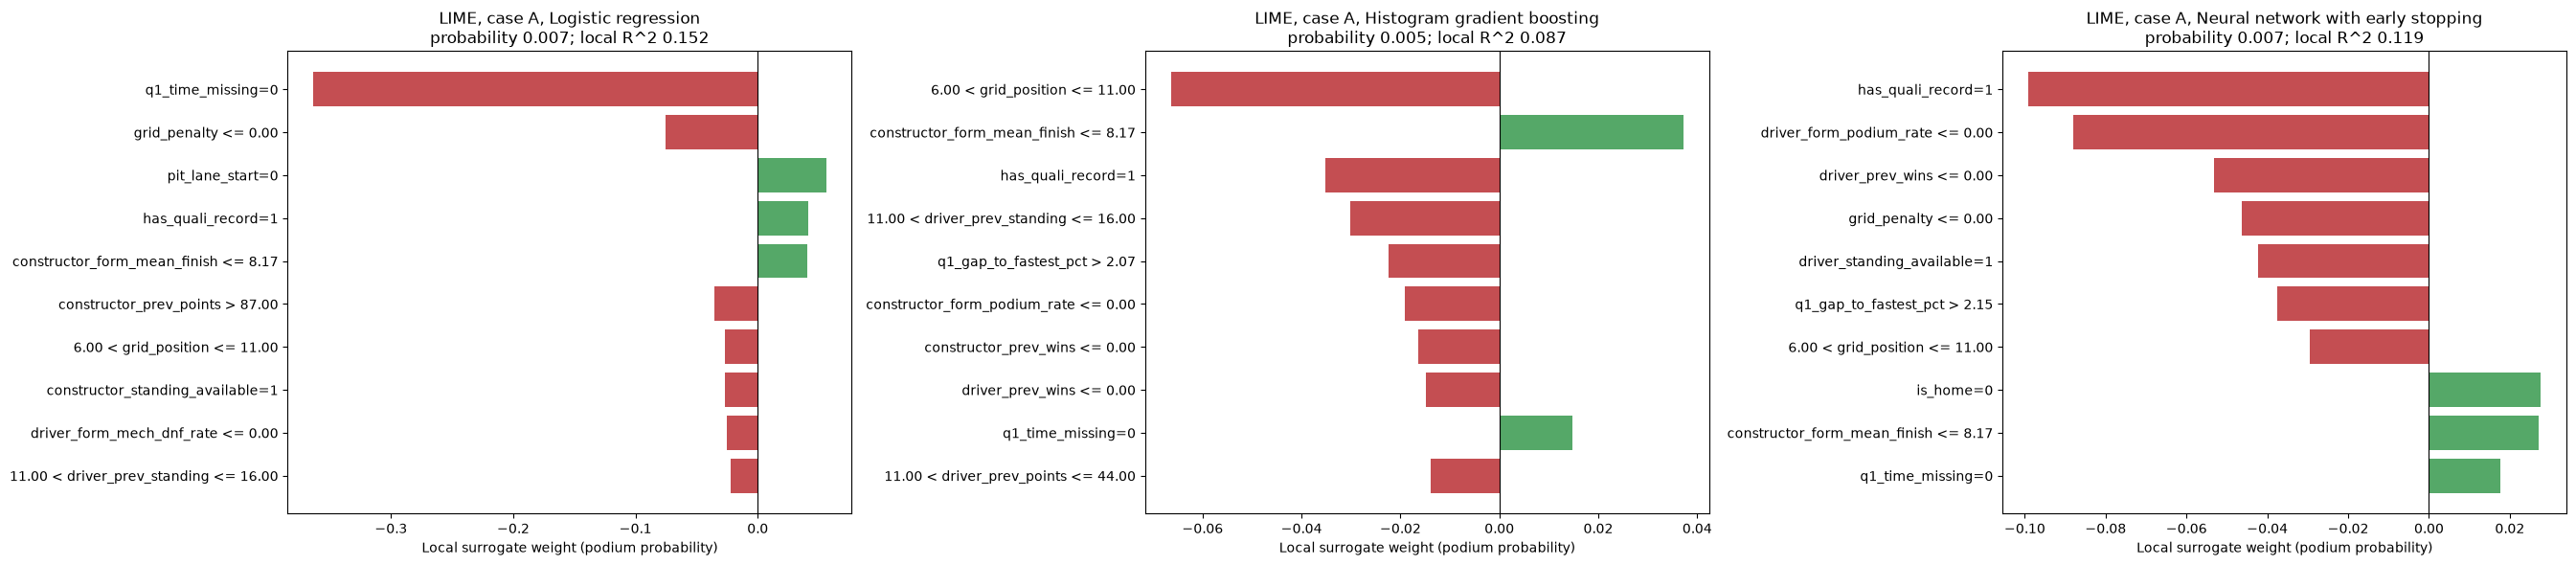

,Check,Passed
0,Explained pipelines reproduce saved validation...,True
1,NN is the separate step-15 best checkpoint,True
2,All three models have SHAP and LIME explanations,True
3,SHAP reconstructs every validation logit withi...,True
4,LIME adapters reproduce original probabilities...,True
5,Explanations use validation rows only; no test...,True
6,Backgrounds use only each model's weight-fitti...,True
7,Local cases are a podium and a non-podium,True


In [203]:
# LIME for case A for all three saved models. Each sampler uses that model's fitting seasons
# and fitted imputer. Reusing logistic medians would change the NN input when values are missing.
def xai_lime_predict(model_name):
    pipeline = xai_bundles[model_name]["pipeline"]
    return lambda z: pipeline.predict_proba(pd.DataFrame(z, columns=XAI_FEATURES))

case_a = XAI_CASE_INDEX["A: most confident miss"]
xai_lime = {}
xai_lime_imputers = {}
for name, bundle in xai_bundles.items():
    numeric = bundle["pipeline"].named_steps["preprocessing"].named_transformers_["numeric"]
    imputer = numeric.named_steps["imputer"] if hasattr(numeric, "named_steps") else numeric
    medians = pd.Series(imputer.statistics_, index=bundle["numeric_features"])
    xai_lime_imputers[name] = medians
    lime_train = xai_reference_X[name].fillna(medians)[XAI_FEATURES]
    lime_validation = xai_X_validation.fillna(medians)[XAI_FEATURES]
    assert np.isfinite(lime_train.to_numpy()).all()
    assert np.isfinite(lime_validation.to_numpy()).all()
    predict = xai_lime_predict(name)
    # Verify the LIME adapter on ALL validation rows, not only the chosen complete row.
    np.testing.assert_allclose(predict(lime_validation.to_numpy())[:, 1],
                               xai_validation_probability[name], rtol=1e-12, atol=1e-12)
    explainer = lime.lime_tabular.LimeTabularExplainer(
        training_data=lime_train.to_numpy(), feature_names=XAI_FEATURES,
        class_names=["No podium", "Podium"], mode="classification",
        categorical_features=[XAI_FEATURES.index(c) for c in XAI_BINARY_FEATURES],
        discretize_continuous=True, random_state=XAI_RANDOM_STATE
    )
    explanation = explainer.explain_instance(
        lime_validation.loc[case_a].to_numpy(), predict,
        num_features=10, num_samples=5000, labels=(1,)
    )
    np.testing.assert_allclose(explanation.predict_proba[1],
                               xai_validation_probability[name][case_a], rtol=1e-12, atol=1e-12)
    xai_lime[name] = explanation
xai_lime_table = pd.concat([
    pd.DataFrame(e.as_list(label=1), columns=["Condition", "Weight toward podium"]).assign(Model=name)
    for name, e in xai_lime.items()
], ignore_index=True)
xai_lime_fidelity = pd.DataFrame([
    {"Model": name, "Model probability": float(xai_validation_probability[name][case_a]),
     "LIME input probability": float(e.predict_proba[1]),
     "Surrogate prediction": float(np.ravel(e.local_pred)[0]),
     "Absolute probability gap": abs(float(np.ravel(e.local_pred)[0]) - float(e.predict_proba[1])),
     "Surrogate R^2 (local fit)": float(e.score)}
    for name, e in xai_lime.items()
])
with pd.option_context("display.precision", 4, "display.width", 240, "display.max_columns", None):
    print(f"LIME, case A: {xai_cases.loc[case_a, 'Driver']}, {xai_cases.loc[case_a, 'year']} {xai_cases.loc[case_a, 'Race']}")
    display(xai_lime_table)
    display(xai_lime_fidelity)
print("LIME fidelity is a diagnostic, not a correctness pass: low R^2 or a large probability gap "
      "means the surrogate poorly represents the model. Perturbations can break feature correlations.")

fig, axes = plt.subplots(1, len(xai_lime), figsize=(27, 6))
for ax, (name, explanation) in zip(axes, xai_lime.items()):
    conditions = explanation.as_list(label=1)[::-1]
    ax.barh([c for c, _ in conditions], [w for _, w in conditions],
            color=["#55a868" if w > 0 else "#c44e52" for _, w in conditions])
    ax.axvline(0, color="black", linewidth=0.8)
    ax.set_title(f"LIME, case A, {name}\nprobability {explanation.predict_proba[1]:.3f}; local R^2 {explanation.score:.3f}")
    ax.set_xlabel("Local surrogate weight (podium probability)")
plt.tight_layout()
plt.show()

step17_checks = pd.DataFrame([
    {"Check": "Explained pipelines reproduce saved validation PR-AUC", "Passed": True},
    {"Check": "NN is the separate step-15 best checkpoint", "Passed":
     XAI_MODEL_PATHS["Neural network with early stopping"] == (MODEL_DIR / "shallow_neural_network_early_stopping.joblib")},
    {"Check": "All three models have SHAP and LIME explanations", "Passed":
     set(xai_bundles) == set(xai_shap) == set(xai_lime)},
    {"Check": "SHAP reconstructs every validation logit within 1e-4", "Passed":
     bool(xai_shap_checks["Maximum additivity error"].le(1e-4).all())},
    {"Check": "LIME adapters reproduce original probabilities, including missing rows (asserted)", "Passed": True},
    {"Check": "Explanations use validation rows only; no test season", "Passed":
     bool(xai_validation_rows["year"].between(2020, 2021).all())},
    {"Check": "Backgrounds use only each model's weight-fitting seasons", "Passed":
     all(xai_train_rows.loc[frame.index, "year"].between(*xai_bundles[name]["train_seasons"]).all()
         for name, frame in xai_reference_X.items())},
    {"Check": "Local cases are a podium and a non-podium", "Passed":
     int(xai_cases.loc[XAI_CASE_INDEX["A: most confident miss"], MODEL_TARGET]) == 1
     and int(xai_cases.loc[XAI_CASE_INDEX["B: most confident false alarm"], MODEL_TARGET]) == 0},
])
display(step17_checks)
step17_validation_passed = bool(step17_checks["Passed"].all())
assert step17_validation_passed, "Step 17 checks failed."


### LIME: the local surrogate is too weak for a strong explanation

LIME explains **case A (Vettel, Turkey 2020)** by fitting a weighted local surrogate to perturbed inputs. The following values are measured against the saved models; a close prediction at the original entry and a good fit throughout the sampled neighborhood are different requirements.

| Model | Model probability | LIME surrogate prediction | Absolute gap (percentage points) | Local R² |
| --- | --- | --- | --- | --- |
| LR | 0.75% | 3.33% | 2.58 | 0.152 |
| HGB | 0.53% | 0.69% | 0.16 | 0.087 |
| NN | 0.72% | 3.34% | 2.62 | 0.119 |

All three local R² values are low (**0.152, 0.087, and 0.119**). HGB's surrogate is close at this one entry, but its **0.087 R²** still indicates a poor neighborhood fit. LR/NN additionally have probability gaps of roughly **2.6 percentage points**, compared with original model probabilities below 1%. The displayed LIME bars must therefore be treated as tentative descriptions of the surrogate, not reliable decompositions of the original predictions. These are explanation-fidelity scores, not model predictive-accuracy scores. [LIME score and local prediction definitions](https://lime-ml.readthedocs.io/en/latest/lime.html).

The most negative displayed conditions are `q1_time_missing=0` for LR (**−0.364**), the grid interval **6 < grid_position ≤ 11** for HGB (**−0.066**), and `has_quali_record=1` for the NN (**−0.099**). Given the low fidelity, these weights should not be promoted into substantive claims about qualifying or used to override the SHAP explanations. LIME uses discretized conditions and models probabilities; LR is linear in log-odds, so even LR need not be well approximated by this particular probability-scale surrogate. Perturbations can also break the observed relationships among racing features. The current outputs do not isolate which factor caused the poor fit.

**Overall explanation finding:** grid is consistently important across global permutation, global SHAP and retraining ablation. Secondary groups differ by model and period. Local SHAP reconstructs the two selected predictions and makes their errors understandable in terms of recorded inputs, while LIME provides a clear fidelity limitation. All eight step-17 checks pass, including prediction-wrapper agreement and SHAP reconstruction, but those checks establish implementation consistency rather than causal validity or dependable LIME fidelity.


## Final model comparison, data-selected thresholds, and test evaluation (step 18)

The LR/HGB hyperparameters are fixed by step 12c's training-only expanding CV; the NN epoch was selected by patience-based stopping within its training partition. Now select a separate **F1-maximizing probability threshold for each saved model using only validation probabilities from 2020-2021**. Search thresholds from 0.000 to 1.000 in increments of 0.005. If F1 ties, choose the threshold closest to 0.5; if still tied, choose the higher threshold. This rule is fixed before scoring test data.

Then apply those frozen thresholds to training/fit, validation, and 2022-2024 test probabilities. ROC-AUC and average precision do not depend on thresholds; F1, precision, and recall do. The validation F1 used for selection is optimistic by construction, so interpret test as the generalization estimate. Keep all models in the comparison, including the early-stopping NN, regardless of their test ranking.

**Transparency:** the earlier 0.5-threshold test results were already inspected in a prior notebook run. This is therefore not a never-before-viewed blind test. The new settings and thresholds are selected without test information, and the test is not used to revise them; report this history honestly.

Training/fit metrics reflect each model's actual weight-fitting rows. For the NN, weight-fitting (2006-2017) and stopping/selection (2018-2019) results are separate. Validation model probabilities are checked against saved validation metadata before thresholds are selected. Test predictions are saved in `models/final_test_predictions.csv`; deployable pipelines and their selected thresholds are saved together in `models/final_inference_models.joblib`.

**Comparability:** LR/HGB fit on 5,760 entries; the NN fits weights on 4,921 and uses another 839 for stopping. Every model is evaluated on the same 779 validation entries and 1,354 test entries. This supports a comparison of the implemented training procedures, but it does not isolate architecture from fitting-period or tuning-budget effects. AP remains the primary ranking criterion, ROC-AUC is secondary, and F1/precision/recall describe each frozen operating threshold.


In [204]:
assert step12_validation_passed, "Run steps 1-12 successfully first."
assert len(TIME_SERIES_CV_FOLDS) == 6

from pathlib import Path
import joblib
from sklearn.metrics import (
    average_precision_score, f1_score, precision_score, recall_score, roc_auc_score
)

FINAL_MODEL_PATHS = {
    "Logistic regression": (MODEL_DIR / "logistic_regression_baseline.joblib"),
    "Histogram gradient boosting": (MODEL_DIR / "hist_gradient_boosting_baseline.joblib"),
    "Shallow neural network (early stopping)": (MODEL_DIR / "shallow_neural_network_early_stopping.joblib"),
}
final_bundles = {}
for model_name, model_path in FINAL_MODEL_PATHS.items():
    if not model_path.is_file():
        raise FileNotFoundError(f"Missing final model artifact: {model_path}")
    final_bundles[model_name] = joblib.load(model_path)

final_test_rows = modeling_table_fe.loc[modeling_table_fe["partition"].eq("test")].copy().reset_index(drop=True)
final_validation_rows = modeling_table_fe.loc[modeling_table_fe["partition"].eq("validation")].copy().reset_index(drop=True)
final_train_rows = modeling_table_fe.loc[modeling_table_fe["partition"].eq("train")].copy().reset_index(drop=True)
assert len(final_train_rows) == 5760 and len(final_validation_rows) == 779 and len(final_test_rows) == 1354
assert final_train_rows["year"].between(2006, 2019).all()
assert final_validation_rows["year"].between(2020, 2021).all()
assert final_test_rows["year"].between(2022, 2024).all()
assert set(final_train_rows["raceId"]).isdisjoint(final_validation_rows["raceId"])
assert set(final_train_rows["raceId"]).isdisjoint(final_test_rows["raceId"])
assert set(final_validation_rows["raceId"]).isdisjoint(final_test_rows["raceId"])
assert not final_test_rows.duplicated(["raceId", "driverId"]).any()


def choose_validation_threshold(y_true, probabilities):
    """Maximize validation F1; ties choose nearest 0.5, then the higher threshold."""
    candidates = np.round(np.arange(0.0, 1.0001, 0.005), 3)
    scores = np.asarray([
        f1_score(y_true, probabilities >= threshold, zero_division=0)
        for threshold in candidates
    ])
    best = scores.max()
    tied = candidates[np.isclose(scores, best, rtol=0.0, atol=1e-12)]
    threshold = max(tied, key=lambda value: (-abs(value - 0.5), value))
    return float(threshold), float(best), pd.DataFrame({"Threshold": candidates, "Validation F1": scores})


def final_metric_record(model_name, partition_name, rows, probabilities, threshold):
    probabilities = np.asarray(probabilities, dtype=float)
    assert probabilities.shape == (len(rows),)
    assert np.isfinite(probabilities).all()
    assert ((probabilities >= 0) & (probabilities <= 1)).all()
    truth = rows[MODEL_TARGET].astype(int).to_numpy()
    predicted = (probabilities >= threshold).astype(int)
    return {
        "Model": model_name, "Partition": partition_name, "Rows": len(rows),
        "Threshold": threshold, "ROC-AUC": roc_auc_score(truth, probabilities),
        "PR-AUC (average precision)": average_precision_score(truth, probabilities),
        "F1": f1_score(truth, predicted, zero_division=0),
        "Precision": precision_score(truth, predicted, zero_division=0),
        "Recall": recall_score(truth, predicted, zero_division=0),
        "Podium rows": int(truth.sum()), "Podium rate": float(truth.mean()),
    }


final_validation_probabilities = {}
selected_thresholds = {}
threshold_search_curves = {}
for model_name, bundle in final_bundles.items():
    assert bundle["feature_columns"] == list(FE_FEATURE_COLUMNS)
    assert bundle["target"] == MODEL_TARGET and bundle["positive_class"] == 1
    assert bundle["validation_seasons"] == [2020, 2021]
    np.testing.assert_array_equal(bundle["pipeline"].classes_, [0, 1])
    if model_name == "Logistic regression":
        assert bundle["selected_cv_parameters"]["C"] == LR_SELECTED_C
    elif model_name == "Histogram gradient boosting":
        assert all(bundle["selected_cv_parameters"][key] == value
                   for key, value in HGB_SELECTED_PARAMS.items())
    else:
        assert bundle["train_seasons"] == [2006, 2017]
        assert bundle["stopping_seasons"] == [2018, 2019]
        assert bundle["early_stopping"]["restore_best_weights"] is True

    X_validation = final_validation_rows[FE_FEATURE_COLUMNS].astype("Float64").astype("float64")
    validation_probability = bundle["pipeline"].predict_proba(X_validation)[:, 1]
    saved_validation = bundle["validation_metrics"]
    assert np.isclose(average_precision_score(final_validation_rows[MODEL_TARGET], validation_probability),
                      saved_validation["PR-AUC (average precision)"], atol=1e-9)
    final_validation_probabilities[model_name] = validation_probability
    threshold, validation_f1, curve = choose_validation_threshold(
        final_validation_rows[MODEL_TARGET].astype(int).to_numpy(), validation_probability
    )
    selected_thresholds[model_name] = threshold
    threshold_search_curves[model_name] = curve

threshold_selection_results = pd.DataFrame([
    {"Model": name, "Threshold selected on validation": selected_thresholds[name],
     "Validation F1 at selected threshold": float(threshold_search_curves[name]["Validation F1"].max()),
     "Validation F1 at 0.5": float(threshold_search_curves[name].loc[
         threshold_search_curves[name]["Threshold"].eq(0.5), "Validation F1"].iloc[0])}
    for name in FINAL_MODEL_PATHS
])
with pd.option_context("display.max_columns", None, "display.precision", 4):
    print("Per-model thresholds selected from validation F1 (0.005 grid; prespecified tie rule)")
    display(threshold_selection_results)

final_metric_rows = []
final_test_prediction_rows = []
final_inference_models = {}
for model_name, bundle in final_bundles.items():
    pipeline = bundle["pipeline"]
    threshold = selected_thresholds[model_name]
    if model_name == "Shallow neural network (early stopping)":
        fit_rows = final_train_rows.loc[final_train_rows["year"].between(2006, 2017)]
        stopping_rows = final_train_rows.loc[final_train_rows["year"].between(2018, 2019)]
        score_partitions = [
            ("Weight fitting (2006-2017)", fit_rows),
            ("Stopping / selection (2018-2019)", stopping_rows),
            ("Validation (2020-2021)", final_validation_rows),
            ("Test (2022-2024)", final_test_rows),
        ]
    else:
        score_partitions = [
            ("Training (2006-2019)", final_train_rows),
            ("Validation (2020-2021)", final_validation_rows),
            ("Test (2022-2024)", final_test_rows),
        ]
    for partition_name, rows in score_partitions:
        X = rows[FE_FEATURE_COLUMNS].astype("Float64").astype("float64")
        probabilities = pipeline.predict_proba(X)[:, 1]
        final_metric_rows.append(final_metric_record(
            model_name, partition_name, rows, probabilities, threshold
        ))
        if partition_name == "Test (2022-2024)":
            predictions = rows[["raceId", "driverId", "year", MODEL_TARGET]].copy()
            predictions.insert(0, "Model", model_name)
            predictions["podium_probability"] = probabilities
            predictions["selected_threshold"] = threshold
            predictions["predicted_podium"] = (probabilities >= threshold).astype(int)
            final_test_prediction_rows.append(predictions)
    final_inference_models[model_name] = {
        "pipeline": pipeline, "feature_columns": list(bundle["feature_columns"]),
        "numeric_features": list(bundle["numeric_features"]),
        "binary_features": list(bundle["binary_features"]),
        "target": MODEL_TARGET, "positive_class": 1, "threshold": threshold,
        "selected_cv_parameters": bundle.get("selected_cv_parameters", {}),
        "threshold_selection": "validation F1; grid 0.005; ties nearest 0.5 then higher",
        "form_window": FORM_WINDOW,
    }

final_model_metrics = pd.DataFrame(final_metric_rows)
final_test_predictions = pd.concat(final_test_prediction_rows, ignore_index=True)
assert len(final_test_predictions) == len(FINAL_MODEL_PATHS) * len(final_test_rows)
assert final_test_predictions.groupby("Model").size().eq(len(final_test_rows)).all()

with pd.option_context("display.max_columns", None, "display.precision", 4):
    print("Final metrics; threshold-dependent metrics use the validation-selected cutoff")
    display(final_model_metrics)

FINAL_TEST_PREDICTIONS_PATH = MODEL_DIR / "final_test_predictions.csv"
final_test_predictions.to_csv(FINAL_TEST_PREDICTIONS_PATH, index=False)
assert len(pd.read_csv(FINAL_TEST_PREDICTIONS_PATH)) == len(final_test_predictions)
FINAL_INFERENCE_BUNDLE_PATH = MODEL_DIR / "final_inference_models.joblib"
joblib.dump(final_inference_models, FINAL_INFERENCE_BUNDLE_PATH, compress=3)
reloaded_inference_models = joblib.load(FINAL_INFERENCE_BUNDLE_PATH)
assert set(reloaded_inference_models) == set(FINAL_MODEL_PATHS)
print(f"Saved {len(final_test_predictions):,} test predictions to {FINAL_TEST_PREDICTIONS_PATH}.")
print(f"Saved selected pipelines and validation thresholds to {FINAL_INFERENCE_BUNDLE_PATH}.")
print("The 2022-2024 test partition did not participate in hyperparameter or threshold selection.")

Per-model thresholds selected from validation F1 (0.005 grid; prespecified tie rule)


,Model,Threshold selected on validation,Validation F1 at selected threshold,Validation F1 at 0.5
0,Logistic regression,0.235,0.7063,0.6636
1,Histogram gradient boosting,0.410,0.7069,0.6878
2,Shallow neural network (early stopping),0.280,0.7087,0.6606


Final metrics; threshold-dependent metrics use the validation-selected cutoff


,Model,Partition,Rows,Threshold,ROC-AUC,PR-AUC (average precision),F1,Precision,Recall,Podium rows,Podium rate
0,Logistic regression,Training (2006-2019),5760,0.235,0.9344,0.6977,0.6745,0.5566,0.8557,804,0.1396
1,Logistic regression,Validation (2020-2021),779,0.235,0.9298,0.7259,0.7063,0.6250,0.8120,117,0.1502
2,Logistic regression,Test (2022-2024),1354,0.235,0.9367,0.7219,0.6783,0.5609,0.8578,204,0.1507
3,Histogram gradient boosting,Training (2006-2019),5760,0.410,0.9509,0.7610,0.7018,0.6844,0.7201,804,0.1396
4,Histogram gradient boosting,Validation (2020-2021),779,0.410,0.9259,0.7115,0.7069,0.7130,0.7009,117,0.1502
5,Histogram gradient boosting,Test (2022-2024),1354,0.410,0.9426,0.7215,0.6824,0.6561,0.7108,204,0.1507
6,Shallow neural network (early stopping),Weight fitting (2006-2017),4921,0.280,0.9435,0.7376,0.6906,0.5949,0.8230,678,0.1378
7,Shallow neural network (early stopping),Stopping / selection (2018-2019),839,0.280,0.9342,0.6878,0.7093,0.5936,0.8810,126,0.1502
8,Shallow neural network (early stopping),Validation (2020-2021),779,0.280,0.9293,0.7379,0.7087,0.6569,0.7692,117,0.1502
9,Shallow neural network (early stopping),Test (2022-2024),1354,0.280,0.9336,0.6809,0.6775,0.5779,0.8186,204,0.1507


Saved 4,062 test predictions to /kaggle/working/models/final_test_predictions.csv.
Saved selected pipelines and validation thresholds to /kaggle/working/models/final_inference_models.joblib.
The 2022-2024 test partition did not participate in hyperparameter or threshold selection.


### Final test-performance plots

These plots use the existing `final_test_predictions` from step 18. PR and ROC curves compare ranking performance on the same 2022–2024 entries; AP is average precision, as defined above. Confusion matrices use each model's already frozen validation-selected threshold. No model is fitted or threshold selected here. The prior test inspection disclosed in the final results still applies.


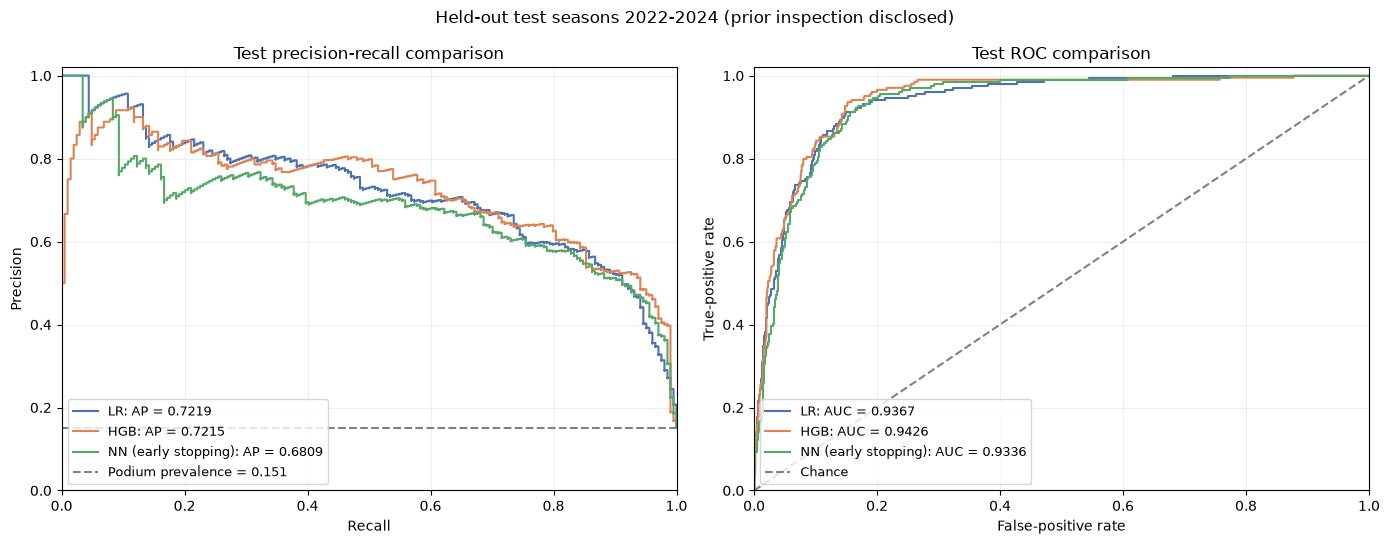

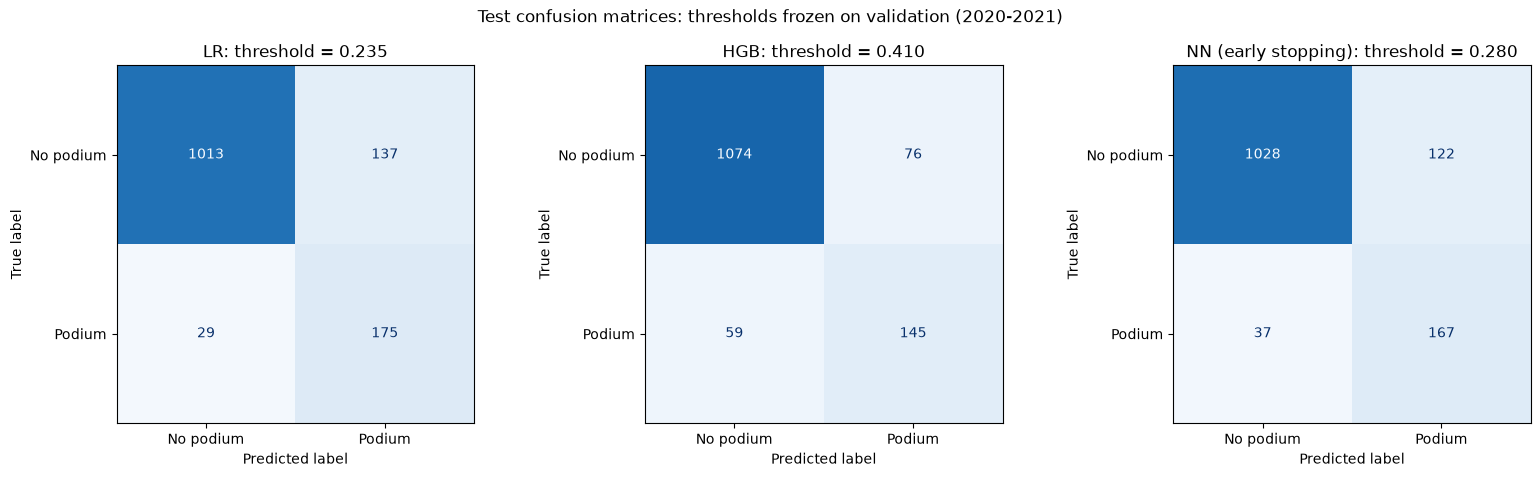

In [205]:
# Visualize existing test predictions; no fitting or threshold selection occurs here.
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import (
    average_precision_score, roc_auc_score, precision_recall_curve, roc_curve,
    confusion_matrix, ConfusionMatrixDisplay,
)

test_plot_predictions = final_test_predictions.copy()
test_plot_labels = {
    "Logistic regression": "LR",
    "Histogram gradient boosting": "HGB",
    "Shallow neural network (early stopping)": "NN (early stopping)",
}
assert set(test_plot_predictions["Model"]) == set(test_plot_labels)
assert test_plot_predictions["year"].between(2022, 2024).all()
assert not test_plot_predictions.duplicated(["Model", "raceId", "driverId"]).any()
test_plot_groups = {
    name: test_plot_predictions.loc[test_plot_predictions["Model"].eq(name)]
        .sort_values(["raceId", "driverId"]).reset_index(drop=True)
    for name in test_plot_labels
}
test_plot_reference = next(iter(test_plot_groups.values()))
for name, rows in test_plot_groups.items():
    assert rows[["raceId", "driverId", "podium"]].equals(
        test_plot_reference[["raceId", "driverId", "podium"]]
    ), "All models must be plotted on identical test entries and targets."
    assert rows["selected_threshold"].nunique() == 1
    assert np.isfinite(rows["podium_probability"]).all()
    assert rows["podium_probability"].between(0, 1).all()
    np.testing.assert_array_equal(
        rows["predicted_podium"],
        (rows["podium_probability"] >= rows["selected_threshold"]).astype(int),
    )

test_plot_prevalence = test_plot_reference["podium"].mean()
test_plot_colours = ["#4c72b0", "#dd8452", "#55a868"]
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
for (name, rows), colour in zip(test_plot_groups.items(), test_plot_colours):
    truth = rows["podium"].to_numpy()
    probability = rows["podium_probability"].to_numpy()
    precision, recall, _ = precision_recall_curve(truth, probability)
    fpr, tpr, _ = roc_curve(truth, probability)
    label = test_plot_labels[name]
    axes[0].step(recall, precision, where="post", color=colour,
                 label=f"{label}: AP = {average_precision_score(truth, probability):.4f}")
    axes[1].plot(fpr, tpr, color=colour,
                 label=f"{label}: AUC = {roc_auc_score(truth, probability):.4f}")
axes[0].axhline(test_plot_prevalence, color="grey", linestyle="--",
               label=f"Podium prevalence = {test_plot_prevalence:.3f}")
axes[1].plot([0, 1], [0, 1], color="grey", linestyle="--", label="Chance")
axes[0].set(title="Test precision-recall comparison", xlabel="Recall", ylabel="Precision")
axes[1].set(title="Test ROC comparison", xlabel="False-positive rate", ylabel="True-positive rate")
for ax in axes:
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1.02)
    ax.grid(alpha=0.2)
    ax.legend(loc="lower left", fontsize=9)
fig.suptitle("Held-out test seasons 2022-2024 (prior inspection disclosed)")
fig.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
for ax, (name, rows) in zip(axes, test_plot_groups.items()):
    matrix = confusion_matrix(rows["podium"], rows["predicted_podium"], labels=[0, 1])
    assert matrix.sum() == len(rows)
    ConfusionMatrixDisplay(matrix, display_labels=["No podium", "Podium"]).plot(
        ax=ax, cmap="Blues", colorbar=False, values_format="d",
        im_kw={"vmin": 0, "vmax": len(test_plot_reference)},
    )
    threshold = float(rows["selected_threshold"].iloc[0])
    ax.set_title(f"{test_plot_labels[name]}: threshold = {threshold:.3f}")
fig.suptitle("Test confusion matrices: thresholds frozen on validation (2020-2021)")
fig.tight_layout()
plt.show()


**Reading the test plots.** LR and HGB have nearly identical AP (0.7219 and 0.7215), while HGB has the higher ROC-AUC (0.9426 versus 0.9367). The NN's AP is lower at 0.6809. These observed differences do not establish statistical significance.

At the frozen validation-selected thresholds, LR detects **175 of 204 podiums**, misses **29**, and raises **137 false alarms**. HGB detects **145**, misses **59**, and raises **76 false alarms**. The NN detects **167**, misses **37**, and raises **122 false alarms**. HGB therefore produces fewer false alarms but misses more podiums at its selected operating point; LR recovers more podiums. These are descriptions of the fixed evaluation, not grounds to tune against the test set.


## Inference on one complete or partially missing pre-race record

Training/evaluation operates on a table; inference demonstrates applying a saved pipeline to one future driver–race entry. The function below consumes the **engineered 23 pre-race features**, not raw CSV rows. A real prediction still requires constructing those features with the same step-10/12 joins, cutoff rules, and strictly prior race history. The saved inference bundle contains each selected model and its validation-selected threshold.

A record may omit nonbinary numeric features; omitted numeric values are represented as missing and imputed by that model's training-fitted pipeline. Binary flags are required, because guessing whether a missing qualifying/standing/form value occurred would create inconsistent inputs. A caller should provide the appropriate availability/missingness flag (for example, `q1_time_missing=1` when the Q1 gap is unavailable). Extra fields and invalid binary flags are rejected.

**Demonstration selection.** Choose the earliest validation row with all 23 features observed, ordered by date, race ID, then driver ID. Display its driver/race identity and all input values. Copy that same row for the partially missing example, replacing only the Q1 gap with a missing value and changing its missingness flag to 1. Assertions check completeness, the exact two-field change, and agreement with each saved pipeline and threshold.


In [206]:
import joblib
import numpy as np
import pandas as pd

FINAL_INFERENCE_BUNDLE_PATH = MODEL_DIR / "final_inference_models.joblib"
final_inference_models = joblib.load(FINAL_INFERENCE_BUNDLE_PATH)


def predict_podium_record(model_name, record):
    """Predict one driver-race record from engineered pre-race features."""
    if model_name not in final_inference_models:
        raise KeyError(f"Unknown model {model_name!r}; choose from {list(final_inference_models)}")
    if isinstance(record, pd.DataFrame):
        if len(record) != 1:
            raise ValueError("Provide exactly one driver-race row.")
        values = record.iloc[0].to_dict()
    elif isinstance(record, pd.Series):
        values = record.to_dict()
    elif isinstance(record, dict):
        values = dict(record)
    else:
        raise TypeError("record must be a dict, pandas Series, or one-row DataFrame.")

    bundle = final_inference_models[model_name]
    feature_columns = bundle["feature_columns"]
    binary_features = bundle["binary_features"]
    unexpected = sorted(set(values) - set(feature_columns))
    if unexpected:
        raise ValueError(f"Unexpected feature(s): {unexpected}")
    missing_binary = [name for name in binary_features if values.get(name) is None or pd.isna(values.get(name))]
    if missing_binary:
        raise ValueError(f"Binary availability flags are required: {missing_binary}")

    row = pd.DataFrame([values]).reindex(columns=feature_columns)
    for column in bundle["numeric_features"]:
        row[column] = pd.to_numeric(row[column], errors="raise").astype(float)
    for column in binary_features:
        if row[column].iloc[0] not in (0, 1, False, True):
            raise ValueError(f"Binary feature {column!r} must be 0 or 1.")
        row[column] = row[column].astype(int)

    probability = float(bundle["pipeline"].predict_proba(row)[0, 1])
    if not np.isfinite(probability) or not 0.0 <= probability <= 1.0:
        raise RuntimeError("The model returned an invalid podium probability.")
    threshold = float(bundle["threshold"])
    return {
        "model": model_name,
        "podium_probability": probability,
        "threshold": threshold,
        "predicted_podium": int(probability >= threshold),
    }


# Demonstration A: earliest fully observed validation row, with deterministic tie-breaking.
inference_complete_candidates = final_validation_rows.dropna(subset=FE_FEATURE_COLUMNS).sort_values(
    ["date", "raceId", "driverId"]
)
assert not inference_complete_candidates.empty, "No fully observed validation record is available."
inference_example_row = inference_complete_candidates.iloc[0]
assert inference_example_row["partition"] == "validation"
inference_complete_record = inference_example_row[FE_FEATURE_COLUMNS].to_dict()
assert set(inference_complete_record) == set(FE_FEATURE_COLUMNS)
assert not pd.Series(inference_complete_record).isna().any()
assert inference_complete_record["q1_time_missing"] == 0

inference_driver = clean_data["drivers"].set_index("driverId").loc[inference_example_row["driverId"]]
inference_race = clean_data["races"].set_index("raceId").loc[inference_example_row["raceId"]]
inference_example_identity = pd.DataFrame([{
    "Driver": f"{inference_driver['forename']} {inference_driver['surname']}",
    "Race": inference_race["name"], "Date": inference_example_row["date"],
    "raceId": int(inference_example_row["raceId"]), "driverId": int(inference_example_row["driverId"]),
    "Partition": inference_example_row["partition"],
}])
inference_complete_results = pd.DataFrame([
    predict_podium_record(name, inference_complete_record) for name in final_inference_models
])

# Demonstration B: same record, with only the Q1 gap and its missingness flag changed.
inference_partial_record = dict(inference_complete_record)
inference_partial_record["q1_gap_to_fastest_pct"] = np.nan
inference_partial_record["q1_time_missing"] = 1
assert {name for name, value in inference_partial_record.items() if pd.isna(value)} == {"q1_gap_to_fastest_pct"}
assert {name for name in FE_FEATURE_COLUMNS
        if pd.isna(inference_partial_record[name])
        or inference_partial_record[name] != inference_complete_record[name]} == {
    "q1_gap_to_fastest_pct", "q1_time_missing"
}
inference_partial_results = pd.DataFrame([
    predict_podium_record(name, inference_partial_record) for name in final_inference_models
])

# Verify both examples use the original saved model, its feature order, and its frozen threshold.
for record, results in [(inference_complete_record, inference_complete_results),
                        (inference_partial_record, inference_partial_results)]:
    assert len(results) == len(final_inference_models)
    assert np.isfinite(results["podium_probability"]).all()
    assert results["podium_probability"].between(0, 1).all()
    for result in results.to_dict("records"):
        bundle = final_inference_models[result["model"]]
        inputs = pd.DataFrame([record]).reindex(columns=bundle["feature_columns"]).astype(float)
        np.testing.assert_allclose(result["podium_probability"], bundle["pipeline"].predict_proba(inputs)[0, 1],
                                   rtol=1e-12, atol=1e-12)
        assert result["threshold"] == bundle["threshold"]
        assert result["predicted_podium"] == int(result["podium_probability"] >= bundle["threshold"])

print("Selected fully observed validation record (earliest date; ties by raceId, driverId):")
display(inference_example_identity)
inference_example_features = pd.DataFrame({
    "Complete record": pd.Series(inference_complete_record),
    "Partially missing record": pd.Series(inference_partial_record),
}).reindex(FE_FEATURE_COLUMNS)
with pd.option_context("display.max_rows", None, "display.max_columns", None):
    display(inference_example_features)
    print("Complete engineered record: predictions")
    display(inference_complete_results)
    print("Partially missing engineered record: predictions (Q1 gap unavailable; flag set)")
    display(inference_partial_results)
print("Both examples use each saved model's validation-selected threshold; neither is a new performance evaluation.")


Selected fully observed validation record (earliest date; ties by raceId, driverId):


,Driver,Race,Date,raceId,driverId,Partition
0,Lewis Hamilton,Styrian Grand Prix,2020-07-12,1032,1,validation


,Complete record,Partially missing record
grid_position,1.000000,1.000000
pit_lane_start,0.000000,0.000000
has_quali_record,1.000000,1.000000
grid_penalty,0.000000,0.000000
q1_gap_to_fastest_pct,0.000000,NaN
q1_time_missing,0.000000,1.000000
driver_prev_points,12.000000,12.000000
driver_prev_standing,4.000000,4.000000
driver_prev_wins,0.000000,0.000000
driver_standing_available,1.000000,1.000000


Complete engineered record: predictions


,model,podium_probability,threshold,predicted_podium
0,Logistic regression,0.645566,0.235,1
1,Histogram gradient boosting,0.763666,0.410,1
2,Shallow neural network (early stopping),0.648976,0.280,1


Partially missing engineered record: predictions (Q1 gap unavailable; flag set)


,model,podium_probability,threshold,predicted_podium
0,Logistic regression,0.990624,0.235,1
1,Histogram gradient boosting,0.721914,0.410,1
2,Shallow neural network (early stopping),0.627721,0.280,1


Both examples use each saved model's validation-selected threshold; neither is a new performance evaluation.


### Step 18 results

The table above reports metrics at the F1-maximizing validation threshold selected independently for each model. The displayed validation F1 is the selection score and may be optimistic; the 2022-2024 test metrics are the generalization check. The test period was previously scored and viewed at threshold 0.5, so this updated thresholded evaluation is transparent, post hoc reporting rather than a previously unseen blind test. Hyperparameters and thresholds in this notebook were chosen without test data.
### What the final results support

| Model | Threshold | Test AP (primary) | Test ROC-AUC | Test F1 | Precision | Recall |
| --- | --- | --- | --- | --- | --- | --- |
| LR | 0.235 | 0.7219 | 0.9367 | 0.6783 | 0.5609 | 0.8578 |
| HGB | 0.410 | 0.7215 | 0.9426 | 0.6824 | 0.6561 | 0.7108 |
| NN | 0.280 | 0.6809 | 0.9336 | 0.6775 | 0.5779 | 0.8186 |

**AP does not show a meaningful separation between LR and HGB in this test period:** LR scores **0.7219** and HGB **0.7215**, a difference of only **0.0003**. HGB has the higher ROC-AUC and slightly higher thresholded F1. Those complementary advantages should be reported, but no confidence interval or paired uncertainty analysis establishes a reliable overall winner. The simpler LR remains competitive with the nonlinear tree ensemble on the primary metric.

**The NN's validation lead does not persist on test.** Validation AP is **0.7379**, compared with **0.7259 (LR)** and **0.7115 (HGB)**, but NN test AP is **0.6809**, below both. Its test F1 remains close to theirs because F1 evaluates the selected operating point rather than the entire ranking. The outcome does not support claiming that additional nonlinear model complexity improves future podium ranking here. It also does not isolate the cause: fitting seasons, tuning choices and season-to-season changes differ or remain uncontrolled.

**The thresholds express different precision–recall tradeoffs.** LR at **0.235** recovers **85.78%** of actual podiums with **56.09%** precision. HGB at **0.410** has **65.61%** precision and **71.08%** recall. The NN at **0.280** sits between them on these two measures, with **57.79%** precision and **81.86%** recall. Thus similar F1 values conceal materially different patterns of false alarms and missed podiums. No deployment preference is inferred without a stated cost or usage requirement.

These conclusions apply to the recorded splits, saved models and fixed thresholds. The notebook supplies reproducible comparative evidence and interpretable examples, while acknowledging the prior test inspection, selection effects, lack of calibration assessment and limited uncertainty analysis. No model or threshold is changed in response to these test rankings.


In [207]:
# Export the live results from this execution, not the reference markdown numbers.
export_tables = {
    "final_metrics": final_model_metrics,
    "selected_thresholds": threshold_selection_results,
    "tuning_cv_results": tuning_fold_results,
    "feature_selection": feature_selection_log,
    "ablation_results": ablation_results,
    "permutation_importance": xai_permutation_importance,
    "grouped_permutation_importance": xai_group_permutation_importance,
    "shap_checks": xai_shap_checks,
    "shap_importance": xai_shap_importance.rename_axis("Feature").reset_index(),
    "source_manifest": source_manifest,
}
for name, table in export_tables.items():
    table.to_csv(REPRO_DIR / f"{name}.csv", index=False)
run_configuration = {
    "dataset_source": "https://www.kaggle.com/datasets/rohanrao/formula-1-world-championship-1950-2020",
    "dataset_version": "unknown; identified by source_manifest.csv hashes",
    "dataset_path": str(dataset_path), "strict_snapshot": STRICT_DATA_SNAPSHOT,
    "snapshot_matches": bool(source_manifest["Matches reference"].all()),
    "workers": N_JOBS, "numerical_threads": 1, "features": list(FE_FEATURE_COLUMNS),
    "runtime": runtime_versions,
}
(REPRO_DIR / "run_configuration.json").write_text(json.dumps(run_configuration, indent=2), encoding="utf-8")
print("Run complete. Models:", MODEL_DIR)
print("Live metrics, checks and provenance:", REPRO_DIR)
display(final_model_metrics)


Run complete. Models: /kaggle/working/models
Live metrics, checks and provenance: /kaggle/working/reproducibility


,Model,Partition,Rows,Threshold,ROC-AUC,PR-AUC (average precision),F1,Precision,Recall,Podium rows,Podium rate
0,Logistic regression,Training (2006-2019),5760,0.235,0.934429,0.697729,0.674510,0.556634,0.855721,804,0.139583
1,Logistic regression,Validation (2020-2021),779,0.235,0.929803,0.725944,0.706320,0.625000,0.811966,117,0.150193
2,Logistic regression,Test (2022-2024),1354,0.235,0.936743,0.721882,0.678295,0.560897,0.857843,204,0.150665
3,Histogram gradient boosting,Training (2006-2019),5760,0.410,0.950859,0.761020,0.701818,0.684397,0.720149,804,0.139583
4,Histogram gradient boosting,Validation (2020-2021),779,0.410,0.925911,0.711464,0.706897,0.713043,0.700855,117,0.150193
5,Histogram gradient boosting,Test (2022-2024),1354,0.410,0.942551,0.721550,0.682353,0.656109,0.710784,204,0.150665
6,Shallow neural network (early stopping),Weight fitting (2006-2017),4921,0.280,0.943547,0.737579,0.690594,0.594883,0.823009,678,0.137777
7,Shallow neural network (early stopping),Stopping / selection (2018-2019),839,0.280,0.934226,0.687825,0.709265,0.593583,0.880952,126,0.150179
8,Shallow neural network (early stopping),Validation (2020-2021),779,0.280,0.929326,0.737901,0.708661,0.656934,0.769231,117,0.150193
9,Shallow neural network (early stopping),Test (2022-2024),1354,0.280,0.933585,0.680914,0.677485,0.577855,0.818627,204,0.150665
